# Question-Adaptive Visual Token Selection for Vision-Language Models

**Experimental notebook**: CLIP ViT-B/16 (frozen) + question encoder (frozen) + question-conditioned *selector* + projector + Qwen2.5-0.5B-Instruct (frozen + LoRA), evaluated on VQAv2.

| Part | Sections | Content |
|---|---|---|
| I. Framing | 1 – 3 | Motivation, theoretical background, environment |
| II. Data | 4 – 5 | VQAv2, official metric, image preprocessing |
| III. Encoders | 6 – 8 | CLIP vision, question encoder, token analysis |
| IV. Selection | 9 – 13 | Scorers, cross-attention, fixed Top-K, conditioned Top-K, dynamic budget |
| V. VLM | 14 – 16 | Projector, integration into Qwen, full forward pass |
| VI. Training | 17 – 18 | LoRA, phases A → D |
| VII. Experiments | 19 – 21 | Baselines, benchmark, visualizations and ablations |
| VIII. Conclusion | 22 – 23 | Results, limitations, future work |

**Notebook rules**

1. Always run **section 3** first: it defines `cfg`, `DEVICE`, `DTYPE` and the utilities.
2. `DEBUG = True` (section 3.6) runs the whole pipeline on ~200 examples in a few minutes. Validate each section in DEBUG before switching to full mode.
3. Each section writes files to persistent storage; after a disconnection, we **reload** instead of recomputing (`load_or_compute`, section 3.7).
4. No number is written by hand in this notebook: all results are measured.

---
# Part I: framing

## Section 1. Introduction and motivation

### 1.1 The problem

A LLaVA-style VLM turns the image into a sequence of visual tokens, then feeds it to the LLM together with the question. With CLIP ViT-B/16 at 224×224, that is **196 visual tokens for every image**, whether the question is about the whole scene ("How many people are there?") or about a single object ("What color is the car?").

Yet the cost of the LLM grows with the sequence length $T$: linearly for the projections and the MLP, quadratically for attention. In our setup, visual tokens make up about **three quarters** of the sequence. Most of them are useless for answering a localized question.

### 1.2 The hypothesis

> A **question-conditioned** selection of visual tokens can sharply reduce the number of tokens sent to the LLM without degrading accuracy much. It does better than a selection that ignores the question, for the same number of tokens.

### 1.3 Research questions

| | Question | How we answer it |
|---|---|---|
| **RQ1** | At equal K, does a question-conditioned selection beat one that ignores the question? | Compare Question-Conditioned Top-K and Fixed Top-K (4 variants) for each K (sections 19 and 20) |
| **RQ2** | How low can K go before a significant degradation? | Accuracy = f(K) curve, gap to Full Tokens with confidence intervals |
| **RQ3** | Does the dynamic budget dominate the fixed budget on the accuracy / tokens curve? | Position of the "dynamic budget" point relative to the Pareto front of fixed Top-K |
| **RQ4** | Do FLOP savings translate into real latency savings? | Benchmark measured from pixels: ViT + selector + prefill + decoding |

### 1.4 Architecture

🔒 = frozen, 🔥 = trained

```
                     ┌──────────────────────────┐
  Image 3×224×224 ──►│ 🔒 CLIP ViT-B/16          │── V : 196×768 (penultimate layer, without CLS) ───┐
                     └──────────────────────────┘                                                   │
                                                                                                     ▼
                     ┌──────────────────────────┐                                  ┌──────────────────────────┐
  Question ─────────►│ 🔒 Question encoder       │── Q : M×512,  q̄ : 512 ─────────►│ 🔥 Selector               │── s : 196
                     │   (CLIP text)             │                                  │   (cross-attention, MLP…) │     │
                     └──────────────────────────┘                                  └──────────────────────────┘     │
                                                                                                                     ▼
                                                                                    ┌──────────────────────────┐
                                                                                    │ 🔥 Budget (fixed K or     │── K ∈ {24,49,98,147,196}
                                                                                    │    budget head)           │
                                                                                    └──────────────────────────┘
                                                                                                     │
                     Top-K(s, K) → sort indices (spatial order) → gather(V)  ◄──────────────────────┘
                                         │
                                         ▼  V_K : K×768
                     ┌──────────────────────────┐
                     │ 🔥 Projector (MLP)        │── K×896
                     └──────────────────────────┘
                                         │
                                         ▼
     [prompt] <|vision_start|> K visual tokens <|vision_end|> [question]   (T ≈ K + 40 tokens)
                                         │
                                         ▼
                     ┌──────────────────────────┐
                     │ 🔒 Qwen2.5-0.5B + 🔥 LoRA │──►  "red"
                     └──────────────────────────┘
```

### 1.5 The running example

We follow a single example throughout the notebook: a COCO image with a red car, a house and some people, and the question **"What color is the car?"**. In each section, we will print the actual shapes for this example.

| Step | What the example becomes | Shape | Section |
|---|---|---|---|
| Raw image | COCO photo | H×W×3 | 4 |
| Preprocessing | Resized and normalized image | 3×224×224 | 5 |
| CLIP ViT | 1 CLS + 196 patches (14×14 grid) | 197×768 | 6 |
| CLS removal | Visual tokens | V : 196×768 | 6 |
| Question | "What color is the car?" tokenized | Q : M×512, q̄ : 512 | 7 |
| Selector | One score per patch: those of the car are high | s : 196 | 9 – 12 |
| Budget | Simple question, localized object → K = 24 | K | 13 |
| Top-K | The 24 patches of the car, in spatial order | 24×768 | 11 – 12 |
| Projector | Translation into Qwen's space | 24×896 | 14 |
| LLM sequence | Prompt + 24 visual tokens + question | T ≈ 64 × 896 | 15 |
| Qwen + LoRA | Generation | "red" | 16 – 18 |
| Evaluation | Comparison with the 10 human answers | acc ∈ [0, 1] | 4, 20 |

## Section 2. Theoretical background

The bare minimum to get started. The rest (cross-attention in detail, STE, Gumbel, LoRA, RoPE, causal attention) is introduced in the section where we need it.

### 2.1 Attention

We start from three matrices obtained by linear projection of the input: the queries $Q \in \mathbb{R}^{n \times d_k}$, the keys $K \in \mathbb{R}^{m \times d_k}$ and the values $V \in \mathbb{R}^{m \times d_v}$.

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V
$$

* $QK^\top \in \mathbb{R}^{n \times m}$ measures how well each query "matches" each key.
* The **softmax** is applied row by row: each query distributes a mass of 1 over the $m$ keys.
* The output of each query is a **weighted average of the values**.

**Why divide by $\sqrt{d_k}$?** If the components of $q$ and $k$ are independent, with mean 0 and variance 1, then $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$ has variance $d_k$. Without normalization, the logits become very large as $d_k$ grows, the softmax saturates (almost one-hot) and its gradients vanish. Dividing by $\sqrt{d_k}$ brings the variance back to 1.

**Multi-head.** We split $d_{model}$ into $h$ heads of dimension $d_k = d_{model}/h$. Each head computes its own attention, then we concatenate and project:

$$
\mathrm{MHA}(X) = \mathrm{Concat}(\mathrm{head}_1, \dots, \mathrm{head}_h)\, W^O,
\qquad \mathrm{head}_i = \mathrm{Attention}(X W_i^Q, X W_i^K, X W_i^V)
$$

* **Self-attention**: $Q$, $K$ and $V$ come from the same sequence (the ViT, the LLM).
* **Cross-attention**: $Q$ comes from one sequence, $K$ and $V$ from another. This is what our *selector* will use (section 10): the words of the question "look at" the patches.

### 2.2 The Vision Transformer (ViT-B/16)

1. **Patch splitting.** The $224 \times 224 \times 3$ image is split into a $14 \times 14$ grid of $16 \times 16$-pixel patches, i.e. $N = 196$ patches. Each patch contains $16 \cdot 16 \cdot 3 = 768$ values.
2. **Patch embedding.** Each flattened patch is linearly projected: $x_p E$, with $E \in \mathbb{R}^{768 \times D}$ and $D = 768$. In practice, this is a convolution with kernel 16 and stride 16.
3. **CLS token.** A learned vector $x_{cls}$ is prepended; it serves as a global summary of the image.
4. **Positional embedding.** Attention is permutation-invariant: without position information, the model would not know where each patch is. We add a learned position vector $E_{pos} \in \mathbb{R}^{197 \times D}$.

$$
z_0 = [\,x_{cls};\ x_1 E;\ x_2 E;\ \dots;\ x_{196} E\,] + E_{pos} \in \mathbb{R}^{197 \times 768}
$$

5. **12 Transformer blocks** (pre-LayerNorm): $z'_\ell = z_{\ell-1} + \mathrm{MHA}(\mathrm{LN}(z_{\ell-1}))$, then $z_\ell = z'_\ell + \mathrm{MLP}(\mathrm{LN}(z'_\ell))$.

For us, each patch yields a **visual token**. We will take the outputs of the **penultimate layer**, without the CLS: $V \in \mathbb{R}^{196 \times 768}$. The justification is given in section 6.

### 2.3 The LLaVA-style VLM architecture

$$
\underbrace{\text{image}}_{3\times224\times224}
\xrightarrow{\ \text{ViT}\ } Z_v \in \mathbb{R}^{196 \times 768}
\xrightarrow{\ \text{projector}\ } H_v \in \mathbb{R}^{196 \times 896}
\xrightarrow{\ \text{concat with the text}\ } [\,H_{prompt};\ H_v;\ H_{question}\,]
\xrightarrow{\ \text{LLM}\ } \text{answer}
$$

* The **projector** translates the ViT space into the LLM embedding space. The two spaces were learned separately, and nothing aligns them at the start.
* The visual tokens are given to the LLM through `inputs_embeds`, **in place of** word embeddings.
* The loss is the cross-entropy **only on the answer tokens**: $\mathcal{L} = -\sum_{t \in \text{answer}} \log p_\theta(y_t \mid y_{<t}, H_v, \text{question})$.

### 2.4 Visual token pruning

**The cost.** For one LLM block, the prefill of a sequence of length $T$ costs roughly

$$
\mathrm{FLOPs}_{\text{block}} \approx \underbrace{2\,T\,(2d^2 + 2 d\, d_{kv})}_{\text{projections } Q,K,V,O} \;+\; \underbrace{4\,T^2 d}_{\text{scores and aggregation}} \;+\; \underbrace{6\,T\, d\, d_{ff}}_{\text{SwiGLU MLP}}
$$

For Qwen2.5-0.5B ($d = 896$, $d_{ff} = 4864$), the term linear in $T$ dominates at the lengths considered. Going from $T \approx 236$ (196 visual tokens) to $T \approx 64$ ($K = 24$) therefore divides the prefill cost by about $3.7$. This theoretical calculation will be **verified by a measurement** in section 20 (RQ4).

**The principle.** We compute a score $s_i$ for each visual token, then keep the $K$ best:

$$
\mathcal{S} = \mathrm{TopK}(s, K), \qquad V_K = \{\, v_i : i \in \mathcal{S} \,\} \in \mathbb{R}^{K \times 768}
$$

Two choices structure the whole project:

| | **Question-independent** | **Question-conditioned** |
|---|---|---|
| **Fixed K** | Random, grid, CLS attention, learned scorer without the question (section 11) | Selector A / B / C + Top-K (section 12) |
| **Dynamic K** | (out of scope) | Mass threshold, entropy, budget head (section 13) |

Pruning can also be done **inside the LLM** (FastV drops tokens after the first layers based on the LLM's attention). We prune **before** the LLM, so that the savings apply to all of its layers. FastV remains an optional comparison (section 19).

## Section 3. Environment and configuration

**Goal**: a reproducible notebook that can restart after a disconnection without recomputing everything.

| Subsection | Role |
|---|---|
| 3.1 | Detect the environment (Colab, Kaggle, local) and choose persistent storage |
| 3.2 | Install the libraries and **pin their versions** in a lock file |
| 3.3 | Import and print the versions |
| 3.4 | Check the GPU and choose **fp16 or bf16** |
| 3.5 | Fix all the seeds |
| 3.6 | Central configuration + `DEBUG` flag |
| 3.7 | Resume (`load_or_compute`) and shape-printing utilities |
| 3.8 | Section checks |

### 3.1 Runtime environment and persistent storage

Two kinds of storage, with two different roles:

* **Persistent storage** (`PROJECT_DIR`): Google Drive on Colab. This is where we put whatever is expensive to recompute: split ID lists, feature cache, checkpoints, results.
* **Fast local disk** (`FAST_DIR`): this is where we put the **raw COCO images**. Reading thousands of small files from Drive is very slow; we would rather re-download them at each session.

Determinism-related environment variables must be set **before the first torch import**: that is why they are in the very first code cell.

In [57]:
# 3.1 — Runtime environment and storage
import os
import sys
import platform
from pathlib import Path

# Must be set BEFORE the first `import torch` (cuBLAS determinism, see 3.5)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

PROJECT_NAME = "Question_Adaptive_VLM"


def detect_env() -> str:
    """Returns 'colab', 'kaggle' or 'local'."""
    try:
        import google.colab  # noqa: F401
        return "colab"
    except ImportError:
        pass
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    return "local"


ENV = detect_env()

if os.environ.get("VLM_PROJECT_DIR"):            # manual override possible
    PROJECT_DIR = Path(os.environ["VLM_PROJECT_DIR"])
    FAST_DIR = PROJECT_DIR / "fast"
elif ENV == "colab":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    except Exception as e:                          # e.g. Colab kernel driven from VS Code
        print(f"⚠️ Drive not mounted ({type(e).__name__}: {e})")
        print("   → local storage: it will be LOST at the end of the session.")
        PROJECT_DIR = Path("/content") / PROJECT_NAME
    FAST_DIR = Path("/content/fast")
elif ENV == "kaggle":
    PROJECT_DIR = Path("/kaggle/working") / PROJECT_NAME   # kept only via "Save Version"
    FAST_DIR = Path("/tmp/fast")
else:
    PROJECT_DIR = Path.cwd() / "work"
    FAST_DIR = PROJECT_DIR / "fast"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
FAST_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment     : {ENV}")
print(f"Python          : {platform.python_version()}  ({platform.system()})")
print(f"Persistent storage (PROJECT_DIR) : {PROJECT_DIR}")
print(f"Fast disk          (FAST_DIR)    : {FAST_DIR}")

Environment     : local
Python          : 3.13.2  (Windows)
Persistent storage (PROJECT_DIR) : c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work
Fast disk          (FAST_DIR)    : c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\fast


### 3.2 Installation and version pinning

* **First run**: we install the missing libraries, then write their exact versions to `requirements.lock.txt` (on persistent storage).
* **Subsequent runs**: we reinstall **exactly** those versions. The notebook therefore does not change behavior if Colab updates its packages.

⚠️ We **never** reinstall `torch`: on Colab and Kaggle, it is built for the machine's CUDA version. Its version is only recorded in the lock. Locally, install it yourself from [pytorch.org](https://pytorch.org) with the right CUDA version.

If this cell **modified** an already-installed library, restart the kernel and run again from 3.1.

In [58]:
# 3.2 — Installation and version pinning
import subprocess
import importlib.util
from importlib.metadata import version, PackageNotFoundError

LOCK_FILE = PROJECT_DIR / "requirements.lock.txt"

# pip name → import name
LIBS = {
    "transformers": "transformers",
    "peft": "peft",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "pillow": "PIL",
    "tqdm": "tqdm",
    "scikit-learn": "sklearn",
}


def pip_install(*args: str) -> None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", *args])


if importlib.util.find_spec("torch") is None:
    raise RuntimeError("PyTorch is missing: install the appropriate CUDA build (https://pytorch.org), then rerun.")

if LOCK_FILE.exists():
    print(f"📌 Pinned versions found → installing from {LOCK_FILE.name}")
    pip_install("-r", str(LOCK_FILE))
else:
    missing = [pkg for pkg, mod in LIBS.items() if importlib.util.find_spec(mod) is None]
    if missing:
        print("Installing:", ", ".join(missing))
        pip_install(*missing)
    lines = [f"# torch=={version('torch')}  (not reinstalled, depends on CUDA)"]
    lines += [f"{pkg}=={version(pkg)}" for pkg in LIBS]
    LOCK_FILE.write_text("\n".join(lines) + "\n")
    print(f"📌 Versions pinned in {LOCK_FILE}")

print(LOCK_FILE.read_text())

📌 Pinned versions found → installing from requirements.lock.txt
# torch==2.10.0  (not reinstalled, depends on CUDA)
transformers==5.0.0
peft==0.21.3
accelerate==1.15.0
datasets==4.5.0
numpy==2.2.2
pandas==2.2.3
matplotlib==3.10.0
pillow==11.1.0
tqdm==4.67.1
scikit-learn==1.8.0



### 3.3 Imports and versions

All the "heavy" imports of the notebook are centralized here. The following sections will only import what is specific to them.

In [59]:
# 3.3 — Imports and versions
import json
import math
import time
import random
import hashlib
from dataclasses import dataclass, asdict, fields

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
import peft
import accelerate
import datasets

transformers.logging.set_verbosity_error()   # hides verbose loading warnings

for lib in (torch, transformers, peft, accelerate, datasets, np, pd):
    print(f"{lib.__name__:<13}{lib.__version__}")
print(f"{'CUDA (torch)':<13}{torch.version.cuda}")

torch        2.10.0+cpu
transformers 5.0.0
peft         0.21.3
accelerate   1.15.0
datasets     4.5.0
numpy        2.2.2
pandas       2.2.3
CUDA (torch) None


### 3.4 GPU and compute precision

| Format | Exponent bits | Mantissa bits | Range | Note |
|---|---|---|---|---|
| fp32 | 8 | 23 | ±3.4·10³⁸ | Reference, slow and memory-hungry |
| **fp16** | 5 | 10 | ±65,504 | Overflow risk: a `GradScaler` is needed for training |
| **bf16** | 8 | 7 | ±3.4·10³⁸ | Same range as fp32, less precise, no `GradScaler` needed |

bf16 is only **hardware-accelerated** from the Ampere architecture onward (compute capability ≥ 8.0: A100, L4, RTX 30xx/40xx). On a **T4** (capability 7.5), we use fp16.

⚠️ Pitfall: in recent PyTorch versions, `torch.cuda.is_bf16_supported()` may return `True` on a T4, because bf16 is **emulated** there (hence slow). We test the compute capability directly instead.

In [60]:
# 3.4 — GPU and precision choice
def setup_device():
    if not torch.cuda.is_available():
        print("⚠️ No GPU detected: only DEBUG mode is realistic on CPU.")
        return torch.device("cpu"), torch.float32, {}

    idx = torch.cuda.current_device()
    props = torch.cuda.get_device_properties(idx)
    major, minor = torch.cuda.get_device_capability(idx)
    free_b, total_b = torch.cuda.mem_get_info(idx)

    native_bf16 = major >= 8
    dtype = torch.bfloat16 if native_bf16 else torch.float16
    if native_bf16:
        torch.backends.cuda.matmul.allow_tf32 = True   # accelerated fp32 matmuls (Ampere+)
        torch.backends.cudnn.allow_tf32 = True

    info = {
        "name": props.name,
        "capability": f"{major}.{minor}",
        "total_gb": round(total_b / 1024**3, 1),
        "free_gb": round(free_b / 1024**3, 1),
        "n_sm": props.multi_processor_count,
        "native_bf16": native_bf16,
    }
    return torch.device("cuda", idx), dtype, info


DEVICE, DTYPE, GPU_INFO = setup_device()
USE_GRAD_SCALER = DTYPE == torch.float16    # essential in fp16, useless in bf16

for k, v in GPU_INFO.items():
    print(f"{k:<12}{v}")
print(f"{'device':<12}{DEVICE}")
print(f"{'dtype':<12}{DTYPE}")
print(f"{'GradScaler':<12}{USE_GRAD_SCALER}")

⚠️ No GPU detected: only DEBUG mode is realistic on CPU.
device      cpu
dtype       torch.float32
GradScaler  False


### 3.5 Seeds and determinism

There are **four independent generators** to seed: `random` (Python), NumPy, torch CPU and torch CUDA. On top of that come two less visible sources of non-determinism:

* **non-deterministic CUDA algorithms** (some cuDNN/cuBLAS convolutions and reductions). We disable them with `cudnn.deterministic` and `torch.use_deterministic_algorithms`. `warn_only=True` reports operations that have no deterministic version instead of crashing;
* **DataLoader workers**, each of which has its own seed. We control them with `worker_init_fn=seed_worker` and `generator=make_generator(seed)`.

Deterministic mode slightly slows down some operations. We will **disable** it for the latency benchmark (section 20).

In [61]:
# 3.5 — Seeds
def set_seed(seed: int, deterministic: bool = True) -> None:
    """Seeds every source of randomness: Python, NumPy, torch (CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)              # CPU
    torch.cuda.manual_seed_all(seed)     # all GPUs (no effect without a GPU)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)


def seed_worker(worker_id: int) -> None:
    """Pass as `worker_init_fn` to the DataLoader: each worker derives its seed from torch's."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_generator(seed: int) -> torch.Generator:
    """Pass as `generator=` to the DataLoader: makes the shuffle order reproducible."""
    g = torch.Generator()
    g.manual_seed(seed)
    return g


SEED = 42
set_seed(SEED)
print(f"Global seed set: {SEED}")

Global seed set: 42


### 3.6 Central configuration

All the project's hyperparameters live in **a single object** `cfg`. No section should hard-code a number: it reads `cfg`.

A few choices worth understanding:

* **The K buckets**: $\{24, 49, 98, 147, 196\} \approx 196 \times \{\tfrac18, \tfrac14, \tfrac12, \tfrac34, 1\}$. They cover the range from 12.5% to 100% of the tokens.
* **`vision_feature_layer = -2`**: the penultimate layer of the ViT (justification in section 6).
* **LoRA r = 16 on the 7 projections** of each Qwen block: this gives about 8.8M trainable parameters (we will check this in section 17).
* **Subset sizes** are expressed in **number of images**, because the train / dev / test split is done by `image_id` (an image has ~5 questions on average in VQAv2).
* **`run_name`**: DEBUG artifacts and full-mode artifacts go into **separate folders**. Otherwise, `load_or_compute` would reload, in full mode, a cache computed on 40 images.

The learning rates and loss weights are **starting values**; they will be tuned on the dev set in section 18.

In [62]:
# 3.6 — Central configuration
DEBUG = True    # ← True: ~200 examples, a few minutes. False: full run.


@dataclass
class Config:
    # ---------------- General
    debug: bool = DEBUG
    seed: int = SEED
    eval_seeds: tuple = (0, 1, 2)            # 3 seeds for the key comparisons
    env: str = ENV
    device: str = str(DEVICE)
    dtype: str = str(DTYPE).replace("torch.", "")

    # ---------------- Paths (filled in __post_init__)
    project_dir: str = str(PROJECT_DIR)
    fast_dir: str = str(FAST_DIR)
    run_name: str = ""
    data_dir: str = ""          # VQAv2 JSON, splits, DataFrame (shared between DEBUG and full)
    image_dir: str = ""         # raw COCO images (fast disk)
    run_dir: str = ""           # everything that depends on the run
    cache_dir: str = ""         # CLIP features, CLS attention, teacher attention
    ckpt_dir: str = ""          # projector, LoRA, selector, budget head
    results_dir: str = ""       # raw result CSVs
    fig_dir: str = ""           # figures

    # ---------------- Models (Hugging Face)
    clip_name: str = "openai/clip-vit-base-patch16"
    distilbert_name: str = "distilbert-base-uncased"
    llm_name: str = "Qwen/Qwen2.5-0.5B-Instruct"

    # ---------------- Dimensions
    image_size: int = 224
    patch_size: int = 16
    grid_size: int = 14
    n_patches: int = 196
    d_vision: int = 768
    d_text: int = 512               # CLIP text
    d_distilbert: int = 768
    d_llm: int = 896                # Qwen2.5-0.5B
    vision_feature_layer: int = -2  # penultimate layer of the ViT
    max_question_len: int = 32      # in CLIP tokens (max context: 77)
    max_answer_len: int = 8         # in Qwen tokens

    # ---------------- Token budgets
    k_buckets: tuple = (24, 49, 98, 147, 196)
    k_fixed: tuple = (24, 49, 98, 147)
    k_blind: int = 0                # blind baseline: no visual token

    # ---------------- Selector and budget (starting values)
    selector_dim: int = 256
    selector_heads: int = 8
    gumbel_scale_start: float = 1.0
    gumbel_scale_end: float = 0.0
    lambda_distill: float = 0.5
    budget_rho: float = 0.9         # cumulative mass threshold (training-free budget)
    cosine_temperature: float = 0.07  # scorer C: logits = cosine / τ (CLIP's initial temperature)

    # ---------------- Projector
    projector_type: str = "mlp"     # "linear" or "mlp"
    projector_hidden: int = 896

    # ---------------- LoRA
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.05
    lora_targets: tuple = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")

    # ---------------- Training
    lr_projector: float = 1e-3
    lr_lora: float = 2e-4
    lr_selector: float = 3e-4
    lr_budget: float = 1e-3
    batch_size: int = 16
    grad_accum: int = 4
    weight_decay: float = 0.0
    warmup_ratio: float = 0.03
    max_grad_norm: float = 1.0
    epochs_a: int = 1               # phase A: projector only
    epochs_b: int = 1               # phase B: LoRA
    epochs_c: int = 1               # phase C: selector
    epochs_d: int = 3               # phase D: budget head
    eval_every: int = 500           # in optimization steps
    num_workers: int = 2

    # ---------------- Data (in number of images)
    n_train_images: int = 10_000    # ≈ 54k questions
    n_dev_images: int = 1_000
    n_test_images: int = 2_000      # drawn from val2014 (official test set is unannotated)

    # ---------------- Evaluation and benchmark
    n_bootstrap: int = 1_000
    bench_warmup: int = 10
    bench_reps: int = 50
    bench_batch_sizes: tuple = (1, 8, 32)

    def __post_init__(self):
        if self.debug:
            self.n_train_images, self.n_dev_images, self.n_test_images = 40, 10, 10   # ≈ 200 + 50 + 50 questions
            self.batch_size, self.grad_accum = 4, 1
            self.epochs_a = self.epochs_b = self.epochs_c = self.epochs_d = 1
            self.eval_every = 20
            self.eval_seeds = (0,)
            self.n_bootstrap = 100
            self.bench_warmup, self.bench_reps = 2, 5
            self.num_workers = 0
        self.run_name = "debug" if self.debug else "full"
        root = Path(self.project_dir)
        self.data_dir = str(root / "data")
        self.image_dir = str(Path(self.fast_dir) / "coco")
        self.run_dir = str(root / "runs" / self.run_name)
        for name in ("cache", "ckpt", "results", "fig"):
            setattr(self, f"{name}_dir", str(Path(self.run_dir) / name))

    # --- utilities
    def path(self, kind: str, *parts: str) -> Path:
        """cfg.path('cache', 'clip_train.pt') → Path to the file."""
        return Path(getattr(self, f"{kind}_dir")).joinpath(*parts)

    def make_dirs(self) -> None:
        for f in fields(self):
            if f.name.endswith("_dir"):
                Path(getattr(self, f.name)).mkdir(parents=True, exist_ok=True)

    def validate(self) -> None:
        assert self.image_size // self.patch_size == self.grid_size, "image_size / patch_size ≠ grid_size"
        assert self.grid_size ** 2 == self.n_patches, "grid_size² ≠ n_patches"
        assert list(self.k_buckets) == sorted(set(self.k_buckets)), "k_buckets must be sorted, without duplicates"
        assert all(1 <= k <= self.n_patches for k in self.k_buckets), "K outside [1, n_patches]"
        assert self.k_buckets[-1] == self.n_patches, "the last bucket must be Full Tokens"
        assert set(self.k_fixed) <= set(self.k_buckets), "k_fixed must be included in k_buckets"
        assert self.d_llm % 64 == 0 and self.selector_dim % self.selector_heads == 0
        assert 0 < self.budget_rho < 1 and 0 <= self.lambda_distill

    def to_dict(self) -> dict:
        return {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(self).items()}


cfg = Config()
cfg.validate()
cfg.make_dirs()

# Save the run config, with a warning if it changed since the last execution
cfg_file = cfg.path("run", "config.json")
if cfg_file.exists():
    old = json.loads(cfg_file.read_text())
    changed = {k: (old.get(k), v) for k, v in cfg.to_dict().items() if old.get(k) != v}
    if changed:
        print("⚠️ Config changed since the last execution of this run:")
        for k, (a, b) in changed.items():
            print(f"   {k}: {a} → {b}")
        print("   Already-cached artifacts may have been produced with the old config.")
cfg_file.write_text(json.dumps(cfg.to_dict(), indent=2, ensure_ascii=False))

print(f"Mode: {'DEBUG' if cfg.debug else 'FULL'}   (run_name = '{cfg.run_name}')")
print(f"Train / dev / test images: {cfg.n_train_images} / {cfg.n_dev_images} / {cfg.n_test_images}")
print(f"K buckets: {cfg.k_buckets}   ({[f'{k / cfg.n_patches:.0%}' for k in cfg.k_buckets]})")
print(f"Effective batch: {cfg.batch_size} × {cfg.grad_accum} = {cfg.batch_size * cfg.grad_accum}")
print(f"Run dir: {cfg.run_dir}")

Mode: DEBUG   (run_name = 'debug')
Train / dev / test images: 40 / 10 / 10
K buckets: (24, 49, 98, 147, 196)   (['12%', '25%', '50%', '75%', '100%'])
Effective batch: 4 × 1 = 4
Run dir: c:\Users\riahi\Desktop\Question-Adaptive Visual Token Selection for Efficient VLM\work\runs\debug


### 3.7 Resume and display utilities

**`load_or_compute`** is the mechanism that makes the notebook restartable: if the file exists, we reload it; otherwise, we compute it and then save it.

Writing is **atomic**: we first write to `file.tmp`, then rename. If Colab disconnects in the middle of a save, an incomplete `.tmp` is left behind, but never a fake "finished" file that would be wrongly reloaded.

**`show`** prints the shape, dtype and a few statistics of a tensor. We will use it at each step of the running example.

In [63]:
# 3.7 — Resume and display utilities
def load_or_compute(path, compute_fn, save_fn=None, load_fn=None, force: bool = False):
    """Reloads `path` if it exists; otherwise runs `compute_fn()`, saves the result and returns it.

    Default: torch.save / torch.load. Pass save_fn(obj, path) and load_fn(path) for another format.
    """
    path = Path(path)
    save_fn = save_fn or (lambda obj, p: torch.save(obj, p))
    load_fn = load_fn or (lambda p: torch.load(p, map_location="cpu", weights_only=False))

    if path.exists() and not force:
        print(f"↩️  Reloaded: {path.name}")
        return load_fn(path)

    t0 = time.perf_counter()
    obj = compute_fn()
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    save_fn(obj, tmp)
    tmp.replace(path)                       # atomic rename
    size_mb = path.stat().st_size / 1024**2
    print(f"💾 Computed and saved: {path.name}  ({time.perf_counter() - t0:.1f} s, {size_mb:.1f} MB)")
    return obj


def show(name: str, x) -> None:
    """Prints shape, dtype, device and statistics of a tensor (or the length of a sequence)."""
    if isinstance(x, torch.Tensor):
        msg = f"{name:<28} {str(tuple(x.shape)):<18} {str(x.dtype).replace('torch.', ''):<9} {x.device}"
        if x.is_floating_point() and x.numel() > 0:
            xf = x.detach().float()
            msg += f"  min={xf.min():+.3f} max={xf.max():+.3f} mean={xf.mean():+.3f} std={xf.std():.3f}"
        print(msg)
    elif hasattr(x, "__len__"):
        print(f"{name:<28} len={len(x)}  type={type(x).__name__}")
    else:
        print(f"{name:<28} {x!r}")


def count_params(module: nn.Module) -> tuple[int, int]:
    """(total parameters, trainable parameters)."""
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable


def gpu_mem(tag: str = "") -> None:
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / 1024**3
        peak = torch.cuda.max_memory_allocated() / 1024**3
        print(f"[GPU {tag}] allocated = {alloc:.2f} GB | peak = {peak:.2f} GB")


show("example", torch.randn(196, 768))

example                      (196, 768)         float32   cpu  min=-4.590 max=+4.629 mean=+0.000 std=1.005


### 3.8 Section 3 checks

1. The GPU is detected (otherwise, a warning: only DEBUG mode is realistic).
2. **Reproducibility**: two draws with the same seed are identical, and a different seed gives a different draw. We test the 4 generators, plus the order of a shuffled `DataLoader`.
3. The run folders are writable.
4. `load_or_compute` computes the first time and reloads the second time.

In [64]:
# 3.8 — Checks
from torch.utils.data import DataLoader


def draw(seed: int) -> dict:
    set_seed(seed)
    out = {
        "python": random.random(),
        "numpy": np.random.rand(3).round(8).tolist(),
        "torch_cpu": torch.rand(3).tolist(),
        "randperm": torch.randperm(cfg.n_patches)[:8].tolist(),
        "dataloader": [b.tolist() for b in DataLoader(range(20), batch_size=5, shuffle=True,
                                                     generator=make_generator(seed),
                                                     worker_init_fn=seed_worker)],
    }
    if torch.cuda.is_available():
        out["torch_cuda"] = torch.rand(3, device="cuda").tolist()
    return out


checks = {}

# 1. GPU
checks["GPU detected"] = torch.cuda.is_available()

# 2. Reproducibility
a, b, c = draw(cfg.seed), draw(cfg.seed), draw(cfg.seed + 1)
checks["same seed → same draw"] = a == b
checks["different seed → different draw"] = all(a[k] != c[k] for k in a)
print("Draw (seed 42):", {k: a[k] for k in ("python", "randperm")})

# 3. Writing
probe = cfg.path("run", ".write_test")
probe.write_text("ok")
checks["run_dir is writable"] = probe.read_text() == "ok"
probe.unlink()

# 4. load_or_compute
test_file = cfg.path("cache", "_test_load_or_compute.pt")
test_file.unlink(missing_ok=True)
x1 = load_or_compute(test_file, lambda: torch.arange(10))
x2 = load_or_compute(test_file, lambda: torch.zeros(10))       # must NOT be executed
checks["load_or_compute reloads the cache"] = torch.equal(x1, x2)
test_file.unlink()

set_seed(cfg.seed)   # start again from a clean state

print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

critical = {k: v for k, v in checks.items() if k != "GPU detected"}
assert all(critical.values()), "A critical check failed: do not move on to section 4."
if not checks["GPU detected"]:
    print("\n⚠️ No GPU: OK for DEBUG, but sections 6 onward will be very slow.")
print("\nSection 3 validated → we can move on to section 4.")

Draw (seed 42): {'python': 0.6394267984578837, 'randperm': [110, 187, 41, 55, 24, 105, 19, 182]}
💾 Computed and saved: _test_load_or_compute.pt  (0.1 s, 0.0 MB)
↩️  Reloaded: _test_load_or_compute.pt

❌ GPU detected
✅ same seed → same draw
✅ different seed → different draw
✅ run_dir is writable
✅ load_or_compute reloads the cache

⚠️ No GPU: OK for DEBUG, but sections 6 onward will be very slow.

Section 3 validated → we can move on to section 4.


---
# Part II: the data

## Section 4. Preparing the VQAv2 dataset

**Goal**: a clean table of (image, question, 10 answers) triplets, train / dev / test splits that share no image, and a reliable implementation of the official metric.

| Subsection | Role |
|---|---|
| 4.1 | Download the VQAv2 question and annotation JSON files (train2014 and val2014) |
| 4.2 | Join questions and annotations on `question_id` → one DataFrame |
| 4.3 | Explore: answer types, frequent question types, question length, answer long tail |
| 4.4 | Split train / dev by `image_id` (from train2014), test from val2014; save the ID lists |
| 4.5 | Download only the COCO 2014 images of the subset |
| 4.6 | Official answer normalization (punctuation, numbers, articles, contractions) |
| 4.7 | Official VQA Accuracy (average over the 10 subsets of 9 annotators) |
| 4.8 | Training target `multiple_choice_answer`; save the normalized DataFrame |
| 4.9 | Section checks |

The COCO images are downloaded **after** the split (4.5): we only fetch the images that are actually in our subset, not the whole of COCO 2014.

### 4.1 Downloading the VQAv2 annotations

**Goal**: get the four official VQAv2 JSON files onto persistent storage (`cfg.data_dir`, shared between DEBUG and full mode).

**What is in these files:**

* **questions** file: one entry per question, with `question_id`, `image_id` and `question`;
* **annotations** file, with the same `question_id`: the **10 human answers** (`answers`), the most frequent one (`multiple_choice_answer`), the `answer_type` (yes/no, number, other) and the `question_type` (the first words of the question, e.g. "what color is the").

The images are **not** in these files: they come from COCO 2014, and we download them in 4.5.

**Why val2014 is our test set**: the answers for the official test-dev / test-std splits are hidden behind an evaluation server. val2014 is annotated, so it serves as our test set. Our dev set is carved out of train2014 (4.4).

Same principle as `load_or_compute`: if a JSON is already there, nothing is downloaded. Each file is written to `.tmp` and then renamed, so an interrupted download never leaves behind a file that looks complete. The URL and file names are fixed properties of the dataset, not hyperparameters, so they stay in this cell rather than in `cfg`.

In [65]:
# 4.1 — Download the VQAv2 JSON files
import shutil
import urllib.request
import zipfile

VQA_DIR = Path(cfg.data_dir) / "vqav2"
VQA_DIR.mkdir(parents=True, exist_ok=True)

VQA_BASE_URL = "https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa"

# key → (official archive, JSON file inside that archive)
VQA_FILES = {
    "train_questions":   ("v2_Questions_Train_mscoco.zip",   "v2_OpenEnded_mscoco_train2014_questions.json"),
    "train_annotations": ("v2_Annotations_Train_mscoco.zip", "v2_mscoco_train2014_annotations.json"),
    "val_questions":     ("v2_Questions_Val_mscoco.zip",     "v2_OpenEnded_mscoco_val2014_questions.json"),
    "val_annotations":   ("v2_Annotations_Val_mscoco.zip",   "v2_mscoco_val2014_annotations.json"),
}


def fetch_vqa_json(archive: str, member: str) -> Path:
    """Downloads `archive`, extracts `member`, then deletes the archive. Does nothing if the JSON is already there."""
    json_path = VQA_DIR / member
    if json_path.exists():
        print(f"↩️  Already there: {member}")
        return json_path

    t0 = time.perf_counter()

    # 1. Download the archive (to .tmp, then rename)
    zip_path = VQA_DIR / archive
    tmp_zip = zip_path.with_name(zip_path.name + ".tmp")
    urllib.request.urlretrieve(f"{VQA_BASE_URL}/{archive}", tmp_zip)
    tmp_zip.replace(zip_path)

    # 2. Extract only the JSON we need (to .tmp, then rename)
    tmp_json = json_path.with_name(json_path.name + ".tmp")
    with zipfile.ZipFile(zip_path) as zf, zf.open(member) as src, open(tmp_json, "wb") as dst:
        shutil.copyfileobj(src, dst)
    tmp_json.replace(json_path)          # the JSON only appears once it is complete

    # 3. The archive is no longer needed
    zip_path.unlink()

    print(f"⬇️  Downloaded and extracted: {member}  ({time.perf_counter() - t0:.1f} s)")
    return json_path


VQA_JSON = {key: fetch_vqa_json(archive, member) for key, (archive, member) in VQA_FILES.items()}

print()
for key, p in VQA_JSON.items():
    print(f"{key:<18} {p.stat().st_size / 1024**2:>7.1f} MB   {p.name}")

↩️  Already there: v2_OpenEnded_mscoco_train2014_questions.json
↩️  Already there: v2_mscoco_train2014_annotations.json
↩️  Already there: v2_OpenEnded_mscoco_val2014_questions.json
↩️  Already there: v2_mscoco_val2014_annotations.json

train_questions       40.0 MB   v2_OpenEnded_mscoco_train2014_questions.json
train_annotations    339.0 MB   v2_mscoco_train2014_annotations.json
val_questions         19.3 MB   v2_OpenEnded_mscoco_val2014_questions.json
val_annotations      163.8 MB   v2_mscoco_val2014_annotations.json


### 4.2 Joining questions and annotations

**Goal**: one row per question, with everything we need later: `coco_split`, `image_id`, `question`, `question_id`, `question_type`, `answer_type`, `multiple_choice_answer` and `answers` (the list of the 10 human answers).

**Concept: the join key.** Questions and annotations live in two separate files, linked by `question_id`. We use `merge(..., validate="one_to_one")`: pandas raises an error if a `question_id` appears twice on either side, which would otherwise **silently duplicate rows**. We also check that both files give the same `image_id` for each question.

**What we drop**: `answer_confidence` ("yes" / "maybe" / "no") and `answer_id`. The official VQA metric does not use them.

**Caching**: parsing the annotations JSON is the slow part. The joined DataFrame is saved with `load_or_compute` in `cfg.data_dir`, not in the run's `cache_dir`, because it does not depend on DEBUG. We save it as a pickle rather than Parquet, because the `answers` column holds lists and `pyarrow` is not in our lock file.

No answer normalization yet: that comes in 4.6. For the running example, we only count the questions that are exactly "What color is the car?". The actual image is chosen once the images are downloaded (4.5).

In [66]:
# 4.2 — Join questions and annotations into one DataFrame
import gc


def load_split(split: str) -> pd.DataFrame:
    """Reads the questions and annotations of one split ('train' or 'val') and joins them on question_id."""
    with open(VQA_JSON[f"{split}_questions"], encoding="utf-8") as f:
        questions = pd.DataFrame(json.load(f)["questions"])        # columns: image_id, question, question_id

    with open(VQA_JSON[f"{split}_annotations"], encoding="utf-8") as f:
        raw = json.load(f)["annotations"]
    annotations = pd.DataFrame({
        "question_id":            [a["question_id"] for a in raw],
        "image_id_ann":           [a["image_id"] for a in raw],     # only used to cross-check, then dropped
        "question_type":          [a["question_type"] for a in raw],
        "answer_type":            [a["answer_type"] for a in raw],
        "multiple_choice_answer": [a["multiple_choice_answer"] for a in raw],
        # Only the answer strings are kept: the official metric ignores `answer_confidence`
        "answers":                [[x["answer"] for x in a["answers"]] for a in raw],
    })
    del raw

    # validate="one_to_one" raises an error if a question_id appears twice on either side
    df = questions.merge(annotations, on="question_id", how="inner", validate="one_to_one")
    assert len(df) == len(questions) == len(annotations), "some questions have no annotation (or the reverse)"
    assert (df["image_id"] == df["image_id_ann"]).all(), "image_id differs between questions and annotations"
    df = df.drop(columns="image_id_ann")
    df.insert(0, "coco_split", f"{split}2014")                     # needed to build the image path (4.5)
    return df


def build_vqa_dataframe() -> pd.DataFrame:
    df = pd.concat([load_split("train"), load_split("val")], ignore_index=True)
    gc.collect()                                                    # free the raw JSON (several GB of Python objects)
    return df


# Independent of DEBUG / full → stored in data_dir, not in the run's cache_dir
vqa_df = load_or_compute(
    cfg.path("data", "vqav2_joined.pkl"),
    build_vqa_dataframe,
    save_fn=lambda obj, p: obj.to_pickle(p),
    load_fn=pd.read_pickle,
)

assert vqa_df["question_id"].is_unique, "question_id is not unique across train2014 and val2014"

print()
show("vqa_df", vqa_df)
print(vqa_df.dtypes.to_string())

print("\nPer COCO split:")
print(vqa_df.groupby("coco_split").agg(questions=("question_id", "size"),
                                       images=("image_id", "nunique")).to_string())
print("\nNumber of human answers per question:", vqa_df["answers"].map(len).value_counts().to_dict())

display(vqa_df.head(3))

# Running example: how many questions are exactly "What color is the car?", and what do people answer?
example_rows = vqa_df[vqa_df["question"].str.lower() == "what color is the car?"]
print(f'Running example: {len(example_rows)} questions are exactly "What color is the car?"')
print("Most frequent multiple_choice_answer:")
print(example_rows["multiple_choice_answer"].value_counts().head(5).to_string())

↩️  Reloaded: vqav2_joined.pkl

vqa_df                       len=658111  type=DataFrame
coco_split                object
image_id                   int64
question                  object
question_id                int64
question_type             object
answer_type               object
multiple_choice_answer    object
answers                   object

Per COCO split:
            questions  images
coco_split                   
train2014      443757   82783
val2014        214354   40504

Number of human answers per question: {10: 658111}


,coco_split,image_id,question,question_id,question_type,answer_type,multiple_choice_answer,answers
0,train2014,458752,What is this photo taken looking through?,458752000,what is this,other,net,"[net, net, net, netting, net, net, mesh, net, ..."
1,train2014,458752,What position is this man playing?,458752001,what,other,pitcher,"[pitcher, catcher, pitcher, pitcher, pitcher, ..."
2,train2014,458752,What color is the players shirt?,458752002,what color is the,other,orange,"[orange, orange, orange, orange, orange, orang..."


Running example: 306 questions are exactly "What color is the car?"
Most frequent multiple_choice_answer:
multiple_choice_answer
white     74
red       52
black     45
blue      43
silver    32


### 4.3 Exploring the data

**Goal**: understand what the model will face before training anything. The exploration runs on the **full** train2014 / val2014 (cheap: it is only a DataFrame), not on the DEBUG subset.

| # | Question | Why it matters for us |
|---|---|---|
| 1 | Share of yes/no, number, other, per split | val2014 is our test set: its distribution should match train2014. Results are reported per answer type in section 20 |
| 2 | Most frequent question types | Section 21 analyses the budgets per question type |
| 3 | Question length (in words) | Compared with `cfg.max_question_len` (in CLIP tokens). Exact count in section 7 |
| 4 | Answer distribution | How concentrated are the answers? We expect a long tail: a few very frequent answers and many rare ones. The cell measures it |
| 5 | Language prior | How well can one answer **without the image**? |

**Concept: the language prior.** Many questions can be partly answered from the text alone: "Is there…?" → "yes", "What color is the car?" → "white" (as seen in 4.2). VQAv2 was built with *complementary pairs* (same question, two similar images, two different answers) to reduce this bias, but some of it remains. We measure it with the simplest image-free predictor: *the most frequent answer of the question type*, **fitted on train2014 and evaluated on val2014**.

This is why section 18 trains a **blind baseline** ($K = 0$): any selection of visual tokens must clearly beat it, otherwise the model is answering from the question alone.

⚠️ The numbers here use **exact match** on the raw `multiple_choice_answer`, not the official VQA metric. The metric (4.7) gives partial credit and works on normalized answers (4.6), so its values will differ.

1. Answer types (% of the questions of each split)
coco_split   train2014  val2014
answer_type                    
number            13.0     13.1
other             49.4     49.3
yes/no            37.6     37.6

2. 65 question types; the 15 most frequent cover 63.5% of train2014
question_type
how many             42339
is the               34927
what                 34608
what color is the    27962
what is the          24502

3. Words per question: median = 6, p90 = 9, p99 = 12, max = 22
   Questions surely truncated at cfg.max_question_len = 32 CLIP tokens: 0.000%  (exact count in CLIP tokens: section 7)

4. 22531 distinct answers, 13843 of which appear only once
   top    10 answers cover 51.5% of the questions
   top   100 answers cover 69.5% of the questions
   top  1000 answers cover 87.5% of the questions
   top  3000 answers cover 93.1% of the questions
   One-word answers: 92.7%, longest: 18 words  (cfg.max_answer_len = 8 Qwen tokens, checked in section 15)

5. Language prior (

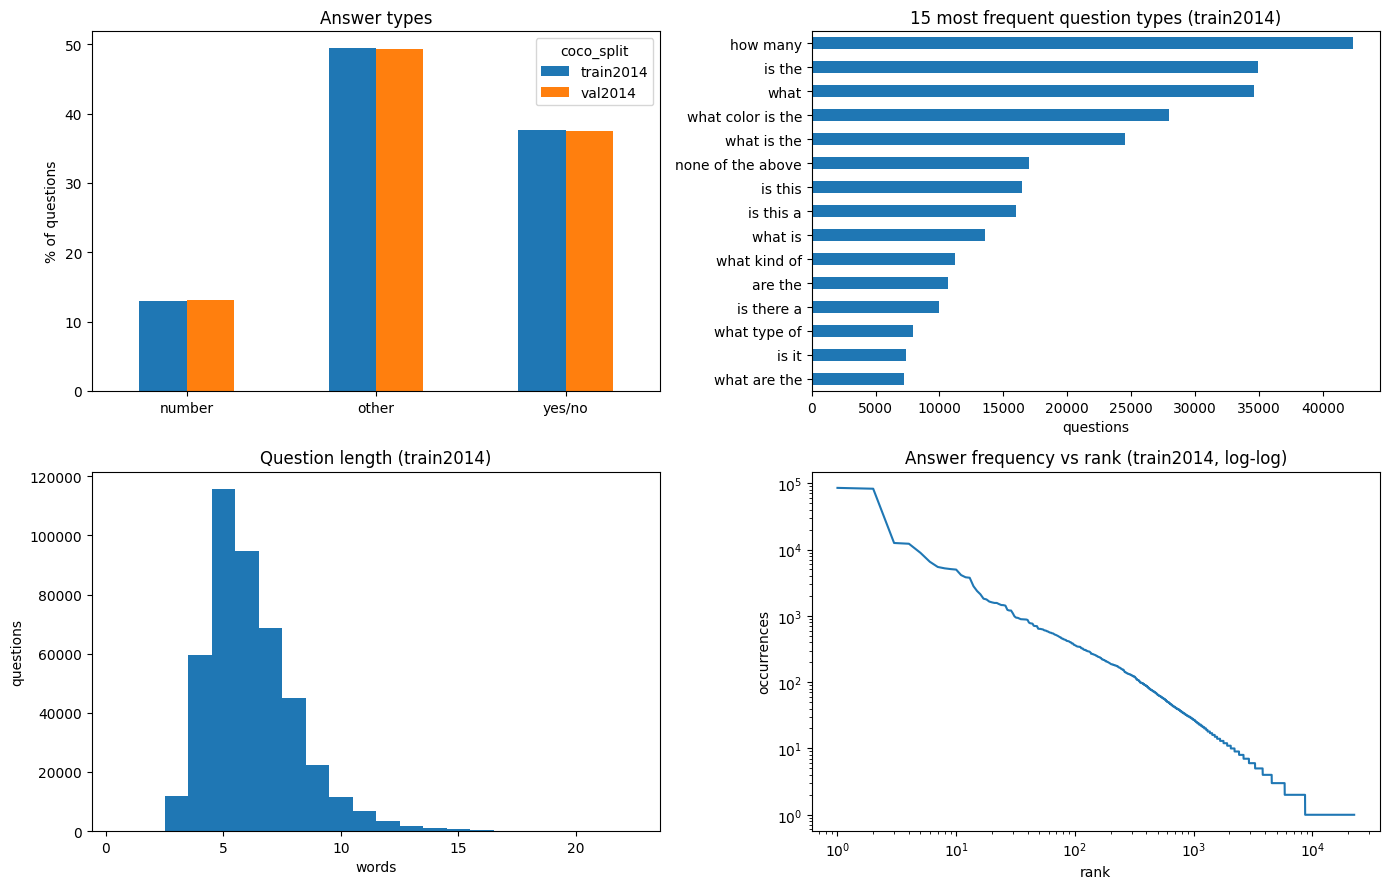

In [67]:
# 4.3 — Data exploration (full train2014 / val2014, before any subsampling)

# Display settings only, not hyperparameters: they change what is printed / plotted, never a result
TOP_N_QTYPES = 15
COVERAGE_TOPS = (10, 100, 1000, 3000)

train_df = vqa_df[vqa_df["coco_split"] == "train2014"]
val_df = vqa_df[vqa_df["coco_split"] == "val2014"]

# ---- 1. Answer types, per COCO split (is val2014, our test set, distributed like train2014?)
assert set(vqa_df["answer_type"]) == {"yes/no", "number", "other"}, "unexpected answer_type values"
answer_types = pd.crosstab(vqa_df["answer_type"], vqa_df["coco_split"], normalize="columns")
print("1. Answer types (% of the questions of each split)")
print((100 * answer_types).round(1).to_string())

# ---- 2. Question types (train2014)
qtype_counts = train_df["question_type"].value_counts()
top_share = qtype_counts.head(TOP_N_QTYPES).sum() / len(train_df)
print(f"\n2. {len(qtype_counts)} question types; the {TOP_N_QTYPES} most frequent cover {top_share:.1%} of train2014")
print(qtype_counts.head(5).to_string())

# ---- 3. Question length, in words (train2014)
q_len = train_df["question"].str.split().str.len()
print(f"\n3. Words per question: median = {q_len.median():.0f}, p90 = {q_len.quantile(0.9):.0f}, "
      f"p99 = {q_len.quantile(0.99):.0f}, max = {q_len.max()}")
# Each word gives at least 1 CLIP token, plus <start> and <end>: (words + 2) is a LOWER bound on the CLIP length.
surely_cut = (q_len + 2 > cfg.max_question_len).mean()
print(f"   Questions surely truncated at cfg.max_question_len = {cfg.max_question_len} CLIP tokens: {surely_cut:.3%}"
      "  (exact count in CLIP tokens: section 7)")

# ---- 4. Answers: long tail (train2014, raw multiple_choice_answer; normalization comes in 4.6)
ans_counts = train_df["multiple_choice_answer"].value_counts()
print(f"\n4. {len(ans_counts)} distinct answers, {(ans_counts == 1).sum()} of which appear only once")
for n in COVERAGE_TOPS:
    print(f"   top {n:>5} answers cover {ans_counts.head(n).sum() / len(train_df):.1%} of the questions")
a_len = train_df["multiple_choice_answer"].str.split().str.len()
print(f"   One-word answers: {(a_len == 1).mean():.1%}, longest: {a_len.max()} words"
      f"  (cfg.max_answer_len = {cfg.max_answer_len} Qwen tokens, checked in section 15)")

# ---- 5. Language prior: how far can we get WITHOUT looking at the image?
# Most frequent answer of each question type, fitted on train2014...
majority = (train_df.groupby("question_type")["multiple_choice_answer"]
            .agg(lambda s: s.value_counts().index[0]))
# ...evaluated on val2014 (exact match on multiple_choice_answer, NOT the VQA metric of 4.7).
# A question type absent from train gives NaN → counted as wrong.
hit = val_df["question_type"].map(majority) == val_df["multiple_choice_answer"]
yes_share = (train_df.loc[train_df["answer_type"] == "yes/no", "multiple_choice_answer"] == "yes").mean()
print(f"\n5. Language prior (no image): 'majority answer of the question type' → {hit.mean():.1%} exact match on val2014")
print((100 * hit.groupby(val_df["answer_type"]).mean()).round(1).to_string())
print(f"   Share of 'yes' among yes/no questions (train2014): {yes_share:.1%}")

# ---- Running example
ex_qtype = example_rows["question_type"].value_counts().index[0]
print(f'\nRunning example: question_type = "{ex_qtype}", '
      f'answer_type = {example_rows["answer_type"].value_counts().to_dict()}, '
      f'prior answer (no image) = "{majority[ex_qtype]}"')

# ---- Figure
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

(100 * answer_types).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Answer types", ylabel="% of questions", xlabel="")

qtype_counts.head(TOP_N_QTYPES)[::-1].plot.barh(ax=axes[0, 1])
axes[0, 1].set(title=f"{TOP_N_QTYPES} most frequent question types (train2014)", xlabel="questions", ylabel="")

axes[1, 0].hist(q_len, bins=np.arange(1, q_len.max() + 2) - 0.5)      # one bin per integer length
axes[1, 0].set(title="Question length (train2014)", xlabel="words", ylabel="questions")

axes[1, 1].loglog(np.arange(1, len(ans_counts) + 1), ans_counts.values)
axes[1, 1].set(title="Answer frequency vs rank (train2014, log-log)", xlabel="rank", ylabel="occurrences")

fig.tight_layout()
fig.savefig(cfg.path("fig", "4_3_exploration.png"), dpi=120, bbox_inches="tight")
plt.show()

### 4.4 Train / dev / test split by `image_id`

**Goal**: draw the images of each split and save their ID lists, so every later section works on exactly the same examples.

| Split | Source | Size | Role |
|---|---|---|---|
| train | train2014 | `cfg.n_train_images` | Training (section 18) |
| dev | train2014 | `cfg.n_dev_images` | Model selection, hyperparameters, oracle labels |
| test | val2014 | `cfg.n_test_images` | Final evaluation only (sections 19 – 20) |

**Concept: why split by image, not by question.** An image has about 5 questions. With a split by question, the same image would appear in train and in dev: the dev score would partly measure how well the model **remembers that image**, not how well it generalizes. With a split by `image_id`, no dev or test image is ever seen in training.

**Three less obvious choices:**

* **Nested subsets.** We shuffle the image pool once (with `cfg.seed`). Train takes the **start** of the permutation, dev takes the **end**. The DEBUG subset is therefore a strict **prefix** of the full subset: its 40 train images are among the full 10,000, and its dev images are among the full dev. What we debug on is part of what we will train on, and train and dev can never overlap, whatever the sizes.
* **Local generator** `np.random.default_rng(cfg.seed)`: the draw is the same whatever cells ran before. The global seed (3.5) would depend on how many random numbers were drawn earlier.
* **File name with the sizes.** `data_dir` is shared between DEBUG and full mode, so the file name contains the seed and the three sizes. A DEBUG split is never reloaded in full mode.

We only save **ID lists** here. The normalized DataFrame is saved in 4.8, once the answers are normalized.

In [68]:
# 4.4 — Train / dev / test split by image_id

def make_splits() -> dict:
    """Draws the image_ids of each split. Train and dev come from train2014, test from val2014."""
    rng = np.random.default_rng(cfg.seed)     # local generator: the draw does not depend on what ran before

    # np.sort first: the draw then depends only on the SET of images, not on the DataFrame row order
    train_pool = rng.permutation(np.sort(vqa_df.loc[vqa_df["coco_split"] == "train2014", "image_id"].unique()))
    test_pool = rng.permutation(np.sort(vqa_df.loc[vqa_df["coco_split"] == "val2014", "image_id"].unique()))

    n_tr, n_dev, n_te = cfg.n_train_images, cfg.n_dev_images, cfg.n_test_images
    assert n_tr + n_dev <= len(train_pool), "not enough train2014 images for train + dev"
    assert n_te <= len(test_pool), "not enough val2014 images for test"

    return {
        "train": train_pool[:n_tr].tolist(),                       # START of the permutation
        "dev":   train_pool[len(train_pool) - n_dev:].tolist(),    # END of the permutation → never overlaps train
        "test":  test_pool[:n_te].tolist(),
        "seed":  cfg.seed,
    }


# data_dir is shared between DEBUG and full → the sizes are part of the file name
split_file = cfg.path("data", f"splits_seed{cfg.seed}_train{cfg.n_train_images}"
                              f"_dev{cfg.n_dev_images}_test{cfg.n_test_images}.json")
SPLIT_IDS = load_or_compute(
    split_file,
    make_splits,
    save_fn=lambda obj, p: p.write_text(json.dumps(obj)),
    load_fn=lambda p: json.loads(p.read_text()),
)

# The subset as one DataFrame, with a `split` column.
# We filter on coco_split as well as image_id: each image_id is then looked up in the COCO split it was drawn from.
SPLIT_SOURCE = {"train": "train2014", "dev": "train2014", "test": "val2014"}
subset_df = pd.concat(
    [vqa_df[(vqa_df["coco_split"] == src) & vqa_df["image_id"].isin(SPLIT_IDS[split])].assign(split=split)
     for split, src in SPLIT_SOURCE.items()],
    ignore_index=True,
)

# Quick sanity checks (the full checks are in 4.9)
ids = {s: set(SPLIT_IDS[s]) for s in SPLIT_SOURCE}
assert not (ids["train"] & ids["dev"]), "train and dev share images"
assert len(ids["train"]) == cfg.n_train_images and len(ids["dev"]) == cfg.n_dev_images \
    and len(ids["test"]) == cfg.n_test_images, "a split does not have the expected number of images"

print()
show("subset_df", subset_df)
summary = subset_df.groupby("split", sort=False).agg(images=("image_id", "nunique"),
                                                      questions=("question_id", "size"))
summary["questions / image"] = (summary["questions"] / summary["images"]).round(2)
print(summary.to_string())

# Does the subset look like the full data? (very noisy in DEBUG: ~50 questions in dev / test)
types = pd.crosstab(subset_df["answer_type"], subset_df["split"], normalize="columns")[list(SPLIT_SOURCE)]
types["train2014 (full)"] = vqa_df.loc[vqa_df["coco_split"] == "train2014", "answer_type"].value_counts(normalize=True)
print("\nAnswer types (% of questions):")
print((100 * types).round(1).to_string())

# Running example: is "What color is the car?" in our subset?
in_subset = subset_df[subset_df["question"].str.lower() == "what color is the car?"]
print('\nRunning example: "What color is the car?" questions per split:',
      in_subset["split"].value_counts().reindex(list(SPLIT_SOURCE), fill_value=0).to_dict())

↩️  Reloaded: splits_seed42_train40_dev10_test10.json

subset_df                    len=285  type=DataFrame
       images  questions  questions / image
split                                      
train      40        173               4.32
dev        10         47               4.70
test       10         65               6.50

Answer types (% of questions):
split        train   dev  test  train2014 (full)
answer_type                                     
number        11.0  12.8  15.4              13.0
other         52.0  51.1  38.5              49.4
yes/no        37.0  36.2  46.2              37.6

Running example: "What color is the car?" questions per split: {'train': 0, 'dev': 0, 'test': 0}


### 4.5 Downloading the COCO 2014 images of the subset

**Goal**: put on the fast local disk (`cfg.image_dir`) **only** the images of our splits, not the whole of COCO 2014.

**Why image by image, not the official archive.** The train2014 archive holds all the train2014 images counted in 4.2 (several GB), and we need only `cfg.n_train_images + cfg.n_dev_images` of them. The COCO server also serves each image individually, under its official file name `COCO_<split>_<12-digit image_id>.jpg`.

**Where.** On `FAST_DIR`, not on Drive (see 3.1): reading thousands of small files from Drive is slow. On Colab, the images are therefore lost at the end of the session and re-downloaded at the next one. The cell is cheap to rerun, because it only fetches what is missing. The images do not depend on DEBUG: the DEBUG images are a subset of the full ones (4.4).

**Robustness**, same principle as 4.1:

* each image is written to `.tmp`, **fully decoded** with PIL (catches a truncated file or an HTML error page), then renamed to `.jpg`. A `.jpg` on disk is therefore always a valid image;
* a timeout, plus a few retries for network errors;
* if some images still fail, the cell stops with an `assert`. Rerunning it retries only the missing ones.

**Parallelism.** Downloading is *I/O-bound*: each thread mostly waits for the network, so Python threads are enough despite the GIL.

The cell ends with a **preview of section 5**: COCO images are often not square, and the CLIP preprocessing (resize the short side, then center crop) cuts off part of each image. We measure how much.

In [69]:
# 4.5 — Download only the COCO 2014 images of the subset
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image

COCO_BASE_URL = "http://images.cocodataset.org"   # this host does not answer over HTTPS (checked), hence HTTP

# Runtime / network settings, not hyperparameters: they change how fast we download, never a result
N_DOWNLOAD_THREADS = 16
DOWNLOAD_TIMEOUT_S = 30
N_RETRIES = 3


def coco_image_path(coco_split: str, image_id: int) -> Path:
    """Official COCO 2014 file name, e.g. <image_dir>/train2014/COCO_train2014_000000057870.jpg"""
    return Path(cfg.image_dir) / coco_split / f"COCO_{coco_split}_{image_id:012d}.jpg"


def fetch_coco_image(coco_split: str, image_id: int):
    """Downloads one image if it is missing. Returns None on success, an error message otherwise."""
    path = coco_image_path(coco_split, image_id)
    if path.exists():
        return None
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    url = f"{COCO_BASE_URL}/{coco_split}/{path.name}"

    err = None
    for attempt in range(1, N_RETRIES + 1):
        try:
            with urllib.request.urlopen(url, timeout=DOWNLOAD_TIMEOUT_S) as r, open(tmp, "wb") as f:
                shutil.copyfileobj(r, f)
            # Full decode: catches a truncated file, or an HTML error page saved as .jpg
            with Image.open(tmp) as im:
                im.load()
            tmp.replace(path)                     # the .jpg only appears once it is complete and valid
            return None
        except Exception as e:
            err = f"{coco_split}/{image_id}: {type(e).__name__}: {e}"
            time.sleep(attempt)                   # wait a bit longer after each failure
    tmp.unlink(missing_ok=True)
    return err


# Unique (coco_split, image_id) pairs of the subset
subset_images = list(subset_df[["coco_split", "image_id"]].drop_duplicates().itertuples(index=False, name=None))
missing = [(s, i) for s, i in subset_images if not coco_image_path(s, i).exists()]
print(f"{len(subset_images)} images in the subset, {len(missing)} to download")

errors = []
if missing:
    t0 = time.perf_counter()
    # Downloading is I/O-bound: threads wait on the network, so the GIL is not a bottleneck
    with ThreadPoolExecutor(max_workers=N_DOWNLOAD_THREADS) as pool:
        futures = [pool.submit(fetch_coco_image, s, i) for s, i in missing]
        for fut in tqdm(as_completed(futures), total=len(futures), desc="COCO images"):
            if (err := fut.result()) is not None:
                errors.append(err)
    print(f"⬇️  Done in {time.perf_counter() - t0:.1f} s")

# Rerunning the cell only retries the missing images
assert not errors, f"{len(errors)} images could not be downloaded, e.g.: {errors[:3]}"

# ---- What is on disk
paths = [coco_image_path(s, i) for s, i in subset_images]
assert all(p.exists() for p in paths), "some subset images are missing on disk"
sizes_kb = np.array([p.stat().st_size for p in paths]) / 1024
print(f"\nOn disk: {len(paths)} images, {sizes_kb.sum() / 1024:.1f} MB, {sizes_kb.mean():.0f} KB per image on average")

# Image sizes in pixels (Image.open only reads the header: fast)
wh = np.array([Image.open(p).size for p in paths])                 # (n_images, 2) = (width, height)
short, long = wh.min(axis=1), wh.max(axis=1)
print(f"Width:  median = {np.median(wh[:, 0]):.0f} px   Height: median = {np.median(wh[:, 1]):.0f} px")
print(f"Square images: {(short == long).mean():.1%}")
# Preview of section 5: resizing the short side to 224, then center-cropping 224×224, keeps a fraction short/long
# of the image area. The rest is cut off and CLIP never sees it.
print(f"Share of the image area cut off by the center crop: mean = {(1 - short / long).mean():.1%}, "
      f"max = {(1 - short / long).max():.1%}")

60 images in the subset, 0 to download

On disk: 60 images, 9.2 MB, 156 KB per image on average
Width:  median = 640 px   Height: median = 480 px
Square images: 3.3%
Share of the image area cut off by the center crop: mean = 28.3%, max = 51.7%


#### 4.5b Choosing the running-example image

**Goal**: fix the image of the running example, "What color is the car?" (section 1.5), and download it.

As expected, this question is not in the DEBUG subset (4.4). The running example is used **for display only** (shapes, heatmaps, selected patches), never for training or evaluation. Its image therefore does not have to belong to a split, and we download it on top of the subset.

**How we choose.** Among the questions that are exactly "What color is the car?" with `multiple_choice_answer = "red"`, we keep the ones where the most annotators agree on "red" (an unambiguous example). Ties are broken by `question_id`, so the choice is deterministic. The cell displays the candidates. The first one is the default, and you can pick another by setting `EXAMPLE_QID` to the `question_id` shown in its title.

The resulting `EXAMPLE` dictionary (question, 10 answers, image path) is reused in every section.

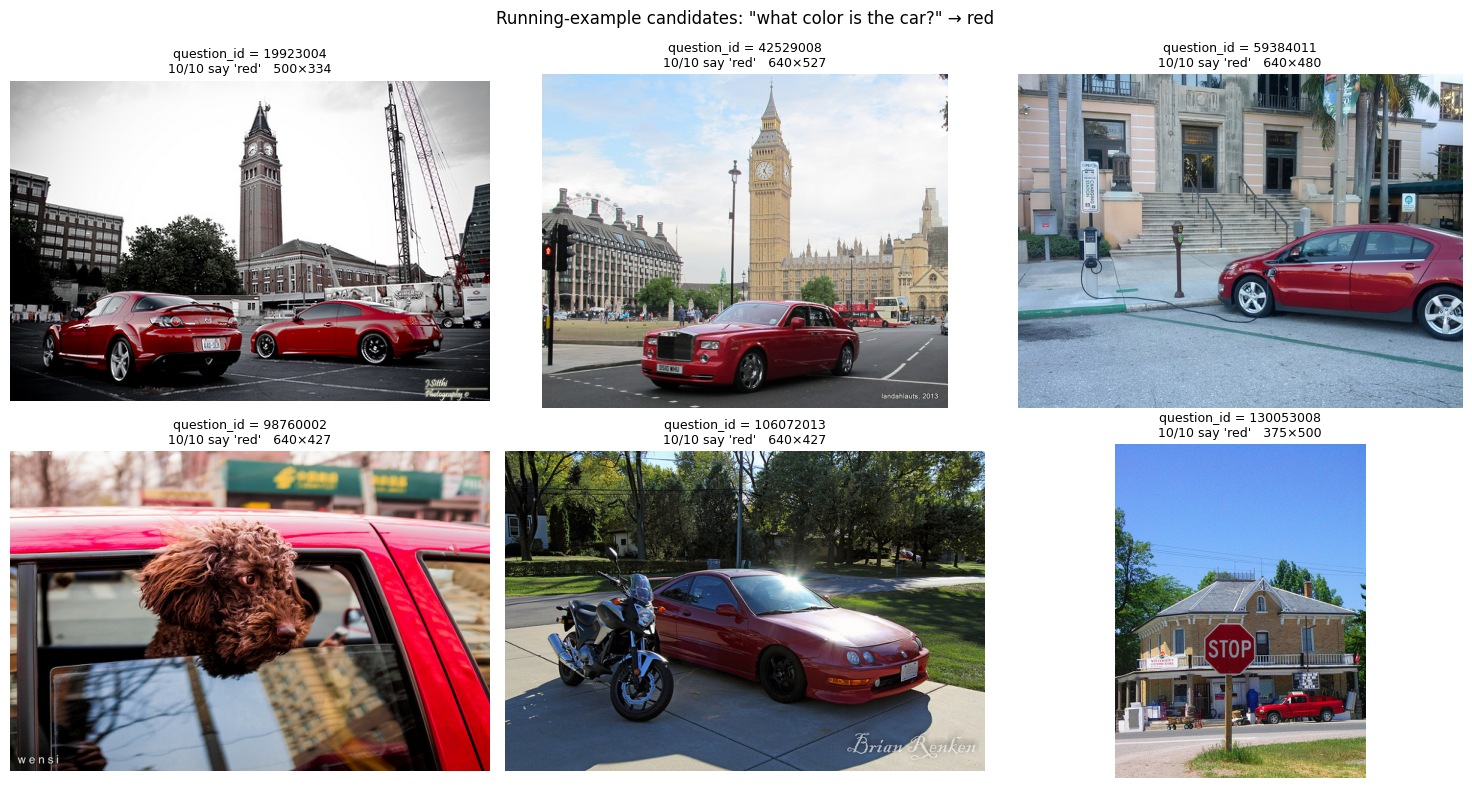

Chosen: question_id = 19923004  (val2014, image_id = 19923)
   in our splits: no → display only
   question      : What color is the car?
   10 answers    : ['red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red']
   multiple_choice_answer = 'red', answer_type = other

The 5 questions on this image:
                                question multiple_choice_answer
      How many cars are in this picture?                      2
What color are the cars in this picture?                    red
                 What make are the cars?                 nissan
              What is in the background?            clock tower
                  What color is the car?                    red

raw image (H×W×3)            (334, 500, 3)      uint8     cpu


In [70]:
# 4.5b — Choosing the running-example image ("What color is the car?")

# Definition of the running example (PLAN.md), not hyperparameters
EXAMPLE_QUESTION = "what color is the car?"     # compared in lower case
EXAMPLE_ANSWER = "red"
N_CANDIDATES = 6                                # display only
EXAMPLE_QID = None    # ← None = first candidate. Put a question_id from the grid below to choose another image.

# Candidates: exactly the running-example question, answered "red", sorted by agreement among the 10 annotators
cands = vqa_df[(vqa_df["question"].str.lower() == EXAMPLE_QUESTION)
               & (vqa_df["multiple_choice_answer"] == EXAMPLE_ANSWER)].copy()
cands["n_agree"] = cands["answers"].map(lambda answers: sum(a == EXAMPLE_ANSWER for a in answers))
cands = cands.sort_values(["n_agree", "question_id"], ascending=[False, True]).head(N_CANDIDATES)
assert len(cands) > 0, "no candidate for the running example"

# Download the candidate images (same function as for the subset)
errors = [e for s, i in zip(cands["coco_split"], cands["image_id"]) if (e := fetch_coco_image(s, i)) is not None]
assert not errors, f"candidate images could not be downloaded: {errors}"

# Grid of candidates
n_cols = 3
n_rows = math.ceil(len(cands) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, cands.itertuples()):
    with Image.open(coco_image_path(row.coco_split, row.image_id)) as im:
        ax.imshow(im)
        ax.set_title(f"question_id = {row.question_id}\n{row.n_agree}/10 say '{EXAMPLE_ANSWER}'   {im.width}×{im.height}",
                     fontsize=9)
fig.suptitle(f'Running-example candidates: "{EXAMPLE_QUESTION}" → {EXAMPLE_ANSWER}')
fig.tight_layout()
plt.show()

# The chosen example
qid = EXAMPLE_QID if EXAMPLE_QID is not None else int(cands["question_id"].iloc[0])
EXAMPLE = vqa_df.loc[vqa_df["question_id"] == qid].iloc[0].to_dict()
assert fetch_coco_image(EXAMPLE["coco_split"], EXAMPLE["image_id"]) is None, "running-example image download failed"
EXAMPLE["image_path"] = coco_image_path(EXAMPLE["coco_split"], EXAMPLE["image_id"])

in_split = subset_df.loc[subset_df["question_id"] == qid, "split"].tolist()
print(f"Chosen: question_id = {qid}  ({EXAMPLE['coco_split']}, image_id = {EXAMPLE['image_id']})")
print(f"   in our splits: {in_split[0] if in_split else 'no → display only'}")
print(f"   question      : {EXAMPLE['question']}")
print(f"   10 answers    : {EXAMPLE['answers']}")
print(f"   multiple_choice_answer = {EXAMPLE['multiple_choice_answer']!r}, answer_type = {EXAMPLE['answer_type']}")

# The other questions asked about the same image (useful for "one image, several questions", section 21)
same_image = vqa_df[(vqa_df["coco_split"] == EXAMPLE["coco_split"]) & (vqa_df["image_id"] == EXAMPLE["image_id"])]
print(f"\nThe {len(same_image)} questions on this image:")
print(same_image[["question", "multiple_choice_answer"]].to_string(index=False))

# First line of the running-example table: the raw image, H×W×3
example_image = Image.open(EXAMPLE["image_path"]).convert("RGB")
print()
show("raw image (H×W×3)", torch.from_numpy(np.array(example_image)))

### 4.6 Official answer normalization

**Goal**: compare answers the way the official evaluation does. Without normalization, "Two", "two" and "2" would be three different answers.

The rules below are copied **verbatim** from the official script ([`GT-Vision-Lab/VQA`](https://github.com/GT-Vision-Lab/VQA), `PythonEvaluationTools/vqaEvaluation/vqaEval.py`), including their quirks. Our numbers stay comparable to published VQAv2 results only if we use the same rules.

| Step | Rule | Example |
|---|---|---|
| 1 | `\n` and `\t` → space, then `strip()` | `"  yes\n"` → `"yes"` |
| 2 | **Punctuation** (21 symbols): deleted if it touches a space, or if the text contains a number like `1,000`; otherwise replaced by a space | `"black, white"` → `"black white"`, `"black/white"` → `"black white"` |
| 3 | **Periods** deleted, unless followed by a digit | `"car."` → `"car"`, but `"3.5"` stays |
| 4 | **Lower case**, then **number words → digits** (zero to ten, and also `none` → `0`) | `"Two"` → `"2"` |
| 5 | **Articles** removed (`a`, `an`, `the`) | `"a red car"` → `"red car"` |
| 6 | **Contractions** restored | `"dont"` → `"don't"` |

**Two quirks we keep on purpose:**

* `none` → `0`: "How many dogs?" → "none" counts as "0". This is a choice of the official script.
* The script passes `re.UNICODE` (= 32) where `re.sub` expects its `count` argument: at most 32 periods are removed. This never matters for a VQA answer, but we reproduce it rather than fix it.

The rest of the official logic (normalization is only applied when the annotators **disagree**) belongs to the metric: it is in 4.7.

The cell prints a few hand-picked examples, then measures how many raw answers of train2014 normalization actually changes.

In [71]:
# 4.6 — Official answer normalization (rules copied verbatim from vqaEval.py)
import re

# ---- Official tables, copied verbatim (including the capitalized keys, which can never match after lower())
CONTRACTIONS = {
    "aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've", "couldnt": "couldn't",
    "couldn'tve": "couldn't've", "couldnt've": "couldn't've", "didnt": "didn't", "doesnt": "doesn't", "dont": "don't",
    "hadnt": "hadn't", "hadnt've": "hadn't've", "hadn'tve": "hadn't've", "hasnt": "hasn't", "havent": "haven't",
    "hed": "he'd", "hed've": "he'd've", "he'dve": "he'd've", "hes": "he's", "howd": "how'd", "howll": "how'll",
    "hows": "how's", "Id've": "I'd've", "I'dve": "I'd've", "Im": "I'm", "Ive": "I've", "isnt": "isn't", "itd": "it'd",
    "itd've": "it'd've", "it'dve": "it'd've", "itll": "it'll", "let's": "let's", "maam": "ma'am", "mightnt": "mightn't",
    "mightnt've": "mightn't've", "mightn'tve": "mightn't've", "mightve": "might've", "mustnt": "mustn't",
    "mustve": "must've", "neednt": "needn't", "notve": "not've", "oclock": "o'clock", "oughtnt": "oughtn't",
    "ow's'at": "'ow's'at", "'ows'at": "'ow's'at", "'ow'sat": "'ow's'at", "shant": "shan't", "shed've": "she'd've",
    "she'dve": "she'd've", "she's": "she's", "shouldve": "should've", "shouldnt": "shouldn't",
    "shouldnt've": "shouldn't've", "shouldn'tve": "shouldn't've", "somebody'd": "somebodyd",
    "somebodyd've": "somebody'd've", "somebody'dve": "somebody'd've", "somebodyll": "somebody'll",
    "somebodys": "somebody's", "someoned": "someone'd", "someoned've": "someone'd've", "someone'dve": "someone'd've",
    "someonell": "someone'll", "someones": "someone's", "somethingd": "something'd", "somethingd've": "something'd've",
    "something'dve": "something'd've", "somethingll": "something'll", "thats": "that's", "thered": "there'd",
    "thered've": "there'd've", "there'dve": "there'd've", "therere": "there're", "theres": "there's", "theyd": "they'd",
    "theyd've": "they'd've", "they'dve": "they'd've", "theyll": "they'll", "theyre": "they're", "theyve": "they've",
    "twas": "'twas", "wasnt": "wasn't", "wed've": "we'd've", "we'dve": "we'd've", "weve": "we've", "werent": "weren't",
    "whatll": "what'll", "whatre": "what're", "whats": "what's", "whatve": "what've", "whens": "when's",
    "whered": "where'd", "wheres": "where's", "whereve": "where've", "whod": "who'd", "whod've": "who'd've",
    "who'dve": "who'd've", "wholl": "who'll", "whos": "who's", "whove": "who've", "whyll": "why'll", "whyre": "why're",
    "whys": "why's", "wont": "won't", "wouldve": "would've", "wouldnt": "wouldn't", "wouldnt've": "wouldn't've",
    "wouldn'tve": "wouldn't've", "yall": "y'all", "yall'll": "y'all'll", "y'allll": "y'all'll",
    "yall'd've": "y'all'd've", "y'alld've": "y'all'd've", "y'all'dve": "y'all'd've", "youd": "you'd",
    "youd've": "you'd've", "you'dve": "you'd've", "youll": "you'll", "youre": "you're", "youve": "you've",
}
MANUAL_MAP = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
              "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
ARTICLES = ["a", "an", "the"]
# A "." NOT followed by a digit. (The first group "(?!<=\d)" is the official pattern: a malformed
# look-behind that has no effect in practice. We keep it to stay identical.)
PERIOD_STRIP = re.compile(r"(?!<=\d)(\.)(?!\d)")
COMMA_STRIP = re.compile(r"(\d)(\,)(\d)")          # a "," between two digits, as in "1,000"
PUNCT = [";", r"/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]


def process_punctuation(text: str) -> str:
    """Official processPunctuation."""
    out = text
    for p in PUNCT:
        # Symbol next to a space, or text containing a number like "1,000" → deleted. Otherwise → a space.
        # Note: the test is done on the ORIGINAL text, the replacement on the current one (as in the official code).
        if (p + " " in text or " " + p in text) or (re.search(COMMA_STRIP, text) is not None):
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    # Official quirk: re.UNICODE (= 32) is passed as `count` → at most 32 periods removed
    return PERIOD_STRIP.sub("", out, count=int(re.UNICODE))


def process_digit_article(text: str) -> str:
    """Official processDigitArticle: lower case, number words → digits, articles removed, contractions restored."""
    words = []
    for w in text.lower().split():
        w = MANUAL_MAP.get(w, w)
        if w not in ARTICLES:
            words.append(w)
    words = [CONTRACTIONS.get(w, w) for w in words]
    return " ".join(words)


def clean_whitespace(text: str) -> str:
    """Step applied by the official script to EVERY answer, before anything else."""
    return text.replace("\n", " ").replace("\t", " ").strip()


def normalize_answer(text: str) -> str:
    """The full chain: whitespace → punctuation → digits / articles / contractions."""
    return process_digit_article(process_punctuation(clean_whitespace(text)))


# ---- 1. Hand-picked examples (the expected outputs are tested in 4.9)
demo = ["Two", "a red car.", "3.5", "1,000", "black, white", "black/white", "dont", "None", "  Yes!\n", "the dog's"]
print("1. Examples")
for s in demo:
    print(f"   {s!r:<16} → {normalize_answer(s)!r}")

# ---- 2. On real data: all the raw human answers of train2014 (10 per question)
answer_freq = vqa_df.loc[vqa_df["coco_split"] == "train2014", "answers"].explode().value_counts()
normalized = pd.Series({a: normalize_answer(a) for a in answer_freq.index})      # one call per DISTINCT answer
is_changed = normalized.index.to_numpy() != normalized.to_numpy()
print(f"\n2. train2014: {answer_freq.sum()} human answers, {len(answer_freq)} distinct")
print(f"   distinct answers changed by normalization: {is_changed.sum()} ({is_changed.mean():.1%})")
print(f"   share of all answer occurrences changed  : {answer_freq[is_changed].sum() / answer_freq.sum():.1%}")
print(f"   distinct answers after normalization     : {normalized.nunique()}")
print("   Most frequent answers changed by normalization:")
top_changed = pd.DataFrame({"raw": normalized.index[is_changed], "normalized": normalized.to_numpy()[is_changed],
                            "occurrences": answer_freq.to_numpy()[is_changed]})
print(top_changed.head(10).to_string(index=False))

# ---- Running example
print(f"\nRunning example, 10 answers normalized: {[normalize_answer(a) for a in EXAMPLE['answers']]}")

1. Examples
   'Two'            → '2'
   'a red car.'     → 'red car'
   '3.5'            → '3.5'
   '1,000'          → '1000'
   'black, white'   → 'black white'
   'black/white'    → 'black white'
   'dont'           → "don't"
   'None'           → '0'
   '  Yes!\n'       → 'yes'
   "the dog's"      → "dog's"

2. train2014: 4437570 human answers, 162496 distinct
   distinct answers changed by normalization: 20641 (12.7%)
   share of all answer occurrences changed  : 1.2%
   distinct answers after normalization     : 157463
   Most frequent answers changed by normalization:
         raw  normalized  occurrences
        none           0        10570
      no one        no 1         1818
     one way       1 way          527
           a                      401
one on right  1 on right          385
 one on left   1 on left          317
black, white black white          289
           ?                      268
     t-shirt     t shirt          253
         n/a           n          252


### 4.7 The official VQA Accuracy

**Goal**: score a predicted answer against the 10 human answers, exactly like the official script.

**Concept: a "soft" metric.** Humans do not all give the same answer ("red" / "dark red" / "maroon"). An answer is considered fully correct if **at least 3 annotators** gave it. To make the score robust to the choice of annotators, it is averaged over the **10 subsets of 9 annotators** (leave one out):

$$
\mathrm{Acc}(a) = \frac{1}{10} \sum_{i=1}^{10} \min\!\left(1,\ \frac{\#\{\, j \neq i : a_j = a \,\}}{3}\right)
$$

If $n$ of the 10 annotators gave answer $a$: in the $n$ subsets that leave out one of them, $n-1$ matches remain; in the other $10-n$ subsets, all $n$ matches remain. So

$$
\mathrm{Acc}(n) = \frac{n \cdot \min\!\left(1, \frac{n-1}{3}\right) + (10 - n) \cdot \min\!\left(1, \frac{n}{3}\right)}{10}
$$

Worked example, $n = 2$ (2 annotators out of 10 agree with us): $\frac{2 \cdot \frac13 + 8 \cdot \frac23}{10} = \frac{18}{30} = 0.6$. Computed by hand the same way: $n = 1 \to 0.3$, $n = 3 \to 0.9$, $n \ge 4 \to 1$. These values are tested in 4.9.

**The official quirk: normalization only when annotators disagree.** The script applies the 4.6 normalization (to the prediction **and** to the 10 answers) only if the 10 answers are not all identical. When they are unanimous, the prediction is compared to the **raw** string: "Red" against ten "red" scores **0**. We reproduce this exactly. Consequence for us: the model must produce answers **in the dataset's format** (lower case, digits…), which is why the training target (4.8) is the raw `multiple_choice_answer`, not a re-normalized version.

The cell prints the score table as a function of $n$ (computed by the function, not written by hand), then scores a few candidate predictions on the running example.

In [72]:
# 4.7 — Official VQA Accuracy (replica of VQAEval.evaluate in vqaEval.py)

def vqa_accuracy(pred: str, gt_answers: list) -> float:
    """VQA accuracy of ONE prediction against the human answers (10 in VQAv2). Returns a value in [0, 1]."""
    gts = [clean_whitespace(a) for a in gt_answers]
    res = clean_whitespace(pred)

    # Official quirk: normalization (4.6) only when the annotators do NOT all agree
    if len(set(gts)) > 1:
        gts = [process_digit_article(process_punctuation(a)) for a in gts]
        res = process_digit_article(process_punctuation(res))

    # Leave-one-out: for each annotator i, count the matches among the 9 others
    accs = []
    for i in range(len(gts)):
        others = gts[:i] + gts[i + 1:]
        n_match = sum(a == res for a in others)
        accs.append(min(1.0, n_match / 3))
    return sum(accs) / len(accs)


def vqa_accuracy_batch(preds, gt_answers_list) -> np.ndarray:
    """Vectorized over questions: one score per (prediction, list of 10 answers) pair."""
    return np.array([vqa_accuracy(p, g) for p, g in zip(preds, gt_answers_list)])


# ---- 1. Score as a function of n = number of annotators (out of 10) who gave our answer
# The other 10 - n annotators give distinct answers, so the "disagreement" branch is used (except n = 10).
print("1. Score vs number of annotators who agree with the prediction")
for n in range(0, 11):
    gts = ["red"] * n + [f"other{j}" for j in range(10 - n)]
    print(f"   n = {n:>2}  →  {vqa_accuracy('red', gts):.3f}")

# ---- 2. Running example: a few candidate predictions
print(f"\n2. Running example, answers = {EXAMPLE['answers']}")
example_preds = ["red", "Red", "red.", "dark red", "white", "the red one"]
scores = vqa_accuracy_batch(example_preds, [EXAMPLE["answers"]] * len(example_preds))
unanimous = len(set(clean_whitespace(a) for a in EXAMPLE["answers"])) == 1
print(f"   unanimous annotators: {unanimous}  → normalization {'NOT ' if unanimous else ''}applied")
for p, s in zip(example_preds, scores):
    print(f"   {p!r:<14} → {s:.3f}")

1. Score vs number of annotators who agree with the prediction
   n =  0  →  0.000
   n =  1  →  0.300
   n =  2  →  0.600
   n =  3  →  0.900
   n =  4  →  1.000
   n =  5  →  1.000
   n =  6  →  1.000
   n =  7  →  1.000
   n =  8  →  1.000
   n =  9  →  1.000
   n = 10  →  1.000

2. Running example, answers = ['red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red', 'red']
   unanimous annotators: True  → normalization NOT applied
   'red'          → 1.000
   'Red'          → 0.000
   'red.'         → 0.000
   'dark red'     → 0.000
   'white'        → 0.000
   'the red one'  → 0.000


### 4.8 Training target and saving the subset

**Goal**: choose the single string the model learns to generate for each question, then save the subset table that sections 6 and 18 – 20 reload.

**The target: `multiple_choice_answer`.** It is the most frequent of the 10 human answers (as defined by VQAv2). The LLM is trained with a cross-entropy on **one** answer string (section 2.3), so we need a single answer per question. This is the standard choice for generative VQA models. Alternatives (drawing one of the 10 answers at random, or soft targets over an answer vocabulary) are possible, but they are out of scope here.

**Why the raw target, not a normalized one.** Consider the two cases of the official metric (4.7):

* **annotators disagree**: the prediction is normalized before comparison, so the raw and normalized targets score the same;
* **annotators are unanimous**: the prediction is compared to the **raw** string. A model trained on a normalized target could produce `"2"` where the 10 annotators wrote `"two"`, and score 0.

The raw target is therefore never worse. The cell measures how often each case happens.

**Concept: the ceiling of the target.** Even a perfect model that always outputs `multiple_choice_answer` does not get 100%, because annotators disagree. Its score is the **ceiling** of what our training can achieve. We store it per question (`oracle_acc`) and will compare our models to it in section 20.

**Saving.** One row per question, in `data_dir`, with the same seed and sizes in the file name as the split (4.4). We save the raw `answers`: the metric normalizes them itself when it has to.

In [73]:
# 4.8 — Training target and saving the subset table
SUBSET_COLUMNS = ["split", "coco_split", "image_id", "question_id", "question", "question_type", "answer_type",
                  "answers", "target", "oracle_acc"]


def build_subset_table() -> pd.DataFrame:
    df = subset_df.copy()
    # Same whitespace cleaning as the official script, nothing else (see the markdown above)
    df["target"] = df["multiple_choice_answer"].map(clean_whitespace)
    # Score of a perfect model that always outputs the target = ceiling of the training
    df["oracle_acc"] = vqa_accuracy_batch(df["target"], df["answers"])
    return df[SUBSET_COLUMNS].reset_index(drop=True)


# Same seed and sizes as the split file of 4.4: "splits_..." → "subset_..."
subset_file = cfg.path("data", split_file.stem.replace("splits_", "subset_") + ".pkl")
data_df = load_or_compute(subset_file, build_subset_table,
                          save_fn=lambda obj, p: obj.to_pickle(p), load_fn=pd.read_pickle)
print()
show("data_df", data_df)


# ---- 1. Raw vs normalized target: how often does it matter?
def target_stats(df: pd.DataFrame) -> dict:
    target = df["multiple_choice_answer"].map(clean_whitespace)
    cache = {t: normalize_answer(t) for t in target.unique()}          # one call per distinct target
    changed = target.map(cache) != target
    unanimous = df["answers"].map(lambda answers: len(set(clean_whitespace(a) for a in answers)) == 1)
    return {
        "questions": len(df),
        "target changed by normalization": f"{changed.mean():.2%}",
        "unanimous annotators": f"{unanimous.mean():.1%}",
        "unanimous AND target changed (normalized target would score 0)": f"{(unanimous & changed).mean():.2%}",
    }


stats = pd.DataFrame({
    "subset": target_stats(subset_df),
    "train2014 (full)": target_stats(vqa_df[vqa_df["coco_split"] == "train2014"]),
})
print("\n1. Raw vs normalized target")
print(stats.to_string())

# ---- 2. Ceiling of the target (oracle), per split and per answer type
print("\n2. Ceiling: VQA accuracy of a model that always outputs the target (%)")
ceiling = data_df.pivot_table(index="answer_type", columns="split", values="oracle_acc", aggfunc="mean")
ceiling.loc["all"] = data_df.groupby("split")["oracle_acc"].mean()
print((100 * ceiling[list(SPLIT_SOURCE)]).round(1).to_string())

# ---- 3. Target length (the exact length in Qwen tokens is checked in section 15)
target_words = data_df["target"].str.split().str.len()
print(f"\n3. Target length: {(target_words == 1).mean():.1%} one-word targets, longest = {target_words.max()} words")
print(f"   e.g. {data_df.loc[target_words.idxmax(), 'target']!r}")

# ---- Running example
ex_target = clean_whitespace(EXAMPLE["multiple_choice_answer"])
print(f"\nRunning example: target = {ex_target!r}, ceiling = {vqa_accuracy(ex_target, EXAMPLE['answers']):.3f}")

↩️  Reloaded: subset_seed42_train40_dev10_test10.pkl

data_df                      len=285  type=DataFrame

1. Raw vs normalized target
                                                               subset train2014 (full)
questions                                                         285           443757
target changed by normalization                                 1.05%            0.74%
unanimous annotators                                            28.8%            33.4%
unanimous AND target changed (normalized target would score 0)  0.00%            0.02%

2. Ceiling: VQA accuracy of a model that always outputs the target (%)
split        train    dev   test
answer_type                     
number        98.4  100.0   93.0
other         96.0   88.3   94.0
yes/no       100.0  100.0  100.0
all           97.7   94.0   96.6

3. Target length: 93.0% one-word targets, longest = 5 words
   e.g. 'delicious hand-crafted natural ice cream'

Running example: target = 'red', ceiling = 1.0

### 4.9 Section 4 checks

1. **Normalization**: hand-computed cases (one per rule of 4.6).
2. **VQA Accuracy**: hand-computed cases. The score as a function of $n$ ($0, 0.3, 0.6, 0.9, 1$), the unanimous case without normalization, and the normalization branch (number words, articles, punctuation).
3. **Splits**: no image shared between train, dev and test, the right COCO split for each, the sizes from `cfg`, every question of a selected image kept, and the same draw when `make_splits()` is called again.
4. **Images**: every subset image and the running-example image are on disk.
5. **Saved table**: reloading the file gives exactly the same table, and every target is a non-empty string.
6. **Ceiling**: a target that appears among the 10 answers scores at least $0.3$ (the $n = 1$ case). This is a mathematical property of the metric, so a failure here would mean a bug in `vqa_accuracy`.

In [74]:
# 4.9 — Section 4 checks
checks = {}

# ---- 1. Normalization: hand-computed expected outputs
NORM_CASES = {
    "Two dogs": "2 dogs",            # lower case + number word → digit
    "a red car.": "red car",         # final period removed, article removed
    "3.5": "3.5",                    # a period followed by a digit is kept
    "1,000": "1000",                 # text contains digit,digit → the comma is deleted (not a space)
    "black, white": "black white",   # "," touches a space → deleted
    "black/white": "black white",    # isolated "/" → replaced by a space
    "dont": "don't",                 # contraction restored
    "None": "0",                     # official quirk: none → 0
    "  Yes!\n": "yes",               # whitespace, "!" → space, lower case
}
bad = {s: (normalize_answer(s), exp) for s, exp in NORM_CASES.items() if normalize_answer(s) != exp}
checks["normalization: hand-computed cases"] = not bad
if bad:
    print("Normalization mismatches (got, expected):", bad)


# ---- 2. VQA Accuracy: hand-computed expected scores
def gt_with(n: int, answer: str = "red") -> list:
    """10 answers: n annotators gave `answer`, the others gave distinct other answers."""
    return [answer] * n + [f"other{j}" for j in range(10 - n)]


ACC_CASES = [
    # (prediction, 10 answers, expected score, why)
    *[("red", gt_with(n), exp, f"n = {n}") for n, exp in [(0, 0.0), (1, 0.3), (2, 0.6), (3, 0.9), (4, 1.0), (9, 1.0)]],
    ("red", ["red"] * 10, 1.0, "unanimous, same string"),
    ("Red", ["red"] * 10, 0.0, "unanimous → no normalization (official quirk)"),
    ("Red", ["red"] * 9 + ["dark red"], 1.0, "disagreement → normalized, n = 9"),
    ("Two", ["2"] * 3 + ["3"] * 7, 0.9, "number word → digit, n = 3"),
    ("the dog", ["dog"] * 2 + ["cat"] * 8, 0.6, "article removed, n = 2"),
    ("yes!", ["yes"] * 5 + ["no"] * 5, 1.0, "punctuation removed, n = 5"),
    ("blue", ["red"] * 10, 0.0, "wrong answer"),
]
bad = [(why, vqa_accuracy(p, g), exp) for p, g, exp, why in ACC_CASES if not math.isclose(vqa_accuracy(p, g), exp, abs_tol=1e-9)]
checks["VQA accuracy: hand-computed cases"] = not bad
if bad:
    print("VQA accuracy mismatches (case, got, expected):", bad)

# ---- 3. Splits
images = {s: set(data_df.loc[data_df["split"] == s, ["coco_split", "image_id"]].itertuples(index=False, name=None))
          for s in SPLIT_SOURCE}
raw_ids = {s: {i for _, i in images[s]} for s in SPLIT_SOURCE}
checks["no image shared between train / dev / test"] = (
    not (images["train"] & images["dev"]) and not (images["train"] & images["test"]) and not (images["dev"] & images["test"])
)
# COCO image_ids are unique across train2014 and val2014, so the raw ids must be disjoint too
checks["no image_id shared between train / dev / test"] = (
    not (raw_ids["train"] & raw_ids["dev"]) and not (raw_ids["train"] & raw_ids["test"]) and not (raw_ids["dev"] & raw_ids["test"])
)
checks["train / dev from train2014, test from val2014"] = all(
    {c for c, _ in images[s]} == {SPLIT_SOURCE[s]} for s in SPLIT_SOURCE
)
checks["split sizes match cfg"] = (
    len(images["train"]), len(images["dev"]), len(images["test"])
) == (cfg.n_train_images, cfg.n_dev_images, cfg.n_test_images)
n_questions_full = vqa_df.groupby(["coco_split", "image_id"]).size()
n_questions_subset = data_df.groupby(["coco_split", "image_id"]).size()
checks["every question of a selected image is kept"] = n_questions_subset.eq(
    n_questions_full.loc[n_questions_subset.index]).all()
checks["question_id unique in the subset"] = data_df["question_id"].is_unique
checks["make_splits() is deterministic (same as the file)"] = make_splits() == SPLIT_IDS

# ---- 4. Images on disk
checks["all subset images on disk"] = all(
    coco_image_path(c, i).exists() for s in SPLIT_SOURCE for c, i in images[s]
)
checks["running-example image on disk"] = Path(EXAMPLE["image_path"]).exists()

# ---- 5. Saved table
reloaded = pd.read_pickle(subset_file)
checks["saved table reloads identically"] = (
    reloaded.drop(columns="answers").equals(data_df.drop(columns="answers"))
    and reloaded["answers"].tolist() == data_df["answers"].tolist()
)
checks["every target is a non-empty string"] = data_df["target"].map(lambda t: isinstance(t, str) and len(t) > 0).all()
checks["10 answers per question"] = data_df["answers"].map(len).eq(10).all()

# ---- 6. Ceiling
target_in_answers = [t in [clean_whitespace(a) for a in answers] for t, answers in zip(data_df["target"], data_df["answers"])]
target_in_answers = np.array(target_in_answers)
checks["oracle_acc in [0, 1]"] = data_df["oracle_acc"].between(0, 1).all()
checks["target among the answers → oracle_acc ≥ 0.3"] = (data_df.loc[target_in_answers, "oracle_acc"] >= 0.3 - 1e-9).all()
print(f"Information: target found among the 10 raw answers for {target_in_answers.mean():.1%} of the questions")

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 4 check failed: do not move on to section 5."
print("\nSection 4 validated → we can move on to section 5.")

Information: target found among the 10 raw answers for 100.0% of the questions

✅ normalization: hand-computed cases
✅ VQA accuracy: hand-computed cases
✅ no image shared between train / dev / test
✅ no image_id shared between train / dev / test
✅ train / dev from train2014, test from val2014
✅ split sizes match cfg
✅ every question of a selected image is kept
✅ question_id unique in the subset
✅ make_splits() is deterministic (same as the file)
✅ all subset images on disk
✅ running-example image on disk
✅ saved table reloads identically
✅ every target is a non-empty string
✅ 10 answers per question
✅ oracle_acc in [0, 1]
✅ target among the answers → oracle_acc ≥ 0.3

Section 4 validated → we can move on to section 5.


## Section 5. Image preprocessing

**Goal**: understand what CLIP actually sees. The ViT never receives the COCO photo itself: it receives a 3×224×224 tensor produced by a fixed preprocessing pipeline. Everything the selector can choose from (section 9 onward) comes from this tensor.

| Subsection | Role |
|---|---|
| 5.1 | Apply the `CLIPImageProcessor` (resize, center crop, normalize), and reproduce it by hand |
| 5.2 | Original image next to the cropped image: what the crop removes |
| 5.3 | Overlay the 14×14 patch grid: one 16×16 patch = one visual token |
| 5.4 | Section checks |

### 5.1 The CLIP preprocessing pipeline

**Goal**: turn the raw running-example image (H×W×3, `uint8`) into the tensor the ViT expects (3×224×224, `float32`).

The `CLIPImageProcessor` of `cfg.clip_name` applies four steps, always the same ones CLIP was trained with:

| Step | Operation | Running example (500×334) |
|---|---|---|
| 1 | **Resize** the *short* side to 224 (bicubic), keeping the aspect ratio | 500×334 → 335×224 |
| 2 | **Center crop** 224×224 | the left and right edges are cut off |
| 3 | **Rescale** `uint8` [0, 255] → [0, 1] (× 1/255) | |
| 4 | **Normalize** per channel: $x_c \leftarrow (x_c - \mu_c) / \sigma_c$ | $\mu, \sigma$ = CLIP's training statistics |

**Concept: why normalize with fixed constants.** $\mu$ and $\sigma$ are the mean and standard deviation of each RGB channel over CLIP's **training set**, not over our image. The ViT's first layer learned its weights on inputs with that distribution, so we must give it inputs on the same scale. Consequence: the mean is close to 0 **on average over many images**, not for each image. A bright or reddish photo has a positive mean. Section 5.4 checks the mean over the whole subset.

**Layout change.** PIL / NumPy store images as H×W×C (channels last), PyTorch convolutions expect C×H×W (channels first). The processor also adds a batch dimension: `pixel_values` has shape 1×3×224×224.

To make sure we understand each step, the cell reproduces the pipeline by hand (PIL + PyTorch, about ten lines) and checks that it gives **exactly** the same tensor as the processor.

In [75]:
# 5.1 — CLIP preprocessing: resize, center crop, rescale, normalize
from transformers import CLIPImageProcessor

image_processor = CLIPImageProcessor.from_pretrained(cfg.clip_name)
print(f"resize        : shortest edge → {image_processor.size['shortest_edge']} "
      f"(resample = {Image.Resampling(image_processor.resample).name})")
print(f"center crop   : {image_processor.crop_size}")
print(f"rescale factor: {image_processor.rescale_factor:.6f}  (= 1/255)")
print(f"mean (RGB)    : {image_processor.image_mean}")
print(f"std  (RGB)    : {image_processor.image_std}")
assert image_processor.crop_size == {"height": cfg.image_size, "width": cfg.image_size}, "crop size ≠ cfg.image_size"

# ---- 1. The processor (what we will use everywhere)
pixel_values = image_processor(images=example_image, return_tensors="pt")["pixel_values"]
print()
show("raw image (H×W×3)", torch.from_numpy(np.array(example_image)))
show("pixel_values (1×3×224×224)", pixel_values)
assert pixel_values.shape == (1, 3, cfg.image_size, cfg.image_size)

# ---- 2. The same pipeline by hand, to understand each step
S = cfg.image_size
w, h = example_image.size                                   # PIL gives (width, height)
# Step 1: short side → S, long side scaled proportionally (int() truncates, as in transformers)
new_w, new_h = (S, int(S * h / w)) if w <= h else (int(S * w / h), S)
resized = example_image.resize((new_w, new_h), Image.Resampling.BICUBIC)
# Step 2: center crop S×S
left, top = (new_w - S) // 2, (new_h - S) // 2
cropped = resized.crop((left, top, left + S, top + S))
# Step 3: H×W×C uint8 → C×H×W float in [0, 1]
x = torch.from_numpy(np.array(cropped)).permute(2, 0, 1).float() / 255
# Step 4: per-channel normalization; view(3, 1, 1) broadcasts over H and W
mean = torch.tensor(image_processor.image_mean).view(3, 1, 1)
std = torch.tensor(image_processor.image_std).view(3, 1, 1)
x = (x - mean) / std

print(f"\nBy hand: {w}×{h} → resize {new_w}×{new_h} → crop at (left={left}, top={top}) → {S}×{S}")
show("by hand (3×224×224)", x)
max_diff = (x - pixel_values[0]).abs().max().item()
print(f"max |by hand − processor| = {max_diff:.2e}")
assert torch.allclose(x, pixel_values[0], atol=1e-5), "the manual pipeline does not match the processor"

# ---- 3. Per-channel statistics of the running example (not ~0: see the markdown above)
print("\nPer-channel statistics after normalization (running example):")
for c, name in enumerate("RGB"):
    print(f"   {name}: mean = {pixel_values[0, c].mean():+.3f}, std = {pixel_values[0, c].std():.3f}")

resize        : shortest edge → 224 (resample = BICUBIC)
center crop   : {'height': 224, 'width': 224}
rescale factor: 0.003922  (= 1/255)
mean (RGB)    : [0.48145466, 0.4578275, 0.40821073]
std  (RGB)    : [0.26862954, 0.26130258, 0.27577711]

raw image (H×W×3)            (334, 500, 3)      uint8     cpu
pixel_values (1×3×224×224)   (1, 3, 224, 224)   float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407

By hand: 500×334 → resize 335×224 → crop at (left=55, top=0) → 224×224
by hand (3×224×224)          (3, 224, 224)      float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407
max |by hand − processor| = 0.00e+00

Per-channel statistics after normalization (running example):
   R: mean = +0.515, std = 1.337
   G: mean = +0.478, std = 1.480
   B: mean = +0.649, std = 1.394


### 5.2 What the center crop removes

**Goal**: put side by side the photo and what CLIP actually receives.

**Displaying a normalized tensor.** `pixel_values` cannot be shown as is: its values are not in [0, 1]. We undo steps 4 and 3 ($x \cdot \sigma + \mu$), then go back from C×H×W to H×W×C, the layout matplotlib expects.

**The crop window in the original image.** The resize multiplied every coordinate by $s = 224 / \min(W, H)$. The 224×224 window at (`left`, `top`) in the resized image is therefore the window at $(\text{left}/s,\ \text{top}/s)$ with side $224/s = \min(W, H)$ in the original. It is the **largest central square** of the photo.

**Concept: crop vs direct resize.**

* **Center crop** (what CLIP was trained with): proportions are kept, but on a landscape photo the left and right edges are **lost**. 4.5 measured how much on the subset.
* **Direct resize** to 224×224: the whole image is kept, but objects are **squashed** (here horizontally). CLIP never saw squashed images during training.

We keep the crop, as CLIP does. The alternative is an ablation of section 21 (third panel below). On the running example, look at the left and right edges of the crop: both cars are partly cut off.

**Consequence for the project**: an object cut off by the crop does not exist for the selector, whatever its quality. This is one of the failure cases analysed in section 22.

seen by CLIP (H×W×C)         (224, 224, 3)      float32   cpu  min=+0.000 max=+1.000 mean=+0.597 std=0.377
Resize scale s = 0.6707 → crop window in the original: x = 82, y = 0, side = 334 px
Share of the original area that CLIP sees: 66.8%  (cut off: 33.2%)
Direct resize instead: width × 0.448, height × 0.671  (aspect ratio not kept)


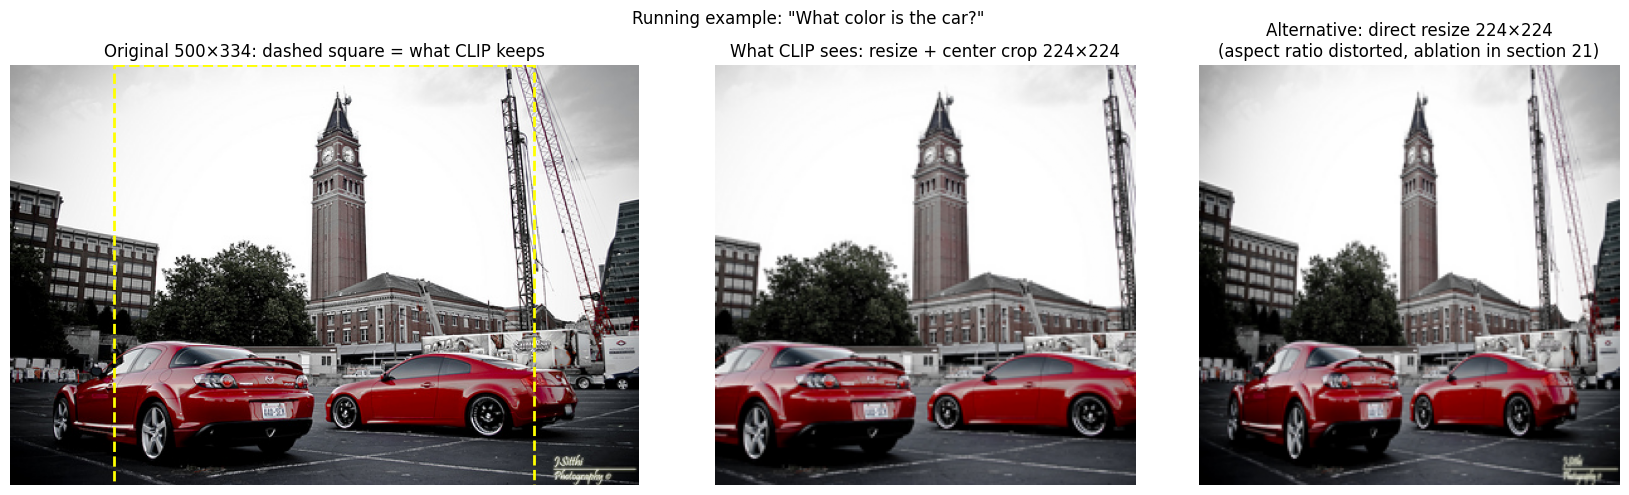

In [76]:
# 5.2 — Original image vs what CLIP sees
# Undo steps 4 and 3 (x·σ + μ), then C×H×W → H×W×C for matplotlib
seen_by_clip = (pixel_values[0] * std + mean).clamp(0, 1).permute(1, 2, 0)
show("seen by CLIP (H×W×C)", seen_by_clip)

# Crop window in ORIGINAL coordinates: the resize multiplied every coordinate by s
s = S / min(w, h)
crop_x, crop_y, crop_side = left / s, top / s, S / s
kept = crop_side ** 2 / (w * h)
print(f"Resize scale s = {s:.4f} → crop window in the original: x = {crop_x:.0f}, y = {crop_y:.0f}, side = {crop_side:.0f} px")
print(f"Share of the original area that CLIP sees: {kept:.1%}  (cut off: {1 - kept:.1%})")

# Alternative without crop (ablation, section 21): whole image, distorted aspect ratio
squashed = example_image.resize((S, S), Image.Resampling.BICUBIC)
print(f"Direct resize instead: width × {S / w:.3f}, height × {S / h:.3f}  (aspect ratio not kept)")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [w / h, 1, 1]})
axes[0].imshow(example_image)
axes[0].add_patch(plt.Rectangle((crop_x, crop_y), crop_side, crop_side, fill=False, ec="yellow", lw=2, ls="--"))
axes[0].set_title(f"Original {w}×{h}: dashed square = what CLIP keeps")
axes[1].imshow(seen_by_clip.numpy())
axes[1].set_title(f"What CLIP sees: resize + center crop {S}×{S}")
axes[2].imshow(squashed)
axes[2].set_title(f"Alternative: direct resize {S}×{S}\n(aspect ratio distorted, ablation in section 21)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f'Running example: "{EXAMPLE["question"]}"')
fig.tight_layout()
fig.savefig(cfg.path("fig", "5_2_crop.png"), dpi=120, bbox_inches="tight")
plt.show()

### 5.3 The patch grid: one patch = one visual token

**Goal**: see the 196 pieces the ViT cuts the image into, and how they are numbered.

$224 / 16 = 14$, so the image is a **14×14 grid of 196 patches**, each made of $16 \times 16 \times 3 = 768$ values. Each patch becomes **one token** of the ViT (section 6), and later one candidate for the selector.

**Numbering (row-major).** Patch $(r, c)$ has index $p = 14\,r + c$: left to right, then top to bottom, like reading a page. This is the order of the ViT tokens after the CLS (position $p + 1$ in the 197-token sequence). It matters in section 11: sorting the selected indices puts the tokens back in this reading order.

**Cutting with `unfold`.** `x.unfold(dim, size, step)` slides a window of length `size` along `dim` with stride `step`. With `size = step = 16`, the windows are non-overlapping blocks. Two unfolds (height, then width):

$$
(3, 224, 224) \xrightarrow{\text{unfold dim 1}} (3, 14, 224, 16) \xrightarrow{\text{unfold dim 2}} (3, 14, 14, 16, 16) \xrightarrow{\text{permute, reshape}} (196, 768)
$$

The `permute` moves the two grid dimensions first, so that row $p$ of the result is patch $p$. Each patch is flattened in (C, 16, 16) order: the same layout as the weight `(768, 3, 16, 16)` of the ViT's patch-embedding `Conv2d`. A convolution with kernel 16 and stride 16 is exactly a linear layer applied to each flattened patch (section 2.2), which we can check on the real CLIP weights in section 6.

⚠️ $768 = 16 \cdot 16 \cdot 3$ equals `cfg.d_vision` = 768 by **coincidence**: it is the hidden size of ViT-B. For ViT-L/14, a patch has $14 \cdot 14 \cdot 3 = 588$ values and the hidden size is 1024.

The figure numbers every patch on the image and zooms on one of them (a patch on the left car, chosen for display only).

unfold → (C, G, G, P, P)     (3, 14, 14, 16, 16) float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407
patches (196×768)            (196, 768)         float32   cpu  min=-1.792 max=+2.146 mean=+0.547 std=1.407

14×14 = 196 patches of 16×16×3 = 768 values each
Zoomed patch: row 11, col 3 → index p = 14·11 + 3 = 157  (position 158 in the 197-token ViT sequence, CLS at position 0)


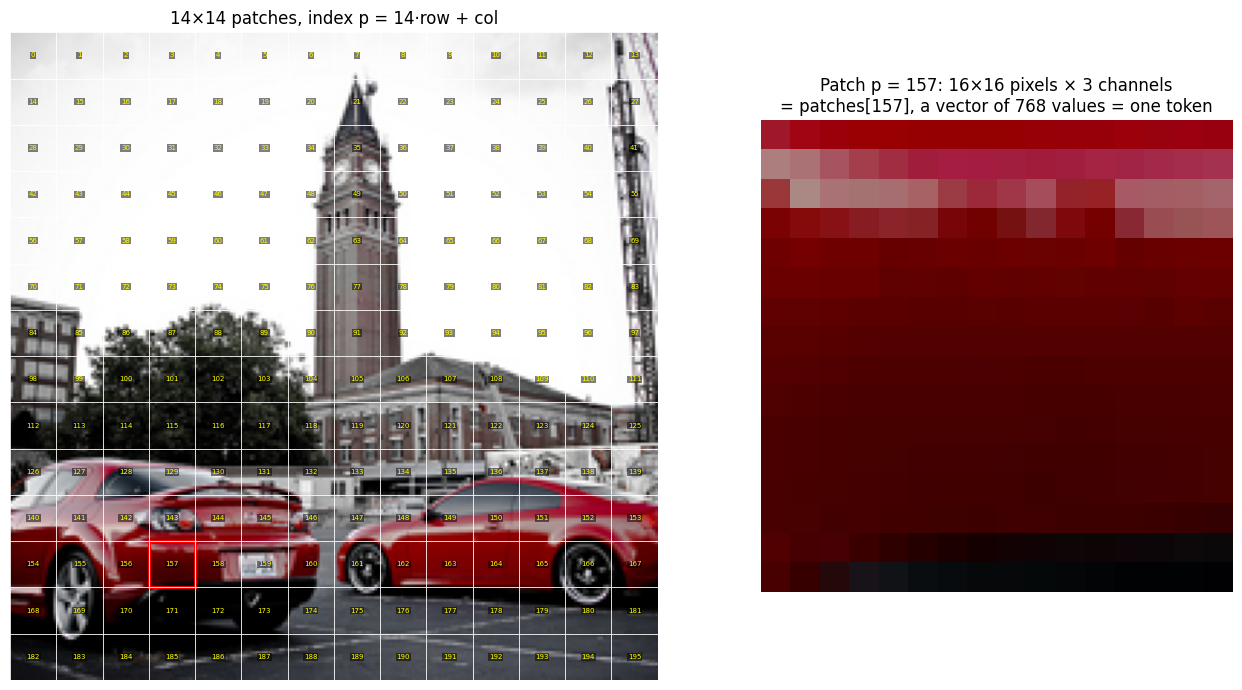

In [77]:
# 5.3 — The 14×14 patch grid: one 16×16 patch = one visual token
P, G = cfg.patch_size, cfg.grid_size
ZOOM_PATCH = (11, 3)    # display only: (row, col) of a patch on the left car of the running example

# (3, 224, 224) → unfold height → (3, 14, 224, 16) → unfold width → (3, 14, 14, 16, 16)
patch_grid = pixel_values[0].unfold(1, P, P).unfold(2, P, P)
show("unfold → (C, G, G, P, P)", patch_grid)
# Grid dims first → (14, 14, 3, 16, 16), then one row per patch: row p = patch (p // G, p % G)
patches = patch_grid.permute(1, 2, 0, 3, 4).reshape(G * G, 3 * P * P)
show("patches (196×768)", patches)
assert patches.shape == (cfg.n_patches, 3 * P * P)

zr, zc = ZOOM_PATCH
zoom_p = G * zr + zc
print(f"\n{G}×{G} = {G * G} patches of {P}×{P}×3 = {3 * P * P} values each")
print(f"Zoomed patch: row {zr}, col {zc} → index p = {G}·{zr} + {zc} = {zoom_p}  "
      f"(position {zoom_p + 1} in the 197-token ViT sequence, CLS at position 0)")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.imshow(seen_by_clip.numpy())
for k in range(G + 1):                                   # patch borders (pixel centers are at integers)
    ax.axhline(k * P - 0.5, color="white", lw=0.6)
    ax.axvline(k * P - 0.5, color="white", lw=0.6)
for idx in range(G * G):
    r, c = divmod(idx, G)
    ax.text(c * P + P / 2 - 0.5, r * P + P / 2 - 0.5, str(idx), ha="center", va="center", fontsize=5, color="yellow",
            bbox=dict(facecolor="black", alpha=0.5, pad=0.5, lw=0))
ax.add_patch(plt.Rectangle((zc * P - 0.5, zr * P - 0.5), P, P, fill=False, ec="red", lw=2))
ax.set_title(f"{G}×{G} patches, index p = {G}·row + col")
ax.axis("off")

# The zoomed patch, rebuilt from ITS ROW of `patches` (denormalized for display)
patch_img = (patches[zoom_p].view(3, P, P) * std + mean).clamp(0, 1).permute(1, 2, 0)
axes[1].imshow(patch_img.numpy(), interpolation="nearest")
axes[1].set_title(f"Patch p = {zoom_p}: {P}×{P} pixels × 3 channels\n= patches[{zoom_p}], a vector of {3 * P * P} values = one token")
axes[1].axis("off")
fig.tight_layout()
fig.savefig(cfg.path("fig", "5_3_patch_grid.png"), dpi=120, bbox_inches="tight")
plt.show()

### 5.4 Section 5 checks

1. **Running-example tensor**: shape 1×3×224×224, `float32`, no NaN / inf, and the manual pipeline gives the same tensor as the processor.
2. **Value range**: before normalization, $x \in [0, 1]$; after, each channel must lie in $[-\mu_c/\sigma_c,\ (1 - \mu_c)/\sigma_c]$. This bound is exact, not a tolerance.
3. **Denormalization** (5.2) gives back the cropped image, and the crop window lies inside the original image.
4. **Patches** (5.3): shape 196×768, patch $p$ is the image block at row $p // 14$, column $p \bmod 14$, and putting the 196 patches back in place gives the image again, **exactly**.
5. **Normalization over many images** (PLAN: "mean close to 0"): per-channel mean and std over the subset images (at most `N_STATS_IMAGES`, drawn with `cfg.seed`).

**Why these tolerances for check 5**: $|\text{mean}| < 0.25$ and $0.75 < \text{std} < 1.25$. They are set to catch the two real bugs, not to measure how well CLIP's statistics fit COCO:

* **normalization forgotten**: values stay in [0, 1], so mean ≈ 0.45 and std ≈ 0.27 → fails;
* **normalization applied twice**: dividing by $\sigma \approx 0.27$ again multiplies the spread by ~3.7 → std ≈ 3.7 → fails.

COCO is not CLIP's training set, so we do not expect exactly 0 and 1.

In [78]:
# 5.4 — Section 5 checks
N_STATS_IMAGES = 500    # check setting, not a hyperparameter: max number of subset images for check 5

checks = {}

# ---- 1. Running-example tensor
checks["pixel_values: shape 1×3×224×224, float32"] = (
    pixel_values.shape == (1, 3, cfg.image_size, cfg.image_size) and pixel_values.dtype == torch.float32)
checks["pixel_values: no NaN / inf"] = torch.isfinite(pixel_values).all().item()
checks["manual pipeline = processor"] = torch.allclose(x, pixel_values[0], atol=1e-5)

# ---- 2. Exact value range: x ∈ [0, 1] before step 4 → x_c ∈ [−μ_c/σ_c, (1 − μ_c)/σ_c] after
lo, hi = (0 - mean) / std, (1 - mean) / std                       # (3, 1, 1), broadcast over H and W
checks["values within [−μ/σ, (1 − μ)/σ] per channel"] = (
    (pixel_values[0] >= lo - 1e-5).all() and (pixel_values[0] <= hi + 1e-5).all()).item()

# ---- 3. Denormalization and crop window (5.2)
cropped_01 = torch.from_numpy(np.array(cropped)).float() / 255    # H×W×C in [0, 1]
checks["denormalized tensor = cropped image (error < 1e-3 on the 0–255 scale)"] = (
    (seen_by_clip - cropped_01).abs().max().item() * 255 < 1e-3)
checks["crop window inside the original image"] = (
    crop_x >= 0 and crop_y >= 0 and crop_x + crop_side <= w + 1e-6 and crop_y + crop_side <= h + 1e-6)

# ---- 4. Patches (5.3)
checks["patches: shape 196×768"] = patches.shape == (cfg.n_patches, 3 * P * P)
checks["patch p = image block (p // 14, p % 14), for every p"] = all(
    torch.equal(patches[p], pixel_values[0, :, (p // G) * P:(p // G + 1) * P, (p % G) * P:(p % G + 1) * P].reshape(-1))
    for p in range(cfg.n_patches))
# Inverse of 5.3: (196, 768) → (14, 14, 3, 16, 16) → (3, 14, 16, 14, 16) → (3, 224, 224)
refolded = patches.view(G, G, 3, P, P).permute(2, 0, 3, 1, 4).reshape(3, G * P, G * P)
checks["patches → image round trip is exact"] = torch.equal(refolded, pixel_values[0])

# ---- 5. Normalization over many images: per-channel mean ≈ 0 and std ≈ 1
image_keys = data_df[["coco_split", "image_id"]].drop_duplicates()
image_keys = image_keys.sample(n=min(N_STATS_IMAGES, len(image_keys)), random_state=cfg.seed)
moments = []
for coco_split, image_id in tqdm(image_keys.itertuples(index=False, name=None), total=len(image_keys),
                                 desc="normalization stats"):
    with Image.open(coco_image_path(coco_split, image_id)) as im:
        xi = image_processor(images=im.convert("RGB"), return_tensors="pt")["pixel_values"][0]
    moments.append(torch.stack([xi.mean(dim=(1, 2)), (xi ** 2).mean(dim=(1, 2))]))   # (2, 3): E[x], E[x²] per channel
# Every image has 224×224 pixels, so averaging the per-image moments gives the exact global moments
ex, ex2 = torch.stack(moments).mean(dim=0)
ch_mean, ch_std = ex, (ex2 - ex ** 2).sqrt()
print(f"Over {len(image_keys)} subset images: mean (R, G, B) = {ch_mean.numpy().round(3)}, "
      f"std (R, G, B) = {ch_std.numpy().round(3)}")
checks["per-channel mean ≈ 0  (|mean| < 0.25)"] = (ch_mean.abs() < 0.25).all().item()
checks["per-channel std ≈ 1  (0.75 < std < 1.25)"] = ((ch_std > 0.75) & (ch_std < 1.25)).all().item()

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 5 check failed: do not move on to section 6."
print("\nSection 5 validated → we can move on to section 6.")

normalization stats:   0%|          | 0/60 [00:00<?, ?it/s]

Over 60 subset images: mean (R, G, B) = [-0.065 -0.066 -0.05 ], std (R, G, B) = [0.984 0.987 0.994]

✅ pixel_values: shape 1×3×224×224, float32
✅ pixel_values: no NaN / inf
✅ manual pipeline = processor
✅ values within [−μ/σ, (1 − μ)/σ] per channel
✅ denormalized tensor = cropped image (error < 1e-3 on the 0–255 scale)
✅ crop window inside the original image
✅ patches: shape 196×768
✅ patch p = image block (p // 14, p % 14), for every p
✅ patches → image round trip is exact
✅ per-channel mean ≈ 0  (|mean| < 0.25)
✅ per-channel std ≈ 1  (0.75 < std < 1.25)

Section 5 validated → we can move on to section 6.


---
# Part III: the encoders

## Section 6. The visual encoder (CLIP ViT-B/16)

**Goal**: turn every image into the visual tokens the selector will choose from, and cache them on disk. CLIP is frozen, so its outputs never change during training: we compute them **once**, instead of running the ViT again at every epoch.

| Subsection | Role |
|---|---|
| 6.1 | Load the vision tower of CLIP, freeze it, switch it to eval mode |
| 6.2 | Inside the embeddings: patch embedding = a linear layer, CLS token, positional embedding |
| 6.3 | Forward with all the hidden states (13 tensors) and attentions; penultimate layer, CLS / 196 patches, last-layer CLS attention |
| 6.4 | Extract the features of the whole subset and store them on disk in fp16 |
| 6.5 | Section checks |

What we cache, per image:

| Tensor | Shape | Used in |
|---|---|---|
| `patches` = V | 196×768 | selector, projector, training (sections 9 – 18) |
| `cls` | 768 | the "CLS always included" ablation (section 21) |
| `cls_attn` | 196 | CLS attention map (section 8), CLS-attention baseline (section 11) |

### 6.1 Loading the frozen vision encoder

**Goal**: load only the **vision tower** of `cfg.clip_name`, freeze it and put it in eval mode.

* **`CLIPVisionModel`, not `CLIPModel`.** The checkpoint holds the image encoder, the text encoder and the two projections into the shared image-text space. Here we only need the image encoder (the text encoder comes in section 7). Loading `CLIPVisionModel` from the full checkpoint simply skips the other weights.
* **`attn_implementation="eager"`.** By default, `transformers` uses PyTorch's fused attention (`sdpa`). It is faster, but it never materializes the 197×197 attention matrix, so `output_attentions=True` silently returns `None` (with only a log warning). We need that matrix for the CLS attention (6.3), so we ask for the plain implementation, which computes $\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$ step by step.
* **Freezing means two different things.** `requires_grad_(False)`: no gradient is computed for the weights (and no memory is spent on it). `eval()`: layers whose *behavior* differs between training and inference (dropout, for instance) switch to inference mode. Neither implies the other, so we do both.
* **Precision.** The weights are loaded directly in `DTYPE` (fp16 on a T4, fp32 on CPU, section 3.4).

The cell checks that the model's configuration matches `cfg` (hidden size, patch size, image size): every shape in the notebook depends on these values.

In [79]:
# 6.1 — Load the CLIP vision tower, frozen, in eval mode
from transformers import CLIPVisionModel

# "eager": the default attention (sdpa) does not return the attention weights needed in 6.3
clip_vision = CLIPVisionModel.from_pretrained(cfg.clip_name, dtype=DTYPE, attn_implementation="eager")
clip_vision = clip_vision.to(DEVICE).eval()
clip_vision.requires_grad_(False)

vcfg = clip_vision.config
print(f"hidden size {vcfg.hidden_size}, patch {vcfg.patch_size}, image {vcfg.image_size}, "
      f"{vcfg.num_hidden_layers} layers, {vcfg.num_attention_heads} heads of dim {vcfg.hidden_size // vcfg.num_attention_heads}")
print(f"attention: {vcfg._attn_implementation}, dtype: {clip_vision.dtype}, device: {clip_vision.device}")
total, trainable = count_params(clip_vision)
print(f"parameters: {total / 1e6:.1f}M, of which trainable: {trainable}")

assert (vcfg.hidden_size, vcfg.patch_size, vcfg.image_size) == (cfg.d_vision, cfg.patch_size, cfg.image_size), \
    "the CLIP config does not match cfg"
assert trainable == 0 and not clip_vision.training
gpu_mem("after loading CLIP")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

hidden size 768, patch 16, image 224, 12 layers, 12 heads of dim 64
attention: eager, dtype: torch.float32, device: cpu
parameters: 85.8M, of which trainable: 0


### 6.2 Inside the embeddings: patches, CLS and positions

**Goal**: rebuild by hand, from the patches of 5.3 and CLIP's real weights, the input of the first Transformer block (section 2.2):

$$
z_0 = \mathrm{LN}_{pre}\big([\,x_{cls};\ x_1 E;\ \dots;\ x_{196} E\,] + E_{pos}\big) \in \mathbb{R}^{197 \times 768}
$$

* **Patch embedding = a linear layer.** CLIP implements $E$ as `Conv2d(3, 768, kernel_size=16, stride=16, bias=False)`, with a weight of shape (768, 3, 16, 16). Since kernel = stride = 16, each output position sees exactly one patch, with no overlap. The convolution is therefore the product of each flattened patch (768 values in (C, 16, 16) order, section 5.3) with the weight reshaped to (768, 768). We check this on the real weights.
* **CLS token.** A single learned vector `class_embedding` (768), the same for every image, placed at position 0. At the input it carries **no** information about the image: it gathers it layer after layer through attention. CLIP is trained on the CLS of the **last** layer only: after `post_layernorm` and a linear projection, it is the image embedding of the contrastive loss.
* **Positional embedding.** A learned table $E_{pos}$ of 197×768 (one row per position, CLS included), **added** to the tokens. Without it, attention is permutation-invariant: shuffling the patches would only shuffle the outputs.
* **`pre_layrnorm`**: a specificity of the OpenAI CLIP ViT, a LayerNorm applied **before** the first block. The 13 hidden states of 6.3 start after it.

All the computation is done by hand in fp32 on CPU, then compared to CLIP's own modules with `rel_err` (relative error $\lVert a - b \rVert / \lVert b \rVert$, independent of the scale of the values). The tolerance `REL_TOL` covers fp16 rounding (relative precision $2^{-11} \approx 5 \cdot 10^{-4}$ per value, a bit more after several layers). A real bug (missing CLS, positions not added, patches in the wrong order) gives an error of order 1.

**Concept: what the positions learned.** Nothing tells the model that patch 14 is just below patch 0: the table is learned freely. The figure shows, for a few patches, the cosine similarity of their position vector with the 196 others, as a 14×14 map. If the model learned the 2D layout, each map is bright around its own patch. The cell also prints the average similarity between neighbouring patches and between distant patches.

patch_embedding.weight       (768, 3, 16, 16)   float32   cpu  min=-0.148 max=+0.144 mean=+0.000 std=0.019
class_embedding              (768,)             float32   cpu  min=-1.554 max=+1.003 mean=+0.003 std=0.234
position_embedding.weight    (197, 768)         float32   cpu  min=-0.220 max=+0.237 mean=-0.007 std=0.028

conv patch embedding         (196, 768)         float32   cpu  min=-6.008 max=+4.883 mean=+0.010 std=0.519
linear patch embedding       (196, 768)         float32   cpu  min=-6.008 max=+4.883 mean=+0.010 std=0.519
z0 by hand (197×768)         (197, 768)         float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
z0 CLIP                      (197, 768)         float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
max |conv − linear| = 5.89e-06
z0 by hand vs CLIP: relative error = 1.76e-06

Mean cosine similarity of position vectors: neighbours (distance 1) = 0.663, distant patches (distance ≥ 7) = 0.330


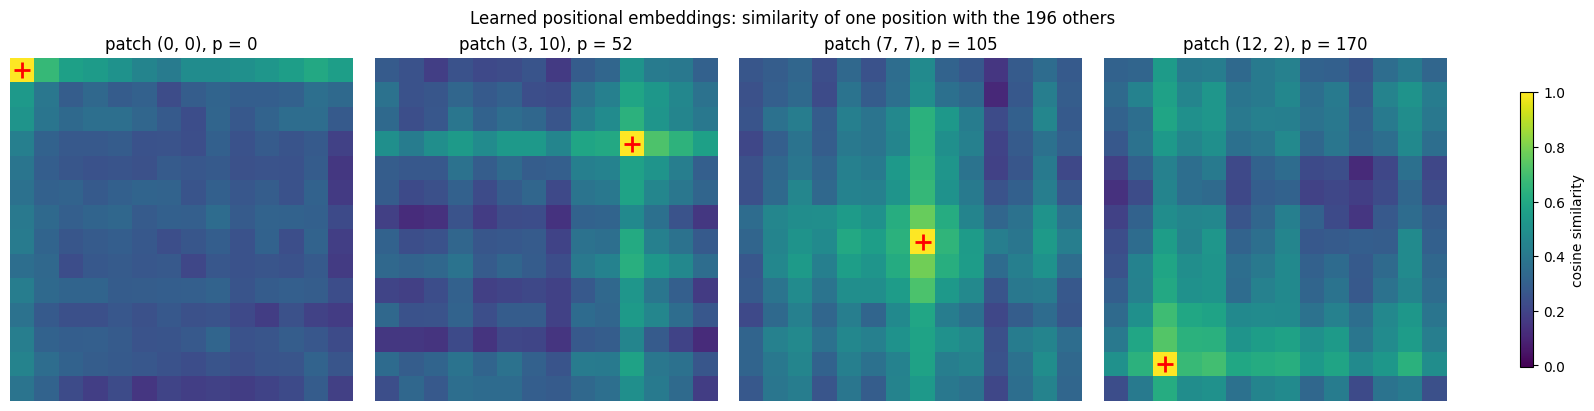

In [80]:
# 6.2 — The embeddings by hand: patch embedding, CLS, positional embedding, pre-LayerNorm
REL_TOL = 1e-2   # check setting: fp16 rounding gives ~1e-3, a real bug gives ~1


def rel_err(a: torch.Tensor, b: torch.Tensor) -> float:
    # ‖a − b‖ / ‖b‖ in fp32 on CPU: a scale-free distance between two tensors
    a, b = a.detach().float().cpu(), b.detach().float().cpu()
    return ((a - b).norm() / b.norm()).item()


vm = clip_vision.vision_model
# fp32 CPU copies of CLIP's weights: the hand computation is done in full precision
W_patch = vm.embeddings.patch_embedding.weight.float().cpu()        # (768, 3, 16, 16)
cls_vec = vm.embeddings.class_embedding.float().cpu()               # (768,)
E_pos = vm.embeddings.position_embedding.weight.float().cpu()       # (197, 768), row 0 = CLS position
show("patch_embedding.weight", W_patch)
show("class_embedding", cls_vec)
show("position_embedding.weight", E_pos)

# 1. Patch embedding the way CLIP computes it: a convolution, kernel = stride = 16
#    (1, 3, 224, 224) → (1, 768, 14, 14) → flatten the grid (row-major, as in 5.3) → (196, 768)
conv_out = F.conv2d(pixel_values, W_patch, stride=cfg.patch_size).flatten(2).transpose(1, 2)[0]
# 2. The same thing as a linear layer on the flattened patches of 5.3: (196, 768) @ (768, 768)ᵀ
linear_out = patches @ W_patch.reshape(cfg.d_vision, -1).T
# 3. CLS in front → (197, 768), positions added, then the pre-LayerNorm
z0 = torch.cat([cls_vec[None], linear_out]) + E_pos
z0 = F.layer_norm(z0, (cfg.d_vision,), vm.pre_layrnorm.weight.float().cpu(), vm.pre_layrnorm.bias.float().cpu(),
                  vm.pre_layrnorm.eps)
# Reference: CLIP's own modules (in DTYPE, on DEVICE)
with torch.no_grad():
    z0_clip = vm.pre_layrnorm(vm.embeddings(pixel_values.to(DEVICE, DTYPE)))[0]

print()
show("conv patch embedding", conv_out)
show("linear patch embedding", linear_out)
show("z0 by hand (197×768)", z0)
show("z0 CLIP", z0_clip)
print(f"max |conv − linear| = {(conv_out - linear_out).abs().max():.2e}")
print(f"z0 by hand vs CLIP: relative error = {rel_err(z0, z0_clip):.2e}")
assert torch.allclose(conv_out, linear_out, atol=1e-4), "the patch embedding is not a linear layer on the patches"
assert rel_err(z0, z0_clip) < REL_TOL, "z0 by hand ≠ CLIP embeddings"

# ---- What the positional embeddings learned
SHOW_POSITIONS = [(0, 0), (3, 10), (7, 7), (12, 2)]   # display only: (row, col) of a few patches
pos = F.normalize(E_pos[1:], dim=-1)                   # (196, 768), CLS position excluded
pos_sim = pos @ pos.T                                  # (196, 196) cosine similarities
rows, cols = torch.arange(cfg.n_patches) // G, torch.arange(cfg.n_patches) % G
grid_dist = (rows[:, None] - rows[None]).abs() + (cols[:, None] - cols[None]).abs()   # (196, 196) Manhattan distance
print(f"\nMean cosine similarity of position vectors: neighbours (distance 1) = {pos_sim[grid_dist == 1].mean():.3f}, "
      f"distant patches (distance ≥ {G // 2}) = {pos_sim[grid_dist >= G // 2].mean():.3f}")

fig, axes = plt.subplots(1, len(SHOW_POSITIONS), figsize=(4 * len(SHOW_POSITIONS), 4), layout="constrained")
for ax, (r, c) in zip(axes, SHOW_POSITIONS):
    im = ax.imshow(pos_sim[G * r + c].view(G, G), cmap="viridis", vmin=pos_sim.min(), vmax=1)
    ax.plot(c, r, "r+", ms=12, mew=2)
    ax.set_title(f"patch ({r}, {c}), p = {G * r + c}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="cosine similarity")
fig.suptitle("Learned positional embeddings: similarity of one position with the 196 others")
fig.savefig(cfg.path("fig", "6_2_positional_embeddings.png"), dpi=120, bbox_inches="tight")
plt.show()

### 6.3 The forward pass: 13 hidden states, penultimate layer, CLS attention

**Goal**: run the ViT on the running example, keep every intermediate output, and extract the three tensors we cache.

With `output_hidden_states=True`, the model returns **13** tensors of shape (B, 197, 768): $z_0$ (the input of the first block, rebuilt in 6.2), then the output of each of the 12 blocks. With `output_attentions=True`, it also returns the **12** attention matrices, of shape (B, heads, 197, 197), after the softmax over the keys (last axis).

**What we keep:**

* `hidden_states[cfg.vision_feature_layer]` = `hidden_states[-2]`, the output of block 11. Position 0 is the CLS, positions 1 to 196 are the patches in the row-major order of 5.3 → `cls` (768) and `patches` V (196×768).
* `attentions[-1][:, :, 0, 1:]`: in the **last** block, the attention row of the CLS (query 0) over the 196 patches (keys 1 to 196), averaged over the 12 heads → `cls_attn` (196).

**Concept: why the penultimate layer.** CLIP's contrastive loss only uses the CLS output of the last block. Follow the gradient backwards:

* in the last block, the 196 patch **outputs** are not used by anything: no gradient ever reaches them. They are computed with the same weights as the CLS, but nothing in training constrains what they contain;
* the output of block 11 is the input of block 12, from which the CLS computes its keys and values: it is directly shaped by the loss.

The penultimate layer is therefore the last one whose patch tokens are trained to be useful. LLaVA makes the same choice (`vision_feature_layer = -2`). The layer used is an ablation of section 21.

The cell prints, for each of the 13 hidden states, the mean and maximum norm of the patch tokens and the mean cosine similarity between two different patches. If the patch outputs of the last block are unconstrained, nothing prevents them from becoming similar to one another, i.e. less specific to their location: compare the last two rows. This is one image, a description rather than a proof. Section 8 analyses the tokens further (including the few tokens with a very large norm, if there are some).

**Why the attention of the last layer.** It is exactly how the CLS, the vector CLIP is trained on, weighs the penultimate tokens we keep: the query is the CLS of block 12, the keys are computed from the 196 tokens of `hidden_states[-2]`. It is a score for **our** tokens that ignores the question: the "CLS attention" baseline of section 11. Each softmax row sums to 1 over the 197 keys; since we drop the CLS → CLS entry, our 196 values sum to slightly less than 1 (the cell prints how much).

**Pitfall: `pooler_output` is not `hidden_states[-1][:, 0]`.** `pooler_output` is the last CLS **after** `post_layernorm`. We use neither of them.

`encode_images` wraps these few lines because they are reused: for the extraction (6.4), the live check (6.5), and later the forward pass from pixels (sections 16 and 20).

In [81]:
# 6.3 — Forward with all hidden states and attentions; penultimate layer, CLS / patches, CLS attention

@torch.no_grad()
def encode_images(pixel_values: torch.Tensor) -> dict:
    # (B, 3, 224, 224) → patches (B, 196, 768) and cls (B, 768) of layer cfg.vision_feature_layer,
    #                   cls_attn (B, 196): last-layer attention of the CLS over the patches, mean over heads
    out = clip_vision(pixel_values=pixel_values.to(DEVICE, DTYPE), output_hidden_states=True, output_attentions=True)
    h = out.hidden_states[cfg.vision_feature_layer]           # (B, 197, 768)
    attn = out.attentions[-1]                                 # (B, heads, 197 queries, 197 keys)
    return {
        "patches": h[:, 1:],                                  # (B, 196, 768): positions 1..196, row-major
        "cls": h[:, 0],                                       # (B, 768)
        "cls_attn": attn[:, :, 0, 1:].mean(dim=1),            # query 0 (CLS), keys 1..196 (patches) → (B, 196)
    }


# ---- 1. Everything the ViT computes, on the running example
with torch.no_grad():
    vit_out = clip_vision(pixel_values=pixel_values.to(DEVICE, DTYPE), output_hidden_states=True, output_attentions=True)
print(f"{len(vit_out.hidden_states)} hidden states, {len(vit_out.attentions)} attention matrices")
show("hidden_states[0] = z0", vit_out.hidden_states[0])
show(f"hidden_states[{cfg.vision_feature_layer}]", vit_out.hidden_states[cfg.vision_feature_layer])
show("hidden_states[-1]", vit_out.hidden_states[-1])
show("attentions[-1]", vit_out.attentions[-1])
print(f"hidden_states[0] vs z0 by hand (6.2): relative error = {rel_err(vit_out.hidden_states[0][0], z0):.2e}")
print(f"pooler_output vs hidden_states[-1][:, 0]: relative error = "
      f"{rel_err(vit_out.pooler_output, vit_out.hidden_states[-1][:, 0]):.2e}  (not the same tensor: post_layernorm)")
assert len(vit_out.hidden_states) == vcfg.num_hidden_layers + 1 and len(vit_out.attentions) == vcfg.num_hidden_layers
assert rel_err(vit_out.hidden_states[0][0], z0) < REL_TOL

# ---- 2. How the patch tokens change with depth (one image: a description, not a proof)
n_layers = len(vit_out.hidden_states)
kept_layer = cfg.vision_feature_layer % n_layers                  # -2 → 11
print(f"\n{'layer':>5}  {'patch norm: mean':>16}  {'max':>7}  {'mean cos(patch i, patch j), i ≠ j':>34}")
for layer, h in enumerate(vit_out.hidden_states):
    p = h[0, 1:].float()                                          # (196, 768)
    pn = F.normalize(p, dim=-1)
    # Mean over the 196·195 pairs i ≠ j: sum of the similarity matrix minus its diagonal of ones
    mean_cos = ((pn @ pn.T).sum() - cfg.n_patches) / (cfg.n_patches * (cfg.n_patches - 1))
    norms = p.norm(dim=-1)
    tag = "   ← kept" if layer == kept_layer else ""
    print(f"{layer:>5}  {norms.mean():>16.2f}  {norms.max():>7.2f}  {mean_cos:>34.3f}{tag}")

# ---- 3. The three tensors we cache, for the running example
example_feats = encode_images(pixel_values)
print()
show("CLIP ViT output (197×768)", vit_out.hidden_states[cfg.vision_feature_layer][0])
show("V = patches (196×768)", example_feats["patches"][0])
show("cls (768)", example_feats["cls"][0])
show("cls_attn (196)", example_feats["cls_attn"][0])
assert example_feats["patches"].shape == (1, cfg.n_patches, cfg.d_vision)
assert example_feats["cls"].shape == (1, cfg.d_vision) and example_feats["cls_attn"].shape == (1, cfg.n_patches)

cls_self = vit_out.attentions[-1][0, :, 0, 0].float().mean()
print(f"\ncls_attn sums to {example_feats['cls_attn'].float().sum():.3f} over the 196 patches "
      f"(CLS → CLS, mean over heads: {cls_self:.3f})")
top = example_feats["cls_attn"][0].float().topk(5)
print("Patches the CLS attends to most, p (row, col): weight →",
      ", ".join(f"{p} ({p // G}, {p % G}): {a:.3f}" for a, p in zip(top.values.tolist(), top.indices.tolist())))

13 hidden states, 12 attention matrices
hidden_states[0] = z0        (1, 197, 768)      float32   cpu  min=-5.823 max=+2.260 mean=+0.007 std=0.169
hidden_states[-2]            (1, 197, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.710
hidden_states[-1]            (1, 197, 768)      float32   cpu  min=-17.969 max=+80.953 mean=-0.022 std=0.788
attentions[-1]               (1, 12, 197, 197)  float32   cpu  min=+0.000 max=+0.325 mean=+0.005 std=0.006
hidden_states[0] vs z0 by hand (6.2): relative error = 1.76e-06
pooler_output vs hidden_states[-1][:, 0]: relative error = 2.88e+00  (not the same tensor: post_layernorm)

layer  patch norm: mean      max   mean cos(patch i, patch j), i ≠ j
    0              4.65     6.93                               0.239
    1              3.45     4.37                               0.294
    2              4.10     4.75                               0.281
    3              3.60     4.53                               0.160
    4      

### 6.4 Extracting and caching the features of the subset

**Goal**: run `encode_images` once on every image of the subset, and store the result on persistent storage.

**One row per image, not per question.** An image has ~5 questions (4.4) and its visual tokens do not depend on the question. Each image is stored once, with its `image_id`; later sections find the features of a question through its `image_id`.

**fp16 storage.** For one image, V takes $196 \times 768 \times 2$ bytes $= 301{,}056$ bytes ≈ 301 KB (1 KB = 1,000 bytes), half of what fp32 would take. `cls` and `cls_attn` add $(768 + 196) \times 2$ bytes. fp16 keeps about 3 significant digits. That is enough: downstream, the models run in fp16 or bf16 (section 3.4), which are not more precise. The cell prints the size this gives in full mode.

**One file per split**, `clip_layer-2_<split>.pt`, in `cfg.cache_dir` (which depends on the run, so DEBUG and full mode never mix). The layer is in the file name: the layer ablation (section 21) will write new files instead of overwriting these ones.

| Key | Shape | dtype |
|---|---|---|
| `image_ids` | N | int64 |
| `patches` | N×196×768 | float16 |
| `cls` | N×768 | float16 |
| `cls_attn` | N×196 | float16 |

Rows are in increasing `image_id` order, so the file does not depend on the row order of `data_df`.

**Memory.** The output tensors are allocated once (`torch.empty`), then filled batch by batch. Accumulating the batches in a list and calling `torch.cat` at the end would hold two copies at the peak: about 6 GB instead of 3 for the full-mode train split.

**Resume.** One `load_or_compute` per split: after a disconnection, the splits already saved are reloaded, and only the interrupted one is recomputed.

`EXTRACT_BATCH_SIZE` is a runtime setting (speed and memory), not a hyperparameter: it changes the features only through floating-point rounding, which 6.5 checks.

In [82]:
# 6.4 — Extract the CLIP features of the whole subset, cache them in fp16
EXTRACT_BATCH_SIZE = 64          # runtime setting, not a hyperparameter: speed / memory only (checked in 6.5)
SPLITS = list(SPLIT_SOURCE)      # ["train", "dev", "test"]
CACHED_KEYS = ("patches", "cls", "cls_attn")


def clip_cache_path(split: str) -> Path:
    return cfg.path("cache", f"clip_layer{cfg.vision_feature_layer}_{split}.pt")


def extract_split(split: str) -> dict:
    # Encodes each image of `split` once. Rows in increasing image_id order.
    keys = (data_df.loc[data_df["split"] == split, ["coco_split", "image_id"]]
            .drop_duplicates().sort_values("image_id"))
    keys = list(keys.itertuples(index=False, name=None))
    n = len(keys)
    # Allocated once, then filled batch by batch: no second copy at the peak
    feats = {
        "image_ids": torch.tensor([image_id for _, image_id in keys]),
        "patches": torch.empty(n, cfg.n_patches, cfg.d_vision, dtype=torch.float16),
        "cls": torch.empty(n, cfg.d_vision, dtype=torch.float16),
        "cls_attn": torch.empty(n, cfg.n_patches, dtype=torch.float16),
    }
    for start in tqdm(range(0, n, EXTRACT_BATCH_SIZE), desc=f"CLIP {split}"):
        batch = keys[start:start + EXTRACT_BATCH_SIZE]
        images = []
        for coco_split, image_id in batch:
            with Image.open(coco_image_path(coco_split, image_id)) as im:
                images.append(im.convert("RGB"))
        out = encode_images(image_processor(images=images, return_tensors="pt")["pixel_values"])
        for k in CACHED_KEYS:
            feats[k][start:start + len(batch)] = out[k].cpu()     # copy into the fp16 tensor (cast if needed)
    return feats


clip_feats = {}
for split in SPLITS:
    clip_feats[split] = load_or_compute(clip_cache_path(split), lambda: extract_split(split))

# ---- What is on disk
print()
for split, f in clip_feats.items():
    size = clip_cache_path(split).stat().st_size
    print(f"{split:<6} {len(f['image_ids']):>6} images   {size / 1e6:8.1f} MB   {size / len(f['image_ids']) / 1e3:6.1f} KB / image")
for k in ("image_ids", *CACHED_KEYS):
    show(f"train {k}", clip_feats["train"][k])

# Expected size in full mode, from the config (not a measurement)
bytes_per_image = (cfg.n_patches * cfg.d_vision + cfg.d_vision + cfg.n_patches) * 2
full = Config(debug=False)
n_full = full.n_train_images + full.n_dev_images + full.n_test_images
print(f"\nExpected in full mode: {n_full} images × {bytes_per_image / 1e3:.1f} KB = {n_full * bytes_per_image / 1e9:.2f} GB "
      f"(train split alone: {full.n_train_images * bytes_per_image / 1e9:.2f} GB in RAM)")
gpu_mem("after extraction")

↩️  Reloaded: clip_layer-2_train.pt
↩️  Reloaded: clip_layer-2_dev.pt
↩️  Reloaded: clip_layer-2_test.pt

train      40 images       12.1 MB    303.1 KB / image
dev        10 images        3.0 MB    303.2 KB / image
test       10 images        3.0 MB    303.2 KB / image
train image_ids              (40,)              int64     cpu
train patches                (40, 196, 768)     float16   cpu  min=-18.344 max=+93.000 mean=-0.007 std=0.672
train cls                    (40, 768)          float16   cpu  min=-4.949 max=+7.578 mean=-0.020 std=0.342
train cls_attn               (40, 196)          float16   cpu  min=+0.000 max=+0.171 mean=+0.004 std=0.013

Expected in full mode: 13000 images × 303.0 KB = 3.94 GB (train split alone: 3.03 GB in RAM)


### 6.5 Section 6 checks

1. **Model**: frozen (0 trainable parameters), in eval mode, `eager` attention, configuration consistent with `cfg`.
2. **Embeddings** (6.2): the patch embedding is a linear layer on the patches of 5.3; $z_0$ built by hand = `hidden_states[0]`.
3. **Shapes** (PLAN): V is 196×768 and the CLS is 768, for the running example and in every cache file; `cls_attn` is 196.
4. **Cache content**: fp16, no NaN / inf; each split contains exactly the images of `data_df`, once each; `cls_attn` ≥ 0 with a sum ≤ 1 per image (a softmax row minus its CLS → CLS entry).
5. **Cache = live computation** on `N_LIVE_CHECK` = 5 images drawn with `cfg.seed` across the splits: relative error < `REL_TOL` for V, CLS and `cls_attn`. The live batch differs from the extraction batch, and the cache went through fp16, hence a tolerance instead of exact equality. **Negative control**: the same comparison against the features of *another* image must exceed `REL_TOL`. Otherwise, the test would be too loose to detect a row-order bug.
6. **Disk size**: bytes per image on disk within 1% of $(196 \times 768 + 768 + 196) \times 2 + 8$ (the 8 bytes are the `image_id`), i.e. ~301 KB for V as planned. The 1% covers the file-format overhead. Saving fp32, or a *view* of a larger tensor (`torch.save` writes the whole underlying storage), would fail.

In [83]:
# 6.5 — Section 6 checks
N_LIVE_CHECK = 5   # check setting: number of images recomputed live (PLAN: 5)
checks = {}

# ---- 1. Model
checks["CLIP frozen: 0 trainable parameters"] = count_params(clip_vision)[1] == 0
checks["CLIP in eval mode"] = not clip_vision.training
checks["eager attention: attention weights returned"] = (
    vcfg._attn_implementation == "eager" and vit_out.attentions is not None)
checks["CLIP config matches cfg"] = (
    (vcfg.hidden_size, vcfg.patch_size, vcfg.image_size) == (cfg.d_vision, cfg.patch_size, cfg.image_size))

# ---- 2. Embeddings
checks["patch embedding = linear layer on the patches"] = torch.allclose(conv_out, linear_out, atol=1e-4)
checks["z0 by hand = hidden_states[0]"] = rel_err(z0, vit_out.hidden_states[0][0]) < REL_TOL

# ---- 3. Shapes
checks["running example: V 196×768, CLS 768, cls_attn 196"] = (
    example_feats["patches"].shape[1:] == (cfg.n_patches, cfg.d_vision)
    and example_feats["cls"].shape[1:] == (cfg.d_vision,) and example_feats["cls_attn"].shape[1:] == (cfg.n_patches,))
checks["cache: V N×196×768, CLS N×768, cls_attn N×196, same N"] = all(
    f["patches"].shape[1:] == (cfg.n_patches, cfg.d_vision) and f["cls"].shape[1:] == (cfg.d_vision,)
    and f["cls_attn"].shape[1:] == (cfg.n_patches,)
    and len({len(f[k]) for k in ("image_ids", *CACHED_KEYS)}) == 1
    for f in clip_feats.values())

# ---- 4. Cache content
checks["cache in fp16"] = all(f[k].dtype == torch.float16 for f in clip_feats.values() for k in CACHED_KEYS)
checks["cache: no NaN / inf"] = all(torch.isfinite(f[k]).all().item() for f in clip_feats.values() for k in CACHED_KEYS)
checks["each split = exactly its data_df images, once each"] = all(
    f["image_ids"].tolist() == sorted(data_df.loc[data_df["split"] == s, "image_id"].unique().tolist())
    for s, f in clip_feats.items())
attn_sums = torch.cat([f["cls_attn"].float().sum(dim=1) for f in clip_feats.values()])
print(f"cls_attn sum per image: min = {attn_sums.min():.3f}, mean = {attn_sums.mean():.3f}, max = {attn_sums.max():.3f}")
checks["cls_attn ≥ 0 and sum ≤ 1 per image"] = (
    all((f["cls_attn"] >= 0).all().item() for f in clip_feats.values()) and (attn_sums <= 1 + 1e-3).all().item())

# ---- 5. Cache = live computation, on N_LIVE_CHECK images drawn across the splits
rng = np.random.default_rng(cfg.seed)
all_rows = [(s, r) for s in SPLITS for r in range(len(clip_feats[s]["image_ids"]))]
picks = [all_rows[j] for j in rng.choice(len(all_rows), size=N_LIVE_CHECK, replace=False)]
images = []
for s, r in picks:
    with Image.open(coco_image_path(SPLIT_SOURCE[s], int(clip_feats[s]["image_ids"][r]))) as im:
        images.append(im.convert("RGB"))
live = encode_images(image_processor(images=images, return_tensors="pt")["pixel_values"])
print(f"\nLive check on {N_LIVE_CHECK} images: {picks}")
for k in CACHED_KEYS:
    cached = torch.stack([clip_feats[s][k][r] for s, r in picks])          # (5, ...) fp16
    err = rel_err(cached, live[k])
    wrong = rel_err(cached.roll(1, dims=0), live[k])                       # each image vs another image's features
    print(f"   {k:<9} relative error: cache vs live = {err:.2e}   control (wrong image) = {wrong:.2e}")
    checks[f"cache = live on {N_LIVE_CHECK} images: {k}"] = err < REL_TOL
    checks[f"negative control detected: {k}"] = wrong > REL_TOL

# ---- 6. Disk size
expected = bytes_per_image + 8                                              # + the int64 image_id
print(f"\nExpected per image: {expected / 1e3:.1f} KB (V alone: {cfg.n_patches * cfg.d_vision * 2 / 1e3:.1f} KB)")
for s, f in clip_feats.items():
    per_image = clip_cache_path(s).stat().st_size / len(f["image_ids"])
    print(f"   {s:<6} {per_image / 1e3:.1f} KB per image on disk")
    checks[f"disk size per image within 1% of expected: {s}"] = abs(per_image / expected - 1) < 0.01

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 6 check failed: do not move on to section 7."
print("\nSection 6 validated → we can move on to section 7.")

cls_attn sum per image: min = 0.699, mean = 0.787, max = 0.831

Live check on 5 images: [('dev', 4), ('train', 25), ('train', 37), ('train', 4), ('test', 9)]
   patches   relative error: cache vs live = 2.12e-04   control (wrong image) = 1.30e+00
   cls       relative error: cache vs live = 2.26e-04   control (wrong image) = 6.90e-01
   cls_attn  relative error: cache vs live = 2.03e-04   control (wrong image) = 1.29e+00

Expected per image: 303.0 KB (V alone: 301.1 KB)
   train  303.1 KB per image on disk
   dev    303.2 KB per image on disk
   test   303.2 KB per image on disk

✅ CLIP frozen: 0 trainable parameters
✅ CLIP in eval mode
✅ eager attention: attention weights returned
✅ CLIP config matches cfg
✅ patch embedding = linear layer on the patches
✅ z0 by hand = hidden_states[0]
✅ running example: V 196×768, CLS 768, cls_attn 196
✅ cache: V N×196×768, CLS N×768, cls_attn N×196, same N
✅ cache in fp16
✅ cache: no NaN / inf
✅ each split = exactly its data_df images, once each
✅ cl

## Section 7. The question encoder

**Goal**: represent the question in the two forms the selector needs.

| Form | Shape | What it is | Used by |
|---|---|---|---|
| Q | M×512 | one contextual vector per token | scorers A and B: the words of the question "look at" the patches (sections 9 – 10) |
| q̄ | 512 | one vector for the whole question | scorer C: cosine similarity with each patch (section 9); per-question decisions such as the budget (section 13) |

M is the length of the longest question of the batch (dynamic padding), at most `cfg.max_question_len`.

The encoder is the **CLIP text encoder**, frozen. It was trained jointly with the image encoder of section 6, on image-caption pairs. We also run **DistilBERT** (768), the encoder of the section 21 ablation, to see what it would change.

| Subsection | Role |
|---|---|
| 7.1 | Load the CLIP tokenizer and text encoder, freeze it |
| 7.2 | Tokenize a batch: padding and attention mask; exact question lengths in CLIP tokens |
| 7.3 | Extract Q and q̄; the causal mask of the CLIP text encoder |
| 7.4 | The same with DistilBERT: bidirectional attention, mean pooling |
| 7.5 | Section checks |

**No cache in this section.** Section 6 cached the ViT because it is the most expensive frozen part: 197 tokens per image. The text encoder runs on a short sequence (7.2 measures its length), so we compute it on the fly with `encode_questions`, which also keeps dynamic padding. 7.3 measures its time on the subset. If it shows up in the training profile (section 18), we will cache it the same way as the images.

### 7.1 Loading the frozen CLIP text encoder

**Goal**: load the tokenizer and the **text tower** of the same checkpoint as section 6 (`cfg.clip_name`), frozen, in eval mode.

* `CLIPTextModel` loads only the text encoder from the full checkpoint, as `CLIPVisionModel` did for the images. Its hidden size is 512 (`cfg.d_text`), not 768: the two towers are different Transformers, which only meet after their projections into the shared space (section 8).
* We keep the default attention implementation (`sdpa`): unlike in section 6, we do not need the attention weights.
* The tokenizer is a byte-level BPE that **lower-cases** the text. It has three special tokens: `<|startoftext|>` (BOS), `<|endoftext|>` (EOS) and the padding token, which here is **the same token as EOS** (same id). The consequence is in 7.2.
* The context has 77 positions (a learned positional embedding, as in the ViT), so `cfg.max_question_len` must not exceed it.

In [84]:
# 7.1 — Load the CLIP tokenizer and text encoder, frozen, in eval mode
from transformers import AutoTokenizer, CLIPTextModel

clip_tokenizer = AutoTokenizer.from_pretrained(cfg.clip_name)
clip_text = CLIPTextModel.from_pretrained(cfg.clip_name, dtype=DTYPE).to(DEVICE).eval()
clip_text.requires_grad_(False)

tcfg = clip_text.config
print(f"tokenizer: {type(clip_tokenizer).__name__}, vocabulary {clip_tokenizer.vocab_size}, "
      f"padding side: {clip_tokenizer.padding_side}")
for role in ("bos", "eos", "pad"):
    print(f"   {role}: {getattr(clip_tokenizer, f'{role}_token')!r}  (id {getattr(clip_tokenizer, f'{role}_token_id')})")
print(f"lower-casing: {clip_tokenizer('What COLOR')['input_ids'] == clip_tokenizer('what color')['input_ids']}")
print(f"text encoder: hidden size {tcfg.hidden_size}, {tcfg.num_hidden_layers} layers, {tcfg.num_attention_heads} heads, "
      f"context {tcfg.max_position_embeddings} positions, attention: {tcfg._attn_implementation}")
total, trainable = count_params(clip_text)
print(f"parameters: {total / 1e6:.1f}M, of which trainable: {trainable}")

assert tcfg.hidden_size == cfg.d_text, "CLIP text hidden size ≠ cfg.d_text"
assert cfg.max_question_len <= tcfg.max_position_embeddings, "cfg.max_question_len exceeds the CLIP context"
assert clip_tokenizer.padding_side == "right"     # 7.3 finds the EOS as the last real token
assert trainable == 0 and not clip_text.training
gpu_mem("after loading the CLIP text encoder")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

tokenizer: CLIPTokenizer, vocabulary 49408, padding side: right
   bos: '<|startoftext|>'  (id 49406)
   eos: '<|endoftext|>'  (id 49407)
   pad: '<|endoftext|>'  (id 49407)
lower-casing: True
text encoder: hidden size 512, 12 layers, 8 heads, context 77 positions, attention: sdpa
parameters: 63.2M, of which trainable: 0


### 7.2 Tokenization: padding and attention mask

**Goal**: see what the encoder actually receives for a batch of questions.

A batch is a rectangular tensor, but questions have different lengths. With `padding=True`, the tokenizer **pads** each question on the right up to the length M of the longest question **of the batch** (dynamic padding), and returns:

* `input_ids` (B, M): BOS, the question tokens, EOS, then padding;
* `attention_mask` (B, M): 1 on the real tokens (BOS and EOS included), 0 on the padding.

`truncation=True, max_length=cfg.max_question_len` cuts questions that are too long. The tokenizer then keeps BOS and EOS and drops the end of the question.

**Pitfall: padding = EOS.** For CLIP, the padding id is the EOS id, so `input_ids == eos_token_id` also finds the padding. Only the attention mask tells them apart. With right padding, the EOS is the last real token, at position `attention_mask.sum(1) - 1`.

The batch is the 5 questions asked about the running-example image (4.5b), which have different lengths. Then, as announced in 4.3, the cell measures the **exact** length in CLIP tokens of all the train2014 questions and compares it with `cfg.max_question_len`. 4.3 only had a lower bound (words + 2).

In [85]:
# 7.2 — Tokenization: padding and attention mask
batch_questions = same_image["question"].tolist()       # the questions on the running-example image (4.5b)
q_tok = clip_tokenizer(batch_questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                       return_tensors="pt")
show("input_ids (B×M)", q_tok["input_ids"])
show("attention_mask (B×M)", q_tok["attention_mask"])

# One row per question: its tokens, with the padding shown as "·"
print()
for q, ids, m in zip(batch_questions, q_tok["input_ids"], q_tok["attention_mask"]):
    tokens = [t if keep else "·" for t, keep in zip(clip_tokenizer.convert_ids_to_tokens(ids), m.tolist())]
    print(f"{q!r:<45} {int(m.sum()):>2} real tokens: {' '.join(tokens)}")

eos_pos = q_tok["attention_mask"].sum(dim=1) - 1                  # last real token (right padding)
print(f"\nEOS position = attention_mask.sum(1) - 1: {eos_pos.tolist()}")
print("Positions where input_ids == EOS id:",
      [torch.nonzero(row == clip_tokenizer.eos_token_id).flatten().tolist() for row in q_tok["input_ids"]],
      " ← the padding is found too")

# ---- Exact lengths in CLIP tokens, all train2014 questions (announced in 4.3)
train_questions = vqa_df.loc[vqa_df["coco_split"] == "train2014", "question"].tolist()
q_len_clip = np.array([len(ids) for ids in clip_tokenizer(train_questions)["input_ids"]])    # BOS and EOS included
print(f"\ntrain2014, {len(q_len_clip)} questions, length in CLIP tokens (BOS and EOS included): "
      f"median = {np.median(q_len_clip):.0f}, p99 = {np.quantile(q_len_clip, 0.99):.0f}, max = {q_len_clip.max()}")
print(f"Truncated at cfg.max_question_len = {cfg.max_question_len}: {(q_len_clip > cfg.max_question_len).sum()} questions "
      f"({(q_len_clip > cfg.max_question_len).mean():.3%})")

input_ids (B×M)              (5, 11)            int64     cpu
attention_mask (B×M)         (5, 11)            int64     cpu

'How many cars are in this picture?'          10 real tokens: <|startoftext|> how</w> many</w> cars</w> are</w> in</w> this</w> picture</w> ?</w> <|endoftext|> ·
'What color are the cars in this picture?'    11 real tokens: <|startoftext|> what</w> color</w> are</w> the</w> cars</w> in</w> this</w> picture</w> ?</w> <|endoftext|>
'What make are the cars?'                      8 real tokens: <|startoftext|> what</w> make</w> are</w> the</w> cars</w> ?</w> <|endoftext|> · · ·
'What is in the background?'                   8 real tokens: <|startoftext|> what</w> is</w> in</w> the</w> background</w> ?</w> <|endoftext|> · · ·
'What color is the car?'                       8 real tokens: <|startoftext|> what</w> color</w> is</w> the</w> car</w> ?</w> <|endoftext|> · · ·

EOS position = attention_mask.sum(1) - 1: [9, 10, 7, 7, 7]
Positions where input_ids == EOS id: [[9

### 7.3 The sequence Q and the vector q̄; the causal mask

**Goal**: run the encoder and get Q (B, M, 512) and q̄ (B, 512).

* **Q** = `last_hidden_state`: the output of the last block, after the final LayerNorm, with one vector per token. These are **contextual** embeddings: the vector of "car" in "What color is the car?" depends on the other words, unlike a simple word-embedding lookup.
* **q̄** = `pooler_output`: the vector of Q at the **EOS** position. This is CLIP's own summary of the text: after a linear projection (`text_projection`, section 8), it is the text embedding of the contrastive loss.

**Concept: the CLIP text encoder is causal.** Unlike the ViT, its self-attention uses a **causal mask**, as in GPT: token $t$ only attends to tokens $0$ to $t$. The CLIP authors made this choice so that the encoder could be initialized from a language model. It has three consequences, all checked by the cell:

1. **Only the EOS sees the whole question.** That is why it is the summary vector, and why we do not average the tokens: the first ones have only seen the beginning of the question.
2. **A prefix gives the same outputs.** The vectors of "what color is the" are exactly the same whether the question stops there or goes on with "car?". In Q, the word "what" knows nothing about the rest of the question; only the later tokens are informed.
3. **Right padding is invisible.** Real tokens never look to their right, so they never see the padding, even without an attention mask. A side effect: BOS only sees itself, so its output is the **same vector for every question** and carries no information. We keep it in Q; the selector can learn to ignore it.

`encode_questions` wraps tokenization and forward because it is reused: for the checks (7.5), then on every training batch (section 18). It returns the mask along with Q. Any later operation on Q (attention over the words, pooling) must exclude the padding positions, whose vectors are **not** zero.

Finally, the cell times the encoding of all the questions of the subset.

In [86]:
# 7.3 — The sequence Q and the vector q̄ (CLIP text encoder)

@torch.no_grad()
def encode_questions(questions: list) -> dict:
    # B strings → Q (B, M, 512), mask (B, M) bool, q_bar (B, 512); M = longest question of the batch
    tok = clip_tokenizer(questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                         return_tensors="pt").to(DEVICE)
    out = clip_text(**tok)
    return {
        "Q": out.last_hidden_state,               # (B, M, 512); padding positions are NOT zero: use the mask
        "mask": tok["attention_mask"].bool(),     # (B, M), True = real token
        "q_bar": out.pooler_output,               # (B, 512) = Q at the EOS position
    }


# ---- 1. Running example
example_q = encode_questions([EXAMPLE["question"]])
show("Q (1×M×512)", example_q["Q"])
show("mask (1×M)", example_q["mask"])
show("q̄ (1×512)", example_q["q_bar"])
print(f"M = {example_q['Q'].shape[1]} tokens for {EXAMPLE['question']!r}")

# ---- 2. The batch of 7.2
qb = encode_questions(batch_questions)
print()
show("batch Q (B×M×512)", qb["Q"])
show("batch mask (B×M)", qb["mask"])
show("batch q̄ (B×512)", qb["q_bar"])
eos_pos = qb["mask"].sum(dim=1) - 1
q_at_eos = qb["Q"][torch.arange(len(batch_questions)), eos_pos]    # (B, 512): row b, position eos_pos[b]
print(f"q̄ vs Q at the EOS position: relative error = {rel_err(qb['q_bar'], q_at_eos):.2e}")
print(f"BOS output, max difference between questions = {(qb['Q'][:, 0] - qb['Q'][0, 0]).abs().max():.2e}")

# ---- 3. Causal mask: a prefix gives exactly the same outputs
prefix, full_q = "What color is the", "What color is the car?"
q_prefix, q_full = encode_questions([prefix]), encode_questions([full_q])
n_prefix = q_prefix["Q"].shape[1] - 1                              # tokens of the prefix, without its EOS
clip_prefix_err = rel_err(q_prefix["Q"][0, :n_prefix], q_full["Q"][0, :n_prefix])
print(f"\n{prefix!r} vs {full_q!r}: relative error on the first {n_prefix} tokens = {clip_prefix_err:.2e}, "
      f"on q̄ = {rel_err(q_prefix['q_bar'], q_full['q_bar']):.2e}")

# ---- 4. Without the attention mask, the real tokens do not change (they never look to their right)
with torch.no_grad():
    no_mask = clip_text(input_ids=clip_tokenizer(batch_questions, padding=True, truncation=True,
                                                 max_length=cfg.max_question_len, return_tensors="pt")["input_ids"].to(DEVICE))
clip_nomask_err = rel_err(no_mask.last_hidden_state[qb["mask"]], qb["Q"][qb["mask"]])    # real tokens only
print(f"Without attention_mask: relative error on the real tokens = {clip_nomask_err:.2e}")

# ---- 5. Time to encode all the questions of the subset
t0 = time.perf_counter()
for start in range(0, len(data_df), EXTRACT_BATCH_SIZE):
    encode_questions(data_df["question"].iloc[start:start + EXTRACT_BATCH_SIZE].tolist())
if torch.cuda.is_available():
    torch.cuda.synchronize()                                       # GPU calls are asynchronous
print(f"\nEncoding the {len(data_df)} questions of the subset (batches of {EXTRACT_BATCH_SIZE}): "
      f"{time.perf_counter() - t0:.1f} s on {DEVICE}")

Q (1×M×512)                  (1, 8, 512)        float32   cpu  min=-14.687 max=+30.578 mean=-0.072 std=1.122
mask (1×M)                   (1, 8)             bool      cpu
q̄ (1×512)                   (1, 512)           float32   cpu  min=-6.871 max=+5.337 mean=-0.076 std=1.051
M = 8 tokens for 'What color is the car?'

batch Q (B×M×512)            (5, 11, 512)       float32   cpu  min=-14.687 max=+30.578 mean=-0.074 std=1.101
batch mask (B×M)             (5, 11)            bool      cpu
batch q̄ (B×512)             (5, 512)           float32   cpu  min=-8.621 max=+5.692 mean=-0.076 std=1.043
q̄ vs Q at the EOS position: relative error = 0.00e+00
BOS output, max difference between questions = 0.00e+00

'What color is the' vs 'What color is the car?': relative error on the first 5 tokens = 0.00e+00, on q̄ = 6.70e-01
Without attention_mask: relative error on the real tokens = 0.00e+00

Encoding the 285 questions of the subset (batches of 64): 7.2 s on cpu


### 7.4 The same with DistilBERT (ablation encoder)

**Goal**: encode the same questions with `cfg.distilbert_name`, to see what the encoder ablation of section 21 would change. Nothing uses it before section 21.

| | CLIP text | DistilBERT |
|---|---|---|
| Trained on | image-caption pairs (contrastive) | text only (distilled from BERT, masked language modeling) |
| Attention | causal | **bidirectional** |
| Hidden size | 512 (`cfg.d_text`) | 768 (`cfg.d_distilbert`) |
| Tokens | BPE: BOS … EOS, padding = EOS | WordPiece: `[CLS]` … `[SEP]`, padding `[PAD]` |
| Summary q̄ | the EOS vector | the **mean** over the real tokens |

* **Bidirectional attention**: each token sees the whole question, on both sides. The vector of "what" now depends on "car", so the prefix test of 7.3 must fail.
* **The attention mask becomes essential**: without it, the real tokens attend to the `[PAD]` tokens on their right, and their vectors change. The cell measures by how much.
* **Why a mean rather than `[CLS]`**: DistilBERT was trained without BERT's next-sentence objective, the only one that trained the `[CLS]` vector as a sentence summary, and it has no pooler. A **masked mean** over the real tokens is the usual choice:

$$
\bar q = \frac{\sum_t m_t\, Q_t}{\sum_t m_t}, \qquad m_t \in \{0, 1\}\ \text{the attention mask}
$$

Without $m_t$, the padding vectors would enter the mean, and q̄ would depend on the length of the **other** questions of the batch.

In [87]:
# 7.4 — DistilBERT: bidirectional attention, masked mean pooling (encoder ablation, section 21)
from transformers import AutoModel

bert_tokenizer = AutoTokenizer.from_pretrained(cfg.distilbert_name)
bert = AutoModel.from_pretrained(cfg.distilbert_name, dtype=DTYPE).to(DEVICE).eval()
bert.requires_grad_(False)
print(f"{type(bert).__name__}: hidden size {bert.config.hidden_size}, {bert.config.num_hidden_layers} layers, "
      f"{count_params(bert)[0] / 1e6:.1f}M parameters, padding side: {bert_tokenizer.padding_side}")


@torch.no_grad()
def encode_questions_bert(questions: list, use_mask: bool = True) -> dict:
    # Same outputs as encode_questions, with DistilBERT: Q (B, M, 768), mask (B, M), q_bar (B, 768).
    # use_mask=False only serves the negative control of 7.5.
    tok = bert_tokenizer(questions, padding=True, truncation=True, max_length=cfg.max_question_len,
                         return_tensors="pt").to(DEVICE)
    Q = bert(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"] if use_mask else None).last_hidden_state
    m = tok["attention_mask"].unsqueeze(-1).to(Q.dtype)            # (B, M, 1): broadcasts over the 768 dims
    return {"Q": Q, "mask": tok["attention_mask"].bool(), "q_bar": (Q * m).sum(dim=1) / m.sum(dim=1)}


# ---- 1. Running example and batch
print("tokens:", bert_tokenizer.convert_ids_to_tokens(bert_tokenizer(EXAMPLE["question"])["input_ids"]))
example_qb = encode_questions_bert([EXAMPLE["question"]])
show("Q DistilBERT (1×M×768)", example_qb["Q"])
show("q̄ DistilBERT (1×768)", example_qb["q_bar"])
qb_bert = encode_questions_bert(batch_questions)
show("batch Q DistilBERT (B×M×768)", qb_bert["Q"])

# ---- 2. Bidirectional: the prefix test of 7.3 now fails
b_prefix, b_full = encode_questions_bert([prefix]), encode_questions_bert([full_q])
n_prefix_bert = b_prefix["Q"].shape[1] - 1                         # tokens of the prefix, without [SEP]
bert_prefix_err = rel_err(b_prefix["Q"][0, :n_prefix_bert], b_full["Q"][0, :n_prefix_bert])
print(f"\nPrefix test: relative error on the first {n_prefix_bert} tokens = {bert_prefix_err:.2e}  "
      f"(CLIP: {clip_prefix_err:.2e})")

# ---- 3. Without the attention mask, the real tokens of the padded questions change
qb_bert_nomask = encode_questions_bert(batch_questions, use_mask=False)
print("Without attention_mask, relative error on the real tokens:")
for i, q in enumerate(batch_questions):
    m = qb_bert["mask"][i]
    print(f"   {q!r:<45} {int((~m).sum())} padding tokens → {rel_err(qb_bert_nomask['Q'][i][m], qb_bert['Q'][i][m]):.2e}")

# ---- 4. Lengths in DistilBERT tokens over the subset
q_len_bert = np.array([len(ids) for ids in bert_tokenizer(data_df["question"].tolist())["input_ids"]])
print(f"\nSubset: length in DistilBERT tokens ([CLS] and [SEP] included): max = {q_len_bert.max()}, "
      f"truncated at {cfg.max_question_len}: {(q_len_bert > cfg.max_question_len).sum()} questions")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel: hidden size 768, 6 layers, 66.4M parameters, padding side: right
tokens: ['[CLS]', 'what', 'color', 'is', 'the', 'car', '?', '[SEP]']
Q DistilBERT (1×M×768)       (1, 8, 768)        float32   cpu  min=-9.905 max=+3.540 mean=-0.011 std=0.453
q̄ DistilBERT (1×768)        (1, 768)           float32   cpu  min=-3.240 max=+0.948 mean=-0.011 std=0.295
batch Q DistilBERT (B×M×768) (5, 11, 768)       float32   cpu  min=-10.186 max=+3.633 mean=-0.010 std=0.422

Prefix test: relative error on the first 5 tokens = 5.38e-01  (CLIP: 0.00e+00)
Without attention_mask, relative error on the real tokens:
   'How many cars are in this picture?'          1 padding tokens → 1.07e-01
   'What color are the cars in this picture?'    0 padding tokens → 0.00e+00
   'What make are the cars?'                     3 padding tokens → 2.08e-01
   'What is in the background?'                  3 padding tokens → 2.32e-01
   'What color is the car?'                      3 padding tokens → 2.13e-01

Su

### 7.5 Section 7 checks

1. **Models**: both encoders frozen and in eval mode; hidden sizes = `cfg.d_text` and `cfg.d_distilbert`; `cfg.max_question_len` fits both contexts.
2. **Shapes** (PLAN): Q is (B, M, d), the mask is (B, M) and q̄ is (B, d), with M = the longest question of the batch ≤ `cfg.max_question_len`, for both encoders and for the running example.
3. **The mask marks exactly the real tokens**: for each question, 1 on its own tokens (counted by tokenizing it alone), 0 on the right padding. For **every** question of the subset, the last real token is EOS / `[SEP]`, so truncation never removed it.
4. **Padding is masked** (PLAN): each question encoded alone gives the same Q on its real tokens, and the same q̄, as inside the padded batch, for both encoders. **Negative control**: DistilBERT without the mask must change the padded questions. Otherwise the test could not detect a missing mask.
5. **Summaries**: CLIP q̄ = Q at the EOS position; DistilBERT q̄ = mean over the real tokens, recomputed question by question.
6. **Attention type**: CLIP is causal (prefix test, no effect of the mask, identical BOS); DistilBERT is not (prefix test fails).
7. No NaN / inf in Q and q̄.

In [88]:
# 7.5 — Section 7 checks
checks = {}
B = len(batch_questions)
# Number of real tokens of each question, tokenized alone (no padding)
n_tokens = {"CLIP": [len(ids) for ids in clip_tokenizer(batch_questions)["input_ids"]],
            "DistilBERT": [len(ids) for ids in bert_tokenizer(batch_questions)["input_ids"]]}
encoders = [("CLIP", encode_questions, qb, cfg.d_text), ("DistilBERT", encode_questions_bert, qb_bert, cfg.d_distilbert)]

# ---- 1. Models
checks["both encoders frozen (0 trainable parameters)"] = count_params(clip_text)[1] == 0 and count_params(bert)[1] == 0
checks["both encoders in eval mode"] = not clip_text.training and not bert.training
checks["hidden sizes = cfg.d_text, cfg.d_distilbert"] = (
    (tcfg.hidden_size, bert.config.hidden_size) == (cfg.d_text, cfg.d_distilbert))
checks["cfg.max_question_len fits both contexts"] = (
    cfg.max_question_len <= min(tcfg.max_position_embeddings, bert.config.max_position_embeddings))

# ---- 2. Shapes
for name, _, enc, d in encoders:
    M = max(n_tokens[name])
    checks[f"{name}: Q (B, M, {d}), mask (B, M), q̄ (B, {d}), M = longest question ≤ max_question_len"] = (
        enc["Q"].shape == (B, M, d) and enc["mask"].shape == (B, M) and enc["q_bar"].shape == (B, d)
        and M <= cfg.max_question_len)
checks["running example: Q (1, M, 512), mask (1, M), q̄ (1, 512)"] = (
    example_q["Q"].shape[0] == 1 and example_q["Q"].shape[2] == cfg.d_text
    and example_q["mask"].shape == example_q["Q"].shape[:2] and example_q["q_bar"].shape == (1, cfg.d_text))

# ---- 3. The mask marks exactly the real tokens; the last real token is EOS / [SEP] for the whole subset
for name, _, enc, _ in encoders:
    expected = torch.arange(enc["mask"].shape[1])[None] < torch.tensor(n_tokens[name])[:, None]   # (B, M)
    checks[f"{name}: mask = 1 on the real tokens, 0 on the right padding"] = torch.equal(enc["mask"].cpu(), expected)
for name, tokenizer, end_id in [("CLIP", clip_tokenizer, clip_tokenizer.eos_token_id),
                                ("DistilBERT", bert_tokenizer, bert_tokenizer.sep_token_id)]:
    t = tokenizer(data_df["question"].tolist(), padding=True, truncation=True, max_length=cfg.max_question_len,
                  return_tensors="pt")
    last = t["input_ids"][torch.arange(len(data_df)), t["attention_mask"].sum(dim=1) - 1]
    checks[f"{name}: last real token = {tokenizer.convert_ids_to_tokens(end_id)} for all {len(data_df)} questions"] = (
        (last == end_id).all().item())

# ---- 4. Padding is masked: each question alone = the same question inside the padded batch
for name, encode, enc, _ in encoders:
    errs = []
    for i, q in enumerate(batch_questions):
        alone = encode([q])
        n_i = alone["Q"].shape[1]
        errs.append(max(rel_err(enc["Q"][i, :n_i], alone["Q"][0]), rel_err(enc["q_bar"][i], alone["q_bar"][0])))
    print(f"{name}: max relative error, question alone vs in the padded batch = {max(errs):.2e}")
    checks[f"{name}: real tokens and q̄ unaffected by the padding"] = max(errs) < REL_TOL
padded = [i for i in range(B) if not qb_bert["mask"][i].all()]
ctrl = max((rel_err(qb_bert_nomask["Q"][i][qb_bert["mask"][i]], qb_bert["Q"][i][qb_bert["mask"][i]]) for i in padded),
           default=0.0)
print(f"Negative control, DistilBERT without mask: max relative error = {ctrl:.2e} ({len(padded)} padded questions)")
checks["negative control: DistilBERT without mask changes the padded questions"] = len(padded) > 0 and ctrl > REL_TOL

# ---- 5. Summaries
checks["CLIP: q̄ = Q at the EOS position"] = rel_err(qb["q_bar"], q_at_eos) < REL_TOL
manual_mean = torch.stack([qb_bert["Q"][i, :n].float().mean(dim=0) for i, n in enumerate(n_tokens["DistilBERT"])])
checks["DistilBERT: q̄ = mean over the real tokens"] = rel_err(qb_bert["q_bar"], manual_mean) < REL_TOL

# ---- 6. Attention type
checks["CLIP causal: a prefix gives the same outputs"] = clip_prefix_err < REL_TOL
checks["CLIP causal: real tokens unchanged without the mask"] = clip_nomask_err < REL_TOL
checks["CLIP causal: BOS output identical for every question"] = rel_err(qb["Q"][:, 0], qb["Q"][:1, 0].expand(B, -1)) < REL_TOL
checks["DistilBERT bidirectional: a prefix gives different outputs"] = bert_prefix_err > REL_TOL

# ---- 7. Finite values
checks["no NaN / inf in Q and q̄"] = all(torch.isfinite(e[k]).all().item()
                                       for e in (qb, qb_bert, example_q, example_qb) for k in ("Q", "q_bar"))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 7 check failed: do not move on to section 8."
print("\nSection 7 validated → we can move on to section 8.")

CLIP: max relative error, question alone vs in the padded batch = 8.79e-07
DistilBERT: max relative error, question alone vs in the padded batch = 7.94e-07
Negative control, DistilBERT without mask: max relative error = 2.32e-01 (4 padded questions)

✅ both encoders frozen (0 trainable parameters)
✅ both encoders in eval mode
✅ hidden sizes = cfg.d_text, cfg.d_distilbert
✅ cfg.max_question_len fits both contexts
✅ CLIP: Q (B, M, 512), mask (B, M), q̄ (B, 512), M = longest question ≤ max_question_len
✅ DistilBERT: Q (B, M, 768), mask (B, M), q̄ (B, 768), M = longest question ≤ max_question_len
✅ running example: Q (1, M, 512), mask (1, M), q̄ (1, 512)
✅ CLIP: mask = 1 on the real tokens, 0 on the right padding
✅ DistilBERT: mask = 1 on the real tokens, 0 on the right padding
✅ CLIP: last real token = <|endoftext|> for all 285 questions
✅ DistilBERT: last real token = [SEP] for all 285 questions
✅ CLIP: real tokens and q̄ unaffected by the padding
✅ DistilBERT: real tokens and q̄ unaffec

## Section 8. Visual token analysis

**Goal**: understand what the 196 visual tokens V contain **before** choosing among them. This is an exploration section: no training, no cache, no design decision taken on the test set.

| Subsection | Role |
|---|---|
| 8.1 | Norm of each token as a 14×14 heatmap, and the few tokens with a very large norm |
| 8.2 | PCA of the 196 features to 3 components shown as colors: do the patches of one object group together? |
| 8.3 | CLS attention map over the image: where does CLIP's global vector look? |
| 8.4 | Raw patch–text similarity through CLIP's projections, for "What color is the car?" |
| 8.5 | What this section tells us |
| 8.6 | Section checks |

**Data.** The figures use the running example (`example_feats` and `vit_out`, section 6.3). The statistics use a sample of at most `N_ANALYSIS_IMAGES` **train** images from the cache of 6.4. The test images are reserved for the final evaluation (4.4), so we do not look at them while designing the method.

**The question behind this section**: could we select tokens with CLIP as it is, without training anything? If the raw similarity between the patches and the question already pointed at the right patches, the learned selector of sections 9 – 12 would be unnecessary.

### 8.1 The norm of each token

**Goal**: compute $\lVert v_i \rVert_2$ for the 196 tokens of V and display it as a 14×14 map. The map uses the row-major order of 5.3: token $p$ is at row $p // 14$, column $p \bmod 14$.

**Why start with the norm.** Every later module (scorer, projector) takes dot products with these vectors, and a dot product grows with the norm. 6.3 already showed, on the running example, a maximum norm far above the mean at the layer we keep. This cell measures how many such tokens there are, where they are, and what lies under them.

**Concept: high-norm tokens.** Large ViTs trained long enough (CLIP, DINOv2…) develop a few tokens whose norm is many times that of the others (Darcet et al., 2024, *Vision Transformers Need Registers*). That paper reports three things:

* they appear on **redundant patches** (uniform background);
* they carry little information about their own patch;
* the model uses them to store **global** information about the image.

We check the first point on our data with the standard deviation of the pixels of each patch (low std = uniform patch). The third point is the subject of 8.3.

**Definition used in this section.** A token is *high-norm* if its norm exceeds `HIGH_NORM_FACTOR` × the median norm of **its own image**. We use a ratio to the median rather than an absolute threshold because a ratio does not depend on the scale of the layer. If the distribution has a clear gap, the exact factor should not matter. The histogram shows whether there is such a gap, and the cell prints the count for a few factors.

V running example (196×768)  (196, 768)         float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
‖v_i‖ (196)                  (196,)             float32   cpu  min=+8.037 max=+95.583 mean=+14.144 std=13.775
median norm = 11.15; 10 high-norm tokens (> 3 × median):
   p = 6 (0, 6): 49.1, p = 15 (1, 1): 44.9, p = 18 (1, 4): 90.2, p = 32 (2, 4): 40.7, p = 43 (3, 1): 76.8, p = 44 (3, 2): 90.6, p = 46 (3, 4): 95.6, p = 51 (3, 9): 87.1, p = 53 (3, 11): 61.6, p = 81 (5, 11): 53.9
pixel std under the patch (running example): high-norm = 0.091, others = 0.526
ana_V (N×196×768)            (40, 196, 768)     float16   cpu  min=-18.344 max=+93.000 mean=-0.007 std=0.672
ana_norm (N×196)             (40, 196)          float32   cpu  min=+6.898 max=+100.311 mean=+13.558 std=12.785


pixel std per patch:   0%|          | 0/40 [00:00<?, ?it/s]


Train sample: 40 images
   norm: median = 11.02, p99 = 87.71, max = 100.31
   high-norm tokens per image: mean = 7.3, min = 3, max = 13  (3.8% of all tokens)
   sensitivity to the factor, high-norm tokens per image: × 2 → 7.65, × 3 → 7.35, × 5 → 6.62
   pixel std under the patch: high-norm = 0.349, others = 0.515


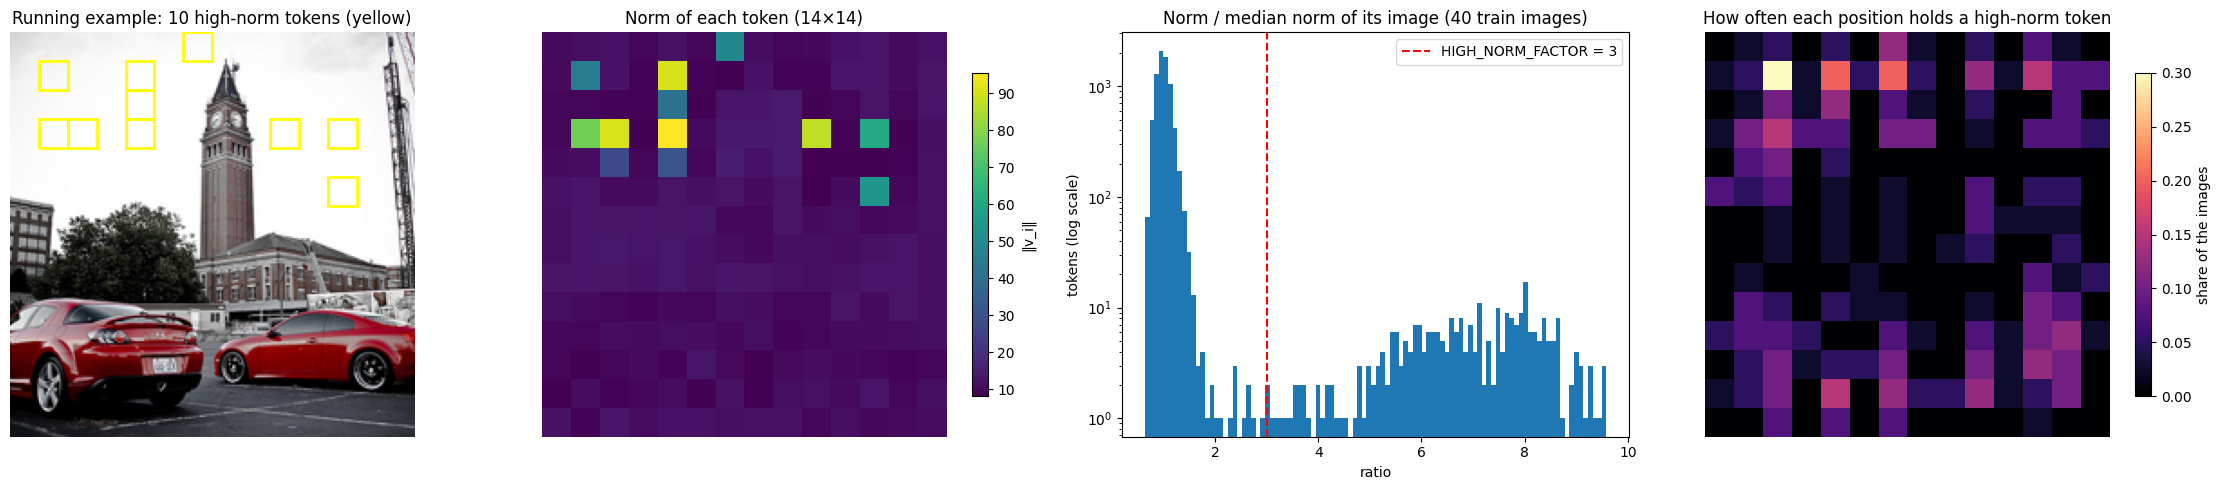

In [89]:
# 8.1 — Norm of each visual token: 14×14 heatmap, high-norm tokens
HIGH_NORM_FACTOR = 3        # analysis setting: high-norm = norm > 3 × the median norm of the same image
N_ANALYSIS_IMAGES = 500     # analysis setting: max number of train images for the statistics of section 8

# ---- 1. Running example (on CPU, in fp32: this section only analyses)
V_ex = example_feats["patches"][0].float().cpu()                # (196, 768), layer cfg.vision_feature_layer
norm_ex = V_ex.norm(dim=-1)                                      # (196,)
high_ex = norm_ex > HIGH_NORM_FACTOR * norm_ex.median()          # (196,) bool
show("V running example (196×768)", V_ex)
show("‖v_i‖ (196)", norm_ex)
print(f"median norm = {norm_ex.median():.2f}; {int(high_ex.sum())} high-norm tokens (> {HIGH_NORM_FACTOR} × median):")
print("   " + ", ".join(f"p = {p} ({p // G}, {p % G}): {norm_ex[p]:.1f}" for p in high_ex.nonzero().flatten().tolist()))
print(f"pixel std under the patch (running example): high-norm = {patches[high_ex].std(dim=1).mean():.3f}, "
      f"others = {patches[~high_ex].std(dim=1).mean():.3f}")      # `patches` = raw pixel patches of 5.3

# ---- 2. Sample of train images (the test set is never used for exploration)
n_train = len(clip_feats["train"]["image_ids"])
ana_rows = torch.from_numpy(np.sort(np.random.default_rng(cfg.seed).choice(
    n_train, size=min(N_ANALYSIS_IMAGES, n_train), replace=False)))
ana_ids = clip_feats["train"]["image_ids"][ana_rows]                          # (N,)
ana_V = clip_feats["train"]["patches"][ana_rows]                              # (N, 196, 768) fp16
ana_attn = clip_feats["train"]["cls_attn"][ana_rows].float()                  # (N, 196)
ana_norm = ana_V.float().norm(dim=-1)                                         # (N, 196)
ana_ratio = ana_norm / ana_norm.median(dim=1, keepdim=True).values            # (N, 196): norm / median of its image
ana_high = ana_ratio > HIGH_NORM_FACTOR                                       # (N, 196) bool
show("ana_V (N×196×768)", ana_V)
show("ana_norm (N×196)", ana_norm)

# Pixel std of each patch, cut out of the preprocessed image exactly as in 5.3
ana_pix_std = torch.empty(len(ana_rows), cfg.n_patches)
for i, image_id in enumerate(tqdm(ana_ids.tolist(), desc="pixel std per patch")):
    with Image.open(coco_image_path(SPLIT_SOURCE["train"], image_id)) as im:
        pv = image_processor(images=im.convert("RGB"), return_tensors="pt")["pixel_values"][0]
    ana_pix_std[i] = pv.unfold(1, P, P).unfold(2, P, P).permute(1, 2, 0, 3, 4).reshape(cfg.n_patches, -1).std(dim=1)

n_high = ana_high.sum(dim=1)                                                  # (N,) high-norm tokens per image
print(f"\nTrain sample: {len(ana_rows)} images")
print(f"   norm: median = {ana_norm.median():.2f}, p99 = {ana_norm.quantile(0.99):.2f}, max = {ana_norm.max():.2f}")
print(f"   high-norm tokens per image: mean = {n_high.float().mean():.1f}, min = {int(n_high.min())}, "
      f"max = {int(n_high.max())}  ({ana_high.float().mean():.1%} of all tokens)")
print("   sensitivity to the factor, high-norm tokens per image: "
      + ", ".join(f"× {f} → {(ana_ratio > f).sum(dim=1).float().mean():.2f}" for f in (2, 3, 5)))
print(f"   pixel std under the patch: high-norm = {ana_pix_std[ana_high].mean():.3f}, others = {ana_pix_std[~ana_high].mean():.3f}")

# ---- Figure
fig, axes = plt.subplots(1, 4, figsize=(23, 5))
axes[0].imshow(seen_by_clip.numpy())
for p in high_ex.nonzero().flatten().tolist():
    axes[0].add_patch(plt.Rectangle(((p % G) * P - 0.5, (p // G) * P - 0.5), P, P, fill=False, ec="yellow", lw=2))
axes[0].set_title(f"Running example: {int(high_ex.sum())} high-norm tokens (yellow)")
im = axes[1].imshow(norm_ex.view(G, G).numpy(), cmap="viridis")
fig.colorbar(im, ax=axes[1], shrink=0.8, label="‖v_i‖")
axes[1].set_title("Norm of each token (14×14)")
axes[2].hist(ana_ratio.flatten().numpy(), bins=100, log=True)
axes[2].axvline(HIGH_NORM_FACTOR, color="red", ls="--", label=f"HIGH_NORM_FACTOR = {HIGH_NORM_FACTOR}")
axes[2].set(title=f"Norm / median norm of its image ({len(ana_rows)} train images)", xlabel="ratio", ylabel="tokens (log scale)")
axes[2].legend()
im = axes[3].imshow(ana_high.float().mean(dim=0).view(G, G).numpy(), cmap="magma")
fig.colorbar(im, ax=axes[3], shrink=0.8, label="share of the images")
axes[3].set_title("How often each position holds a high-norm token")
for ax in (axes[0], axes[1], axes[3]):
    ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.path("fig", "8_1_norms.png"), dpi=120, bbox_inches="tight")
plt.show()

### 8.2 PCA of the 196 features: do the patches of one object group together?

**Goal**: look at the 768-dimensional tokens. We project them onto their **3 principal components** and display each component as one color channel (R, G, B). Two patches with similar features get similar colors. If the patches of the car share a color that differs from the tower and from the ground, then the features encode *what* is in the patch, which is what a selector needs.

**PCA in four steps.** For one image, $X \in \mathbb{R}^{196 \times 768}$:

1. center: $\tilde X = X - \bar x$ (mean over the patches);
2. SVD: $\tilde X = U\, \mathrm{diag}(S)\, W^\top$. The rows of $W^\top$ are the principal directions, sorted by decreasing $S$;
3. project: $Z = \tilde X\, W_{:, 1:3} \in \mathbb{R}^{196 \times 3}$;
4. share of the variance explained by component $j$: $S_j^2 / \sum_k S_k^2$.

We use `torch.linalg.svd`, and 8.6 checks the result against `sklearn.decomposition.PCA`.

**Pitfall: the high-norm tokens of 8.1 take over the PCA.** PCA looks for the directions of largest variance. A handful of tokens whose norm is several times larger than the others create a large variance on their own. The first component then mostly separates them from everything else, and one of the three colors is spent on a few tokens. Hence a second version: we **fit** the PCA without them, project every token anyway, and draw the high-norm ones in black. The cell prints the explained variance of both versions.

**From components to colors**: each component is mapped to [0, 1] with its min and max over the tokens used for the fit.

**A number to go with the pictures**, over the train sample, high-norm tokens excluded: the mean cosine similarity between **neighbouring** patches (grid distance 1) and between **distant** patches (distance ≥ 7), with the `grid_dist` of 6.2. ⚠️ Two causes are mixed in this number. Neighbouring patches often show the same object, but they also have similar positional embeddings (6.2). So it describes the features; it does not prove that they are grouped by object. The cell prints the same measure on the positional embeddings alone, for reference.

Z (196×3)                    (196, 3)           float32   cpu  min=-8.573 max=+59.648 mean=+1.801 std=8.862
RGB colors (196×3)           (196, 3)           float32   cpu  min=+0.000 max=+1.000 mean=+0.271 std=0.199
Explained variance of the 3 components, all tokens:                 [0.734 0.036 0.029]
Explained variance of the 3 components, fit without high-norm:      [0.13  0.117 0.077]
|component 1| with all tokens: high-norm = 64.1, others = 4.0

Train sample (40 images), mean cosine similarity between two patches:
   neighbours (distance 1)  features V = 0.514   positional embeddings alone (6.2) = 0.663
   distant (distance ≥ 7)   features V = 0.255   positional embeddings alone (6.2) = 0.330


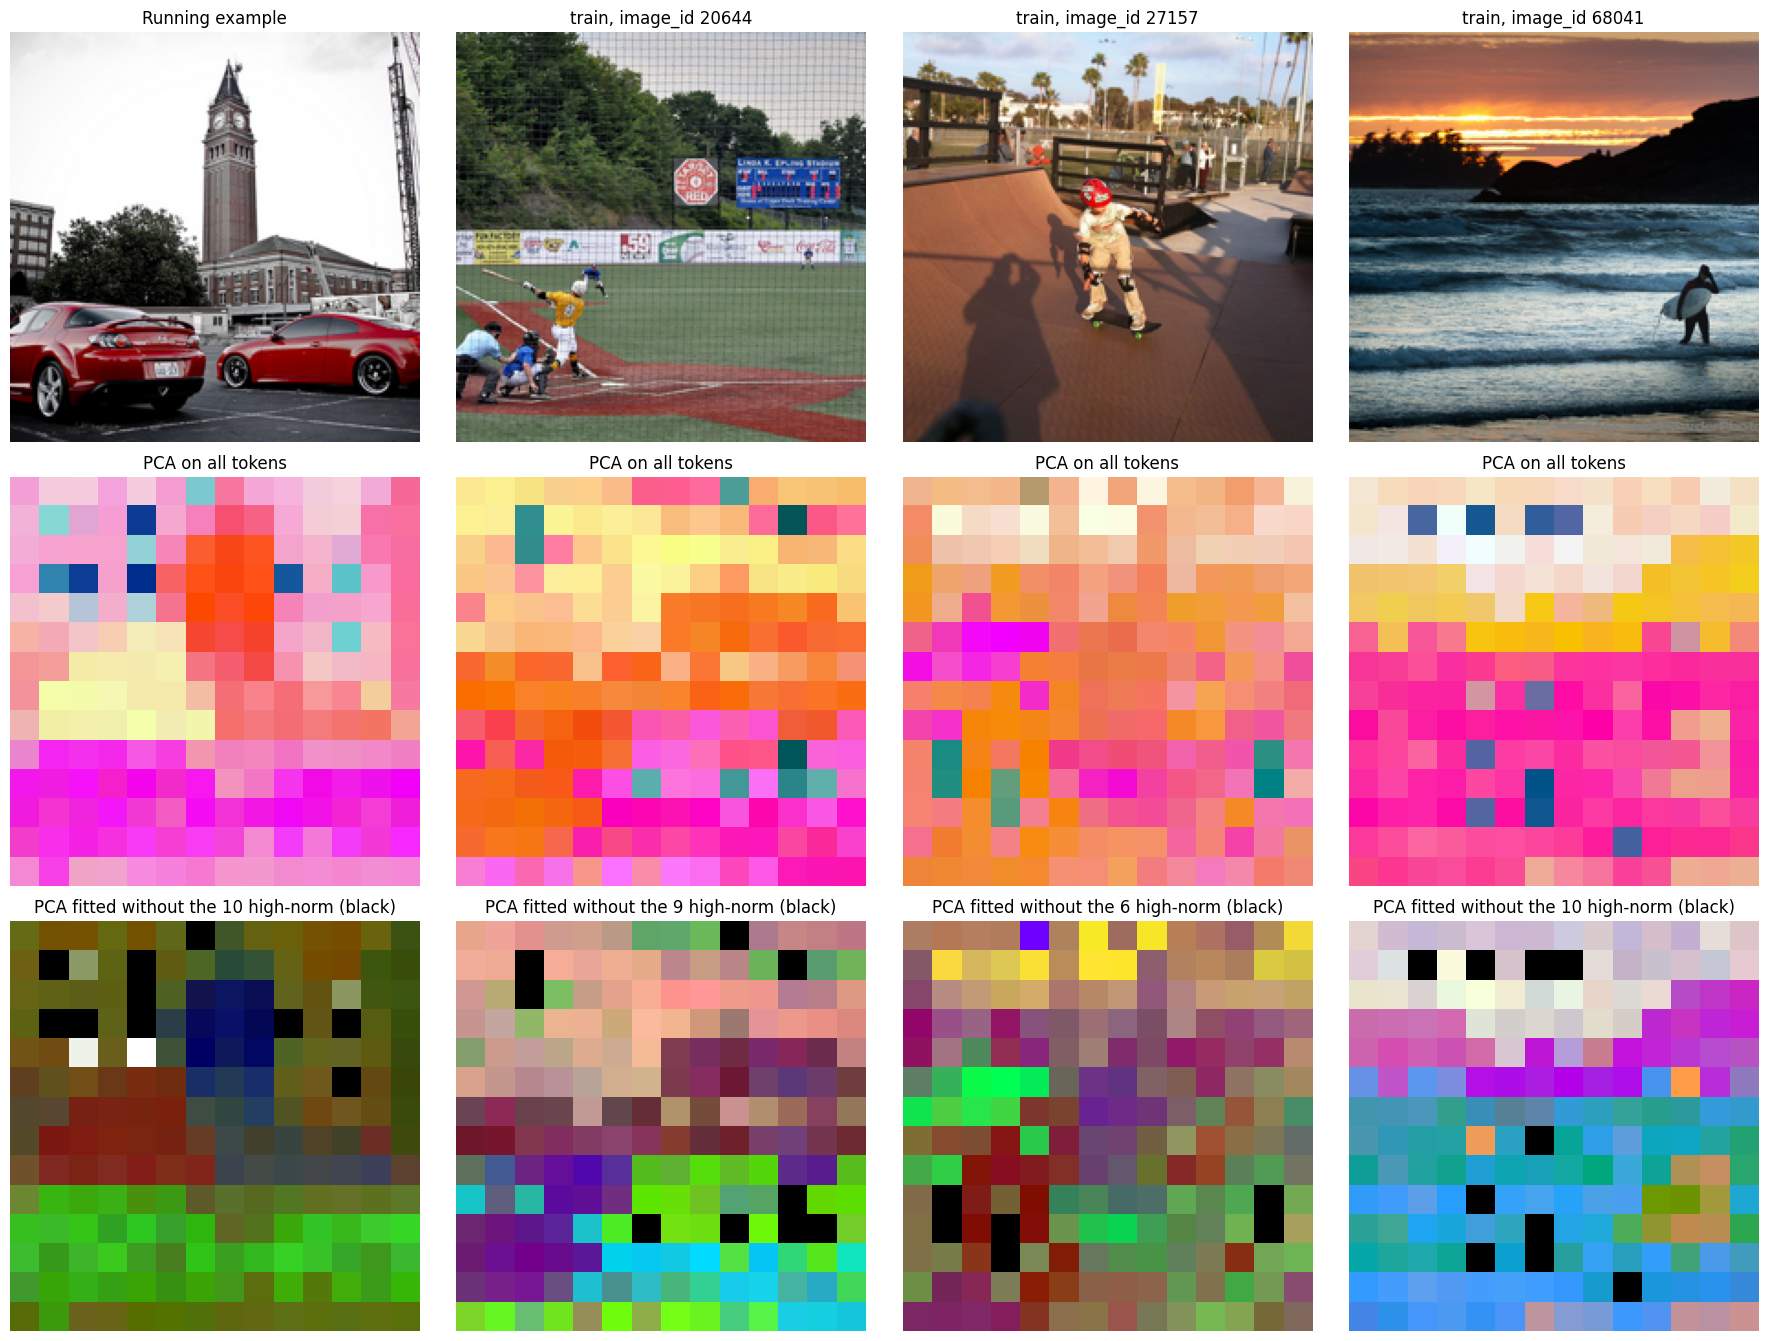

In [90]:
# 8.2 — PCA of the 196 features to 3 components shown as RGB colors
PCA_IMAGES = 3    # display only: number of train images shown next to the running example


def pca3(X: torch.Tensor, fit_mask: torch.Tensor):
    # X (196, 768), fit_mask (196,) bool = tokens used to fit the PCA
    # → Z (196, 3): EVERY token projected on the 3 first components; explained variance ratio of all components
    Xf = X[fit_mask]
    mu = Xf.mean(dim=0)
    _, S_, Wt = torch.linalg.svd(Xf - mu, full_matrices=False)    # Wt (r, 768): rows = principal directions
    return (X - mu) @ Wt[:3].T, S_ ** 2 / (S_ ** 2).sum()


def to_rgb(Z: torch.Tensor, fit_mask: torch.Tensor) -> torch.Tensor:
    # (196, 3) → colors in [0, 1], scaled with the min / max over the fitted tokens; the other tokens in black
    lo, hi = Z[fit_mask].min(dim=0).values, Z[fit_mask].max(dim=0).values
    rgb = ((Z - lo) / (hi - lo)).clamp(0, 1)
    rgb[~fit_mask] = 0
    return rgb


# ---- 1. Running example: PCA on all tokens vs PCA fitted without the high-norm tokens
all_tokens = torch.ones(cfg.n_patches, dtype=torch.bool)
Z_all, ev_all = pca3(V_ex, all_tokens)
Z_clean, ev_clean = pca3(V_ex, ~high_ex)
rgb_clean = to_rgb(Z_clean, ~high_ex)
show("Z (196×3)", Z_clean)
show("RGB colors (196×3)", rgb_clean)
print(f"Explained variance of the 3 components, all tokens:                 {ev_all[:3].numpy().round(3)}")
print(f"Explained variance of the 3 components, fit without high-norm:      {ev_clean[:3].numpy().round(3)}")
print(f"|component 1| with all tokens: high-norm = {Z_all[high_ex, 0].abs().mean():.1f}, "
      f"others = {Z_all[~high_ex, 0].abs().mean():.1f}")

# ---- 2. Train sample: are neighbouring patches more similar than distant ones? (high-norm tokens excluded)
Vn = F.normalize(ana_V.float(), dim=-1)                          # (N, 196, 768) unit vectors
cos = Vn @ Vn.transpose(1, 2)                                    # (N, 196, 196) cosine similarities
valid = ~ana_high[:, :, None] & ~ana_high[:, None, :]            # (N, 196, 196): neither token is high-norm
print(f"\nTrain sample ({len(ana_rows)} images), mean cosine similarity between two patches:")
for name, pairs in [("neighbours (distance 1)", grid_dist == 1), (f"distant (distance ≥ {G // 2})", grid_dist >= G // 2)]:
    print(f"   {name:<24} features V = {cos[valid & pairs].mean():.3f}   "
          f"positional embeddings alone (6.2) = {pos_sim[pairs].mean():.3f}")
del Vn, cos, valid                                               # ~0.4 GB in full mode

# ---- 3. Figure: running example + the first PCA_IMAGES images of the train sample
panels = [("Running example", seen_by_clip.numpy(), V_ex, high_ex)]
for i in range(min(PCA_IMAGES, len(ana_rows))):
    with Image.open(coco_image_path(SPLIT_SOURCE["train"], int(ana_ids[i]))) as im:
        pv = image_processor(images=im.convert("RGB"), return_tensors="pt")["pixel_values"][0]
    panels.append((f"train, image_id {int(ana_ids[i])}", (pv * std + mean).clamp(0, 1).permute(1, 2, 0).numpy(),
                   ana_V[i].float(), ana_high[i]))

fig, axes = plt.subplots(3, len(panels), figsize=(4.5 * len(panels), 13.5), squeeze=False)
for j, (title, img, X, high) in enumerate(panels):
    axes[0, j].imshow(img)
    axes[0, j].set_title(title)
    axes[1, j].imshow(to_rgb(pca3(X, all_tokens)[0], all_tokens).view(G, G, 3).numpy())
    axes[1, j].set_title("PCA on all tokens")
    axes[2, j].imshow(to_rgb(pca3(X, ~high)[0], ~high).view(G, G, 3).numpy())
    axes[2, j].set_title(f"PCA fitted without the {int(high.sum())} high-norm (black)")
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.path("fig", "8_2_pca.png"), dpi=120, bbox_inches="tight")
plt.show()

### 8.3 Where does the CLS look?

**Goal**: overlay on the image the CLS attention `cls_attn` cached in 6.3. This is how much the CLS of the last block, the vector CLIP is trained on, attends to each of our 196 tokens. The map is the score of the "CLS attention" baseline of section 11. It is the only score in this project that comes for free with the ViT, without the question.

**Upsampling to pixels.** The map is 14×14 and the image is 224×224. `F.interpolate(..., scale_factor=16, mode="nearest")` repeats each value over its 16×16 block, so patch $p$ colors exactly the pixels it covers (5.3). A bilinear interpolation would look smoother, but it would spread each value onto the neighbouring patches.

**Link with 8.1.** If the CLS uses the high-norm tokens to store global information (Darcet et al., 2024), its attention should concentrate on them rather than on the objects. Over the train sample, the cell measures:

* the share of the CLS attention that goes to the high-norm tokens, compared with their share of the tokens. `cls_attn` sums to a bit less than 1 over the patches (6.3: the CLS → CLS entry is dropped), so the share is computed relative to the total attention on the patches of each image;
* how often the patch the CLS attends to most is a high-norm token.

cls_attn (196)               (196,)             float32   cpu  min=+0.000 max=+0.082 mean=+0.004 std=0.011
cls_attn upsampled (224×224) (224, 224)         float32   cpu  min=+0.000 max=+0.082 mean=+0.004 std=0.011
Top-5 patches of the CLS, p (row, col): 46 (3, 4) high-norm, 18 (1, 4) high-norm, 44 (3, 2) high-norm, 51 (3, 9) high-norm, 43 (3, 1) high-norm
Running example: high-norm tokens = 5.1% of the tokens, 42.0% of the CLS attention on the patches

Train sample (40 images):
   high-norm tokens: 3.8% of the tokens, 51.8% of the CLS attention on the patches (mean over images)
   the patch the CLS attends to most is high-norm in 100.0% of the images


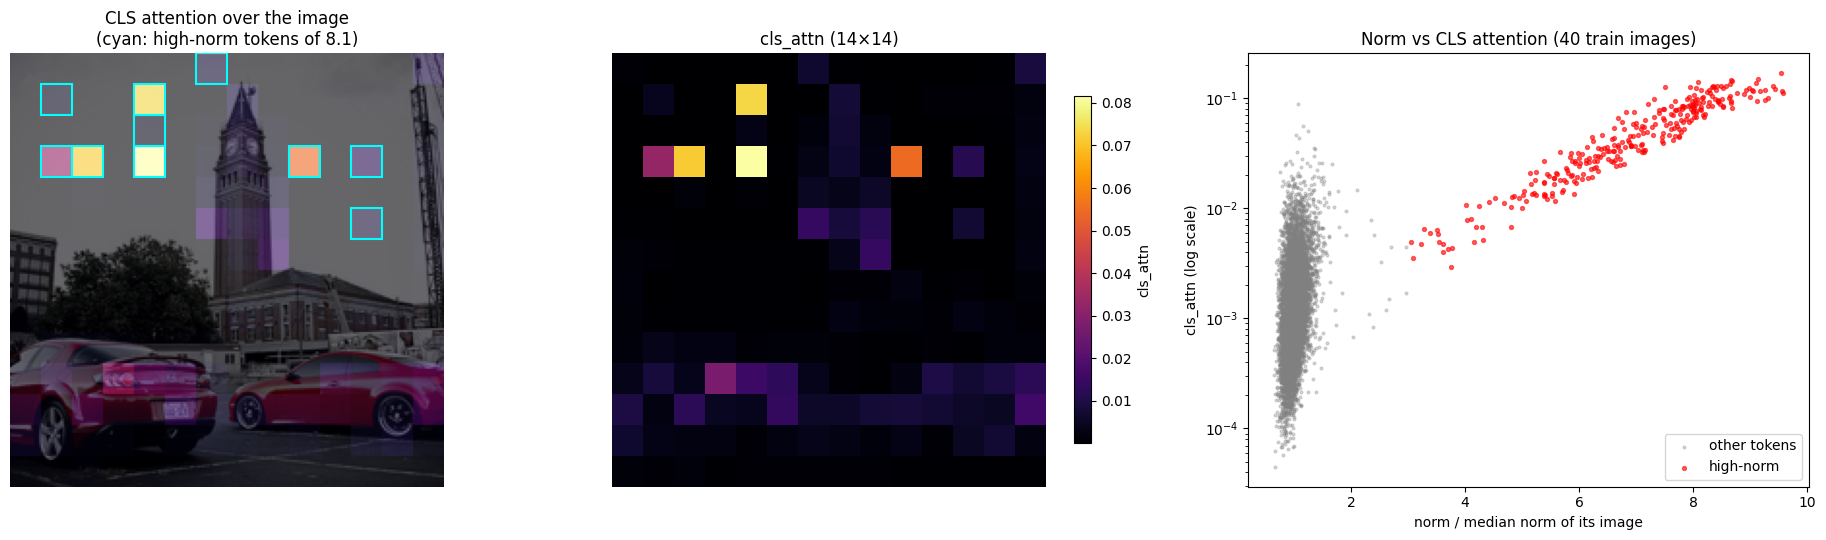

In [91]:
# 8.3 — CLS attention map over the image
attn_ex = example_feats["cls_attn"][0].float().cpu()                                        # (196,)
# (1, 1, 14, 14) → (1, 1, 224, 224): each value repeated over its 16×16 block
attn_px = F.interpolate(attn_ex.view(1, 1, G, G), scale_factor=P, mode="nearest")[0, 0]     # (224, 224)
show("cls_attn (196)", attn_ex)
show("cls_attn upsampled (224×224)", attn_px)
print("Top-5 patches of the CLS, p (row, col): "
      + ", ".join(f"{p} ({p // G}, {p % G}){' high-norm' if high_ex[p] else ''}" for p in attn_ex.topk(5).indices.tolist()))
print(f"Running example: high-norm tokens = {high_ex.float().mean():.1%} of the tokens, "
      f"{attn_ex[high_ex].sum() / attn_ex.sum():.1%} of the CLS attention on the patches")

# ---- Train sample
share_high = (ana_attn * ana_high).sum(dim=1) / ana_attn.sum(dim=1)              # (N,) share of the patch attention
top1_high = ana_high.gather(1, ana_attn.argmax(dim=1, keepdim=True))[:, 0]        # (N,) is the top patch high-norm?
print(f"\nTrain sample ({len(ana_rows)} images):")
print(f"   high-norm tokens: {ana_high.float().mean():.1%} of the tokens, "
      f"{share_high.mean():.1%} of the CLS attention on the patches (mean over images)")
print(f"   the patch the CLS attends to most is high-norm in {top1_high.float().mean():.1%} of the images")

# ---- Figure
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].imshow(seen_by_clip.numpy())
axes[0].imshow(attn_px.numpy(), cmap="inferno", alpha=0.6)
for p in high_ex.nonzero().flatten().tolist():
    axes[0].add_patch(plt.Rectangle(((p % G) * P - 0.5, (p // G) * P - 0.5), P, P, fill=False, ec="cyan", lw=1.5))
axes[0].set_title("CLS attention over the image\n(cyan: high-norm tokens of 8.1)")
axes[0].axis("off")
im = axes[1].imshow(attn_ex.view(G, G).numpy(), cmap="inferno")
fig.colorbar(im, ax=axes[1], shrink=0.8, label="cls_attn")
axes[1].set_title("cls_attn (14×14)")
axes[1].axis("off")
axes[2].scatter(ana_ratio[~ana_high].numpy(), ana_attn[~ana_high].numpy(), s=4, alpha=0.3, c="gray", label="other tokens")
axes[2].scatter(ana_ratio[ana_high].numpy(), ana_attn[ana_high].numpy(), s=8, alpha=0.6, c="red", label="high-norm")
axes[2].set(yscale="log", xlabel="norm / median norm of its image", ylabel="cls_attn (log scale)",
            title=f"Norm vs CLS attention ({len(ana_rows)} train images)")
axes[2].legend()
fig.tight_layout()
fig.savefig(cfg.path("fig", "8_3_cls_attention.png"), dpi=120, bbox_inches="tight")
plt.show()

### 8.4 Raw patch–text similarity through CLIP's projections

**Goal**: test the simplest question-conditioned selector, which needs **no training**. We score each patch by its cosine similarity with the question, in CLIP's shared image-text space.

**CLIP's shared space.** CLIP was trained so that a matching (image, caption) pair gives two **512-dimensional** vectors with a high cosine similarity:

* image side: the last-layer CLS → `post_layernorm` → `visual_projection` (768 → 512, no bias);
* text side: q̄, the EOS vector of 7.3 → `text_projection` (512 → 512, no bias).

These two projections are not part of `CLIPVisionModel` / `CLIPTextModel`. We load the full `CLIPModel` once, keep the two `Linear` layers and `logit_scale`, and free the rest (the two towers are already loaded). We check that our path gives exactly CLIP's own `get_image_features` / `get_text_features`.

**The patch scores.** We send each token of V through the **same** image-side path, in place of the CLS:

$$
s_i = \cos\big(W_v\, \mathrm{LN}_{post}(v_i),\ W_t\, \bar q\big), \qquad i = 1, \dots, 196
$$

⚠️ This is outside what CLIP was trained for. The contrastive loss only ever sent the CLS through this path, never the patch tokens (6.3), and V comes from the penultimate layer. Nothing guarantees that $s_i$ is high on the patches the question is about. That is exactly what we measure.

**Three measurements:**

1. **Global sanity check: the zero-shot color of the car.** We compare the CLS embedding with "a photo of a {color} car" for the 5 most frequent answers to "What color is the car?" (4.2), with a softmax over `logit_scale` × cosine, the way CLIP classifies. If the right color wins, the information is in CLIP's representation of the image.
2. **Maps on the running example**: $s$ as a 14×14 map for the question, and for a few short prompts that name objects of the image. If the patch–text alignment worked, each map would be bright on its object.
3. **Does the selection change with the question?** On the train sample, for each pair of questions asked about the same image, we measure the overlap of their top-$K$ patches with $K$ = `cfg.k_buckets[0]`, the smallest budget. Two random sets of $K$ patches among 196 share on average $K \cdot K / 196$ patches, i.e. an overlap of $K / 196$. Some overlap is legitimate (two questions about the same object). But if the top-$K$ barely changes with the question, this score cannot serve as a question-conditioned selector.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

our path vs CLIP: image relative error = 9.47e-07, text = 0.00e+00

1. Zero-shot color from the CLS: white 0.3%, red 99.5%, black 0.1%, blue 0.1%, silver 0.1%

patches in CLIP space (196×512) (196, 512)         float32   cpu  min=-0.233 max=+0.799 mean=+0.001 std=0.044
texts in CLIP space (4×512)  (4, 512)           float32   cpu  min=-0.191 max=+0.819 mean=+0.003 std=0.044
s (196×4)                    (196, 4)           float32   cpu  min=+0.055 max=+0.315 mean=+0.233 std=0.042

2. Patch scores s_i on the running example:
   'What color is the car?'   s ∈ [0.115, 0.305]   CLS cosine = 0.252   top-5 (row, col): [(1, 6), (1, 2), (2, 5), (4, 11), (2, 11)]
   'a red car'                s ∈ [0.055, 0.315]   CLS cosine = 0.276   top-5 (row, col): [(1, 2), (2, 11), (2, 2), (1, 6), (4, 2)]
   'a clock tower'            s ∈ [0.066, 0.290]   CLS cosine = 0.249   top-5 (row, col): [(1, 2), (2, 11), (4, 4), (4, 2), (2, 4)]
   'a tree'                   s ∈ [0.159, 0.309]   CLS cosine = 0.170   to

top-24 overlap:   0%|          | 0/40 [00:00<?, ?it/s]


3. Top-24 overlap between two questions on the same image (430 pairs): mean = 54.7%, median = 58.3%   (two random sets: 12.2%)


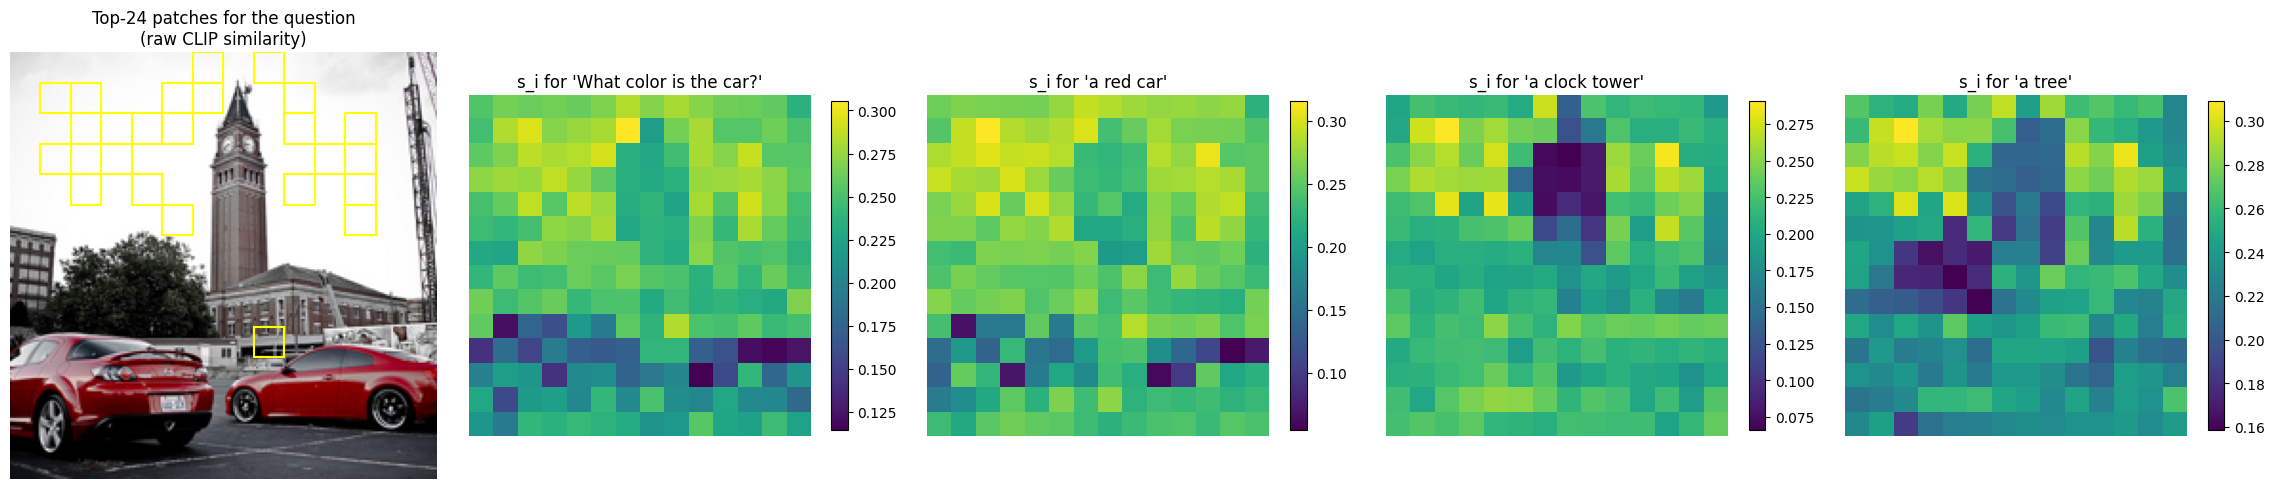

In [92]:
# 8.4 — Raw patch–text similarity through CLIP's projections
import itertools
from transformers import CLIPModel

COLORS = example_rows["multiple_choice_answer"].value_counts().index[:5].tolist()   # 5 most frequent answers (4.2)
OBJECT_PROMPTS = ["a red car", "a clock tower", "a tree"]    # display only: objects visible in the running example

clip_full = CLIPModel.from_pretrained(cfg.clip_name, dtype=DTYPE).to(DEVICE).eval()
clip_full.requires_grad_(False)
visual_projection, text_projection = clip_full.visual_projection, clip_full.text_projection   # Linear 768→512, 512→512
logit_scale = clip_full.logit_scale.exp().item()
post_layernorm = clip_vision.vision_model.post_layernorm


def image_space(h: torch.Tensor) -> torch.Tensor:
    # (..., 768) ViT tokens → (..., 512) unit vectors in CLIP's shared space
    return F.normalize(visual_projection(post_layernorm(h.to(DEVICE, DTYPE))), dim=-1)


def text_space(q_bar: torch.Tensor) -> torch.Tensor:
    # (B, 512) EOS vectors (7.3) → (B, 512) unit vectors in CLIP's shared space
    return F.normalize(text_projection(q_bar.to(DEVICE, DTYPE)), dim=-1)


# ---- 0. Our path = CLIP's own functions; then the rest of CLIPModel is freed
with torch.no_grad():
    ref_img = clip_full.get_image_features(pixel_values=pixel_values.to(DEVICE, DTYPE)).pooler_output    # (1, 512)
    ref_txt = clip_full.get_text_features(**clip_tokenizer([EXAMPLE["question"]], return_tensors="pt").to(DEVICE)).pooler_output
    img_emb = image_space(vit_out.hidden_states[-1][:, 0])          # (1, 512): last-layer CLS, normalized
    txt_emb = text_space(example_q["q_bar"])                        # (1, 512)
proj_img_err = rel_err(img_emb, F.normalize(ref_img, dim=-1))
proj_txt_err = rel_err(txt_emb, F.normalize(ref_txt, dim=-1))
print(f"our path vs CLIP: image relative error = {proj_img_err:.2e}, text = {proj_txt_err:.2e}")
del clip_full, ref_img, ref_txt
gpu_mem("after freeing CLIPModel")

# ---- 1. Global sanity check: zero-shot color of the car, from the CLS embedding
with torch.no_grad():
    t_colors = text_space(encode_questions([f"a photo of a {c} car" for c in COLORS])["q_bar"])   # (5, 512)
    color_probs = (logit_scale * img_emb @ t_colors.T).softmax(dim=-1)[0].float().cpu()          # (5,)
print("\n1. Zero-shot color from the CLS: " + ", ".join(f"{c} {p:.1%}" for c, p in zip(COLORS, color_probs.tolist())))

# ---- 2. Patch maps on the running example: the question and a few objects of the image
texts = [EXAMPLE["question"], *OBJECT_PROMPTS]
with torch.no_grad():
    P_ex = image_space(V_ex)                                         # (196, 512)
    T_ex = text_space(encode_questions(texts)["q_bar"])              # (4, 512)
sim_ex = (P_ex @ T_ex.T).float().cpu()                               # (196, 4): s_i for each text
glob_ex = (img_emb @ T_ex.T)[0].float().cpu()                        # (4,): CLS (image-level) cosine, for reference
print()
show("patches in CLIP space (196×512)", P_ex)
show("texts in CLIP space (4×512)", T_ex)
show("s (196×4)", sim_ex)
print("\n2. Patch scores s_i on the running example:")
for j, t in enumerate(texts):
    top5 = sim_ex[:, j].topk(5).indices.tolist()
    print(f"   {t!r:<26} s ∈ [{sim_ex[:, j].min():.3f}, {sim_ex[:, j].max():.3f}]   CLS cosine = {glob_ex[j]:.3f}   "
          f"top-5 (row, col): {[(p // G, p % G) for p in top5]}")

# ---- 3. Train sample: does the top-K change with the question?
k_min = cfg.k_buckets[0]
questions_by_image = data_df[data_df["split"] == "train"].groupby("image_id")["question"].agg(list)
overlaps = []
for i, image_id in enumerate(tqdm(ana_ids.tolist(), desc=f"top-{k_min} overlap")):
    qs = questions_by_image[image_id]
    if len(qs) < 2:
        continue
    with torch.no_grad():
        s = image_space(ana_V[i]) @ text_space(encode_questions(qs)["q_bar"]).T     # (196, n_q)
    top = s.float().topk(k_min, dim=0).indices.T.cpu()                              # (n_q, K): top-K of each question
    for a, b in itertools.combinations(range(len(qs)), 2):
        overlaps.append(len(set(top[a].tolist()) & set(top[b].tolist())) / k_min)
overlaps = np.array(overlaps)
print(f"\n3. Top-{k_min} overlap between two questions on the same image ({len(overlaps)} pairs): "
      f"mean = {overlaps.mean():.1%}, median = {np.median(overlaps):.1%}   (two random sets: {k_min / cfg.n_patches:.1%})")

# ---- Figure: the top-K a raw-CLIP selector would keep, and the maps
top_q = sim_ex[:, 0].topk(k_min).indices.tolist()
fig, axes = plt.subplots(1, len(texts) + 1, figsize=(4.6 * (len(texts) + 1), 4.8))
axes[0].imshow(seen_by_clip.numpy())
for p in top_q:
    axes[0].add_patch(plt.Rectangle(((p % G) * P - 0.5, (p // G) * P - 0.5), P, P, fill=False, ec="yellow", lw=1.5))
axes[0].set_title(f"Top-{k_min} patches for the question\n(raw CLIP similarity)")
for ax, t, s_map in zip(axes[1:], texts, sim_ex.T):
    im = ax.imshow(s_map.view(G, G).numpy(), cmap="viridis")
    fig.colorbar(im, ax=ax, shrink=0.75)
    ax.set_title(f"s_i for {t!r}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.path("fig", "8_4_patch_text_similarity.png"), dpi=120, bbox_inches="tight")
plt.show()

### 8.5 What this section tells us

Read together with the outputs above (DEBUG: a train sample of 40 images, one running example, so the numbers are indicative):

1. **The tokens do encode content.** Once PCA is fitted without the high-norm tokens, the 3 components draw recognizable regions: sky, tower, trees, playing field (8.2). Neighbouring patches are more similar than distant ones, but the positional embeddings alone show the same pattern (6.2), so this number by itself does not prove grouping by object. On the running example, the cars and the asphalt get similar colors in these first 3 components: 3 components out of 768 are a coarse summary.
2. **A few high-norm tokens behave differently.** A handful per image have a norm several times the median, with a clear gap in the histogram (8.1). On the running example they all lie in the uniform sky. On the train sample, their patches are also more uniform than the others on average, although the gap is smaller. They dominate a naive PCA (8.2), and they receive about half of the CLS attention (8.3).
3. **The CLS attention is not an object map.** Its top patch is a high-norm token in every image of the sample (8.3). The "CLS attention" baseline of section 11 will therefore mostly keep these tokens. Whether that helps (global information) or hurts (no local detail) for VQA is an empirical question, measured in sections 19 – 20.
4. **Raw patch–text alignment does not localize.** CLIP's global embedding gets the color of the car right (8.4.1), so the information is in the image representation. But the per-patch scores are high in the sky, and the 24 patches they select for "What color is the car?" are almost all outside the cars (8.4.2). The same few patches come first for every prompt, and the maps for "a red car", "a clock tower" and "a tree" are lowest on those very objects. Inverted maps of this kind have been reported for CLIP (Li et al., 2023, *CLIP Surgery*). Across the train sample, two different questions about the same image share a large part of their top-24, far above chance (8.4.3).

**Consequence for the project** (PLAN, section 8): CLIP's raw patch–text similarity cannot serve as the selector. The question-conditioned scorer has to be **learned** (sections 9 – 12). It is trained with the VQA loss and distilled from the teacher's attention, so it learns which patches actually help to answer. We keep the high-norm tokens in mind: the scorer and the projector will see vectors whose norm is several times the typical one.

Caveat: we have no object masks (COCO segmentations are not downloaded), so "the selected patches are outside the car" is a visual reading of the running example, not a measured localization score.

### 8.6 Section 8 checks

This section only analyses, so the checks target the **code** of the analyses, not the findings (those are discussed in 8.5).

1. **Data hygiene**: the statistics use train images only, none from dev or test, and exactly `min(N_ANALYSIS_IMAGES, train images)` of them.
2. **Norms** (8.1): shapes (196,) and (N, 196), equal to `torch.linalg.vector_norm`, finite and positive. The high-norm mask matches its definition.
3. **PCA** (8.2), validated against `sklearn.decomposition.PCA`: same explained variance, and the same projections up to the sign of each component (the sign of a principal direction is arbitrary). Colors: shape (196, 3), values in [0, 1], tokens outside the fit in black.
4. **CLS map** (8.3): the 224×224 map repeats each value exactly over its own 16×16 block (patch $p$ → rows $16\,(p // 14)$ …, columns $16\,(p \bmod 14)$ …). The attention shares are in [0, 1].
5. **CLIP projections** (8.4): our path = `get_image_features` / `get_text_features` (relative error < `REL_TOL`); the projected vectors have unit norm; the scores $s_i$ are cosines, so in [−1, 1], with shape (196, number of texts); the zero-shot probabilities sum to 1.
6. **Top-K** (8.4): $K$ unique indices; every overlap is in [0, 1]. **Control**: the overlap measure gives 100% for a score compared with itself, and close to the chance level $K / 196$ for two independent random scores (averaged over draws with a seeded generator). Otherwise the 8.4.3 number could not be read against the chance level.
7. No NaN / inf in the analysed tensors.

In [93]:
# 8.6 — Section 8 checks
from sklearn.decomposition import PCA

N_CONTROL_DRAWS = 1000   # check setting: random score pairs for the chance level of the top-K overlap
checks = {}

# ---- 1. Data hygiene
ids = set(ana_ids.tolist())
checks["statistics on train images only (none from dev / test)"] = (
    ids <= set(SPLIT_IDS["train"]) and not ids & (set(SPLIT_IDS["dev"]) | set(SPLIT_IDS["test"])))
checks["sample size = min(N_ANALYSIS_IMAGES, train images), no duplicate"] = (
    len(ids) == len(ana_ids) == min(N_ANALYSIS_IMAGES, len(clip_feats["train"]["image_ids"])))

# ---- 2. Norms
checks["norms: shapes (196,) and (N, 196)"] = (
    norm_ex.shape == (cfg.n_patches,) and ana_norm.shape == (len(ana_ids), cfg.n_patches))
checks["norms = torch.linalg.vector_norm"] = (
    torch.allclose(norm_ex, torch.linalg.vector_norm(V_ex, dim=-1))
    and torch.allclose(ana_norm, torch.linalg.vector_norm(ana_V.float(), dim=-1)))
checks["norms finite and > 0"] = bool(torch.isfinite(ana_norm).all() and (ana_norm > 0).all() and (norm_ex > 0).all())
checks["high-norm mask = norm > HIGH_NORM_FACTOR × median of the image"] = torch.equal(
    ana_high, ana_norm > HIGH_NORM_FACTOR * ana_norm.median(dim=1, keepdim=True).values)

# ---- 3. PCA vs sklearn (fit without the high-norm tokens, projection of every token)
sk = PCA(n_components=3).fit(V_ex[~high_ex].numpy())
Z_sk = torch.from_numpy(sk.transform(V_ex.numpy())).float()
print(f"PCA: explained variance ours = {ev_clean[:3].numpy().round(4)}, sklearn = {sk.explained_variance_ratio_.round(4)}")
print(f"PCA: relative error |Z| ours vs sklearn = {rel_err(Z_clean.abs(), Z_sk.abs()):.2e}")
checks["PCA: explained variance = sklearn"] = np.allclose(ev_clean[:3].numpy(), sk.explained_variance_ratio_, atol=1e-4)
checks["PCA: projections = sklearn up to the sign"] = rel_err(Z_clean.abs(), Z_sk.abs()) < REL_TOL
checks["PCA: explained variance sorted, sums to 1"] = bool(
    (ev_clean[:-1] >= ev_clean[1:] - 1e-7).all() and abs(ev_clean.sum().item() - 1) < 1e-4)
checks["colors: (196, 3) in [0, 1], high-norm tokens black"] = (
    rgb_clean.shape == (cfg.n_patches, 3) and bool((rgb_clean >= 0).all() and (rgb_clean <= 1).all())
    and bool((rgb_clean[high_ex] == 0).all()))

# ---- 4. CLS map
block_map = attn_ex.view(G, G).repeat_interleave(P, dim=0).repeat_interleave(P, dim=1)   # (224, 224), block by block
checks["upsampled CLS map: (224, 224), patch p fills exactly its 16×16 block"] = (
    attn_px.shape == (cfg.image_size, cfg.image_size) and torch.equal(attn_px, block_map))
checks["attention shares in [0, 1]"] = bool((share_high >= 0).all() and (share_high <= 1 + 1e-6).all())

# ---- 5. CLIP projections
checks["image path = get_image_features"] = proj_img_err < REL_TOL
checks["text path = get_text_features"] = proj_txt_err < REL_TOL
# atol 1e-2: the vectors are normalized in DTYPE, and fp16 keeps ~3 significant digits
checks["projected vectors have unit norm"] = bool(
    torch.allclose(P_ex.float().norm(dim=-1), torch.ones(cfg.n_patches, device=P_ex.device), atol=1e-2)
    and torch.allclose(T_ex.float().norm(dim=-1), torch.ones(len(texts), device=T_ex.device), atol=1e-2))
checks["scores s: (196, n_texts), in [−1, 1]"] = (
    sim_ex.shape == (cfg.n_patches, len(texts)) and bool((sim_ex.abs() <= 1 + 1e-3).all()))
checks["zero-shot probabilities sum to 1"] = abs(color_probs.sum().item() - 1) < 1e-4

# ---- 6. Top-K and the overlap measure
checks[f"top-{k_min}: {k_min} unique indices"] = len(set(top_q)) == k_min
checks["overlaps in [0, 1]"] = len(overlaps) > 0 and bool(((overlaps >= 0) & (overlaps <= 1)).all())


def topk_overlap(s1: torch.Tensor, s2: torch.Tensor, k: int) -> float:
    # share of the top-k patches of s1 that are also in the top-k of s2 (the measure of 8.4.3)
    return len(set(s1.topk(k).indices.tolist()) & set(s2.topk(k).indices.tolist())) / k


gen = torch.Generator().manual_seed(cfg.seed)
s_ctrl = sim_ex[:, 0]
chance = np.mean([topk_overlap(torch.rand(cfg.n_patches, generator=gen), torch.rand(cfg.n_patches, generator=gen), k_min)
                  for _ in range(N_CONTROL_DRAWS)])
print(f"Overlap control: identical scores → {topk_overlap(s_ctrl, s_ctrl, k_min):.1%}, "
      f"random scores → {chance:.1%} (expected {k_min / cfg.n_patches:.1%})")
checks["control: identical scores → overlap 100%"] = topk_overlap(s_ctrl, s_ctrl, k_min) == 1.0
checks["control: random scores → overlap ≈ K / 196 (± 2 points)"] = abs(chance - k_min / cfg.n_patches) < 0.02

# ---- 7. Finite values
checks["no NaN / inf in the analysed tensors"] = all(
    torch.isfinite(t.float()).all().item() for t in (V_ex, ana_V, ana_attn, ana_pix_std, Z_clean, attn_px, sim_ex, P_ex))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 8 check failed: do not move on to section 9."
print("\nSection 8 validated → we can move on to section 9.")

PCA: explained variance ours = [0.1305 0.1175 0.0769], sklearn = [0.1305 0.1175 0.0769]
PCA: relative error |Z| ours vs sklearn = 1.24e-06
Overlap control: identical scores → 100.0%, random scores → 12.3% (expected 12.2%)

✅ statistics on train images only (none from dev / test)
✅ sample size = min(N_ANALYSIS_IMAGES, train images), no duplicate
✅ norms: shapes (196,) and (N, 196)
✅ norms = torch.linalg.vector_norm
✅ norms finite and > 0
✅ high-norm mask = norm > HIGH_NORM_FACTOR × median of the image
✅ PCA: explained variance = sklearn
✅ PCA: projections = sklearn up to the sign
✅ PCA: explained variance sorted, sums to 1
✅ colors: (196, 3) in [0, 1], high-norm tokens black
✅ upsampled CLS map: (224, 224), patch p fills exactly its 16×16 block
✅ attention shares in [0, 1]
✅ image path = get_image_features
✅ text path = get_text_features
✅ projected vectors have unit norm
✅ scores s: (196, n_texts), in [−1, 1]
✅ zero-shot probabilities sum to 1
✅ top-24: 24 unique indices
✅ overlaps in 

---
# Part IV: token selection

## Section 9. Scoring mechanisms

**Goal**: define the three **scorers** that give each visual token a score conditioned on the question, and compare their cost. The scorer is the trainable part of the selector: Top-K (sections 11 – 12) then keeps the K tokens with the highest scores.

All three have the same interface, with `q` the output of `encode_questions` (7.3):

$$
\text{scorer}(V, q) = s \in \mathbb{R}^{B \times 196}, \qquad V \in \mathbb{R}^{B \times 196 \times 768}
$$

| Scorer | What it uses from the question | Mechanism | Output |
|---|---|---|---|
| **A** cross-attention mass | Q (M×512), every word | each word attends over the 196 patches; the score of a patch is the attention mass it receives, with a learned weight per word | a distribution: $s_i \ge 0$, $\sum_i s_i = 1$ |
| **B** fused MLP | Q (M×512), every word | each patch attends over the words ("reads" the question), then an MLP scores [patch; what it read] | one unbounded logit per patch |
| **C** cosine | q̄ (512), one vector | cosine similarity between each projected patch and the projected q̄ | $s_i \in [-1, 1]$ |

| Subsection | Role |
|---|---|
| 9.1 | Inputs of the scorers: cached V and encoded questions, for the running example and a training batch |
| 9.2 | Scorer A: cross-attention mass with a learned word weighting |
| 9.3 | Scorer B: fused MLP |
| 9.4 | Scorer C: cosine similarity with q̄ |
| 9.5 | Comparison table: parameters, compute cost, interpretability |
| 9.6 | Section checks |

**Nothing is trained here.** The weights are random (seeded), so the scores of this section say nothing about which patches matter: training comes in section 18. This section checks the plumbing: shapes, normalization, masks, gradients. Section 10 then opens up the cross-attention of A step by step and validates it against `nn.MultiheadAttention`.

All three scorers apply a LayerNorm to V first, for the same reason (the high-norm tokens of 8.1). It is explained once, in 9.2.

### 9.1 Scorer inputs

**Goal**: build the two inputs every scorer receives, for the running example and for a small training batch.

* **V** (B, 196, 768): the cached penultimate-layer patches of 6.4, looked up through the `image_id` of each question. Several questions share one image (4.4), so the lookup is done **per question**: the same image can appear twice in a batch.
* **q**: the dict returned by `encode_questions` (7.3), with Q (B, M, 512), mask (B, M) and q̄ (B, 512), computed on the fly. M is the longest question of the batch.

**Why fp32.** The cache is fp16 (6.4), but the scorers are **trained** modules: their weights stay in fp32. In section 18, mixed precision (`torch.autocast`) will run the matrix products in fp16 / bf16 while keeping fp32 master weights. Without autocast, a fp32 `Linear` given a fp16 input raises a dtype error. Outside training, we therefore cast the inputs to fp32.

`scorer_inputs` wraps these lines because every cell of this section reuses them, and sections 11 – 12 will too.

In [94]:
# 9.1 — Scorer inputs: V from the cache (6.4), the question encoded on the fly (7.3)

def scorer_inputs(V: torch.Tensor, questions: list):
    # V (B, 196, 768) fp16 → fp32 on DEVICE; B strings → q = {Q (B, M, 512), mask (B, M), q_bar (B, 512)}, fp32
    q = encode_questions(questions)
    q = {k: (v.float() if v.is_floating_point() else v) for k, v in q.items()}
    return V.to(DEVICE, torch.float32), q


# ---- 1. Running example
ex_V, ex_q = scorer_inputs(example_feats["patches"], [EXAMPLE["question"]])
show("V (1×196×768)", ex_V)
show("Q (1×M×512)", ex_q["Q"])
show("mask (1×M)", ex_q["mask"])
show("q̄ (1×512)", ex_q["q_bar"])

# ---- 2. A training batch: the first cfg.batch_size train questions, V looked up by image_id
train_row = {image_id: r for r, image_id in enumerate(clip_feats["train"]["image_ids"].tolist())}
batch_df = data_df[data_df["split"] == "train"].head(cfg.batch_size)
batch_rows = [train_row[i] for i in batch_df["image_id"]]           # one row per QUESTION (an image can repeat)
batch_V, batch_q = scorer_inputs(clip_feats["train"]["patches"][batch_rows], batch_df["question"].tolist())
print()
show("batch V (B×196×768)", batch_V)
show("batch Q (B×M×512)", batch_q["Q"])
show("batch mask (B×M)", batch_q["mask"])
show("batch q̄ (B×512)", batch_q["q_bar"])
print(f"B = {len(batch_df)} questions on {batch_df['image_id'].nunique()} images, M = {batch_q['Q'].shape[1]}")
for question, n in zip(batch_df["question"], batch_q["mask"].sum(dim=1).tolist()):
    print(f"   {n:>2} real tokens: {question}")

assert ex_V.shape == (1, cfg.n_patches, cfg.d_vision) and ex_q["q_bar"].shape == (1, cfg.d_text)
assert batch_V.shape == (len(batch_df), cfg.n_patches, cfg.d_vision) and batch_V.dtype == torch.float32
assert batch_q["Q"].shape == (len(batch_df), batch_q["mask"].shape[1], cfg.d_text)

V (1×196×768)                (1, 196, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
Q (1×M×512)                  (1, 8, 512)        float32   cpu  min=-14.687 max=+30.578 mean=-0.072 std=1.122
mask (1×M)                   (1, 8)             bool      cpu
q̄ (1×512)                   (1, 512)           float32   cpu  min=-6.871 max=+5.337 mean=-0.076 std=1.051

batch V (B×196×768)          (4, 196, 768)      float32   cpu  min=-17.516 max=+86.625 mean=-0.009 std=0.580
batch Q (B×M×512)            (4, 18, 512)       float32   cpu  min=-14.687 max=+30.578 mean=-0.075 std=1.083
batch mask (B×M)             (4, 18)            bool      cpu
batch q̄ (B×512)             (4, 512)           float32   cpu  min=-7.714 max=+6.900 mean=-0.076 std=1.024
B = 4 questions on 1 images, M = 18
   18 real tokens: What is the person painted on the side of the van holding in his hands?
    8 real tokens: Is there a chalkboard?
   12 real tokens: What is the slogan of this ice cream 

### 9.2 Scorer A: cross-attention mass

**Idea**: the words of the question **look at** the patches. A patch that receives a lot of attention from the important words is a relevant patch.

For each word $t$ (query), patch $i$ (key) and head $h$, with $H$ = `cfg.selector_heads` heads of dimension $d_h$ = `selector_dim / selector_heads`:

$$
A^{(h)}_{t,i} = \mathrm{softmax}_i\!\left(\frac{(W_Q\, Q_t)^{(h)} \cdot (W_K\, \mathrm{LN}(v_i))^{(h)}}{\sqrt{d_h}}\right),
\qquad
\alpha_t = \mathrm{softmax}_t\big(w_\alpha^\top Q_t\big)\ \text{over the real words}
$$

$$
s_i = \sum_{t} \alpha_t \cdot \frac{1}{H} \sum_{h} A^{(h)}_{t,i}
$$

* **Softmax over the patches** (the last axis, the keys): each word distributes a mass of 1 over the 196 patches. That is what makes $s$ a distribution: $\sum_i s_i = \sum_t \alpha_t \cdot 1 = 1$.
* **The learned word weighting α.** The words do not all matter. In "What color is the car?", the car patches should win because of "car", not because of "what" or of BOS, which carries no information (7.3: its output is the same for every question). α is a softmax over the words, so it also sums to 1.
* **Where the mask goes.** The padding words get a logit of $-\infty$ in α, hence a weight of exactly 0. The softmax over the patches needs no mask: all 196 patches are real.
* **Only the attention weights are used**, never the values: we do not compute $A\,V$. So there is no value or output projection, only $W_Q$ and $W_K$.

**Three non-obvious choices:**

1. **LayerNorm on V, without affine parameters.** V is the residual stream of block 11, *before* any LayerNorm, and 8.1 found a few tokens per image with a norm several times the median. A key is linear in $v_i$, so its logits grow with the norm: at initialization, these tokens would capture the softmax of every word, whatever the question. LN rescales each token to zero mean and unit variance over its 768 features. Q needs no LN: `last_hidden_state` already went through the final LayerNorm of the CLIP text encoder. We drop LN's own scale and shift (`elementwise_affine=False`) because the next `Linear` can absorb them.
2. **No bias on $W_K$ and on $w_\alpha$.** A softmax does not change when the same constant is added to all its logits. A key bias $b$ adds $(W_Q Q_t) \cdot b$ to every logit of word $t$, the same for all patches: it changes nothing, and its gradient is exactly 0. Same for the bias of $w_\alpha$ in the softmax over the words. We remove these useless parameters (9.6 checks that every remaining one receives a gradient).
3. **Mean over the heads.** Each head can specialize (color, object, position…). The mean keeps $s$ a distribution.

`attention` and `word_weights` are separate methods because section 10 reuses them, to check each step against `nn.MultiheadAttention`.

The cell builds A with seeded weights, scores the running example and the batch, and prints α for each word (close to uniform at initialization). It also measures what the LayerNorm does to the keys of the high-norm tokens of 8.1.

In [95]:
# 9.2 — Scorer A: cross-attention mass, with a learned weighting of the question words

class CrossAttentionScorer(nn.Module):
    """A: the words attend over the patches; s_i = Σ_t α_t · mean_h A[h, t, i]. Sums to 1 over the patches."""

    def __init__(self, d_vision: int, d_text: int, dim: int, heads: int):
        super().__init__()
        self.heads, self.d_head = heads, dim // heads
        self.norm_v = nn.LayerNorm(d_vision, elementwise_affine=False)   # tames the high-norm tokens (8.1)
        self.q_proj = nn.Linear(d_text, dim)
        self.k_proj = nn.Linear(d_vision, dim, bias=False)               # a key bias is cancelled by the softmax
        self.word_logit = nn.Linear(d_text, 1, bias=False)               # same reason: softmax over the words

    def word_weights(self, q: dict) -> torch.Tensor:
        # (B, M): softmax over the REAL words; padding → -inf → weight exactly 0
        logits = self.word_logit(q["Q"]).squeeze(-1).masked_fill(~q["mask"], float("-inf"))
        return logits.softmax(dim=-1)

    def attention(self, V: torch.Tensor, q: dict) -> torch.Tensor:
        # (B, heads, M, N): how each word distributes its attention over the N patches (step by step in section 10)
        B, N, _ = V.shape
        M = q["Q"].shape[1]
        Qh = self.q_proj(q["Q"]).view(B, M, self.heads, self.d_head).transpose(1, 2)            # (B, H, M, d_h)
        Kh = self.k_proj(self.norm_v(V)).view(B, N, self.heads, self.d_head).transpose(1, 2)    # (B, H, N, d_h)
        return (Qh @ Kh.transpose(-1, -2) / self.d_head ** 0.5).softmax(dim=-1)                 # softmax over the PATCHES

    def forward(self, V: torch.Tensor, q: dict) -> torch.Tensor:
        attn = self.attention(V, q).mean(dim=1)                   # (B, M, N): mean over the heads
        alpha = self.word_weights(q)                              # (B, M)
        return (alpha.unsqueeze(1) @ attn).squeeze(1)             # (B, 1, M) @ (B, M, N) → (B, N)


set_seed(cfg.seed)   # same initial weights at every run
scorer_a = CrossAttentionScorer(cfg.d_vision, cfg.d_text, cfg.selector_dim, cfg.selector_heads).to(DEVICE)
print(scorer_a)
print(f"trainable parameters: {count_params(scorer_a)[1]:,}\n")

# ---- 1. Running example
with torch.no_grad():
    attn_a_ex = scorer_a.attention(ex_V, ex_q)          # (1, H, M, 196)
    alpha_ex = scorer_a.word_weights(ex_q)              # (1, M)
    s_a_ex = scorer_a(ex_V, ex_q)                       # (1, 196)
show("attention (1×H×M×196)", attn_a_ex)
show("α (1×M)", alpha_ex)
show("s_A (1×196)", s_a_ex)
print(f"Σ_i s_i = {s_a_ex.sum():.6f};  max s_i = {s_a_ex.max():.5f}  (uniform: 1/196 = {1 / cfg.n_patches:.5f})")
ex_tokens = clip_tokenizer.convert_ids_to_tokens(clip_tokenizer(EXAMPLE["question"])["input_ids"])
print("α per word (random init): " + ", ".join(f"{t} {a:.3f}" for t, a in zip(ex_tokens, alpha_ex[0].tolist())))

# ---- 2. Why the LayerNorm: key norms of the high-norm tokens of 8.1, with and without it
with torch.no_grad():
    k_raw = scorer_a.k_proj(ex_V[0]).norm(dim=-1).cpu()                       # (196,) without LN
    k_ln = scorer_a.k_proj(scorer_a.norm_v(ex_V[0])).norm(dim=-1).cpu()       # (196,) with LN
print(f"\nMean key norm, {int(high_ex.sum())} high-norm tokens vs the others (running example):")
for name, k in [("without LN", k_raw), ("with LN", k_ln)]:
    print(f"   {name:<10}  high-norm = {k[high_ex].mean():6.2f}   others = {k[~high_ex].mean():6.2f}   "
          f"ratio = {k[high_ex].mean() / k[~high_ex].mean():.1f}")
print(f"Share of s_A on the high-norm tokens: {s_a_ex[0].cpu()[high_ex].sum():.1%}  "
      f"(their share of the tokens: {high_ex.float().mean():.1%})")

# ---- 3. Training batch
with torch.no_grad():
    s_a_batch = scorer_a(batch_V, batch_q)
print()
show("batch s_A (B×196)", s_a_batch)
print("Σ_i s_i per question:", [f"{x:.6f}" for x in s_a_batch.sum(dim=1).tolist()])
assert s_a_ex.shape == (1, cfg.n_patches) and s_a_batch.shape == (len(batch_df), cfg.n_patches)

CrossAttentionScorer(
  (norm_v): LayerNorm((768,), eps=1e-05, elementwise_affine=False)
  (q_proj): Linear(in_features=512, out_features=256, bias=True)
  (k_proj): Linear(in_features=768, out_features=256, bias=False)
  (word_logit): Linear(in_features=512, out_features=1, bias=False)
)
trainable parameters: 328,448

attention (1×H×M×196)        (1, 8, 8, 196)     float32   cpu  min=+0.001 max=+0.016 mean=+0.005 std=0.002
α (1×M)                      (1, 8)             float32   cpu  min=+0.069 max=+0.222 mean=+0.125 std=0.049
s_A (1×196)                  (1, 196)           float32   cpu  min=+0.004 max=+0.006 mean=+0.005 std=0.000
Σ_i s_i = 1.000000;  max s_i = 0.00615  (uniform: 1/196 = 0.00510)
α per word (random init): <|startoftext|> 0.069, what</w> 0.222, color</w> 0.126, is</w> 0.080, the</w> 0.093, car</w> 0.123, ?</w> 0.130, <|endoftext|> 0.157

Mean key norm, 10 high-norm tokens vs the others (running example):
   without LN  high-norm =  24.68   others =   3.72   ratio = 6

### 9.3 Scorer B: fused MLP

**Idea**: reverse the roles. Each **patch** is a query and **reads** the question: it attends over the words and gets back $c_i$, a summary of what the question says that is relevant to it. An MLP then scores the pair (what the patch contains, what it read):

$$
p_i = W_P\, \mathrm{LN}(v_i), \qquad
c_i = \mathrm{MHA}\big(\text{query} = p_i,\ \text{keys} = \text{values} = Q\big), \qquad
s_i = \mathrm{MLP}\big([\,p_i;\ c_i\,]\big)
$$

with $p_i, c_i \in \mathbb{R}^{256}$ (`cfg.selector_dim`) and MLP = Linear(512 → 256) → GELU → Linear(256 → 1).

* **Softmax over the words** this time (the keys are the words): each patch distributes a mass of 1 over the M words. The score no longer comes from a softmax over the patches but from the MLP: it is an **unbounded logit**, with no constraint on $\sum_i s_i$. Top-K only needs the ranking. If section 12 or 13 needs a distribution over the patches, it will apply a softmax to these logits.
* **Here the padding mask is essential.** The padding words are keys, so without a mask each patch would also read the padding vectors, which are not zero (7.3). We use `nn.MultiheadAttention`, which handles the projections, the heads and the mask.
* ⚠️ **Opposite mask conventions.** In Hugging Face, `attention_mask` is **1 on the real tokens**. In PyTorch, `key_padding_mask` is **True on the positions to ignore**. Hence `key_padding_mask = ~mask`. Passing `mask` directly would make each patch read *only* the padding.
* `kdim = vdim = 512`: the words keep their CLIP dimension; `nn.MultiheadAttention` projects them to 256 itself.
* **Fusion by concatenation.** The MLP sees both vectors side by side. Its hidden layer and the GELU let it model their interaction (e.g. "this patch is red" × "the question asks for a color").
* PyTorch's module keeps a key bias (part of `in_proj_bias`), which receives a zero gradient for the reason given in 9.2. We leave the standard module as it is.

Compared with A, B is more expressive (a nonlinear function of the patch and of the question), but its score is no longer an attention mass, so it is harder to interpret (9.5).

The cell builds B, runs its steps one by one on the batch to show the shapes, and checks that the attention weights on the padding words are exactly 0. It then checks that the module gives the same result.

In [96]:
# 9.3 — Scorer B: each patch reads the question (cross-attention over the words), then an MLP scores it

class FusedMLPScorer(nn.Module):
    """B: c_i = MHA(query = patch i, keys = values = words); s_i = MLP([p_i; c_i]). Unbounded logits."""

    def __init__(self, d_vision: int, d_text: int, dim: int, heads: int):
        super().__init__()
        self.norm_v = nn.LayerNorm(d_vision, elementwise_affine=False)
        self.v_proj = nn.Linear(d_vision, dim)
        self.read = nn.MultiheadAttention(dim, heads, kdim=d_text, vdim=d_text, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(2 * dim, dim), nn.GELU(), nn.Linear(dim, 1))

    def forward(self, V: torch.Tensor, q: dict) -> torch.Tensor:
        p = self.v_proj(self.norm_v(V))                                                          # (B, N, dim)
        # key_padding_mask: True = IGNORE this word (PyTorch), the opposite of the HF attention mask
        c, _ = self.read(p, q["Q"], q["Q"], key_padding_mask=~q["mask"], need_weights=False)    # (B, N, dim)
        return self.mlp(torch.cat([p, c], dim=-1)).squeeze(-1)                                   # (B, N, 2·dim) → (B, N)


set_seed(cfg.seed)
scorer_b = FusedMLPScorer(cfg.d_vision, cfg.d_text, cfg.selector_dim, cfg.selector_heads).to(DEVICE)
print(scorer_b)
print(f"trainable parameters: {count_params(scorer_b)[1]:,}\n")

# ---- 1. The steps one by one, on the batch (its questions have different lengths → padding)
with torch.no_grad():
    p_b = scorer_b.v_proj(scorer_b.norm_v(batch_V))
    c_b, w_b = scorer_b.read(p_b, batch_q["Q"], batch_q["Q"], key_padding_mask=~batch_q["mask"])   # w_b: mean over heads
    fused_b = torch.cat([p_b, c_b], dim=-1)
    s_b_steps = scorer_b.mlp(fused_b).squeeze(-1)
    s_b_batch = scorer_b(batch_V, batch_q)
show("p (B×196×256)", p_b)
show("attention over words (B×196×M)", w_b)
show("c (B×196×256)", c_b)
show("[p; c] (B×196×512)", fused_b)
show("s_B (B×196)", s_b_batch)

pad_w = w_b.masked_select(~batch_q["mask"][:, None, :].expand_as(w_b))     # attention weights on padding words
print(f"\nEach patch's attention sums to 1 over the words: "
      f"{torch.allclose(w_b.sum(dim=-1), torch.ones_like(w_b.sum(dim=-1)), atol=1e-5)}")
print(f"Max attention weight on a padding word: {pad_w.abs().max().item() if pad_w.numel() else 0.0:.1e}  "
      f"({pad_w.numel()} padding entries)")
print(f"Steps one by one vs the module: max difference = {(s_b_steps - s_b_batch).abs().max():.1e}")

# ---- 2. Running example
with torch.no_grad():
    s_b_ex = scorer_b(ex_V, ex_q)
show("s_B running example (1×196)", s_b_ex)
assert s_b_ex.shape == (1, cfg.n_patches) and s_b_batch.shape == (len(batch_df), cfg.n_patches)

FusedMLPScorer(
  (norm_v): LayerNorm((768,), eps=1e-05, elementwise_affine=False)
  (v_proj): Linear(in_features=768, out_features=256, bias=True)
  (read): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
  )
  (mlp): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=256, out_features=1, bias=True)
  )
)
trainable parameters: 722,689

p (B×196×256)                (4, 196, 256)      float32   cpu  min=-2.307 max=+2.281 mean=-0.003 std=0.571
attention over words (B×196×M) (4, 196, 18)       float32   cpu  min=+0.000 max=+0.349 mean=+0.056 std=0.046
c (B×196×256)                (4, 196, 256)      float32   cpu  min=-2.144 max=+1.977 mean=-0.015 std=0.488
[p; c] (B×196×512)           (4, 196, 512)      float32   cpu  min=-2.307 max=+2.281 mean=-0.009 std=0.531
s_B (B×196)                  (4, 196)           float32   cpu  min=-0.131 max=+0

### 9.4 Scorer C: cosine similarity with q̄

**Idea**: the simplest question-conditioned scorer. One vector for the whole question, one vector per patch, and their cosine similarity:

$$
p_i = W_P\, \mathrm{LN}(v_i), \qquad t = W_q\, \bar q, \qquad
s_i = \cos(p_i, t) = \frac{p_i \cdot t}{\lVert p_i \rVert\, \lVert t \rVert} \in [-1, 1]
$$

This is the same form as the raw CLIP similarity of 8.4, with one difference that matters. There, the projections were CLIP's, trained only on the CLS and the caption, and the patch scores did not localize the objects. Here, $W_P$ (768 → 256) and $W_q$ (512 → 256) are **learned** for our task, in a 256-dimensional space of their own (`cfg.selector_dim`).

* **No mask needed**: q̄ is the EOS vector (7.3), which already summarizes the question, and 7.5 checked that it does not depend on the padding.
* **What C loses**: the question is compressed into a single vector before it meets the image. A and B let each word interact with each patch; C cannot weigh "car" against "color" depending on the patch.
* **Scale**: a cosine is in [−1, 1]. For ranking (Top-K), the scale does not matter. A softmax over 196 values in [−1, 1] would be almost uniform, though: if section 12 needs a softmax over C's scores, it will need a temperature (a new `cfg` parameter, to be decided there).

The cell builds C and checks the score against `F.cosine_similarity`.

In [97]:
# 9.4 — Scorer C: cosine similarity between each patch and q̄, in a learned space

class CosineScorer(nn.Module):
    """C: s_i = cos(W_P LN(v_i), W_q q̄) ∈ [-1, 1]. The question enters as ONE vector."""

    def __init__(self, d_vision: int, d_text: int, dim: int):
        super().__init__()
        self.norm_v = nn.LayerNorm(d_vision, elementwise_affine=False)
        self.v_proj = nn.Linear(d_vision, dim)
        self.q_proj = nn.Linear(d_text, dim)

    def forward(self, V: torch.Tensor, q: dict) -> torch.Tensor:
        p = F.normalize(self.v_proj(self.norm_v(V)), dim=-1)       # (B, N, dim) unit vectors
        t = F.normalize(self.q_proj(q["q_bar"]), dim=-1)           # (B, dim) unit vectors
        return (p @ t.unsqueeze(-1)).squeeze(-1)                   # (B, N, dim) @ (B, dim, 1) → (B, N)


set_seed(cfg.seed)
scorer_c = CosineScorer(cfg.d_vision, cfg.d_text, cfg.selector_dim).to(DEVICE)
print(scorer_c)
print(f"trainable parameters: {count_params(scorer_c)[1]:,}\n")

with torch.no_grad():
    s_c_ex = scorer_c(ex_V, ex_q)
    s_c_batch = scorer_c(batch_V, batch_q)
    # Same score with PyTorch's cosine: (B, N, dim) vs (B, 1, dim), broadcast over the patches
    s_c_ref = F.cosine_similarity(scorer_c.v_proj(scorer_c.norm_v(batch_V)),
                                  scorer_c.q_proj(batch_q["q_bar"])[:, None], dim=-1)
show("s_C running example (1×196)", s_c_ex)
show("batch s_C (B×196)", s_c_batch)
print(f"vs F.cosine_similarity: max difference = {(s_c_batch - s_c_ref).abs().max():.1e}")
assert s_c_ex.shape == (1, cfg.n_patches) and s_c_batch.shape == (len(batch_df), cfg.n_patches)

CosineScorer(
  (norm_v): LayerNorm((768,), eps=1e-05, elementwise_affine=False)
  (v_proj): Linear(in_features=768, out_features=256, bias=True)
  (q_proj): Linear(in_features=512, out_features=256, bias=True)
)
trainable parameters: 328,192

s_C running example (1×196)  (1, 196)           float32   cpu  min=-0.134 max=+0.119 mean=-0.013 std=0.047
batch s_C (B×196)            (4, 196)           float32   cpu  min=-0.186 max=+0.155 mean=-0.003 std=0.059
vs F.cosine_similarity: max difference = 1.0e-07


### 9.5 Comparison: parameters, compute cost, interpretability

**Parameters**: `count_params`, compared with the count expected from the layer sizes.

**Compute**: measured with `torch.utils.flop_counter.FlopCounterMode`, PyTorch's FLOP counter. It intercepts every matrix product during one forward pass and adds up its FLOPs (2 per multiply-add). It does not count element-wise operations (LayerNorm, softmax, GELU), which are negligible here. We measure on the running example (B = 1, M words).

⚠️ **Pitfall: fused attention kernels.** `nn.MultiheadAttention` (B) and the CLIP text encoder call `scaled_dot_product_attention`, which dispatches to a fused kernel. The counter does not recognize every one of them (the CPU kernel, for instance) and silently counts **zero** for it. We force PyTorch's reference implementation (`SDPBackend.MATH`) while counting: it runs the same products as plain matrix multiplications, which the counter sees. The check against the formulas below (9.6) is what revealed this.

Expected multiply-adds, with N = 196 patches, M words, $d$ = `selector_dim` = 256, $d_v$ = 768, $d_t$ = 512:

| | Matrix products (multiply-adds) |
|---|---|
| A | $N d_v d$ (keys) + $M d_t d$ (queries) + $M d_t$ (word logits) + $M N d$ (attention logits, all heads) + $M N$ (α-weighted sum) |
| B | $N d_v d$ (patch projection) + $N d^2$ (MHA query) + $2 M d_t d$ (MHA keys and values) + $2 N M d$ (attention logits and weighted sum) + $N d^2$ (MHA output) + $2 N d^2 + N d$ (MLP) |
| C | $N d_v d$ (patch projection) + $d_t d$ (question projection) + $N d$ (dot products) |

All three share the term $N d_v d$: projecting the 196 patches. B adds per-patch $d \times d$ products (its attention projections and its MLP), so it should cost the most. For reference, the cell also measures the frozen encoders on the same example: the CLIP ViT (one image) and the CLIP text encoder (one question). The selector only pays off if its cost is small compared with what it saves in the LLM (section 20).

**Time**: median over `cfg.bench_reps` forward passes after `cfg.bench_warmup` warm-up passes, on the training batch, on `DEVICE`. This is indicative only; the real latency benchmark is section 20.

**Interpretability** is a qualitative judgement, written by hand (it is not a measurement).

The table is saved to `results/9_5_scorers.csv`.

In [98]:
# 9.5 — Comparison table: parameters, FLOPs (measured and expected), time, interpretability
from torch.utils.flop_counter import FlopCounterMode
from torch.nn.attention import sdpa_kernel, SDPBackend

SCORERS = {"A": scorer_a, "B": scorer_b, "C": scorer_c}
QUESTION_INPUT = {"A": "Q, mask", "B": "Q, mask", "C": "q̄"}
INTERPRETABILITY = {   # qualitative judgement, written by hand (not a measurement)
    "A": "high: s IS the attention mass; α shows which words drive it; one map per head",
    "B": "low: s comes out of an MLP; the patch → word attention can be inspected, not the score",
    "C": "medium: one similarity per patch, but the question is one vector: no per-word view",
}

# ---- Expected values from the formulas of the markdown (running example: B = 1, M words)
N, d, dv, dt, M = cfg.n_patches, cfg.selector_dim, cfg.d_vision, cfg.d_text, ex_q["Q"].shape[1]
EXPECTED_PARAMS = {
    "A": (dt * d + d) + dv * d + dt,                                    # q_proj, k_proj (no bias), word_logit (no bias)
    "B": (dv * d + d) + (d * d + 2 * dt * d + 3 * d) + (d * d + d)      # v_proj, MHA in-projections, MHA out_proj
         + (2 * d * d + d) + (d + 1),                                   # MLP
    "C": (dv * d + d) + (dt * d + d),                                   # v_proj, q_proj
}
EXPECTED_FLOPS = {     # 2 FLOPs per multiply-add, matrix products only
    "A": 2 * (N * dv * d + M * dt * d + M * dt + M * N * d + M * N),
    "B": 2 * (N * dv * d + N * d * d + 2 * M * dt * d + 2 * N * M * d + N * d * d + N * 2 * d * d + N * d),
    "C": 2 * (N * dv * d + dt * d + N * d),
}


def count_flops(fn) -> int:
    # FLOPs of the matrix products executed by one call of fn().
    # MATH backend: the counter does not recognize every fused attention kernel (e.g. the CPU one) and would skip it;
    # the reference implementation runs the same products as plain matmuls, which it counts.
    with FlopCounterMode(display=False) as counter, torch.no_grad(), sdpa_kernel(SDPBackend.MATH):
        fn()
    return counter.get_total_flops()


def median_time_ms(fn) -> float:
    # Median wall time of fn() after cfg.bench_warmup warm-up calls; synchronize because GPU calls are asynchronous
    times = []
    with torch.no_grad():
        for i in range(cfg.bench_warmup + cfg.bench_reps):
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            fn()
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            if i >= cfg.bench_warmup:
                times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))


# ---- References: the frozen encoders, on the same example
vit_flops = count_flops(lambda: clip_vision(pixel_values=pixel_values.to(DEVICE, DTYPE)))
text_flops = count_flops(lambda: encode_questions([EXAMPLE["question"]]))
print(f"References (running example): CLIP ViT = {vit_flops / 1e9:.2f} GFLOPs per image, "
      f"CLIP text encoder = {text_flops / 1e9:.3f} GFLOPs per question (M = {M})\n")

table = []
for name, scorer in SCORERS.items():
    flops = count_flops(lambda: scorer(ex_V, ex_q))
    table.append({
        "scorer": name,
        "question input": QUESTION_INPUT[name],
        "parameters": count_params(scorer)[1],
        "parameters (formula)": EXPECTED_PARAMS[name],
        "MFLOPs": flops / 1e6,
        "MFLOPs (formula)": EXPECTED_FLOPS[name] / 1e6,
        "% of the ViT": 100 * flops / vit_flops,
        f"ms, batch of {len(batch_df)} ({DEVICE.type})": median_time_ms(lambda: scorer(batch_V, batch_q)),
    })
comparison = pd.DataFrame(table).set_index("scorer")
print(comparison.round(3).to_string())
print("\nInterpretability:")
for name, text in INTERPRETABILITY.items():
    print(f"   {name}: {text}")

comparison.assign(interpretability=pd.Series(INTERPRETABILITY)).to_csv(cfg.path("results", "9_5_scorers.csv"))
print(f"\nSaved: {cfg.path('results', '9_5_scorers.csv').name}")

References (running example): CLIP ViT = 35.13 GFLOPs per image, CLIP text encoder = 0.606 GFLOPs per question (M = 8)

       question input  parameters  parameters (formula)   MFLOPs  MFLOPs (formula)  % of the ViT  ms, batch of 4 (cpu)
scorer                                                                                                                
A             Q, mask      328448                328448   79.982            79.982         0.228                12.588
B             Q, mask      722689                722689  185.731           185.731         0.529                31.570
C                  q̄      328192                328192   77.433            77.433         0.220                14.327

Interpretability:
   A: high: s IS the attention mass; α shows which words drive it; one map per head
   B: low: s comes out of an MLP; the patch → word attention can be inspected, not the score
   C: medium: one similarity per patch, but the question is one vector: no per-word view


### 9.6 Section 9 checks

The checks use the running example, the training batch of 9.1, and the 5 questions asked about the running-example image (7.2): same V, different questions of different lengths, so a padded batch.

1. **Shapes** (PLAN): every scorer returns (B, 196), for the running example and for the batch.
2. **A is a distribution** (PLAN): $s_i \ge 0$ and $\sum_i s_i = 1$ for every question; α sums to 1 over the words and is exactly 0 on the padding. **C** is in [−1, 1].
3. **The gradient reaches the weights** (PLAN): after a backward pass, every parameter tensor of every scorer has a finite, non-zero gradient, and the inputs V, Q, q̄ carry none (the encoders stay frozen).
   ⚠️ The loss must be a **weighted** sum $\sum_i w_i s_i$ with random $w$. For A, $\sum_i s_i = 1$ whatever the weights, so the loss $\sum_i s_i$ has a zero gradient: a check with it would fail for the wrong reason. The cell shows it.
4. **Padding**: each question scored alone gives the same scores as inside the padded batch. **Negative control**: if the mask is ignored (padding treated as real words), the scores of A and B change on the padded questions. Otherwise this test could not detect a missing mask. (C reads only q̄, which never sees the padding.)
5. **The question enters**: on the same image, two different questions give different scores, for each scorer. The comparison uses centered scores ($s - \bar s$): at initialization, A's scores are all close to 1/196, and that constant part would hide the differences. This is the opposite of the check of section 11, where no question information may enter.
6. **Comparison table**: measured parameters and FLOPs equal the formulas of 9.5.
7. No NaN / inf in the scores.

In [99]:
# 9.6 — Section 9 checks
checks = {}
n_batch = len(batch_df)
# The questions asked about the running-example image (7.2): same V, different questions, padded batch
img_V, img_q = scorer_inputs(example_feats["patches"].expand(len(batch_questions), -1, -1), batch_questions)
padded = ~img_q["mask"].all(dim=1)                                    # (5,) questions that received padding


def centered(s: torch.Tensor) -> torch.Tensor:
    # s − its mean over the patches: at init, A's scores are all close to 1/196, and that constant hides the differences
    return s - s.mean(dim=-1, keepdim=True)

with torch.no_grad():
    s_img = {name: scorer(img_V, img_q) for name, scorer in SCORERS.items()}

# ---- 1. Shapes
for name, scorer in SCORERS.items():
    with torch.no_grad():
        ok = scorer(ex_V, ex_q).shape == (1, cfg.n_patches) and scorer(batch_V, batch_q).shape == (n_batch, cfg.n_patches)
    checks[f"{name}: output (B, 196) for the running example and the batch"] = ok

# ---- 2. A: a distribution over the patches; α a distribution over the real words
for label, s in [("running example", s_a_ex), ("batch", s_a_batch), ("5 questions", s_img["A"])]:
    checks[f"A: s ≥ 0 and Σ_i s_i = 1 ({label})"] = bool(
        (s >= 0).all() and torch.allclose(s.sum(dim=1), torch.ones(len(s), device=s.device), atol=1e-5))
with torch.no_grad():
    alpha_img = scorer_a.word_weights(img_q)                          # (5, M)
checks["A: α sums to 1 over the words, exactly 0 on the padding"] = bool(
    torch.allclose(alpha_img.sum(dim=1), torch.ones(len(alpha_img), device=alpha_img.device), atol=1e-5)
    and (alpha_img[~img_q["mask"]] == 0).all())
checks["C: s ∈ [−1, 1]"] = bool((s_c_batch.abs() <= 1 + 1e-5).all() and (s_c_ex.abs() <= 1 + 1e-5).all())

# ---- 3. The gradient reaches every weight (and never the frozen inputs)
# Weighted loss: for A, Σ_i s_i = 1 whatever the weights, so loss = s.sum() would give a zero gradient
w_loss = torch.randn(n_batch, cfg.n_patches, generator=torch.Generator().manual_seed(cfg.seed)).to(DEVICE)
grad_max = {}
for name, scorer in SCORERS.items():
    scorer.zero_grad(set_to_none=True)
    (scorer(batch_V, batch_q) * w_loss).sum().backward()
    no_grad = [n for n, p in scorer.named_parameters()
               if p.grad is None or not torch.isfinite(p.grad).all() or p.grad.abs().sum() == 0]
    grad_max[name] = max(p.grad.abs().max().item() for p in scorer.parameters() if p.grad is not None)
    if no_grad:
        print(f"{name}: parameters without a (finite, non-zero) gradient: {no_grad}")
    checks[f"{name}: finite, non-zero gradient on all {len(list(scorer.parameters()))} parameter tensors"] = not no_grad
    scorer.zero_grad(set_to_none=True)
checks["inputs V, Q, q̄ carry no gradient (encoders stay frozen)"] = not any(
    t.requires_grad for t in (batch_V, batch_q["Q"], batch_q["q_bar"]))

scorer_a.zero_grad(set_to_none=True)
scorer_a(batch_V, batch_q).sum().backward()
grad_sum = max(p.grad.abs().max().item() for p in scorer_a.parameters())
print(f"A, max |gradient|: weighted loss = {grad_max['A']:.1e}, loss = Σ_i s_i (constant = B) = {grad_sum:.1e}  "
      "(float rounding only)")
checks["A: loss = Σ_i s_i gives a ~zero gradient (Σ_i s_i is constant)"] = grad_sum < 1e-4 * grad_max["A"]
scorer_a.zero_grad(set_to_none=True)

# ---- 4. Padding: a question alone = the same question inside the padded batch
for name, scorer in SCORERS.items():
    with torch.no_grad():
        alone = torch.cat([scorer(*scorer_inputs(example_feats["patches"], [question])) for question in batch_questions])
    err = rel_err(s_img[name], alone)
    print(f"{name}: relative error, question alone vs in the padded batch = {err:.1e}")
    checks[f"{name}: scores unaffected by the padding"] = err < REL_TOL
# Negative control: pretend the padding is real (mask all True) → A and B must change on the padded questions.
# C only reads q̄, which never sees the padding (7.3), so it has no mask to forget.
img_q_nomask = {**img_q, "mask": torch.ones_like(img_q["mask"])}
for name in ("A", "B"):
    with torch.no_grad():
        ctrl = rel_err(centered(SCORERS[name](img_V, img_q_nomask)[padded]), centered(s_img[name][padded]))
    print(f"Negative control {name}: mask ignored → relative error on the {int(padded.sum())} padded questions = {ctrl:.1e}")
    checks[f"negative control {name}: ignoring the mask changes the scores"] = bool(padded.any()) and ctrl > REL_TOL

# ---- 5. The question enters: same image, different questions → different scores
for name, s in s_img.items():
    s = centered(s)
    diff = min(rel_err(s[i], s[j]) for i, j in itertools.combinations(range(len(s)), 2))
    print(f"{name}: smallest relative difference between two questions on the same image = {diff:.1e}")
    checks[f"{name}: different questions → different scores"] = diff > REL_TOL

# ---- 6. Comparison table: measured = formula
for name in SCORERS:
    checks[f"{name}: parameters = formula"] = comparison.loc[name, "parameters"] == EXPECTED_PARAMS[name]
    checks[f"{name}: FLOPs (FlopCounterMode) = formula"] = math.isclose(
        comparison.loc[name, "MFLOPs"], comparison.loc[name, "MFLOPs (formula)"], rel_tol=1e-9)

# ---- 7. Finite values
checks["no NaN / inf in the scores"] = all(
    torch.isfinite(s).all().item() for s in (s_a_ex, s_a_batch, s_b_ex, s_b_batch, s_c_ex, s_c_batch, *s_img.values()))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 9 check failed: do not move on to section 10."
print("\nSection 9 validated → we can move on to section 10.")

A, max |gradient|: weighted loss = 7.9e-02, loss = Σ_i s_i (constant = B) = 2.4e-07  (float rounding only)
A: relative error, question alone vs in the padded batch = 1.1e-07
B: relative error, question alone vs in the padded batch = 4.1e-07
C: relative error, question alone vs in the padded batch = 7.2e-07
Negative control A: mask ignored → relative error on the 4 padded questions = 2.9e-01
Negative control B: mask ignored → relative error on the 4 padded questions = 1.8e-01
A: smallest relative difference between two questions on the same image = 4.3e-01
B: smallest relative difference between two questions on the same image = 1.9e-01
C: smallest relative difference between two questions on the same image = 3.9e-01

✅ A: output (B, 196) for the running example and the batch
✅ B: output (B, 196) for the running example and the batch
✅ C: output (B, 196) for the running example and the batch
✅ A: s ≥ 0 and Σ_i s_i = 1 (running example)
✅ A: s ≥ 0 and Σ_i s_i = 1 (batch)
✅ A: s ≥ 0 and Σ

## Section 10. Cross-attention implementation

**Goal**: code multi-head cross-attention by hand, step by step, to understand exactly what scorer A (9.2) computes. Then check it against PyTorch's `nn.MultiheadAttention` with the same weights.

**Self-attention vs cross-attention.** The formula is the same, $\mathrm{softmax}(QK^\top/\sqrt{d_h})\,V$ (2.1). Only the origin of the inputs changes:

| | Queries | Keys and values | Softmax over (one row per query) | Used by |
|---|---|---|---|---|
| Self-attention | a sequence X | the same X | the tokens of X | the ViT (6), the CLIP text encoder (7), Qwen (15) |
| Cross-attention, words → patches | the M words | the 196 patches | **the patches** | scorer A |
| Cross-attention, patches → words | the 196 patches | the M words | **the words** | scorer B |

**The rule to remember**: the softmax is always over the **keys**, the last axis of the $L_q \times L_k$ score matrix. Each query distributes a mass of 1 over the keys. Choosing which side is the query therefore chooses what the weights are a distribution over. A needs a distribution over the patches, so its queries are the words.

**The padding mask follows from the same rule.** A padding position must never *receive* attention, so the mask acts on the keys ($-\infty$ before the softmax). In B, the padding is on the key side. In A, it is on the query side: the padding words get attention rows like any other word, and these rows must be dropped when we aggregate over the words (α = 0, 9.2).

| Subsection | Step (PLAN) |
|---|---|
| 10.1 | Project the words and the patches into queries and keys, split into heads |
| 10.2 | Scores, softmax over the patches; where the padding is |
| 10.3 | Aggregate over the heads and over the words → the score of A |
| 10.4 | The complete multi-head attention (values and output projection included) vs `nn.MultiheadAttention` |
| 10.5 | A badly applied padding mask must be detected by a test |
| 10.6 | Section checks |

Everything runs on the scorers built in section 9 (seeded, untrained): we check the *mechanics*, not what the weights have learned.

### 10.1 Projections and splitting into heads

**Goal**: follow the running example through the first two steps of A, with A's own weights.

1. **Projections.** The words (512) and the patches (768) live in different spaces, where a dot product between them means nothing. Two learned linear maps send them into a common space of dimension $d$ = `cfg.selector_dim`: $q_t = W_Q Q_t + b_Q$ for each word, $k_i = W_K\, \mathrm{LN}(v_i)$ for each patch. A full attention would also project the **values** with $W_V$. A does not need them: it only uses the attention weights. The full version comes in 10.4.
2. **Splitting into heads.** $d$ is cut into $H$ = `cfg.selector_heads` blocks of $d_h = d / H$. Head $h$ only sees features $[h\,d_h, (h+1)\,d_h)$ of each query and each key, and computes its own attention. The heads cost no extra multiply-adds: $H$ dot products of size $d_h$ are one dot product of size $d$, cut into pieces.

**Pitfall: `view` then `transpose`, not `view` alone.** In memory, $q$ (B, M, d) is stored word by word. `q.view(B, M, H, d_h)` cuts the features of each word into $H$ blocks (correct), then `.transpose(1, 2)` moves the head axis before the word axis: (B, H, M, d_h). Writing `q.view(B, H, M, d_h)` directly gives the right *shape* but the wrong *content*: it reads the memory in order, so its "head 0" holds the first words in full. No error is raised. The cell shows what each version puts in one (head, word) slot.

`split_heads` is a function because 10.2 and 10.4 reuse it.

In [100]:
# 10.1 — Steps 1 and 2: project the words (queries) and the patches (keys), then split into heads

def split_heads(x: torch.Tensor, heads: int) -> torch.Tensor:
    # (B, L, d) → (B, heads, L, d_h) with d_h = d / heads: head h = features [h·d_h, (h+1)·d_h) of each token
    B, L, d = x.shape
    return x.view(B, L, heads, d // heads).transpose(1, 2)


H, d_h = cfg.selector_heads, cfg.selector_dim // cfg.selector_heads
M_ex = ex_q["Q"].shape[1]

# ---- 1. Projections, with scorer A's own weights (running example)
with torch.no_grad():
    q_ex = scorer_a.q_proj(ex_q["Q"])                       # (1, M, 256): one query per word
    k_ex = scorer_a.k_proj(scorer_a.norm_v(ex_V))           # (1, 196, 256): one key per patch
show("Q (1×M×512)", ex_q["Q"])
show("V (1×196×768)", ex_V)
show("q = W_Q Q + b_Q (1×M×256)", q_ex)
show("k = W_K LN(V) (1×196×256)", k_ex)

# ---- 2. Split into heads
qh_ex, kh_ex = split_heads(q_ex, H), split_heads(k_ex, H)
show(f"q split (1×{H}×M×{d_h})", qh_ex)
show(f"k split (1×{H}×196×{d_h})", kh_ex)

# What ends up in head h, word t: the correct split vs a direct view to the same shape
h, t = H - 1, ex_tokens.index("car</w>")                   # display only: the last head, the word "car"
wrong_view = q_ex.view(1, H, M_ex, d_h)                     # right shape, wrong content
flat = (h * M_ex + t) * d_h                                 # where the direct view starts reading in memory
print(f"\nHead {h}, word {t} ({ex_tokens[t]!r}) should hold features {h * d_h}..{(h + 1) * d_h - 1} of word {t}:")
print(f"   view(B, M, H, d_h).transpose(1, 2): {torch.equal(qh_ex[0, h, t], q_ex[0, t, h * d_h:(h + 1) * d_h])}")
print(f"   view(B, H, M, d_h) directly       : {torch.equal(wrong_view[0, h, t], q_ex[0, t, h * d_h:(h + 1) * d_h])}"
      f"  → it holds features {flat % cfg.selector_dim}..{flat % cfg.selector_dim + d_h - 1} "
      f"of word {flat // cfg.selector_dim} ({ex_tokens[flat // cfg.selector_dim]!r})")
assert qh_ex.shape == (1, H, M_ex, d_h) and kh_ex.shape == (1, H, cfg.n_patches, d_h)

Q (1×M×512)                  (1, 8, 512)        float32   cpu  min=-14.687 max=+30.578 mean=-0.072 std=1.122
V (1×196×768)                (1, 196, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
q = W_Q Q + b_Q (1×M×256)    (1, 8, 256)        float32   cpu  min=-2.194 max=+2.355 mean=+0.011 std=0.659
k = W_K LN(V) (1×196×256)    (1, 196, 256)      float32   cpu  min=-2.204 max=+2.205 mean=+0.008 std=0.576
q split (1×8×M×32)           (1, 8, 8, 32)      float32   cpu  min=-2.194 max=+2.355 mean=+0.011 std=0.659
k split (1×8×196×32)         (1, 8, 196, 32)    float32   cpu  min=-2.204 max=+2.205 mean=+0.008 std=0.576

Head 7, word 5 ('car</w>') should hold features 224..255 of word 5:
   view(B, M, H, d_h).transpose(1, 2): True
   view(B, H, M, d_h) directly       : False  → it holds features 160..191 of word 7 ('<|endoftext|>')


### 10.2 Scores and softmax: over which axis?

**Goal**: compute the attention weights of A, and see where the padding is.

$$
\text{logits}^{(h)}_{t,i} = \frac{q^{(h)}_t \cdot k^{(h)}_i}{\sqrt{d_h}}, \qquad
A^{(h)}_{t,i} = \mathrm{softmax}_i\big(\text{logits}^{(h)}_{t,\cdot}\big), \qquad A \in \mathbb{R}^{B \times H \times M \times 196}
$$

* `qh @ kh.transpose(-1, -2)`: (B, H, M, d_h) @ (B, H, d_h, 196) → (B, H, M, 196). `@` multiplies the last two axes, for every (batch, head) pair at once.
* $\sqrt{d_h}$, not $\sqrt{d}$: each head computes a dot product of size $d_h$ (2.1).
* **`softmax(dim=-1)`**: over the 196 patches, the keys. With `dim=-2`, each patch would distribute a mass of 1 over the words. That is the direction of B, and the result is not a distribution over the patches. The cell shows both.

`masked_softmax` takes an optional mask on the **keys**, in the Hugging Face convention (True = real token). A padding key gets a logit of $-\infty$, and $e^{-\infty} = 0$: its weight is exactly 0, and the other weights still sum to 1. The mask has shape (B, L_k); `[:, None, None, :]` turns it into (B, 1, 1, L_k), which broadcasts over the heads and the queries. A needs no key mask: its keys, the 196 patches, are all real.

**In A, the padding is on the query side.** The cell runs the same computation on the 5 questions asked about the running-example image (a padded batch, as in 9.6). The rows of the padding words are not zero: like every row, they sum to 1 over the patches. Nothing in this step removes them; the aggregation over the words (10.3) does.

In [101]:
# 10.2 — Step 3: scores, softmax over the patches; where the padding is

def attention_logits(q: torch.Tensor, k: torch.Tensor, heads: int) -> torch.Tensor:
    # q (B, Lq, d), k (B, Lk, d) → (B, heads, Lq, Lk): scaled dot product of every query with every key, per head
    qh, kh = split_heads(q, heads), split_heads(k, heads)
    return qh @ kh.transpose(-1, -2) / math.sqrt(qh.shape[-1])     # (B, H, Lq, d_h) @ (B, H, d_h, Lk)


def masked_softmax(logits: torch.Tensor, key_mask: torch.Tensor = None) -> torch.Tensor:
    # Softmax over the KEYS (last axis). key_mask (B, Lk), True = real key (HF convention).
    # (B, Lk) → (B, 1, 1, Lk) broadcasts over heads and queries; −inf → weight exactly 0
    if key_mask is not None:
        logits = logits.masked_fill(~key_mask[:, None, None, :], float("-inf"))
    return logits.softmax(dim=-1)


# ---- 1. Running example: no key mask (the 196 patches are all real)
with torch.no_grad():
    logits_ex = attention_logits(q_ex, k_ex, H)                     # (1, H, M, 196)
    attn_ex_hand = masked_softmax(logits_ex)                        # (1, H, M, 196)
show("logits (1×H×M×196)", logits_ex)
show("attention (1×H×M×196)", attn_ex_hand)

# ---- 2. The axis of the softmax
right_axis = attn_ex_hand.sum(dim=-1)                               # (1, H, M): one sum per (head, word)
wrong_axis = logits_ex.softmax(dim=-2).sum(dim=-1)                  # softmax over the WORDS, then summed over the patches
print(f"\nsoftmax(dim=-1), over the patches: sum over the 196 patches ∈ [{right_axis.min():.6f}, {right_axis.max():.6f}]")
print(f"softmax(dim=-2), over the words  : sum over the 196 patches ∈ [{wrong_axis.min():.2f}, {wrong_axis.max():.2f}]"
      "  → not a distribution over the patches")

# ---- 3. The padded batch: the 5 questions on the running-example image (same V, as in 9.6)
pad_V, pad_q = scorer_inputs(example_feats["patches"].expand(len(batch_questions), -1, -1), batch_questions)
with torch.no_grad():
    attn_pad = masked_softmax(attention_logits(scorer_a.q_proj(pad_q["Q"]), scorer_a.k_proj(scorer_a.norm_v(pad_V)), H))
print()
show("padded batch: mask (5×M)", pad_q["mask"])
show("padded batch: attention (5×H×M×196)", attn_pad)
pad_row_sums = attn_pad.sum(dim=-1).transpose(1, 2)[~pad_q["mask"]]     # (5, M, H)[padding] → (n_padding_words, H)
print(f"{int((~pad_q['mask']).sum())} padding words: their attention rows sum to "
      f"[{pad_row_sums.min():.4f}, {pad_row_sums.max():.4f}] over the patches → NOT zero, removed only by α (10.3)")
assert logits_ex.shape == attn_ex_hand.shape == (1, H, M_ex, cfg.n_patches)

logits (1×H×M×196)           (1, 8, 8, 196)     float32   cpu  min=-1.693 max=+1.471 mean=-0.042 std=0.359
attention (1×H×M×196)        (1, 8, 8, 196)     float32   cpu  min=+0.001 max=+0.016 mean=+0.005 std=0.002

softmax(dim=-1), over the patches: sum over the 196 patches ∈ [1.000000, 1.000000]
softmax(dim=-2), over the words  : sum over the 196 patches ∈ [17.96, 37.36]  → not a distribution over the patches

padded batch: mask (5×M)     (5, 11)            bool      cpu
padded batch: attention (5×H×M×196) (5, 8, 11, 196)    float32   cpu  min=+0.001 max=+0.020 mean=+0.005 std=0.002
10 padding words: their attention rows sum to [1.0000, 1.0000] over the patches → NOT zero, removed only by α (10.3)


### 10.3 Aggregation over the heads and the words

**Goal**: go from $A \in \mathbb{R}^{B \times H \times M \times 196}$ to one score per patch, and recover exactly the output of `scorer_a` (9.2).

$$
s_i = \sum_t \alpha_t \cdot \frac{1}{H}\sum_h A^{(h)}_{t,i}
$$

1. **Mean over the heads** (axis 1): (B, H, M, 196) → (B, M, 196). Each row still sums to 1.
2. **Weighted sum over the words** with α (B, M), which is 0 on the padding: (B, 1, M) @ (B, M, 196) → (B, 1, 196) → (B, 196). Each row sums to 1, so word $t$ contributes exactly a mass $\alpha_t$ to the scores, and $\sum_i s_i = \sum_t \alpha_t = 1$.

The same computation in one `einsum`: `"bm,bhmn->bn"` sums over the heads `h` and the words `m`; we then divide by $H$. Both aggregations are linear, so their order does not matter.

The cell prints the shape at each step and the mass each word contributes.

In [102]:
# 10.3 — Step 4: aggregate over the heads, then over the words (weighted by α) → one score per patch
with torch.no_grad():
    attn_mean_ex = attn_ex_hand.mean(dim=1)                             # (1, M, 196): mean over the H heads
    alpha_hand = scorer_a.word_weights(ex_q)                            # (1, M): 0 on the padding (none here)
    s_hand = (alpha_hand.unsqueeze(1) @ attn_mean_ex).squeeze(1)        # (1, 1, M) @ (1, M, 196) → (1, 196)
    s_einsum = torch.einsum("bm,bhmn->bn", alpha_hand, attn_ex_hand) / H   # sum over heads h and words m, / H
    s_module = scorer_a(ex_V, ex_q)
show("attention (1×H×M×196)", attn_ex_hand)
show("mean over heads (1×M×196)", attn_mean_ex)
show("α (1×M)", alpha_hand)
show("s by hand (1×196)", s_hand)

# Each row sums to 1, so word t contributes exactly α_t of the total mass
contrib = alpha_hand[0, :, None] * attn_mean_ex[0]                      # (M, 196): what each word adds to s
print("\nMass contributed by each word: " + ", ".join(f"{tok} {c:.3f}" for tok, c in zip(ex_tokens, contrib.sum(dim=1).tolist())))
print(f"Σ_i s_i = {s_hand.sum():.6f}")
print(f"by hand vs scorer_a: relative error = {rel_err(s_hand, s_module):.1e};  matmul vs einsum: {rel_err(s_hand, s_einsum):.1e}")
assert s_hand.shape == (1, cfg.n_patches)

attention (1×H×M×196)        (1, 8, 8, 196)     float32   cpu  min=+0.001 max=+0.016 mean=+0.005 std=0.002
mean over heads (1×M×196)    (1, 8, 196)        float32   cpu  min=+0.003 max=+0.007 mean=+0.005 std=0.001
α (1×M)                      (1, 8)             float32   cpu  min=+0.069 max=+0.222 mean=+0.125 std=0.049
s by hand (1×196)            (1, 196)           float32   cpu  min=+0.004 max=+0.006 mean=+0.005 std=0.000

Mass contributed by each word: <|startoftext|> 0.069, what</w> 0.222, color</w> 0.126, is</w> 0.080, the</w> 0.093, car</w> 0.123, ?</w> 0.130, <|endoftext|> 0.157
Σ_i s_i = 1.000000
by hand vs scorer_a: relative error = 0.0e+00;  matmul vs einsum: 5.0e-08


### 10.4 The complete multi-head attention by hand vs `nn.MultiheadAttention`

**Goal**: write the whole forward pass of `nn.MultiheadAttention` by hand, values and output projection included. With the module's own weights, it must give the same output **and** the same weights for every head.

$$
\mathrm{head}_h = A^{(h)}\, v^{(h)}, \qquad \mathrm{out} = W_O\,[\mathrm{head}_1; \dots; \mathrm{head}_H] + b_O
$$

* **Where PyTorch stores the weights.** When queries, keys and values all have the model dimension (`kdim = vdim = embed_dim`), the three projections are packed into one `in_proj_weight` of shape (3d, d): rows $[0, d)$ for Q, $[d, 2d)$ for K, $[2d, 3d)$ for V. Otherwise, as in scorer B (words of dimension 512), there are three separate matrices `q_proj_weight`, `k_proj_weight`, `v_proj_weight`. The biases are always packed in `in_proj_bias` (3d).
* **Merging the heads** is the inverse of `split_heads`: (B, H, L_q, d_h) → transpose → (B, L_q, H, d_h) → (B, L_q, d). After a `transpose`, the tensor is no longer contiguous in memory: `view` would raise an error, `reshape` copies when it has to.
* **The two mask conventions**: our function takes the Hugging Face mask (True = real), PyTorch takes `key_padding_mask` (True = ignore). We pass `mask` to ours and `~mask` to PyTorch's.

Three comparisons:

| | Module | Direction | Padding |
|---|---|---|---|
| (a) | `scorer_b.read` (9.3), separate weights | patches → words (cross) | on the keys: the mask is needed |
| (b) | a new `nn.MultiheadAttention(selector_dim, selector_heads)`, packed weights | patches → patches (self) | none |
| (c) | `scorer_a.attention` (9.2) | words → patches (cross) | on the queries: no key mask |

For (a), we also recompute B's full score with our attention in place of PyTorch's. `average_attn_weights=False` makes PyTorch return the weights of each head, (B, H, L_q, L_k), instead of their mean.

`MATCH_TOL` is a check setting. The two implementations run the same operations in a different order, so they differ by fp32 rounding (~1e-7). On Ampere GPUs, matrix products run in TF32 (3.4), which gives ~1e-3. A real bug (a wrong head split, a missing scaling) gives an error of order 1.

In [103]:
# 10.4 — The complete multi-head attention by hand, checked against nn.MultiheadAttention
MATCH_TOL = 1e-3   # check setting: fp32 rounding gives ~1e-7 (TF32 on Ampere, 3.4: ~1e-3); a real bug gives ~1


def mha_projections(mha: nn.MultiheadAttention, x_q: torch.Tensor, x_kv: torch.Tensor):
    # The 3 input projections of an nn.MultiheadAttention, with ITS weights → q (B, Lq, d), k and v (B, Lk, d)
    if mha.in_proj_weight is not None:                      # kdim = vdim = embed_dim: one packed (3d, d) matrix
        W_q, W_k, W_v = mha.in_proj_weight.chunk(3)
    else:                                                   # kdim or vdim ≠ embed_dim: three separate matrices
        W_q, W_k, W_v = mha.q_proj_weight, mha.k_proj_weight, mha.v_proj_weight
    b_q, b_k, b_v = mha.in_proj_bias.chunk(3)
    return F.linear(x_q, W_q, b_q), F.linear(x_kv, W_k, b_k), F.linear(x_kv, W_v, b_v)


def multi_head_attention(mha: nn.MultiheadAttention, x_q: torch.Tensor, x_kv: torch.Tensor, key_mask=None):
    # The forward of nn.MultiheadAttention (batch_first) by hand → output (B, Lq, d), weights (B, H, Lq, Lk).
    # key_mask: HF convention (True = real), the opposite of PyTorch's key_padding_mask
    q, k, v = mha_projections(mha, x_q, x_kv)
    w = masked_softmax(attention_logits(q, k, mha.num_heads), key_mask)     # (B, H, Lq, Lk)
    heads_out = w @ split_heads(v, mha.num_heads)                           # (B, H, Lq, d_h): weighted mean of the values
    concat = heads_out.transpose(1, 2).reshape(q.shape)                     # (B, Lq, H·d_h): the heads side by side
    return mha.out_proj(concat), w


with torch.no_grad():
    # (a) Cross-attention with padding on the keys: B's reader, patches → words, padded batch
    p_pad = scorer_b.v_proj(scorer_b.norm_v(pad_V))                                         # (5, 196, 256)
    out_ref, w_ref = scorer_b.read(p_pad, pad_q["Q"], pad_q["Q"], key_padding_mask=~pad_q["mask"],
                                   average_attn_weights=False)
    out_hand, w_hand = multi_head_attention(scorer_b.read, p_pad, pad_q["Q"], key_mask=pad_q["mask"])
    s_b_hand = scorer_b.mlp(torch.cat([p_pad, out_hand], dim=-1)).squeeze(-1)              # B's score, our attention inside
    s_b_ref = scorer_b(pad_V, pad_q)

    # (b) Self-attention: a new nn.MultiheadAttention (packed weights), the patches attend to the patches
    set_seed(cfg.seed)
    mha_self = nn.MultiheadAttention(cfg.selector_dim, cfg.selector_heads, batch_first=True).to(DEVICE).eval()
    out_self_ref, w_self_ref = mha_self(p_pad, p_pad, p_pad, average_attn_weights=False)
    out_self_hand, w_self_hand = multi_head_attention(mha_self, p_pad, p_pad)

    # (c) Scorer A: our weights of 10.2 vs the module's own method
    w_a_ref = scorer_a.attention(pad_V, pad_q)

print("(a) cross-attention, patches → words, padded batch")
show("   output: hand (5×196×256)", out_hand)
show("   weights: hand (5×H×196×M)", w_hand)
show("   weights: PyTorch (5×H×196×M)", w_ref)
print(f"   packed in_proj_weight? {scorer_b.read.in_proj_weight is not None}   "
      f"q / k / v weights: {tuple(scorer_b.read.q_proj_weight.shape)} / {tuple(scorer_b.read.k_proj_weight.shape)} / "
      f"{tuple(scorer_b.read.v_proj_weight.shape)}")
print("(b) self-attention, patches → patches")
show("   weights: hand (5×H×196×196)", w_self_hand)
print(f"   packed in_proj_weight? {mha_self.in_proj_weight is not None}   shape {tuple(mha_self.in_proj_weight.shape)}")
print("(c) scorer A, words → patches")
show("   weights: hand (5×H×M×196)", attn_pad)

hand_vs_ref = {
    "(a) cross-attention output": rel_err(out_hand, out_ref),
    "(a) cross-attention weights, per head": rel_err(w_hand, w_ref),
    "(a) score of B with our attention inside": rel_err(s_b_hand, s_b_ref),
    "(b) self-attention output": rel_err(out_self_hand, out_self_ref),
    "(b) self-attention weights, per head": rel_err(w_self_hand, w_self_ref),
    "(c) attention weights of A": rel_err(attn_pad, w_a_ref),
}
print("\nRelative error, by hand vs PyTorch / the module:")
for name, err in hand_vs_ref.items():
    print(f"   {name:<42} {err:.1e}")
print(f"Weight on padding words: hand max = {w_hand.masked_select(~pad_q['mask'][:, None, None, :]).abs().max():.1e}, "
      f"PyTorch max = {w_ref.masked_select(~pad_q['mask'][:, None, None, :]).abs().max():.1e}")

(a) cross-attention, patches → words, padded batch
   output: hand (5×196×256)  (5, 196, 256)      float32   cpu  min=-2.632 max=+2.579 mean=+0.013 std=0.518
   weights: hand (5×H×196×M) (5, 8, 196, 11)    float32   cpu  min=+0.000 max=+0.929 mean=+0.091 std=0.082
   weights: PyTorch (5×H×196×M) (5, 8, 196, 11)    float32   cpu  min=+0.000 max=+0.929 mean=+0.091 std=0.082
   packed in_proj_weight? False   q / k / v weights: (256, 256) / (256, 512) / (256, 512)
(b) self-attention, patches → patches
   weights: hand (5×H×196×196) (5, 8, 196, 196)   float32   cpu  min=+0.002 max=+0.010 mean=+0.005 std=0.001
   packed in_proj_weight? True   shape (768, 256)
(c) scorer A, words → patches
   weights: hand (5×H×M×196) (5, 8, 11, 196)    float32   cpu  min=+0.001 max=+0.020 mean=+0.005 std=0.002

Relative error, by hand vs PyTorch / the module:
   (a) cross-attention output                 2.2e-07
   (a) cross-attention weights, per head      1.4e-07
   (a) score of B with our attention inside

### 10.5 A badly applied padding mask must be detected

**Goal**: write a test that a wrong mask cannot pass, and prove it by feeding it the classic mistakes. A mask bug raises no error: the shapes are right and the numbers look plausible.

**The test needs no reference implementation.** It checks the *definition* of a correct mask, question by question, in the padded batch:

* **padding on the keys** (direction of B): the weights on the real words equal the softmax computed over the real words **only**, and the weights on the padding are exactly 0;
* **padding on the queries** (direction of A): the score of a question inside the padded batch equals its score when it is given alone, with its real tokens only. The vectors of Q do not depend on the padding (7.5), so cutting the padding off gives exactly the question alone.

**The mistakes it must catch:**

| Bug | What goes wrong |
|---|---|
| Mask forgotten | the patches also attend to the padding vectors, which are not zero (7.3) |
| `masked_fill(..., 0)` instead of $-\infty$ | $e^0 = 1$: the padding still gets weight |
| Padding zeroed **after** the softmax | the weights no longer sum to 1 |
| Hugging Face mask passed as `key_padding_mask` (inverted) | the real words are masked; a question without padding has all its keys masked → NaN |
| A: α computed without the mask | the padding words take part of the mass |
| A: α computed without the mask, padding zeroed afterwards | α no longer sums to 1, and neither does $s$ |

The correct versions must pass; every mistake must be detected.

In [104]:
# 10.5 — A badly applied padding mask must be detected by a test
n_real = pad_q["mask"].sum(dim=1).tolist()             # number of real tokens of each question
m = pad_q["mask"][:, None, None, :]                    # (5, 1, 1, M): broadcasts over heads and patches

# ---- 1. Padding on the KEYS (direction of B): weights of the patches over the words
with torch.no_grad():
    q_b, k_b, _ = mha_projections(scorer_b.read, p_pad, pad_q["Q"])
    logits_b = attention_logits(q_b, k_b, scorer_b.read.num_heads)       # (5, H, 196, M), before any mask


def key_mask_ok(w: torch.Tensor) -> bool:
    # For each question: weights on its real words = softmax over its real words ONLY; exactly 0 on its padding
    return all(bool(torch.isfinite(w[i]).all())
               and torch.allclose(w[i, ..., :n], logits_b[i, ..., :n].softmax(dim=-1), atol=1e-6)
               and bool((w[i, ..., n:] == 0).all())
               for i, n in enumerate(n_real))


KEY_MASK_VARIANTS = {
    "correct: masked_softmax (−inf, then softmax)": lambda: masked_softmax(logits_b, pad_q["mask"]),
    "mask forgotten": lambda: logits_b.softmax(dim=-1),
    "masked_fill with 0 instead of −inf": lambda: logits_b.masked_fill(~m, 0).softmax(dim=-1),
    "padding zeroed AFTER the softmax": lambda: logits_b.softmax(dim=-1) * m,
    "HF mask used as key_padding_mask (inverted)": lambda: logits_b.masked_fill(m, float("-inf")).softmax(dim=-1),
}

# ---- 2. Padding on the QUERIES (direction of A): the padding words must not count in the aggregation
with torch.no_grad():
    # Each question alone = its real tokens only (Q does not depend on the padding, 7.5)
    s_a_alone = torch.cat([scorer_a(pad_V[i:i + 1], {"Q": pad_q["Q"][i:i + 1, :n], "mask": pad_q["mask"][i:i + 1, :n],
                                                     "q_bar": pad_q["q_bar"][i:i + 1]})
                           for i, n in enumerate(n_real)])                                  # (5, 196)
    attn_pad_mean = attn_pad.mean(dim=1)                                                    # (5, M, 196)
    alpha_nomask = scorer_a.word_weights({**pad_q, "mask": torch.ones_like(pad_q["mask"])})  # padding treated as words


def query_mask_ok(s: torch.Tensor) -> bool:
    # The score of each question in the padded batch = its score alone
    return bool(torch.isfinite(s).all()) and rel_err(s, s_a_alone) < MATCH_TOL


aggregate = lambda alpha: (alpha.unsqueeze(1) @ attn_pad_mean).squeeze(1)                  # (5, M) → (5, 196)
QUERY_MASK_VARIANTS = {
    "correct: α with −inf on the padding (scorer_a)": lambda: scorer_a(pad_V, pad_q),
    "α computed without the mask": lambda: aggregate(alpha_nomask),
    "α without the mask, padding zeroed afterwards": lambda: aggregate(alpha_nomask * pad_q["mask"]),
}

mask_results = {}
with torch.no_grad():
    for kind, variants, test in [("keys", KEY_MASK_VARIANTS, key_mask_ok), ("queries", QUERY_MASK_VARIANTS, query_mask_ok)]:
        print(f"Padding on the {kind}:")
        for name, compute in variants.items():
            passed = test(compute())
            mask_results[(kind, name)] = passed
            verdict = "passes" if passed else "DETECTED"
            print(f"   {name:<48} → {verdict}")

Padding on the keys:
   correct: masked_softmax (−inf, then softmax)     → passes
   mask forgotten                                   → DETECTED
   masked_fill with 0 instead of −inf               → DETECTED
   padding zeroed AFTER the softmax                 → DETECTED
   HF mask used as key_padding_mask (inverted)      → DETECTED
Padding on the queries:
   correct: α with −inf on the padding (scorer_a)   → passes
   α computed without the mask                      → DETECTED
   α without the mask, padding zeroed afterwards    → DETECTED


### 10.6 Section 10 checks

1. **Head split**: head $h$ of word $t$ holds exactly features $[h\,d_h, (h+1)\,d_h)$ of word $t$. **Control**: a direct `view(B, H, M, d_h)` gives a different tensor.
2. **Scores and softmax axis**: the logits and the weights have shape (1, H, M, 196); every (head, word) row sums to 1 over the patches, in the running example and in the padded batch. **Control**: a softmax over the words does not. The rows of the padding words also sum to 1: they are not removed at this step, so the mask belongs in α.
3. **Aggregation**: by hand = `scorer_a`; the matrix product = the `einsum`; each word contributes $\alpha_t$ of the mass.
4. **By hand = PyTorch with the same weights** (PLAN): output and per-head weights of the cross-attention with padding (a) and of the self-attention (b), B's full score, and A's attention weights (c), all within `MATCH_TOL`.
5. **Mask bugs** (PLAN): the correct masks pass the test of 10.5, and every wrong one is detected, for padding on the keys and on the queries.
6. No NaN / inf in the correct computations.

In [105]:
# 10.6 — Section 10 checks
checks = {}
ones = lambda x: torch.ones_like(x)

# ---- 1. Head split
checks["split_heads: head h of word t = features [h·d_h, (h+1)·d_h) of word t"] = all(
    torch.equal(qh_ex[0, h, t], q_ex[0, t, h * d_h:(h + 1) * d_h]) for h in range(H) for t in range(M_ex))
checks["control: a direct view(B, H, M, d_h) gives a different tensor"] = not torch.equal(q_ex.view(1, H, M_ex, d_h), qh_ex)

# ---- 2. Scores and softmax axis
checks[f"logits and attention: (1, {H}, M, 196) for the running example"] = (
    logits_ex.shape == attn_ex_hand.shape == (1, H, M_ex, cfg.n_patches))
checks["softmax over the patches: every (head, word) row sums to 1"] = (
    torch.allclose(attn_ex_hand.sum(dim=-1), ones(right_axis), atol=1e-5)
    and torch.allclose(attn_pad.sum(dim=-1), ones(attn_pad.sum(dim=-1)), atol=1e-5))
checks["control: softmax over the words does not sum to 1 over the patches"] = not torch.allclose(
    wrong_axis, ones(wrong_axis), atol=1e-2)
checks["padding words (queries) have rows summing to 1 → the mask belongs in α"] = bool(
    pad_row_sums.numel() > 0 and torch.allclose(pad_row_sums, ones(pad_row_sums), atol=1e-5))

# ---- 3. Aggregation = scorer A
checks["aggregation by hand = scorer_a (running example)"] = rel_err(s_hand, s_module) < MATCH_TOL
checks["matmul aggregation = einsum"] = rel_err(s_hand, s_einsum) < MATCH_TOL
checks["each word contributes α_t of the mass"] = torch.allclose(contrib.sum(dim=1), alpha_hand[0], atol=1e-5)

# ---- 4. By hand = nn.MultiheadAttention with the same weights (PLAN)
for name, err in hand_vs_ref.items():
    checks[f"by hand = reference: {name}"] = err < MATCH_TOL
checks["weights (a): (5, H, 196, M), PyTorch's per-head layout"] = w_hand.shape == w_ref.shape == (
    len(batch_questions), H, cfg.n_patches, pad_q["mask"].shape[1])

# ---- 5. Mask bugs (PLAN): the correct versions pass, every wrong one is detected
for (kind, name), passed in mask_results.items():
    should_pass = name.startswith("correct")
    checks[f"mask on the {kind}, {name}: {'passes' if should_pass else 'detected'}"] = passed == should_pass

# ---- 6. Finite values
checks["no NaN / inf in the correct computations"] = all(
    torch.isfinite(x).all().item() for x in (attn_ex_hand, attn_pad, s_hand, out_hand, w_hand, out_self_hand, s_b_hand))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 10 check failed: do not move on to section 11."
print("\nSection 10 validated → we can move on to section 11.")


✅ split_heads: head h of word t = features [h·d_h, (h+1)·d_h) of word t
✅ control: a direct view(B, H, M, d_h) gives a different tensor
✅ logits and attention: (1, 8, M, 196) for the running example
✅ softmax over the patches: every (head, word) row sums to 1
✅ control: softmax over the words does not sum to 1 over the patches
✅ padding words (queries) have rows summing to 1 → the mask belongs in α
✅ aggregation by hand = scorer_a (running example)
✅ matmul aggregation = einsum
✅ each word contributes α_t of the mass
✅ by hand = reference: (a) cross-attention output
✅ by hand = reference: (a) cross-attention weights, per head
✅ by hand = reference: (a) score of B with our attention inside
✅ by hand = reference: (b) self-attention output
✅ by hand = reference: (b) self-attention weights, per head
✅ by hand = reference: (c) attention weights of A
✅ weights (a): (5, H, 196, M), PyTorch's per-head layout
✅ mask on the keys, correct: masked_softmax (−inf, then softmax): passes
✅ mask on th

## Section 11. Fixed Top-K (without the question)

**Goal**: build the baselines that keep K visual tokens **without looking at the question**. They are the reference for RQ1: at equal K, does a selection that reads the question beat one that ignores it? If the question-conditioned selector (section 12) cannot beat these baselines, its extra cost is not justified.

| Variant | Score of patch $i$ | Uses the image? | Trained? |
|---|---|---|---|
| **random** | $u_i \sim \mathcal{U}(0, 1)$, a new draw for every example | no | no |
| **uniform grid** | no score: K positions spread evenly over the 14×14 grid | no | no |
| **CLS attention** | `cls_attn` (6.3): attention of the last-layer CLS on patch $i$ | yes | no: it comes with the ViT |
| **learned, no question** | $\mathrm{MLP}(\mathrm{LN}(v_i))$, each patch alone | yes | yes, in section 18, like the selector |

**Common mechanics**, the same for every variant (and reused by section 12):

$$
s \in \mathbb{R}^{B \times 196}
\;\xrightarrow{\ \text{Top-K}\ }\; \text{indices } (B, K)
\;\xrightarrow{\ \text{sort}\ }\; \text{spatial order}
\;\xrightarrow{\ \text{gather}\ }\; V_K \in \mathbb{R}^{B \times K \times 768}
$$

The uniform grid has no score: it produces its indices directly, already sorted.

| Subsection | Role |
|---|---|
| 11.1 | The common mechanics: Top-K, sort, gather; why sort |
| 11.2 | Random and uniform-grid baselines |
| 11.3 | CLS-attention baseline, and what it keeps (link with 8.3) |
| 11.4 | Learned scorer without the question |
| 11.5 | The four variants behind one interface; the patches each one keeps |
| 11.6 | Section checks |

**Nothing is trained here**, as in section 9: the learned scorer has seeded random weights, so the patches it selects in this section mean nothing yet. It is trained in section 18 with the same protocol as the question-conditioned selector (phase C), so that the only difference between the two is the question.

### 11.1 The common mechanics: Top-K, sort, gather

**Goal**: two small functions shared by every variant of this section and by the selector of section 12.

1. **Top-K**: `scores.topk(K, dim=-1).indices` → (B, K), the positions of the K largest scores. They come back in order of **decreasing score**, not of position.
2. **Sort**: `.sort(dim=-1).values` puts these positions back in increasing order of $p$, which is the row-major order of the grid (5.3): row 0 from left to right, then row 1, and so on.
3. **Gather**: `V.gather(1, index)` with `index[b, j, f] = idx[b, j]` for every feature $f$. `gather` wants an index with as many axes as V, so `idx` (B, K) is expanded to (B, K, 768); `expand` creates a view, without copying. The result is the same as the advanced indexing `V[torch.arange(B)[:, None], idx]`, which the cell checks.

**Concept: why sort the indices.** The K tokens become K consecutive positions of the LLM's input sequence (section 15), and Qwen encodes positions with RoPE: how two tokens attend to each other depends on their distance in the sequence. Without sorting:

* two neighbouring patches of the car can end up far apart in the sequence, and two distant patches side by side;
* the order would follow the scores, so for the same image it would change from one question to another, and during training from one step to the next.

Sorted, the sequence reads the image row by row, like the full 196-token sequence of the Full Tokens baseline, only with holes. The projector and LoRA always see the same kind of layout. (Each token also carries some information about its own position, from CLIP's positional embedding, 6.2; sorting makes the *sequence order* agree with it.)

A side effect checked in 11.6: with K = 196, the sorted selection is exactly V. Unsorted, it would be a permutation of V.

**Gradient.** `gather` is differentiable with respect to V: the gradient flows back to the selected rows. It is not differentiable with respect to the indices, which are integers chosen by `topk`. That is the problem of section 12.

The cell runs the mechanics on the running example, with the CLS attention of 6.3 as the score (11.3 explains it), and prints the indices before and after sorting.

In [106]:
# 11.1 — Common mechanics: Top-K → sort the indices (spatial order) → gather

def select_topk(scores: torch.Tensor, k: int) -> torch.Tensor:
    # (B, 196) scores → (B, K) positions of the K largest, sorted by POSITION (row-major), not by score
    return scores.topk(k, dim=-1).indices.sort(dim=-1).values


def gather_tokens(V: torch.Tensor, idx: torch.Tensor) -> torch.Tensor:
    # V (B, 196, D), idx (B, K) → (B, K, D): out[b, j] = V[b, idx[b, j]]; the index is expanded over the D features
    return V.gather(1, idx.unsqueeze(-1).expand(-1, -1, V.shape[-1]))


k_ex = cfg.k_buckets[0]                                   # the smallest budget, as in the running-example table
scores_ex = example_feats["cls_attn"].float()             # (1, 196): a score that ignores the question (11.3)
by_score = scores_ex.topk(k_ex, dim=-1).indices           # (1, K) in decreasing score order
idx_ex = select_topk(scores_ex, k_ex)                     # (1, K) in spatial order
V_K_ex = gather_tokens(ex_V, idx_ex)                      # (1, K, 768)

show("V (1×196×768)", ex_V)
show("scores (1×196)", scores_ex)
show("indices (1×K)", idx_ex)
show("V_K (1×K×768)", V_K_ex)
print(f"\nTop-{k_ex} by decreasing score: {by_score[0].tolist()}")
print(f"Top-{k_ex} sorted (spatial)   : {idx_ex[0].tolist()}")
print(f"   as (row, col): {[(p // G, p % G) for p in idx_ex[0].tolist()]}")

same = torch.equal(V_K_ex, ex_V[torch.arange(1, device=ex_V.device)[:, None], idx_ex])
print(f"\ngather = advanced indexing V[arange(B)[:, None], idx]: {same}")
assert V_K_ex.shape == (1, k_ex, cfg.d_vision) and same

V (1×196×768)                (1, 196, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
scores (1×196)               (1, 196)           float32   cpu  min=+0.000 max=+0.082 mean=+0.004 std=0.011
indices (1×K)                (1, 24)            int64     cpu
V_K (1×K×768)                (1, 24, 768)       float32   cpu  min=-17.441 max=+89.325 mean=-0.008 std=1.563

Top-24 by decreasing score: [46, 18, 44, 51, 43, 143, 167, 144, 76, 92, 159, 145, 156, 153, 78, 53, 150, 154, 152, 13, 77, 141, 163, 21]
Top-24 sorted (spatial)   : [13, 18, 21, 43, 44, 46, 51, 53, 76, 77, 78, 92, 141, 143, 144, 145, 150, 152, 153, 154, 156, 159, 163, 167]
   as (row, col): [(0, 13), (1, 4), (1, 7), (3, 1), (3, 2), (3, 4), (3, 9), (3, 11), (5, 6), (5, 7), (5, 8), (6, 8), (10, 1), (10, 3), (10, 4), (10, 5), (10, 10), (10, 12), (10, 13), (11, 0), (11, 2), (11, 5), (11, 9), (11, 13)]

gather = advanced indexing V[arange(B)[:, None], idx]: True


### 11.2 Random and uniform-grid baselines

Two baselines that use neither the question nor the content of the image.

**Random.** Each patch gets a score $u_i \sim \mathcal{U}(0, 1)$, independent of everything else, and we keep the Top-K. With i.i.d. scores, every set of K patches is equally likely to come out on top (by symmetry), so this is a uniformly random subset of K patches, the same as `torch.randperm(196)[:K]`. Writing it as a score lets it go through the same mechanics as the other variants. Each patch is kept with probability $K / 196$ (checked in 11.6).

A new draw for each example, from a `torch.Generator` passed explicitly. With the same seed, the same draws come out, so an evaluation is reproducible. Section 19 repeats it over the seeds `cfg.eval_seeds`.

**Uniform grid.** A fixed set of positions, the same for every image, spread as evenly as possible over the grid: every region of the image keeps some tokens, as with a lower resolution. The construction, for a budget K:

1. $n = \lceil \sqrt{K} \rceil$, and $n$ evenly spaced rows and columns among 0 … 13: `linspace(0, 13, n).round()`. Their crossings form an $n \times n$ grid of $n^2 \ge K$ positions;
2. keep K of these $n^2$ positions, evenly spaced in row-major order: `linspace(0, n² − 1, K).round()`.

Both `linspace` have a step ≥ 1, so the rounded values are all different: no position is taken twice. For K = 49 = 7², we keep exactly a 7×7 grid; for K = 196, every patch. The cell prints, for each bucket, the rows used and how many grid points are dropped, then the K = 24 grid as a 14×14 map.

In [107]:
# 11.2 — Random and uniform-grid baselines: neither the question nor the image content

def random_scores(B: int, generator: torch.Generator) -> torch.Tensor:
    # (B, 196) i.i.d. U(0, 1), on CPU: their Top-K is a uniformly random subset of K patches
    return torch.rand(B, cfg.n_patches, generator=generator)


def uniform_grid_indices(k: int) -> torch.Tensor:
    # (K,) positions spread evenly over the 14×14 grid, already increasing (row-major): no sort needed
    n = math.ceil(math.sqrt(k))
    lines = torch.linspace(0, cfg.grid_size - 1, n).round().long()       # n distinct rows (and columns)
    grid = (lines[:, None] * cfg.grid_size + lines[None, :]).flatten()   # (n²,) p = 14·row + col, increasing
    return grid[torch.linspace(0, n * n - 1, k).round().long()]          # K of the n² points, evenly spaced


# ---- 1. Random: two draws on the running example, then the first one again from the same seed
rand_gen = torch.Generator().manual_seed(cfg.seed)
draw_1 = select_topk(random_scores(1, rand_gen), k_ex)                  # (1, K)
draw_2 = select_topk(random_scores(1, rand_gen), k_ex)
draw_1_again = select_topk(random_scores(1, torch.Generator().manual_seed(cfg.seed)), k_ex)
show("random indices (1×K)", draw_1)
print(f"Random top-{k_ex}, draw 1: {draw_1[0].tolist()}")
print(f"Random top-{k_ex}, draw 2: {draw_2[0].tolist()}")
print(f"Draw 1 again from the same seed → identical: {torch.equal(draw_1, draw_1_again)}")

# ---- 2. Uniform grid, for every bucket
print()
for k in cfg.k_buckets:
    n = math.ceil(math.sqrt(k))
    print(f"K = {k:>3}: n = {n:>2} → {n * n:>3} grid points, {n * n - k:>2} dropped;  "
          f"rows used {sorted(set((uniform_grid_indices(k) // G).tolist()))}")

grid_ex = uniform_grid_indices(k_ex)
keep_map = torch.zeros(cfg.n_patches, dtype=torch.bool)
keep_map[grid_ex] = True
print(f"\nUniform grid, K = {k_ex}, as a 14×14 map (# = kept):")
for row in keep_map.view(G, G).tolist():
    print("   " + " ".join("#" if kept else "." for kept in row))
assert grid_ex.shape == (k_ex,) and len(set(grid_ex.tolist())) == k_ex

random indices (1×K)         (1, 24)            int64     cpu
Random top-24, draw 1: [1, 3, 8, 10, 30, 37, 43, 53, 58, 66, 70, 72, 79, 96, 110, 128, 130, 147, 148, 154, 160, 167, 178, 193]
Random top-24, draw 2: [6, 19, 25, 30, 35, 37, 66, 69, 77, 78, 91, 92, 109, 114, 118, 121, 126, 150, 156, 163, 174, 182, 187, 189]
Draw 1 again from the same seed → identical: True

K =  24: n =  5 →  25 grid points,  1 dropped;  rows used [0, 3, 6, 10, 13]
K =  49: n =  7 →  49 grid points,  0 dropped;  rows used [0, 2, 4, 6, 9, 11, 13]
K =  98: n = 10 → 100 grid points,  2 dropped;  rows used [0, 1, 3, 4, 6, 7, 9, 10, 12, 13]
K = 147: n = 13 → 169 grid points, 22 dropped;  rows used [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13]
K = 196: n = 14 → 196 grid points,  0 dropped;  rows used [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

Uniform grid, K = 24, as a 14×14 map (# = kept):
   # . . # . . # . . . # . . #
   . . . . . . . . . . . . . .
   . . . . . . . . . . . . . .
   # . . # . . # . . . # . . 

### 11.3 CLS-attention baseline

**Score**: `cls_attn` (6.3), how much the CLS of the last block attends to each of our 196 tokens, averaged over the heads. It is the classic training-free pruning signal: EViT (Liang et al., 2022) keeps the tokens the CLS attends to inside the ViT, and FasterVLM (Zhang et al., 2024) uses the same signal to prune the visual tokens of a VLM. It costs nothing: the ViT computes it anyway, and it is already in the cache (6.4).

It depends on the image, not on the question: for one image, the selection is the same whatever is asked.

**What to expect, from 8.3.** The CLS attends mostly to the high-norm tokens of 8.1: on the train sample, the patch it attends to most was a high-norm token in every image. With a small K, this baseline should therefore spend a large part of its budget on these few tokens, which tend to lie on uniform background (8.1). The cell measures it on the same train sample as section 8, for each K of `cfg.k_fixed`:

* **share of the high-norm tokens kept** = (high-norm and kept) / high-norm. A random selection keeps each token with probability K / 196, so K / 196 is the reference;
* **share of the budget spent on high-norm tokens** = (high-norm and kept) / kept.

Whether keeping these tokens helps (they hold global information, 8.3) or hurts (they take the place of tokens with local detail) is measured in sections 19 – 20, not here.

⚠️ For the latency benchmark from pixels (section 20), this baseline needs the ViT's attention weights, hence the `eager` attention (6.1): the fused `sdpa` kernel does not return them.

In [108]:
# 11.3 — CLS-attention baseline: keep the K patches the last-layer CLS attends to most

# ---- 1. Running example: the selection of 11.1 (idx_ex = Top-K of cls_attn)
kept_high = high_ex[idx_ex[0].cpu()]                           # (K,) bool: is each kept patch high-norm (8.1)?
print(f"Running example, K = {k_ex}: {int(kept_high.sum())} of the {int(high_ex.sum())} high-norm tokens kept; "
      f"{kept_high.float().mean():.0%} of the budget goes to them")

# ---- 2. Train sample of section 8 (ana_attn, ana_high: N × 196)
print(f"\nTrain sample ({len(ana_rows)} images, {ana_high.sum(dim=1).float().mean():.1f} high-norm tokens per image on average):")
print(f"{'K':>5}  {'high-norm tokens kept':>22}  {'random (= K/196)':>17}  {'budget spent on high-norm':>26}")
cls_high_stats = {}
for k in cfg.k_fixed:
    kept = torch.zeros_like(ana_high).scatter_(1, select_topk(ana_attn, k), True)   # (N, 196) bool: kept by the CLS
    both = (kept & ana_high).sum().item()
    cls_high_stats[k] = (both / ana_high.sum().item(), both / kept.sum().item())
    print(f"{k:>5}  {cls_high_stats[k][0]:>22.1%}  {k / cfg.n_patches:>17.1%}  {cls_high_stats[k][1]:>26.1%}")

Running example, K = 24: 6 of the 10 high-norm tokens kept; 25% of the budget goes to them

Train sample (40 images, 7.3 high-norm tokens per image on average):
    K   high-norm tokens kept   random (= K/196)   budget spent on high-norm
   24                   97.6%              12.2%                       29.9%
   49                  100.0%              25.0%                       15.0%
   98                  100.0%              50.0%                        7.5%
  147                  100.0%              75.0%                        5.0%


### 11.4 Learned scorer without the question

**Idea**: the strongest baseline that ignores the question. A small MLP learns, from the image alone, which patches are useful **on average over all questions**: objects rather than sky, for example. It is trained in section 18 with the same protocol as the question-conditioned selector, so the comparison "selector vs this scorer, at equal K" isolates what the question brings. It is the criterion of phase C (PLAN, section 18).

$$
s_i = w_2^\top\, \mathrm{GELU}\big(W_1\, \mathrm{LN}(v_i) + b_1\big), \qquad W_1 \in \mathbb{R}^{d \times 768},\ w_2 \in \mathbb{R}^{d}
$$

with $d$ = `cfg.selector_dim`, as for the scorers of section 9.

* **Each patch is scored alone.** The `Linear` layers act on the last axis: (B, 196, 768) → (B, 196, d) → (B, 196, 1) → `squeeze(-1)` → (B, 196). The score of a patch does not depend on the other patches, so shuffling the patches shuffles the scores the same way (the cell checks it). It is scorer B (9.3) without its question part: B scores $[p_i; c_i]$, this one only sees the patch.
* **The same LayerNorm without affine parameters** as in section 9, for the same reason: the high-norm tokens (8.1, 9.2).
* **No bias on the last layer.** Adding the same constant to every score never changes the Top-K, so that bias would be useless.
* **`forward(V)` takes no question.** No information about the question can enter, by construction. 11.6 checks it on the signature and on the outputs.

Cost: $N d_v d + N d$ multiply-adds (N = 196 patches). The cell measures it with `count_flops` (9.5) and puts it next to the frozen ViT and the scorers of section 9.

In [109]:
# 11.4 — Learned scorer WITHOUT the question: an MLP on each patch alone

class PatchMLPScorer(nn.Module):
    """Question-blind baseline: s_i = w₂ᵀ GELU(W₁ LN(v_i) + b₁). forward takes V only."""

    def __init__(self, d_vision: int, dim: int):
        super().__init__()
        self.norm_v = nn.LayerNorm(d_vision, elementwise_affine=False)     # tames the high-norm tokens (8.1)
        self.mlp = nn.Sequential(nn.Linear(d_vision, dim), nn.GELU(),
                                 nn.Linear(dim, 1, bias=False))           # a constant shift never changes the Top-K

    def forward(self, V: torch.Tensor) -> torch.Tensor:
        return self.mlp(self.norm_v(V)).squeeze(-1)                        # (B, N, 768) → (B, N, 1) → (B, N)


set_seed(cfg.seed)   # same initial weights at every run
blind_scorer = PatchMLPScorer(cfg.d_vision, cfg.selector_dim).to(DEVICE)
print(blind_scorer)
print(f"trainable parameters: {count_params(blind_scorer)[1]:,}\n")

with torch.no_grad():
    s_blind_ex = blind_scorer(ex_V)                                       # (1, 196)
    s_blind_batch = blind_scorer(batch_V)                                 # (B, 196)
show("V (1×196×768)", ex_V)
show("s_blind (1×196)", s_blind_ex)
show("V_K (1×K×768)", gather_tokens(ex_V, select_topk(s_blind_ex, k_ex)))
show("batch s_blind (B×196)", s_blind_batch)

# Each patch is scored alone: shuffling the patches shuffles the scores in the same way
perm = torch.randperm(cfg.n_patches, generator=torch.Generator().manual_seed(cfg.seed)).to(DEVICE)
with torch.no_grad():
    perm_err = rel_err(blind_scorer(ex_V[:, perm]), s_blind_ex[:, perm])
print(f"\nscore(shuffled patches) vs shuffled scores: relative error = {perm_err:.1e}")

# Cost, with the FLOP counter of 9.5 (running example)
blind_flops = count_flops(lambda: blind_scorer(ex_V))
blind_flops_formula = 2 * (cfg.n_patches * cfg.d_vision * cfg.selector_dim + cfg.n_patches * cfg.selector_dim)
print(f"FLOPs: measured {blind_flops / 1e6:.3f} M, formula {blind_flops_formula / 1e6:.3f} M, "
      f"= {100 * blind_flops / vit_flops:.3f}% of the ViT  (scorers of 9.5: "
      + ", ".join(f"{name} {comparison.loc[name, 'MFLOPs']:.1f} M" for name in SCORERS) + ")")
assert s_blind_ex.shape == (1, cfg.n_patches) and s_blind_batch.shape == (len(batch_df), cfg.n_patches)

PatchMLPScorer(
  (norm_v): LayerNorm((768,), eps=1e-05, elementwise_affine=False)
  (mlp): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=256, out_features=1, bias=False)
  )
)
trainable parameters: 197,120

V (1×196×768)                (1, 196, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
s_blind (1×196)              (1, 196)           float32   cpu  min=-0.489 max=+0.339 mean=-0.103 std=0.139
V_K (1×K×768)                (1, 24, 768)       float32   cpu  min=-4.705 max=+4.993 mean=-0.016 std=0.453
batch s_blind (B×196)        (4, 196)           float32   cpu  min=-0.430 max=+0.479 mean=-0.035 std=0.158

score(shuffled patches) vs shuffled scores: relative error = 2.4e-08
FLOPs: measured 77.171 M, formula 77.171 M, = 0.220% of the ViT  (scorers of 9.5: A 80.0 M, B 185.7 M, C 77.4 M)


### 11.5 The four variants side by side

`fixed_indices(variant, k, V, cls_attn, generator)` puts the four variants behind one interface: it returns the (B, K) indices in spatial order, ready for `gather_tokens`. Sections 18 – 19 call it to evaluate each baseline at each K. **The question is not one of its arguments.**

The figure shows, on the running example, the patches each variant keeps for every K of `cfg.k_fixed` (dropped patches darkened). How to read it:

* **random** and **uniform grid** ignore the image: they cover it without preference;
* **CLS attention** follows the attention map of 8.3;
* **learned, no question** is untrained here (seeded random weights): its selection means nothing yet. The figure is redone with the trained scorer in section 21.

The cell also prints the shape of $V_K$ for each K: the "Top-K" line of the running-example table (K×768).

V_K, K = 24 (1×24×768)       (1, 24, 768)       float32   cpu  min=-17.441 max=+89.325 mean=-0.008 std=1.563
V_K, K = 49 (1×49×768)       (1, 49, 768)       float32   cpu  min=-17.441 max=+89.325 mean=-0.010 std=1.209
V_K, K = 98 (1×98×768)       (1, 98, 768)       float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.926
V_K, K = 147 (1×147×768)     (1, 147, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.011 std=0.794


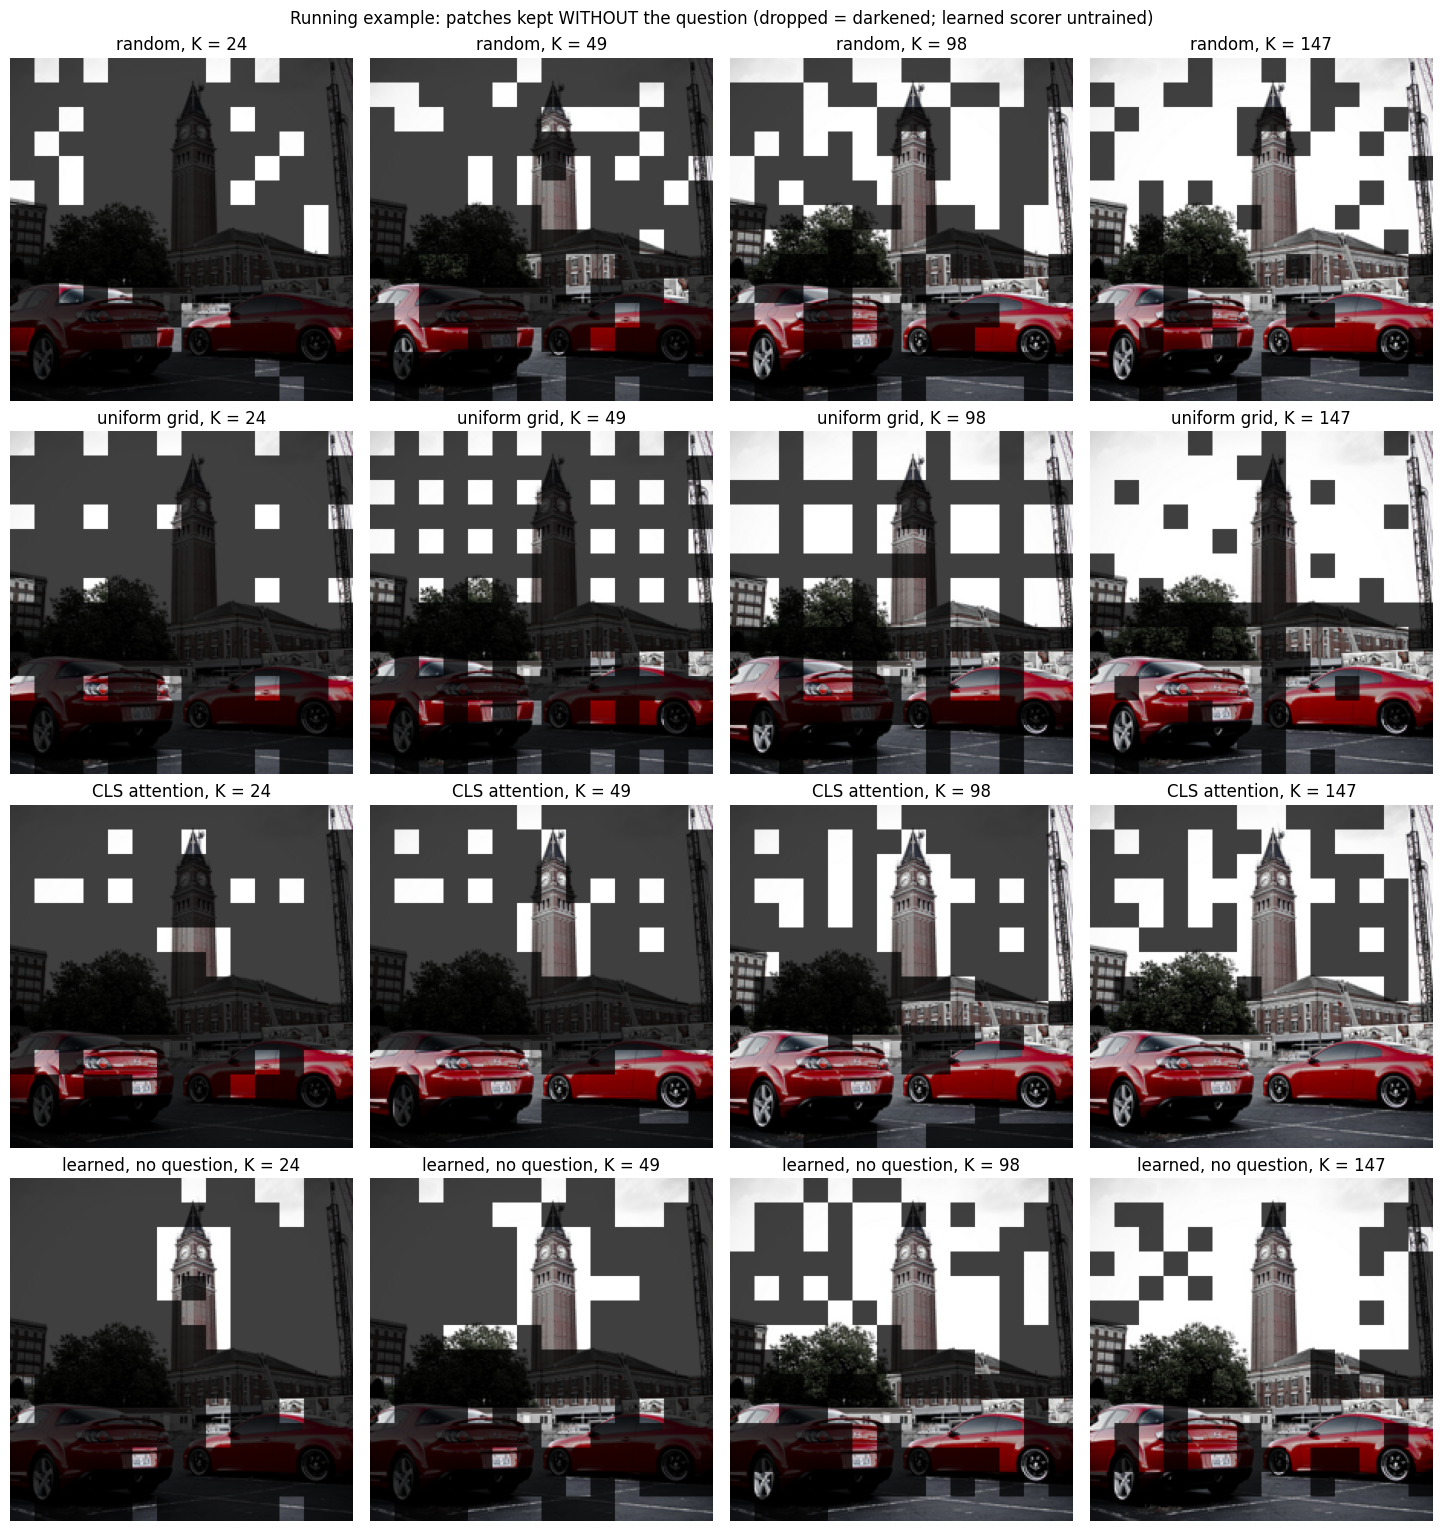

In [110]:
# 11.5 — The four variants behind one interface, and the patches each one keeps
FIXED_VARIANTS = ("random", "uniform grid", "CLS attention", "learned, no question")
DIM_DROPPED = 0.25   # display only: brightness of the dropped patches in the figure


def fixed_indices(variant: str, k: int, V: torch.Tensor, cls_attn: torch.Tensor, generator: torch.Generator = None):
    # → (B, K) indices in spatial order, on V.device. V (B, 196, 768), cls_attn (B, 196) from the cache (6.4).
    # The question is NOT an argument: no variant can depend on it.
    B = V.shape[0]
    if variant == "uniform grid":
        return uniform_grid_indices(k).to(V.device).expand(B, -1)        # the same positions for every image
    if variant == "random":
        scores = random_scores(B, generator)
    elif variant == "CLS attention":
        scores = cls_attn.float()
    elif variant == "learned, no question":
        scores = blind_scorer(V)
    else:
        raise ValueError(f"unknown variant: {variant!r}")
    return select_topk(scores.to(V.device), k)


# ---- 1. Running example: indices of every (variant, K), and V (1, 196, 768) → V_K (1, K, 768)
viz_gen = torch.Generator().manual_seed(cfg.seed)
kept_ex = {}                                                            # (variant, K) → (K,) indices
with torch.no_grad():
    for variant in FIXED_VARIANTS:
        for k in cfg.k_fixed:
            kept_ex[(variant, k)] = fixed_indices(variant, k, ex_V, example_feats["cls_attn"], viz_gen)[0].cpu()
for k in cfg.k_fixed:
    show(f"V_K, K = {k} (1×{k}×768)", gather_tokens(ex_V, kept_ex[("CLS attention", k)][None].to(DEVICE)))

# ---- 2. Figure: kept patches at full brightness, dropped patches darkened
fig, axes = plt.subplots(len(FIXED_VARIANTS), len(cfg.k_fixed),
                         figsize=(3.6 * len(cfg.k_fixed), 3.8 * len(FIXED_VARIANTS)), squeeze=False, layout="constrained")
for r, variant in enumerate(FIXED_VARIANTS):
    for c, k in enumerate(cfg.k_fixed):
        keep = torch.zeros(cfg.n_patches).index_fill_(0, kept_ex[(variant, k)], 1.0)          # (196,) 1 = kept
        keep_px = keep.view(G, G).repeat_interleave(P, dim=0).repeat_interleave(P, dim=1)     # (224, 224), block by block
        axes[r, c].imshow((seen_by_clip * (DIM_DROPPED + (1 - DIM_DROPPED) * keep_px[..., None])).numpy())
        axes[r, c].set_title(f"{variant}, K = {k}")
        axes[r, c].axis("off")
fig.suptitle("Running example: patches kept WITHOUT the question (dropped = darkened; learned scorer untrained)")
fig.savefig(cfg.path("fig", "11_5_fixed_topk.png"), dpi=120, bbox_inches="tight")
plt.show()

### 11.6 Section 11 checks

1. **Mechanics** (PLAN): for every K of `cfg.k_buckets`, on random scores of the train batch (9.1): K indices, unique, sorted, in [0, 196); the kept scores are the K largest (smallest kept ≥ largest dropped). `gather_tokens` = advanced indexing. With K = 196, $V_K = V$ exactly. **Control**: without the sort, the K = 196 selection is a permutation of V, not V.
2. **Every variant, every K** (PLAN), on the train batch: shape (B, K), integer indices on the device of V, unique, sorted, in [0, 196).
3. **Uniform grid**: the same positions for every image; K = 49 gives exactly a 7×7 grid (7 rows × 7 columns); K = 196 gives every patch.
4. **Random**: same seed → same selection, another seed → another one. Over `N_RANDOM_DRAWS` draws, each patch is kept with a frequency close to $p = K / 196$: within 5 standard deviations of a binomial proportion, $5 \sqrt{p(1-p)/n}$. A systematic bias (for example a selection that favours the small indices) would exceed it.
5. **CLS attention**: the indices are the Top-K of `cls_attn` (smallest kept ≥ largest dropped, for each image).
6. **Learned scorer**: parameters and FLOPs = formulas; a finite, non-zero gradient on every parameter tensor (weighted loss, as in 9.6) and none on V; shuffling the patches shuffles the scores.
7. **No question information** (PLAN): `fixed_indices` and `PatchMLPScorer.forward` take no question argument; on the 5 questions asked about the running-example image (same V, as in 9.6), the three deterministic variants give the same selection for every question. **Negative control**: scorer A (9.2), which reads the question, gives different selections on the same 5 questions, so this test would detect a question leaking in.
8. **Visualization** (PLAN): one panel per (variant, K), each with exactly K distinct patches; the figure is saved.
9. No NaN / inf in the scores.

In [111]:
# 11.6 — Section 11 checks
import inspect

N_RANDOM_DRAWS = 1000   # check setting: random selections drawn to measure how often each patch is kept
K_SQUARE = 49           # check setting: a bucket that is a perfect square (7²) → the uniform grid must be exactly 7×7
checks = {}
n_batch = len(batch_df)
batch_cls = clip_feats["train"]["cls_attn"][batch_rows].to(DEVICE)    # (B, 196): same images as batch_V (9.1)


def well_formed(idx: torch.Tensor, B: int, k: int) -> bool:
    # (B, K) integer indices in [0, 196), strictly increasing along each row (→ unique AND sorted)
    return (idx.shape == (B, k) and not idx.is_floating_point()
            and bool((idx >= 0).all() and (idx < cfg.n_patches).all() and (idx[:, 1:] > idx[:, :-1]).all()))


def is_topk(scores: torch.Tensor, idx: torch.Tensor) -> bool:
    # For each row: every kept score ≥ every dropped score
    kept = torch.zeros_like(scores, dtype=torch.bool).scatter_(1, idx, True)
    return all(bool(scores[b][kept[b]].min() >= scores[b][~kept[b]].max())
               for b in range(len(scores)) if (~kept[b]).any())


# ---- 1. Mechanics
s_rand = random_scores(n_batch, torch.Generator().manual_seed(cfg.seed)).to(DEVICE)
checks["select_topk: (B, K), unique, sorted, in [0, 196), for every K"] = all(
    well_formed(select_topk(s_rand, k), n_batch, k) for k in cfg.k_buckets)
checks["select_topk keeps the K largest scores, for every K"] = all(
    is_topk(s_rand, select_topk(s_rand, k)) for k in cfg.k_buckets)
idx_mech = select_topk(s_rand, k_ex)
checks["gather_tokens = advanced indexing"] = torch.equal(
    gather_tokens(batch_V, idx_mech), batch_V[torch.arange(n_batch, device=DEVICE)[:, None], idx_mech])
checks["K = 196, sorted: V_K = V exactly (Full Tokens)"] = torch.equal(
    gather_tokens(batch_V, select_topk(s_rand, cfg.n_patches)), batch_V)
checks["control: K = 196 unsorted is a permutation of V, not V"] = not torch.equal(
    gather_tokens(batch_V, s_rand.topk(cfg.n_patches, dim=-1).indices), batch_V)

# ---- 2. Every variant, every K, on the train batch
with torch.no_grad():
    for variant in FIXED_VARIANTS:
        ok = True
        for k in cfg.k_buckets:
            idx = fixed_indices(variant, k, batch_V, batch_cls, torch.Generator().manual_seed(cfg.seed))
            ok = ok and well_formed(idx, n_batch, k) and idx.device == batch_V.device
        checks[f"{variant}: (B, K) sorted unique indices on V's device, for every K"] = ok

# ---- 3. Uniform grid
grid_sq = uniform_grid_indices(K_SQUARE)
side = math.isqrt(K_SQUARE)
checks["uniform grid: the same positions for every image"] = bool(
    (fixed_indices("uniform grid", k_ex, batch_V, batch_cls) == uniform_grid_indices(k_ex).to(DEVICE)).all())
checks[f"uniform grid: K = {K_SQUARE} → a {side}×{side} grid"] = (
    len(grid_sq) == K_SQUARE and len(set((grid_sq // G).tolist())) == side and len(set((grid_sq % G).tolist())) == side)
checks["uniform grid: K = 196 → every patch"] = torch.equal(
    uniform_grid_indices(cfg.n_patches), torch.arange(cfg.n_patches))

# ---- 4. Random
draw = lambda seed: fixed_indices("random", k_ex, batch_V, batch_cls, torch.Generator().manual_seed(seed))
checks["random: same seed → same selection"] = torch.equal(draw(cfg.seed), draw(cfg.seed))
checks["random: another seed → another selection"] = not torch.equal(draw(cfg.seed), draw(cfg.seed + 1))
draws = select_topk(random_scores(N_RANDOM_DRAWS, torch.Generator().manual_seed(cfg.seed)), k_ex)   # (n, K)
freq = torch.bincount(draws.flatten(), minlength=cfg.n_patches) / N_RANDOM_DRAWS                    # (196,)
p_keep = k_ex / cfg.n_patches
tol = 5 * math.sqrt(p_keep * (1 - p_keep) / N_RANDOM_DRAWS)
print(f"Random, K = {k_ex}, {N_RANDOM_DRAWS} draws: frequency of each patch ∈ [{freq.min():.3f}, {freq.max():.3f}], "
      f"expected {p_keep:.3f} ± {tol:.3f} (5σ)")
checks["random: each patch kept with frequency K/196 ± 5σ"] = bool(((freq - p_keep).abs() < tol).all())

# ---- 5. CLS attention
checks["CLS attention: indices = Top-K of cls_attn, for every K"] = all(
    is_topk(batch_cls.float(), fixed_indices("CLS attention", k, batch_V, batch_cls)) for k in cfg.k_buckets)

# ---- 6. Learned scorer
d, dv = cfg.selector_dim, cfg.d_vision
checks["learned: parameters = formula d_v·d + d + d"] = count_params(blind_scorer)[1] == dv * d + d + d
checks["learned: FLOPs (FlopCounterMode) = formula"] = blind_flops == blind_flops_formula
# Weighted loss, as in 9.6: a gradient that reaches every weight
w_loss = torch.randn(n_batch, cfg.n_patches, generator=torch.Generator().manual_seed(cfg.seed)).to(DEVICE)
blind_scorer.zero_grad(set_to_none=True)
(blind_scorer(batch_V) * w_loss).sum().backward()
no_grad = [n for n, p in blind_scorer.named_parameters()
           if p.grad is None or not torch.isfinite(p.grad).all() or p.grad.abs().sum() == 0]
if no_grad:
    print(f"learned: parameters without a (finite, non-zero) gradient: {no_grad}")
checks[f"learned: finite, non-zero gradient on all {len(list(blind_scorer.parameters()))} parameter tensors"] = not no_grad
checks["learned: input V carries no gradient (CLIP stays frozen)"] = not batch_V.requires_grad
blind_scorer.zero_grad(set_to_none=True)
checks["learned: shuffling the patches shuffles the scores"] = perm_err < MATCH_TOL

# ---- 7. No question information
fixed_args = list(inspect.signature(fixed_indices).parameters)
blind_args = list(inspect.signature(blind_scorer.forward).parameters)
print(f"\nArguments: fixed_indices{tuple(fixed_args)}, PatchMLPScorer.forward{tuple(blind_args)}")
checks["no question argument in fixed_indices nor in PatchMLPScorer.forward"] = not (
    {"q", "question", "questions"} & set(fixed_args + blind_args))
img_cls = example_feats["cls_attn"].expand(len(batch_questions), -1)    # the running-example image, once per question
with torch.no_grad():
    for variant in ("uniform grid", "CLS attention", "learned, no question"):
        idx = fixed_indices(variant, k_ex, img_V, img_cls)
        checks[f"{variant}: same image, {len(batch_questions)} questions → same selection"] = bool((idx == idx[:1]).all())
    idx_a_q = select_topk(scorer_a(img_V, img_q), k_ex)                    # scorer A reads the question
n_distinct = len({tuple(row) for row in idx_a_q.tolist()})
print(f"Negative control: scorer A gives {n_distinct} distinct top-{k_ex} selections for the {len(batch_questions)} questions")
checks["negative control: scorer A (reads the question) → the selections differ"] = n_distinct > 1

# ---- 8. Visualization
checks["figure: one panel per (variant, K), each with exactly K distinct patches"] = (
    len(kept_ex) == len(FIXED_VARIANTS) * len(cfg.k_fixed)
    and all(len(set(idx.tolist())) == k for (_, k), idx in kept_ex.items()))
checks["figure saved"] = cfg.path("fig", "11_5_fixed_topk.png").exists()

# ---- 9. Finite values
checks["no NaN / inf in the scores"] = all(
    torch.isfinite(s.float()).all().item() for s in (s_blind_ex, s_blind_batch, batch_cls, ana_attn))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 11 check failed: do not move on to section 12."
print("\nSection 11 validated → we can move on to section 12.")

Random, K = 24, 1000 draws: frequency of each patch ∈ [0.094, 0.156], expected 0.122 ± 0.052 (5σ)

Arguments: fixed_indices('variant', 'k', 'V', 'cls_attn', 'generator'), PatchMLPScorer.forward('V',)
Negative control: scorer A gives 5 distinct top-24 selections for the 5 questions

✅ select_topk: (B, K), unique, sorted, in [0, 196), for every K
✅ select_topk keeps the K largest scores, for every K
✅ gather_tokens = advanced indexing
✅ K = 196, sorted: V_K = V exactly (Full Tokens)
✅ control: K = 196 unsorted is a permutation of V, not V
✅ random: (B, K) sorted unique indices on V's device, for every K
✅ uniform grid: (B, K) sorted unique indices on V's device, for every K
✅ CLS attention: (B, K) sorted unique indices on V's device, for every K
✅ learned, no question: (B, K) sorted unique indices on V's device, for every K
✅ uniform grid: the same positions for every image
✅ uniform grid: K = 49 → a 7×7 grid
✅ uniform grid: K = 196 → every patch
✅ random: same seed → same selection
✅ ra

## Section 12. Question-Conditioned Top-K

**Goal**: plug the scorers of section 9 into the Top-K mechanics of section 11, and make the whole selector **trainable**.

$$
V, q \;\xrightarrow{\ \text{scorer A / B / C}\ }\; \ell \in \mathbb{R}^{B \times 196}
\;\xrightarrow{\ +\ \sigma g\ \text{(Gumbel, training only)}\ }\;
\text{Top-K} \to \text{sort} \to \text{gather}
\;\xrightarrow{\ \times\ \text{straight-through gate}\ }\; V_K \in \mathbb{R}^{B \times K \times 768}
$$

**The difficulty**: Top-K chooses *integers*. The loss of the LLM (section 16) depends on which tokens are kept, but no gradient can flow back through that choice to the weights of the scorer. This section shows the problem, then the standard fixes:

| Subsection | Concept (PLAN) |
|---|---|
| 12.1 | The non-differentiability of Top-K: why no gradient goes through the choice of indices |
| 12.2 | Soft gating, and its mismatch with inference: a token multiplied by 0.1 is not a removed token |
| 12.3 | The Straight-Through Estimator: the forward pass is exact, the gradient still flows |
| 12.4 | The Gumbel perturbation: explore the tokens that are never selected |
| 12.5 | The complete selector module, for the three scorers |
| 12.6 | Section checks |

**Nothing is trained here**, as in sections 9 and 11: the scorers keep their seeded random weights. The selector is trained in phase C of section 18. The loss used below is a **stand-in** for the loss of the LLM: a fixed random linear read-out of the selected tokens. It is enough to check that gradients flow where they should.

### 12.1 Top-K is not differentiable

**Goal**: see exactly where the gradient stops.

The scorer influences the loss only through the indices: $\mathcal{L}(V_K)$, $V_K = \mathrm{gather}(V, \mathrm{idx})$, $\mathrm{idx} = \mathrm{TopK}(s, K)$.

* **`gather` is differentiable with respect to V, not to `idx`** (11.1). And V is the frozen CLIP cache: it requires no gradient. So $V_K$ is not connected to the weights of the scorer at all, and `backward()` raises an error.
* **Even mathematically, the derivative is useless.** $\mathrm{idx}(s)$ is a **step function** of the scores. A small change of $s$ leaves the indices unchanged (derivative 0). When the $(K{+}1)$-th score overtakes the $K$-th one, the indices jump (derivative undefined). So $\partial \mathcal{L} / \partial s = 0$ almost everywhere: it never says which patch would have been worth keeping.

The cell shows both: the autograd graph stops at `topk`, and a perturbation smaller than half the gap between the $K$-th and the $(K{+}1)$-th score changes nothing, while one that crosses the gap makes the indices jump.

In [112]:
# 12.1 — Top-K is not differentiable: no gradient reaches the scorer through the indices
s_a = scorer_a(batch_V, batch_q)                         # (B, 196), depends on the weights of A → requires grad
idx_a = select_topk(s_a, k_ex)                           # (B, K) int64
V_K_a = gather_tokens(batch_V, idx_a)                    # (B, K, 768)
show("s_A (B×196)", s_a)
show("indices (B×K)", idx_a)
show("V_K (B×K×768)", V_K_a)
print(f"s_A    : requires_grad = {s_a.requires_grad}, grad_fn = {type(s_a.grad_fn).__name__}")
print(f"indices: dtype = {idx_a.dtype}, requires_grad = {idx_a.requires_grad}, grad_fn = {idx_a.grad_fn}")
print(f"V_K    : requires_grad = {V_K_a.requires_grad}  → the graph from the weights of A stops at topk")

try:
    (V_K_a.sum()).backward()
    backward_error = None
except RuntimeError as e:
    backward_error = str(e)
print(f"V_K.sum().backward() → RuntimeError: {backward_error}")

# ---- The indices are a step function of the scores
s_det = s_a.detach()
top = s_det.topk(k_ex + 1, dim=-1)                                    # the K + 1 largest, in decreasing order
gap = top.values[:, k_ex - 1] - top.values[:, k_ex]                  # (B,) K-th minus (K+1)-th score
u = 2 * torch.rand(s_det.shape, generator=torch.Generator().manual_seed(cfg.seed)).to(DEVICE) - 1   # U(-1, 1)
# Every score moves by less than gap / 2: no dropped score can overtake a kept one
topk_flat = torch.equal(select_topk(s_det + 0.4 * gap[:, None] * u, k_ex), idx_a)
# Push the (K+1)-th score just above the K-th: it enters, the K-th leaves
crossed = s_det.clone()
crossed[torch.arange(len(crossed), device=DEVICE), top.indices[:, k_ex]] += 1.01 * gap
topk_jump = (select_topk(crossed, k_ex) != idx_a).any(dim=1).all().item()
print(f"\nGap between the K-th and the (K+1)-th score, per question: {[f'{g:.1e}' for g in gap.tolist()]}")
print(f"Every score moved by < gap/2       → same indices: {topk_flat}  (derivative 0)")
print(f"(K+1)-th score pushed past the K-th → indices jump in every row: {topk_jump}  (derivative undefined)")

s_A (B×196)                  (4, 196)           float32   cpu  min=+0.004 max=+0.006 mean=+0.005 std=0.000
indices (B×K)                (4, 24)            int64     cpu
V_K (B×K×768)                (4, 24, 768)       float32   cpu  min=-17.516 max=+86.625 mean=-0.010 std=0.892
s_A    : requires_grad = True, grad_fn = SqueezeBackward1
indices: dtype = torch.int64, requires_grad = False, grad_fn = None
V_K    : requires_grad = False  → the graph from the weights of A stops at topk
V_K.sum().backward() → RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

Gap between the K-th and the (K+1)-th score, per question: ['1.2e-05', '2.5e-05', '1.4e-06', '2.3e-05']
Every score moved by < gap/2       → same indices: True  (derivative 0)
(K+1)-th score pushed past the K-th → indices jump in every row: True  (derivative undefined)


### 12.2 Soft gating, and why it does not match inference

**The natural fix**: instead of dropping tokens, keep all 196 and multiply each one by a differentiable weight, $\tilde v_i = p_i\, v_i$ with $p = \mathrm{softmax}(\ell)$. The gradient now reaches the scorer. But the model is **trained on something else than what it is evaluated on**:

1. **Training sees 196 tokens, inference sees K.** The projector and LoRA learn on sequences of length 196 with rescaled tokens, then are evaluated on K unscaled tokens.
2. **A token multiplied by 0.1 is not a removed token.** Every Qwen block starts with an RMSNorm, applied to each token separately:
$$
\mathrm{RMSNorm}(x) = \frac{x}{\sqrt{\tfrac{1}{D}\sum_f x_f^2 + \epsilon}} \odot \gamma
\quad\Rightarrow\quad \mathrm{RMSNorm}(c\,x) \approx \mathrm{RMSNorm}(x)\ \ \text{for any } c > 0
$$
The keys and values that attention computes from a "nearly dropped" token are therefore almost those of the full token: the LLM still **sees** it, and can learn to rely on it. At inference, it is gone. (Our scorers do the same with their LayerNorm, 9.2.) Between the selector and Qwen sits the projector, whose biases break exact scale invariance, but nothing forces the model to treat a small token as absent.

The cell measures the relative change caused by a factor of 0.1 after a LayerNorm and an RMSNorm, then checks that soft gating does let the gradient reach the scorer, with all 196 tokens still in the sequence.

In [113]:
# 12.2 — Soft gating: differentiable, but a token multiplied by 0.1 is not a removed token
GATE = 0.1                                                     # display only: the weight of a "nearly dropped" token
# Stand-in for the LLM loss in sections 12 – 13: a fixed random linear read-out of the tokens
probe = torch.randn(cfg.d_vision, generator=torch.Generator().manual_seed(cfg.seed)).to(DEVICE)

# ---- 1. After a normalization, a token scaled by 0.1 is (almost) the same token
v_ex = ex_V[0]                                                 # (196, 768), running example
norm_err = {
    "LayerNorm (our scorers, 9.2)": rel_err(F.layer_norm(GATE * v_ex, (cfg.d_vision,)), F.layer_norm(v_ex, (cfg.d_vision,))),
    "RMSNorm (input of every Qwen block)": rel_err(F.rms_norm(GATE * v_ex, (cfg.d_vision,)), F.rms_norm(v_ex, (cfg.d_vision,))),
}
print(f"Relative change of the token after normalization when it is multiplied by {GATE}:")
for name, err in norm_err.items():
    print(f"   {name:<38} {err:.1e}   (before normalization: {1 - GATE:.1f})")

# ---- 2. Soft gating lets the gradient reach the scorer, but keeps every token
p_soft = scorer_a(batch_V, batch_q)                            # (B, 196): A is already a distribution over the patches
V_soft = batch_V * p_soft.unsqueeze(-1)                        # (B, 196, 768): every token kept, rescaled
scorer_a.zero_grad(set_to_none=True)
(V_soft @ probe).sum().backward()
soft_grad_ok = all(prm.grad is not None and prm.grad.abs().sum() > 0 for prm in scorer_a.parameters())
scorer_a.zero_grad(set_to_none=True)
print()
show("soft-gated tokens (B×196×768)", V_soft)
show("hard selection (B×K×768)", V_K_a)
print(f"Soft gating: gradient on every parameter of A = {soft_grad_ok}, "
      f"but the sequence keeps {V_soft.shape[1]} tokens in training vs {V_K_a.shape[1]} at inference")

Relative change of the token after normalization when it is multiplied by 0.1:
   LayerNorm (our scorers, 9.2)           3.4e-03   (before normalization: 0.9)
   RMSNorm (input of every Qwen block)    4.1e-05   (before normalization: 0.9)

soft-gated tokens (B×196×768) (4, 196, 768)      float32   cpu  min=-0.100 max=+0.495 mean=-0.000 std=0.003
hard selection (B×K×768)     (4, 24, 768)       float32   cpu  min=-17.516 max=+86.625 mean=-0.010 std=0.892
Soft gating: gradient on every parameter of A = True, but the sequence keeps 196 tokens in training vs 24 at inference


### 12.3 The Straight-Through Estimator (STE)

**Idea**: use the **hard** selection in the forward pass (exactly the K tokens, exactly unchanged: what inference will do), and **pretend** in the backward pass that each kept token was multiplied by a soft weight. For the $j$-th kept token, patch $i_j$:

$$
g_j = 1 + \big(p_{i_j} - \mathrm{sg}(p_{i_j})\big), \qquad V_K[j] = g_j\, v_{i_j}, \qquad p = \mathrm{softmax}(\ell)
$$

where $\mathrm{sg}$ is the stop-gradient (`.detach()`).

* **Forward**: $x - x = 0$ exactly in floating point, so $g_j = 1$ **exactly** and $V_K$ is bit-for-bit the hard selection (checked in 12.6).
* **Backward**: $\mathrm{sg}$ has a zero derivative, so $\partial g_j / \partial \ell = \partial p_{i_j} / \partial \ell$. With $c_j = \partial \mathcal{L}/\partial g_j = \langle \partial \mathcal{L}/\partial V_K[j],\ v_{i_j} \rangle$ ("would the loss go down if token $j$ weighed a bit more?"):
$$
\frac{\partial \mathcal{L}}{\partial \ell_i} = \sum_j c_j\, p_{i_j}\big(\mathbb{1}[i = i_j] - p_i\big)
$$
Every **kept** patch gets a gradient. The dropped ones also get one, through the normalization of the softmax ($-p_i \sum_j c_j p_{i_j}$), but it only says "make room for the kept ones": the STE cannot tell whether a dropped patch would have helped. That is the job of the Gumbel noise (12.4).
* It is a **biased** estimator, a heuristic: the true derivative is 0 (12.1). It is the standard choice for hard token selection, and it works well in practice.

**Logits for the three scorers.** $p$ must be a distribution over the patches, so each scorer's output is turned into logits $\ell$ first:

| Scorer | Output (section 9) | Logits $\ell$ | Why |
|---|---|---|---|
| A | a distribution $s$ | $\log s$ | $\mathrm{softmax}(\log s) = s$: A's scores are directly $p$ |
| B | unbounded logits | $s$ | already logits |
| C | a cosine in $[-1, 1]$ | $s / \tau$, $\tau$ = `cfg.cosine_temperature` | a softmax over values in $[-1, 1]$ would be almost uniform (9.4) |

The Top-K is taken on $\ell$. It is the same ranking as on $s$ (log and division by $\tau > 0$ are increasing).

In [114]:
# 12.3 — Straight-Through Estimator: exact hard selection forward, soft gradient backward
TO_LOGITS = {   # scorer output (B, 196) → logits ℓ (B, 196), so that softmax(ℓ) is a distribution over the patches
    "A": lambda s: s.clamp_min(torch.finfo(s.dtype).tiny).log(),   # s is a distribution: softmax(log s) = s
    "B": lambda s: s,                                               # already unbounded logits
    "C": lambda s: s / cfg.cosine_temperature,                      # cosine ∈ [-1, 1] → sharper logits
}


def straight_through_gather(V: torch.Tensor, logits: torch.Tensor, idx: torch.Tensor) -> torch.Tensor:
    # V (B, 196, D), logits (B, 196), idx (B, K) → V_K (B, K, D), every token multiplied by a gate equal to 1 EXACTLY,
    # whose derivative is that of its softmax weight p
    p_K = logits.softmax(dim=-1).gather(1, idx)          # (B, K): soft weight of each kept patch
    gate = 1.0 + (p_K - p_K.detach())                    # value: x − x = 0 exactly → 1; gradient: ∂p_K
    return gather_tokens(V, idx) * gate.unsqueeze(-1)


# ---- 1. Forward, scorer A on the train batch
logits_a = TO_LOGITS["A"](scorer_a(batch_V, batch_q))    # (B, 196)
logits_a.retain_grad()                                   # non-leaf tensor: keep its gradient to inspect it
idx_ste = select_topk(logits_a, k_ex)                    # (B, K): same indices as on s (log is increasing)
V_K_ste = straight_through_gather(batch_V, logits_a, idx_ste)
show("logits ℓ = log s_A (B×196)", logits_a)
show("V_K with STE (B×K×768)", V_K_ste)
print(f"softmax(log s_A) vs s_A: relative error = {rel_err(logits_a.softmax(dim=-1), s_a):.1e}")
print(f"same indices as Top-K on s_A: {torch.equal(idx_ste, idx_a)}")
print(f"forward: V_K with STE == hard selection, bit for bit: {torch.equal(V_K_ste, V_K_a)}")

# ---- 2. Backward: which logits receive a gradient?
scorer_a.zero_grad(set_to_none=True)
(V_K_ste @ probe).sum().backward()
kept = torch.zeros_like(logits_a, dtype=torch.bool).scatter_(1, idx_ste, True)    # (B, 196)
g_kept, g_drop = logits_a.grad[kept].abs(), logits_a.grad[~kept].abs()
print(f"\n∂L/∂ℓ on the {int(kept.sum())} kept patches   : non-zero for {(g_kept > 0).float().mean():.0%}, "
      f"mean |grad| = {g_kept.mean():.1e}")
print(f"∂L/∂ℓ on the {int((~kept).sum())} dropped patches: non-zero for {(g_drop > 0).float().mean():.0%}, "
      f"mean |grad| = {g_drop.mean():.1e}  (softmax normalization only)")
print("parameters of A with a non-zero gradient:",
      [n for n, prm in scorer_a.named_parameters() if prm.grad is not None and prm.grad.abs().sum() > 0])
scorer_a.zero_grad(set_to_none=True)

logits ℓ = log s_A (B×196)   (4, 196)           float32   cpu  min=-5.458 max=-5.051 mean=-5.281 std=0.069
V_K with STE (B×K×768)       (4, 24, 768)       float32   cpu  min=-17.516 max=+86.625 mean=-0.010 std=0.892
softmax(log s_A) vs s_A: relative error = 1.7e-07
same indices as Top-K on s_A: True
forward: V_K with STE == hard selection, bit for bit: True

∂L/∂ℓ on the 96 kept patches   : non-zero for 100%, mean |grad| = 4.4e-02
∂L/∂ℓ on the 688 dropped patches: non-zero for 100%, mean |grad| = 2.7e-03  (softmax normalization only)
parameters of A with a non-zero gradient: ['q_proj.weight', 'q_proj.bias', 'k_proj.weight', 'word_logit.weight']


### 12.4 The Gumbel perturbation: exploring the tokens never selected

**The problem left by the STE**: a patch that starts with a low score is never selected, so the loss never says whether it would have helped. Its score has no reason to go up.

**The Gumbel-max trick.** With $g_i = -\log(-\log u_i)$, $u_i \sim \mathcal{U}(0, 1)$ i.i.d.:
$$
\arg\max_i\ (\ell_i + g_i) \ \sim\ \mathrm{Categorical}\big(\mathrm{softmax}(\ell)\big)
$$
and the **Top-K** of $\ell + g$ is a sample of K patches *without replacement* from $\mathrm{softmax}(\ell)$ (the Gumbel-top-k trick, Kool et al., 2019). Every patch now has a chance of being selected, proportional to its current weight: low-score patches get tried from time to time, and the STE gives them a gradient when they are.

**The scale σ is a temperature.** $\mathrm{TopK}(\ell + \sigma g) = \mathrm{TopK}(\ell/\sigma + g)$: a sample from $\mathrm{softmax}(\ell / \sigma)$.

* large σ: almost random selection (exploration);
* $\sigma \to 0$: the deterministic Top-K (exploitation), which is what inference does.

So σ **decreases during training**, linearly from `cfg.gumbel_scale_start` to `cfg.gumbel_scale_end` (`gumbel_scale`, used in section 18). At evaluation, σ = 0. The same noisy logits are used for the selection **and** for the soft weights of the STE, so the gradient refers to the selection that was actually made.

The cell checks the Gumbel-max trick empirically on 5 toy logits, then counts how many different patches of the running example get selected over a few draws, with and without noise.

In [115]:
# 12.4 — Gumbel perturbation: a stochastic Top-K that explores
N_GUMBEL_DRAWS = 2000                                       # check setting: draws for the Gumbel-max frequencies
N_EXPLORE_DRAWS = 20                                        # display only: draws on the running example
GUMBEL_TOY_LOGITS = torch.tensor([2.0, 1.0, 0.5, 0.0, -1.0])   # display only: 5 logits for the Gumbel-max trick


def gumbel_noise(shape, generator: torch.Generator) -> torch.Tensor:
    # i.i.d. Gumbel(0, 1) = −log(−log u), u ~ U(0, 1), on CPU (where the generator lives). u = 0 would give −inf.
    u = torch.rand(shape, generator=generator).clamp_min(torch.finfo(torch.float32).tiny)
    return -torch.log(-torch.log(u))


def gumbel_scale(progress: float) -> float:
    # Noise scale σ at a given fraction of training, progress ∈ [0, 1] (section 18). σ = 0 at evaluation.
    return cfg.gumbel_scale_start + progress * (cfg.gumbel_scale_end - cfg.gumbel_scale_start)


# ---- 1. Gumbel-max: argmax(ℓ + g) is distributed as softmax(ℓ)
gen = torch.Generator().manual_seed(cfg.seed)
winners = (GUMBEL_TOY_LOGITS + gumbel_noise((N_GUMBEL_DRAWS, len(GUMBEL_TOY_LOGITS)), gen)).argmax(dim=-1)
gm_freq = torch.bincount(winners, minlength=len(GUMBEL_TOY_LOGITS)) / N_GUMBEL_DRAWS
gm_prob = GUMBEL_TOY_LOGITS.softmax(dim=-1)
print(f"Gumbel-max over {N_GUMBEL_DRAWS} draws:")
print(f"   logits ℓ           : {GUMBEL_TOY_LOGITS.tolist()}")
print(f"   softmax(ℓ)         : {[round(x, 3) for x in gm_prob.tolist()]}")
print(f"   frequency of argmax: {[round(x, 3) for x in gm_freq.tolist()]}")

# ---- 2. Exploration on the running example (scorer A, untrained: nearly flat logits)
with torch.no_grad():
    logits_ex = TO_LOGITS["A"](scorer_a(ex_V, ex_q))                                   # (1, 196)
gen = torch.Generator().manual_seed(cfg.seed)
explore = {}
for sigma in (0.0, gumbel_scale(0.5), gumbel_scale(0.0)):
    sel = [select_topk(logits_ex + sigma * gumbel_noise(logits_ex.shape, gen).to(DEVICE), k_ex) for _ in range(N_EXPLORE_DRAWS)]
    explore[sigma] = (len({tuple(x[0].tolist()) for x in sel}), len(set(torch.cat(sel, dim=1)[0].tolist())))
print(f"\nRunning example, K = {k_ex}, {N_EXPLORE_DRAWS} draws:")
for sigma, (n_sel, n_patch) in explore.items():
    print(f"   σ = {sigma:.2f}: {n_sel:>2} distinct selections, {n_patch:>3} / {cfg.n_patches} patches selected at least once")

print(f"\nSchedule σ(progress): " + ", ".join(f"{x:.2f} → {gumbel_scale(x):.2f}" for x in (0.0, 0.25, 0.5, 0.75, 1.0)))

Gumbel-max over 2000 draws:
   logits ℓ           : [2.0, 1.0, 0.5, 0.0, -1.0]
   softmax(ℓ)         : [0.563, 0.207, 0.126, 0.076, 0.028]
   frequency of argmax: [0.57, 0.204, 0.126, 0.071, 0.03]

Running example, K = 24, 20 draws:
   σ = 0.00:  1 distinct selections,  24 / 196 patches selected at least once
   σ = 0.50: 20 distinct selections, 183 / 196 patches selected at least once
   σ = 1.00: 20 distinct selections, 187 / 196 patches selected at least once

Schedule σ(progress): 0.00 → 1.00, 0.25 → 0.75, 0.50 → 0.50, 0.75 → 0.25, 1.00 → 0.00


### 12.5 The complete selector

`QuestionConditionedSelector` wraps one scorer (A, B or C, with its weights of section 9) and chains the steps of this section:

| Step | Shape | Gradient |
|---|---|---|
| scorer → logits $\ell$ (12.3) | (B, 196) | yes |
| $+\ \sigma g$ if `noise_scale > 0` (12.4) | (B, 196) | (noise: none) |
| Top-K → sort (11.1) | idx (B, K) | no: integers |
| gather × straight-through gate (12.3) | $V_K$ (B, K, 768) | yes, through the gate |

* `noise_scale` is passed explicitly, never read from a global: σ = `gumbel_scale(progress)` in training, 0 (the default) at evaluation.
* The generator of the noise is passed explicitly too, as for the random baseline (11.2): same seed, same draws.
* `logits(V, q)` is a separate method because section 13 needs the clean logits of the selector (the budget is decided from them).

This is the "Selector → Top-K" part of the running-example table: V (196×768) and the question → s (196) → K indices → $V_K$ (K×768). The figure shows the patches kept for the running example by each scorer, without noise and for two Gumbel draws. The weights are untrained: the patches mean nothing yet. The figure is redone with the trained selector in section 21.

V (1×196×768)                (1, 196, 768)      float32   cpu  min=-17.441 max=+89.325 mean=-0.012 std=0.711
Q (1×M×512)                  (1, 8, 512)        float32   cpu  min=-14.687 max=+30.578 mean=-0.072 std=1.122
s = logits (1×196)           (1, 196)           float32   cpu  min=-5.465 max=-5.091 mean=-5.280 std=0.066
indices (1×K)                (1, 24)            int64     cpu
V_K (1×K×768)                (1, 24, 768)       float32   cpu  min=-17.441 max=+89.325 mean=-0.008 std=1.240


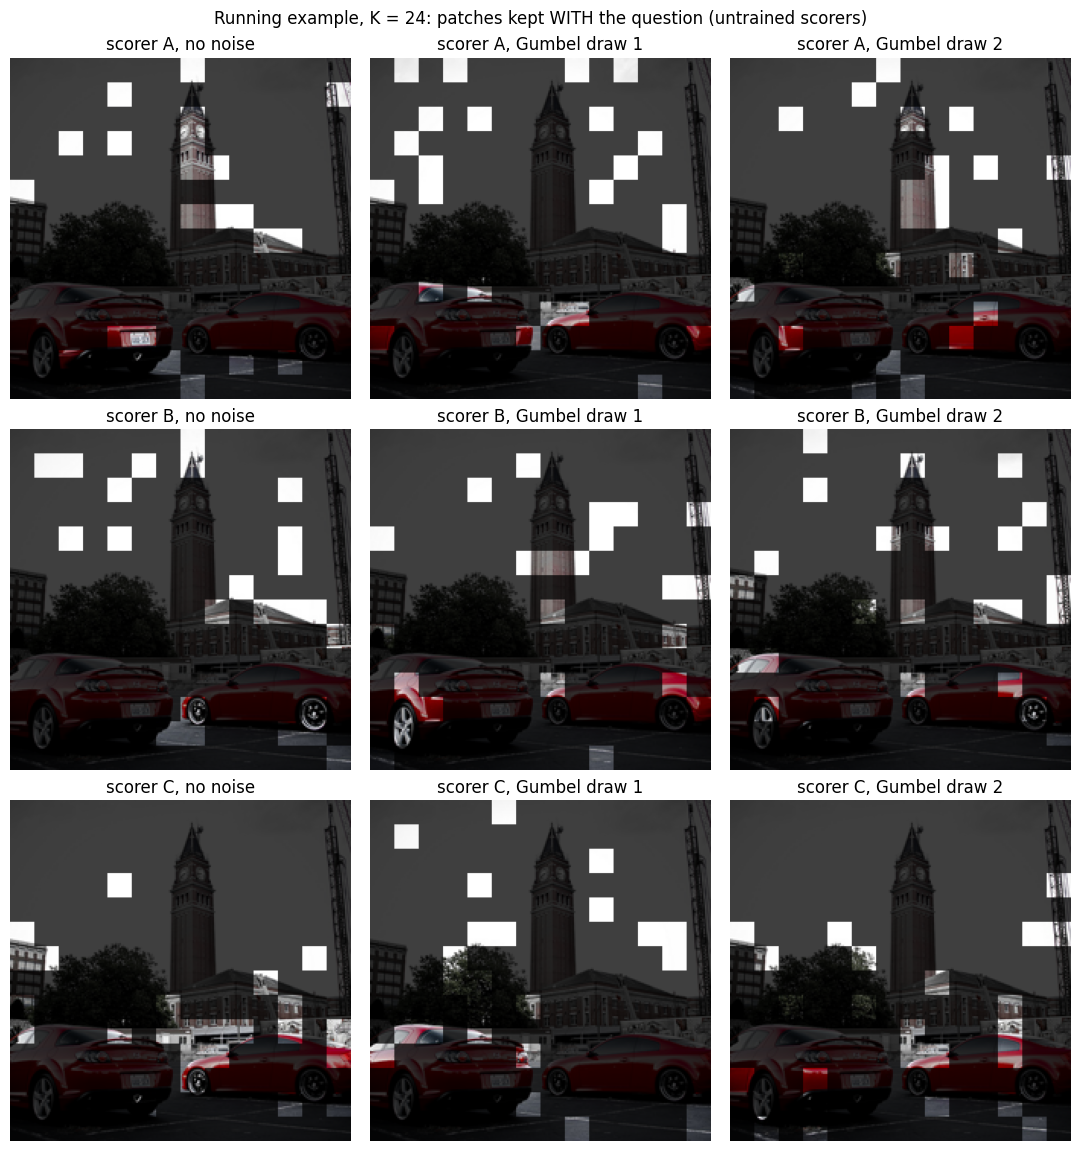

In [116]:
# 12.5 — The selector: scorer → logits → (+ Gumbel) → Top-K → sort → gather with a straight-through gate

class QuestionConditionedSelector(nn.Module):
    # Wraps scorer A, B or C (section 9). forward(V, q, k) → {"idx": (B, K), "V_K": (B, K, 768)}

    def __init__(self, scorer: nn.Module, kind: str):
        super().__init__()
        self.scorer, self.kind = scorer, kind

    def logits(self, V: torch.Tensor, q: dict) -> torch.Tensor:
        return TO_LOGITS[self.kind](self.scorer(V, q))                       # (B, 196)

    def forward(self, V: torch.Tensor, q: dict, k: int, noise_scale: float = 0.0, generator=None) -> dict:
        logits = self.logits(V, q)
        if noise_scale > 0:                                                  # training only (12.4)
            logits = logits + noise_scale * gumbel_noise(logits.shape, generator).to(logits.device)
        idx = select_topk(logits, k)                                         # (B, K) spatial order, no gradient
        return {"idx": idx, "V_K": straight_through_gather(V, logits, idx)}  # (B, K, 768), gradient via the gate


SELECTORS = {name: QuestionConditionedSelector(scorer, name) for name, scorer in SCORERS.items()}   # same weights

# ---- 1. Shape trace on the running example (scorer A, no noise)
with torch.no_grad():
    out_ex = SELECTORS["A"](ex_V, ex_q, k_ex)
show("V (1×196×768)", ex_V)
show("Q (1×M×512)", ex_q["Q"])
show("s = logits (1×196)", SELECTORS["A"].logits(ex_V, ex_q))
show("indices (1×K)", out_ex["idx"])
show("V_K (1×K×768)", out_ex["V_K"])

# ---- 2. Every scorer, no noise and two Gumbel draws (σ = gumbel_scale(0), the start of training)
gen = torch.Generator().manual_seed(cfg.seed)
SELECTOR_COLUMNS = ["no noise", "Gumbel draw 1", "Gumbel draw 2"]
kept_sel = {}                                                        # (scorer, column) → (K,) indices
with torch.no_grad():
    for name, selector in SELECTORS.items():
        for col in SELECTOR_COLUMNS:
            sigma = 0.0 if col == "no noise" else gumbel_scale(0.0)
            kept_sel[(name, col)] = selector(ex_V, ex_q, k_ex, noise_scale=sigma, generator=gen)["idx"][0].cpu()

fig, axes = plt.subplots(len(SELECTORS), len(SELECTOR_COLUMNS), figsize=(3.6 * len(SELECTOR_COLUMNS), 3.8 * len(SELECTORS)),
                         squeeze=False, layout="constrained")
for r, name in enumerate(SELECTORS):
    for c, col in enumerate(SELECTOR_COLUMNS):
        keep = torch.zeros(cfg.n_patches).index_fill_(0, kept_sel[(name, col)], 1.0)            # (196,) 1 = kept
        keep_px = keep.view(G, G).repeat_interleave(P, dim=0).repeat_interleave(P, dim=1)       # (224, 224)
        axes[r, c].imshow((seen_by_clip * (DIM_DROPPED + (1 - DIM_DROPPED) * keep_px[..., None])).numpy())
        axes[r, c].set_title(f"scorer {name}, {col}")
        axes[r, c].axis("off")
fig.suptitle(f'Running example, K = {k_ex}: patches kept WITH the question (untrained scorers)')
fig.savefig(cfg.path("fig", "12_5_conditioned_topk.png"), dpi=120, bbox_inches="tight")
plt.show()

### 12.6 Section 12 checks

1. **Top-K is not differentiable** (12.1): integer indices without `grad_fn`; $V_K$ requires no gradient and `backward()` fails; a perturbation smaller than half the gap leaves the indices unchanged, one that crosses it makes them jump.
2. **Soft gating** (12.2): after a LayerNorm or an RMSNorm, a token multiplied by 0.1 differs from the original by less than `REL_TOL`; soft gating gives a gradient to A but keeps 196 tokens.
3. **STE, forward** (PLAN): for A, B and C, with and without Gumbel noise, $V_K$ equals the hard selection **bit for bit** (`torch.equal`), and the gate is exactly 1.
4. **STE, backward** (PLAN): every kept patch receives a finite, non-zero gradient on its logit, for every scorer, and every parameter tensor of every scorer receives a finite, non-zero gradient. **Negative control**: without the STE (plain gather), $V_K$ is not connected to the scorer.
5. **Gumbel** (PLAN): with noise, the selection varies from one draw to the next; without noise, it is deterministic and equals the plain Top-K; the same seed gives the same draws. Gumbel-max frequencies match $\mathrm{softmax}(\ell)$ within 5 standard deviations; the noise explores more patches than the deterministic Top-K; the schedule goes from `gumbel_scale_start` to `gumbel_scale_end`.
6. **Selector**: for every scorer and every K of `cfg.k_buckets`, indices (B, K) unique, sorted, in [0, 196) (`well_formed`, 11.6), equal to the Top-K of the logits; $V_K$ (B, K, 768). For A, $\mathrm{softmax}(\log s) = s$. **The question enters**: on the 5 questions about the running-example image, each scorer gives at least two different selections (the opposite of section 11).
7. No NaN / inf.

In [117]:
# 12.6 — Section 12 checks
checks = {}

# ---- 1. Top-K is not differentiable
checks["indices: integers without grad_fn"] = not idx_a.is_floating_point() and idx_a.grad_fn is None
checks["plain gather: V_K not connected to the scorer, backward() fails"] = (
    not V_K_a.requires_grad and backward_error is not None)
checks["perturbation < gap/2 → same indices (step function: derivative 0)"] = topk_flat
checks["(K+1)-th score crosses the K-th → the indices jump"] = topk_jump

# ---- 2. Soft gating
for name, err in norm_err.items():
    checks[f"{name}: token × {GATE} ≈ token after normalization"] = err < REL_TOL
checks["soft gating: gradient reaches A, but 196 tokens kept"] = soft_grad_ok and V_soft.shape[1] == cfg.n_patches

# ---- 3 – 4. STE forward and backward, every scorer, with and without noise
n_batch = len(batch_df)
for name, selector in SELECTORS.items():
    for sigma in (0.0, gumbel_scale(0.0)):
        gen = torch.Generator().manual_seed(cfg.seed)
        selector.zero_grad(set_to_none=True)
        logits = selector.logits(batch_V, batch_q)
        if sigma > 0:
            logits = logits + sigma * gumbel_noise(logits.shape, gen).to(DEVICE)
        logits.retain_grad()
        idx = select_topk(logits, k_ex)
        V_K = straight_through_gather(batch_V, logits, idx)
        tag = f"{name}, σ = {sigma:.1f}"
        p_K = logits.softmax(dim=-1).gather(1, idx)
        checks[f"STE forward ({tag}): V_K = hard selection bit for bit, gate exactly 1"] = (
            torch.equal(V_K, gather_tokens(batch_V, idx)) and bool(((1.0 + (p_K - p_K.detach())) == 1).all()))
        (V_K @ probe).sum().backward()
        g_kept = logits.grad.gather(1, idx)                                      # (B, K)
        checks[f"STE backward ({tag}): every kept patch has a finite, non-zero gradient"] = bool(
            torch.isfinite(g_kept).all() and (g_kept != 0).all())
        bad = [n for n, prm in selector.named_parameters()
               if prm.grad is None or not torch.isfinite(prm.grad).all() or prm.grad.abs().sum() == 0]
        if bad:
            print(f"{tag}: parameters without a (finite, non-zero) gradient: {bad}")
        checks[f"STE backward ({tag}): gradient on all {len(list(selector.parameters()))} parameter tensors"] = not bad
        selector.zero_grad(set_to_none=True)
checks["negative control: without STE, no path from V_K to the scorer"] = not gather_tokens(
    batch_V, select_topk(SELECTORS["B"].logits(batch_V, batch_q), k_ex)).requires_grad

# ---- 5. Gumbel
with torch.no_grad():
    sel = lambda sigma, seed: SELECTORS["A"](batch_V, batch_q, k_ex, noise_scale=sigma,
                                             generator=torch.Generator().manual_seed(seed))["idx"]
    checks["Gumbel: two draws (different seeds) → different selections"] = not torch.equal(
        sel(gumbel_scale(0.0), cfg.seed), sel(gumbel_scale(0.0), cfg.seed + 1))
    checks["Gumbel: same seed → same selection"] = torch.equal(sel(gumbel_scale(0.0), cfg.seed),
                                                               sel(gumbel_scale(0.0), cfg.seed))
    checks["no noise: deterministic, = plain Top-K of the logits"] = (
        torch.equal(sel(0.0, cfg.seed), sel(0.0, cfg.seed + 1))
        and torch.equal(sel(0.0, cfg.seed), select_topk(SELECTORS["A"].logits(batch_V, batch_q), k_ex)))
gm_tol = 5 * torch.sqrt(gm_prob * (1 - gm_prob) / N_GUMBEL_DRAWS)
print(f"Gumbel-max: max |frequency − softmax| = {(gm_freq - gm_prob).abs().max():.3f}, 5σ tolerance ≥ {gm_tol.min():.3f}")
checks["Gumbel-max: argmax frequencies = softmax(ℓ) ± 5σ"] = bool(((gm_freq - gm_prob).abs() < gm_tol).all())
checks["Gumbel explores: more patches tried than the deterministic Top-K"] = (
    explore[0.0] == (1, k_ex) and explore[gumbel_scale(0.0)][1] > k_ex)
checks["schedule: σ(0) = gumbel_scale_start, σ(1) = gumbel_scale_end, non-increasing"] = (
    gumbel_scale(0.0) == cfg.gumbel_scale_start and math.isclose(gumbel_scale(1.0), cfg.gumbel_scale_end, abs_tol=1e-12)
    and all(gumbel_scale(a) >= gumbel_scale(b) for a, b in zip(np.linspace(0, 1, 11)[:-1], np.linspace(0, 1, 11)[1:])))

# ---- 6. Selector
with torch.no_grad():
    for name, selector in SELECTORS.items():
        logits = selector.logits(batch_V, batch_q)
        ok = True
        for k in cfg.k_buckets:
            out = selector(batch_V, batch_q, k)
            ok = ok and well_formed(out["idx"], n_batch, k) and is_topk(logits, out["idx"]) \
                 and out["V_K"].shape == (n_batch, k, cfg.d_vision)
        checks[f"selector {name}: idx (B, K) = sorted Top-K of the logits, V_K (B, K, 768), every K"] = ok
        idx_q = selector(img_V, img_q, k_ex)["idx"]
        n_distinct = len({tuple(row) for row in idx_q.tolist()})
        checks[f"selector {name}: same image, {len(batch_questions)} questions → {n_distinct} distinct selections (> 1)"] = n_distinct > 1
    checks["A: softmax(log s) = s"] = rel_err(TO_LOGITS["A"](scorer_a(batch_V, batch_q)).softmax(dim=-1),
                                              scorer_a(batch_V, batch_q)) < MATCH_TOL
checks["figure saved"] = cfg.path("fig", "12_5_conditioned_topk.png").exists()

# ---- 7. Finite values
checks["no NaN / inf"] = all(torch.isfinite(x).all().item() for x in (logits_a, V_K_ste, out_ex["V_K"], V_soft))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 12 check failed: do not move on to section 13."
print("\nSection 12 validated → we can move on to section 13.")

Gumbel-max: max |frequency − softmax| = 0.006, 5σ tolerance ≥ 0.018

✅ indices: integers without grad_fn
✅ plain gather: V_K not connected to the scorer, backward() fails
✅ perturbation < gap/2 → same indices (step function: derivative 0)
✅ (K+1)-th score crosses the K-th → the indices jump
✅ LayerNorm (our scorers, 9.2): token × 0.1 ≈ token after normalization
✅ RMSNorm (input of every Qwen block): token × 0.1 ≈ token after normalization
✅ soft gating: gradient reaches A, but 196 tokens kept
✅ STE forward (A, σ = 0.0): V_K = hard selection bit for bit, gate exactly 1
✅ STE backward (A, σ = 0.0): every kept patch has a finite, non-zero gradient
✅ STE backward (A, σ = 0.0): gradient on all 4 parameter tensors
✅ STE forward (A, σ = 1.0): V_K = hard selection bit for bit, gate exactly 1
✅ STE backward (A, σ = 1.0): every kept patch has a finite, non-zero gradient
✅ STE backward (A, σ = 1.0): gradient on all 4 parameter tensors
✅ STE forward (B, σ = 0.0): V_K = hard selection bit for bit, 

## Section 13. The dynamic budget

**Goal**: decide **how many** tokens to keep for each question, $K \in$ `cfg.k_buckets` = {24, 49, 98, 147, 196}. The selector of section 12 takes K as an argument; here we choose it per question. "What color is the car?" should need few tokens; "How many people are there?" needs the whole image.

| Approach | Rule | Trained? |
|---|---|---|
| **Mass threshold ρ** | the fewest patches holding a mass ρ = `cfg.budget_rho` of the selector's distribution $p$ | no |
| **Effective number** | $\exp(H(p))$, the number of patches $p$ is "spread over" | no |
| **Budget head** | a small classifier that picks one of the 5 buckets | yes, phase D (section 18) |

Every rule produces a number in [1, 196], which is then **rounded up** to a bucket: we only ever evaluate the buckets, and rounding up never keeps fewer tokens than the rule asks for.

| Subsection | Role |
|---|---|
| 13.1 | Why the question length is not a good measure of complexity |
| 13.2 | Concentrated vs diffuse scores; the two training-free budgets; rounding to a bucket |
| 13.3 | The learned budget head |
| 13.4 | The oracle labels: the procedure is defined here, executed in section 18 |
| 13.5 | Dynamic K inside a batch, and the full chain on the running example |
| 13.6 | Section checks (PLAN: every K produced is a bucket) |

As in section 12, the selector and the budget head are untrained here: the budgets they produce mean nothing yet. The point is the mechanics and the checks.

### 13.1 The question length is not the complexity

The tempting proxy: long question = complex question = many tokens. But what decides how many patches are needed is **how much of the image holds the answer**, not how many words the question has:

* "How many people are there?" is short, but the answer can be anywhere in the image: counting needs every instance;
* "What is the man in the red shirt holding in his hand?" is long, but the extra words **localize**: they narrow the search to one small region.

The cell measures the length of the questions of train2014 per answer type, and for a few frequent question types. If length tracked the needed number of tokens, the counting questions ("how many", answer type `number`) would be among the longest.

In [118]:
# 13.1 — Question length per answer type and per question type (train2014)
SHOW_QTYPES = ["how many", "what color is the", "is there a", "what is the man", "what sport is"]   # display only

train_q = vqa_df[vqa_df["coco_split"] == "train2014"]
n_words = train_q["question"].str.split().str.len()
assert set(SHOW_QTYPES) <= set(train_q["question_type"]), "a question type of SHOW_QTYPES is not in VQAv2"

print("Words per question, by answer type (train2014):")
print(n_words.groupby(train_q["answer_type"]).describe()[["count", "mean", "50%", "max"]].round(2).to_string())

print("\nWords per question, a few frequent question types:")
sel_qtypes = train_q["question_type"].isin(SHOW_QTYPES)
print(n_words[sel_qtypes].groupby(train_q.loc[sel_qtypes, "question_type"]).agg(["count", "mean", "median"])
      .reindex(SHOW_QTYPES).round(2).to_string())
print(f"\nAll questions: mean = {n_words.mean():.2f} words, median = {n_words.median():.0f}")

Words per question, by answer type (train2014):
                count  mean  50%   max
answer_type                           
number        57606.0  6.46  6.0  20.0
other        219269.0  6.43  6.0  20.0
yes/no       166882.0  5.81  5.0  22.0

Words per question, a few frequent question types:
                   count  mean  median
question_type                         
how many           42339  6.38     6.0
what color is the  27962  5.90     5.0
is there a          9982  6.88     7.0
what is the man     5238  6.33     5.0
what sport is       2527  5.08     5.0

All questions: mean = 6.20 words, median = 6


### 13.2 Concentrated vs diffuse scores: two training-free budgets

The selector gives a distribution over the patches, $p = \mathrm{softmax}(\ell)$ (12.3). Its **shape** says how many patches it considers relevant:

* **concentrated**: most of the mass on a few patches ("the car") → few tokens should suffice;
* **diffuse**: the mass is spread out, either because the evidence is spread (counting, the whole scene) or because the selector is unsure. In both cases, cutting is risky.

**Mass threshold ρ.** Sort $p$ in decreasing order and keep the fewest patches whose mass reaches ρ:
$$
K_\rho = \min\Big\{ k : \sum_{j=1}^{k} p_{(j)} \ge \rho \Big\}
$$

**Effective number of tokens.** With the entropy $H(p) = -\sum_i p_i \log p_i$:
$$
K_{\text{eff}} = \exp\big(H(p)\big) \in [1, 196]
$$
If $p$ is uniform over $n$ patches, $H = \log n$ and $K_{\text{eff}} = n$ exactly; a one-hot $p$ gives 1. It is the number of patches a uniform distribution with the same entropy would cover. `torch.special.entr(x)` computes $-x \log x$, with the right limit 0 at $x = 0$ (a plain `p * p.log()` gives NaN there).

**Rounding to a bucket**: $K_{\text{eff}}$ is rounded to the nearest integer (it is a real number: a uniform distribution over 24 patches can give 24.000002 after floating-point rounding), then both rules go **up** to the smallest bucket ≥ K, with `torch.searchsorted`.

⚠️ For B and C, $p$ depends on the scale of the logits (for C, on `cfg.cosine_temperature`): the same ranking with sharper logits gives a smaller budget. For A, $p = s$ is the attention mass itself.

The cell first applies both rules to synthetic distributions whose answer is known, then to the untrained selectors on the 5 questions about the running-example image.

In [119]:
# 13.2 — Training-free budgets: cumulative mass threshold ρ and effective number of tokens exp(H)
BUCKETS = torch.tensor(cfg.k_buckets)                       # (5,) increasing


def round_up_to_bucket(k: torch.Tensor) -> torch.Tensor:
    # (B,) budgets in [1, 196] → (B,) the smallest bucket ≥ K. Real K are rounded to the nearest integer first.
    k = (k.round() if k.is_floating_point() else k).long().clamp(1, cfg.n_patches)
    buckets = BUCKETS.to(k.device)
    return buckets[torch.searchsorted(buckets, k)]          # searchsorted: first i with buckets[i] ≥ k


def budget_mass(p: torch.Tensor, rho: float) -> torch.Tensor:
    # p (B, 196) → (B,) smallest k such that the k largest p_i sum to ≥ ρ
    cum = p.sort(dim=-1, descending=True).values.cumsum(dim=-1)            # (B, 196)
    return ((cum < rho).sum(dim=-1) + 1).clamp_max(cfg.n_patches)          # number of k still below ρ, + 1


def budget_entropy(p: torch.Tensor) -> torch.Tensor:
    # p (B, 196) → (B,) exp(H(p)), the effective number of patches; entr(x) = −x log x, entr(0) = 0
    return torch.special.entr(p).sum(dim=-1).exp()


# ---- 1. Synthetic distributions with a known answer
n_conc = cfg.k_buckets[0]
synthetic = {
    "uniform over 196": torch.full((cfg.n_patches,), 1 / cfg.n_patches),
    f"uniform over {n_conc}": torch.zeros(cfg.n_patches).index_fill_(0, torch.arange(n_conc), 1 / n_conc),
    "one-hot": torch.zeros(cfg.n_patches).index_fill_(0, torch.tensor([0]), 1.0),
    "50% on 1 patch, rest uniform": torch.full((cfg.n_patches,), 0.5 / (cfg.n_patches - 1)).index_fill_(0, torch.tensor([0]), 0.5),
}
p_syn = torch.stack(list(synthetic.values()))               # (4, 196)
k_eff_syn, k_rho_syn = budget_entropy(p_syn), budget_mass(p_syn, cfg.budget_rho)
print(f"{'distribution':<30} {'exp(H)':>8} {'→ bucket':>9}   {'K_ρ (ρ = ' + str(cfg.budget_rho) + ')':>14} {'→ bucket':>9}")
for name, ke, kr, bke, bkr in zip(synthetic, k_eff_syn, k_rho_syn, round_up_to_bucket(k_eff_syn), round_up_to_bucket(k_rho_syn)):
    print(f"{name:<30} {ke:>8.2f} {bke:>9}   {kr:>14} {bkr:>9}")

# ---- 2. The untrained selectors, 5 questions on the running-example image
print(f"\nUntrained selectors, the {len(batch_questions)} questions on the running-example image:")
with torch.no_grad():
    for name, selector in SELECTORS.items():
        p_img = selector.logits(img_V, img_q).softmax(dim=-1)           # (5, 196)
        print(f"   {name}: exp(H) = {[round(x, 1) for x in budget_entropy(p_img).tolist()]}, "
              f"K_ρ = {budget_mass(p_img, cfg.budget_rho).tolist()}  → buckets "
              f"{round_up_to_bucket(budget_entropy(p_img)).tolist()} / {round_up_to_bucket(budget_mass(p_img, cfg.budget_rho)).tolist()}")

distribution                     exp(H)  → bucket    K_ρ (ρ = 0.9)  → bucket
uniform over 196                 196.00       196              177       196
uniform over 24                   24.00        24               22        24
one-hot                            1.00        24                1        24
50% on 1 patch, rest uniform      27.93        49              157       196

Untrained selectors, the 5 questions on the running-example image:
   A: exp(H) = [195.3, 195.3, 195.4, 195.1, 195.6], K_ρ = [174, 174, 174, 174, 175]  → buckets [196, 196, 196, 196, 196] / [196, 196, 196, 196, 196]
   B: exp(H) = [195.5, 195.6, 195.6, 195.6, 195.6], K_ρ = [175, 175, 175, 175, 175]  → buckets [196, 196, 196, 196, 196] / [196, 196, 196, 196, 196]
   C: exp(H) = [148.3, 151.6, 154.7, 155.0, 156.9], K_ρ = [139, 141, 137, 143, 143]  → buckets [196, 196, 196, 196, 196] / [147, 147, 147, 147, 147]


### 13.3 The learned budget head

A small classifier over the 5 buckets, trained in phase D (section 18) with a cross-entropy against the oracle labels (13.4).

$$
x = \big[\ \bar q\ ;\ m_{24}, m_{49}, m_{98}, m_{147}, m_{196}\ \big] \in \mathbb{R}^{512 + 5},
\qquad m_k = \sum_{j=1}^{k} p_{(j)}
\qquad \text{logits} = W_2\, \mathrm{GELU}(W_1 x + b_1) + b_2 \in \mathbb{R}^5
$$

* **q̄** (7.3) says what kind of question it is: counting, color, yes/no…
* **$m_k$**, the mass of the top-k patches of the selector at each bucket, says how concentrated the scores are **on this image**: the quantity of the mass-threshold rule, at the 5 buckets, which the head learns to combine with the question. ($m_{196} = 1$ always: it acts as a bias, harmless.)
* **A classifier, not a regression of K**: the oracle labels only exist at the 5 buckets, and the cost of a wrong choice is not linear in K.
* **$p$ is detached**: in phase D the selector is frozen, so no gradient may flow back into it (checked in 13.6).
* Hidden size `cfg.selector_dim`, as for the other small modules.

`predict` returns K itself (a bucket), through the argmax of the logits.

In [120]:
# 13.3 — Learned budget head: [q̄; top-k mass at each bucket] → MLP → one logit per bucket

class BudgetHead(nn.Module):
    # forward(q_bar (B, 512), p (B, 196)) → (B, 5) logits over cfg.k_buckets; predict → (B,) K

    def __init__(self, d_text: int, n_buckets: int, dim: int):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(d_text + n_buckets, dim), nn.GELU(), nn.Linear(dim, n_buckets))

    def features(self, q_bar: torch.Tensor, p: torch.Tensor) -> torch.Tensor:
        # p is DETACHED: the selector is frozen in phase D
        cum = p.detach().sort(dim=-1, descending=True).values.cumsum(dim=-1)   # (B, 196)
        mass = cum[:, BUCKETS.to(p.device) - 1]                                  # (B, 5): mass of the top-k, k = bucket
        return torch.cat([q_bar, mass], dim=-1)                                  # (B, 512 + 5)

    def forward(self, q_bar: torch.Tensor, p: torch.Tensor) -> torch.Tensor:
        return self.mlp(self.features(q_bar, p))                                 # (B, 5)

    def predict(self, q_bar: torch.Tensor, p: torch.Tensor) -> torch.Tensor:
        return BUCKETS.to(p.device)[self(q_bar, p).argmax(dim=-1)]               # (B,) K ∈ buckets


set_seed(cfg.seed)   # same initial weights at every run
budget_head = BudgetHead(cfg.d_text, len(cfg.k_buckets), cfg.selector_dim).to(DEVICE)
print(budget_head)
print(f"trainable parameters: {count_params(budget_head)[1]:,}\n")

p_batch = SELECTORS["A"].logits(batch_V, batch_q).softmax(dim=-1)              # (B, 196), still attached to A
feats_batch = budget_head.features(batch_q["q_bar"], p_batch)
budget_logits = budget_head(batch_q["q_bar"], p_batch)
show("q̄ (B×512)", batch_q["q_bar"])
show("p (B×196)", p_batch)
show("features [q̄; m_k] (B×517)", feats_batch)
show("budget logits (B×5)", budget_logits)
print("top-k masses m_k (rows = questions, columns = buckets):")
print(pd.DataFrame(feats_batch[:, -len(cfg.k_buckets):].detach().cpu().numpy(), columns=cfg.k_buckets).round(3).to_string())
print(f"predicted K: {budget_head.predict(batch_q['q_bar'], p_batch).tolist()}  (untrained)")

# Gradient: a cross-entropy against arbitrary labels reaches the head, never the selector
scorer_a.zero_grad(set_to_none=True)
budget_head.zero_grad(set_to_none=True)
fake_labels = torch.arange(len(batch_df), device=DEVICE) % len(cfg.k_buckets)
F.cross_entropy(budget_logits, fake_labels).backward()
head_grad_ok = all(prm.grad is not None and torch.isfinite(prm.grad).all() and prm.grad.abs().sum() > 0
                   for prm in budget_head.parameters())
selector_untouched = all(prm.grad is None for prm in scorer_a.parameters())
print(f"\ncross-entropy backward: gradient on every parameter of the head = {head_grad_ok}, "
      f"selector untouched = {selector_untouched}")
budget_head.zero_grad(set_to_none=True)

BudgetHead(
  (mlp): Sequential(
    (0): Linear(in_features=517, out_features=256, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=256, out_features=5, bias=True)
  )
)
trainable parameters: 133,893

q̄ (B×512)                   (4, 512)           float32   cpu  min=-7.714 max=+6.900 mean=-0.076 std=1.024
p (B×196)                    (4, 196)           float32   cpu  min=+0.004 max=+0.006 mean=+0.005 std=0.000
features [q̄; m_k] (B×517)   (4, 517)           float32   cpu  min=-7.714 max=+6.900 mean=-0.070 std=1.022
budget logits (B×5)          (4, 5)             float32   cpu  min=-0.229 max=+0.269 mean=+0.064 std=0.119
top-k masses m_k (rows = questions, columns = buckets):
     24     49     98     147  196
0  0.138  0.273  0.528  0.772  1.0
1  0.138  0.274  0.528  0.771  1.0
2  0.137  0.272  0.526  0.769  1.0
3  0.139  0.274  0.528  0.772  1.0
predicted K: [196, 98, 98, 98]  (untrained)

cross-entropy backward: gradient on every parameter of the head = True

### 13.4 The oracle labels (procedure; executed in section 18)

**What is the "right" budget of a question?** The one the model actually needs. Once the VLM and the selector are trained (end of phase C), run the model on each question with each bucket, score each answer with the VQA accuracy (4.7): $\mathrm{acc}[q, j]$ for the 5 buckets. The label is the **smallest bucket that reaches the best accuracy of the question**:

$$
y_q = \min\big\{\, j : \mathrm{acc}[q, j] = \max_{j'} \mathrm{acc}[q, j'] \,\big\}
$$

* 24 tokens answer as well as 196 → label 24.
* No bucket gives a correct answer (all 0) → label 24: more tokens did not help, so they are not worth paying for.
* **No tolerance**: the VQA accuracy takes only a few values (0, 0.3, 0.6, 0.9, 1, see 4.7), so ties are frequent and exact equality is meaningful. A tolerance ε (accept a slightly lower accuracy for fewer tokens) would be a new `cfg` parameter; it is not needed for now.
* `argmax` returns the **first** maximum, i.e. the smallest K, since the buckets are increasing.
* **Which split**: the 4.4 table plans the **dev** split. On train questions, the VLM has seen the answers during training: its accuracy with few tokens would be inflated, and the labels biased toward small budgets.
* **Cost**: 5 generations per question; section 18 caches the accuracy table with `load_or_compute`.

`oracle_accuracy(answer_fn, df)` takes the model as a function `answer_fn(df, k)` → the predicted strings with K = k tokens, so the procedure is fixed now and plugged into the real VLM in section 18. The cell tests it with a **fake model** that answers correctly only when K reaches a threshold chosen per question: the oracle must recover exactly that threshold.

In [121]:
# 13.4 — Oracle labels: smallest bucket reaching the best VQA accuracy of each question
FAKE_NEVER_SHARE = 0.2   # check setting: share of dev questions the fake model never answers correctly

def oracle_accuracy(answer_fn, df: pd.DataFrame) -> torch.Tensor:
    # answer_fn(df, k) → list of predicted strings for the questions of df with K = k tokens (the VLM, section 16)
    # → (N, n_buckets) VQA accuracy of each question at each bucket
    return torch.tensor(np.stack([vqa_accuracy_batch(answer_fn(df, k), df["answers"]) for k in cfg.k_buckets], axis=1))


def oracle_labels(acc: torch.Tensor) -> torch.Tensor:
    # acc (N, n_buckets), buckets in increasing order → (N,) index of the smallest bucket reaching the row maximum
    best = acc.max(dim=-1, keepdim=True).values
    return (acc == best).float().argmax(dim=-1)                 # argmax returns the FIRST maximum → smallest K


# ---- 1. Hand-made accuracy tables (one row per case)
hand_acc = torch.tensor([
    [1.0, 1.0, 1.0, 1.0, 1.0],      # enough from 24 tokens
    [0.0, 0.3, 1.0, 1.0, 0.9],      # needs 98; more does not help
    [0.0, 0.0, 0.0, 0.0, 0.0],      # never right → the cheapest
    [0.6, 0.0, 0.3, 0.6, 0.6],      # non-monotonic: 24 already reaches the best
    [0.0, 0.0, 0.0, 0.0, 1.0],      # needs every token
])
hand_expected = torch.tensor([0, 2, 0, 0, 4])
print("Hand-made cases:")
print(pd.DataFrame(hand_acc.numpy(), columns=cfg.k_buckets)
      .assign(label=BUCKETS[oracle_labels(hand_acc)].numpy(), expected=BUCKETS[hand_expected].numpy()).to_string())

# ---- 2. The full procedure with a fake model: correct iff k ≥ a threshold chosen per question
dev_df = data_df[data_df["split"] == "dev"].reset_index(drop=True)
rng = np.random.default_rng(cfg.seed)
need = rng.choice(cfg.k_buckets, size=len(dev_df))                      # the budget each question "needs"
never = rng.random(len(dev_df)) < FAKE_NEVER_SHARE                      # questions the fake model never gets right
fake_answer = lambda df, k: [t if (k >= n and not nv) else "<wrong>" for t, n, nv in zip(df["target"], need, never)]

fake_acc = oracle_accuracy(fake_answer, dev_df)                          # (N, 5)
fake_labels_k = BUCKETS[oracle_labels(fake_acc)]                         # (N,) K
expected_k = torch.tensor(np.where(never, cfg.k_buckets[0], need))
show("accuracy table (N×5)", fake_acc)
print(f"fake model on the {len(dev_df)} dev questions: oracle label = threshold for "
      f"{(fake_labels_k == expected_k).float().mean():.0%} of them")
print("label distribution:", pd.Series(fake_labels_k.numpy()).value_counts().reindex(cfg.k_buckets, fill_value=0).to_dict())

Hand-made cases:
    24   49   98  147  196  label  expected
0  1.0  1.0  1.0  1.0  1.0     24        24
1  0.0  0.3  1.0  1.0  0.9     98        98
2  0.0  0.0  0.0  0.0  0.0     24        24
3  0.6  0.0  0.3  0.6  0.6     24        24
4  0.0  0.0  0.0  0.0  1.0    196       196
accuracy table (N×5)         (47, 5)            float64   cpu  min=+0.000 max=+1.000 mean=+0.426 std=0.482
fake model on the 47 dev questions: oracle label = threshold for 100% of them
label distribution: {24: 18, 49: 5, 98: 9, 147: 9, 196: 6}


### 13.5 Dynamic K inside a batch, and the full chain on the running example

**The problem**: with one K per question, the selected tokens no longer form a rectangular tensor (B, K, 768).

**The fix, as for the questions (7.2)**: select $K_{max} = \max_b K_b$ for everyone, keep for row $b$ only its $K_b$ best patches, put padding at the end, and return a mask (True = real token):

1. `topk(K_max)`: the $K_{max}$ best patches of each row, in **decreasing score** order, so the $K_b$ best are the first $K_b$;
2. the positions beyond $K_b$ are replaced by 196, an index larger than every real one;
3. `sort`: the real indices come first, in spatial order (11.1), the padding last; `mask = idx < 196`;
4. the padding indices are clamped to a valid index for `gather`, and their tokens are set to zero. Section 15 turns the mask into the attention mask of the LLM, so the padding is never attended to.

Each real row is exactly `select_topk(scores[b], K_b)` (checked in 13.6). No STE here: in phase D the selector is frozen.

The cell then runs the whole chain on the 5 questions about the running-example image: selector A → $p$ → K by the three rules → dynamic selection. This is the "Budget" line of the running-example table. With untrained modules, the budgets are not meaningful yet (13.2: an untrained $p$ is close to uniform, so the training-free rules ask for most of the tokens).

In [122]:
# 13.5 — Dynamic K: one budget per question, padded to the largest K of the batch, with a mask

def select_topk_dynamic(scores: torch.Tensor, k: torch.Tensor):
    # scores (B, 196), k (B,) → idx (B, K_max) real indices in spatial order then padding, mask (B, K_max) True = real
    k_max = int(k.max())
    by_score = scores.topk(k_max, dim=-1).indices                                  # (B, K_max), decreasing score
    keep = torch.arange(k_max, device=scores.device) < k[:, None]                  # (B, K_max): the K_b best of row b
    idx = torch.where(keep, by_score, cfg.n_patches).sort(dim=-1).values            # padding (196) sorted to the end
    mask = idx < cfg.n_patches
    return idx.clamp_max(cfg.n_patches - 1), mask


def gather_tokens_dynamic(V: torch.Tensor, idx: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    # (B, 196, D), (B, K_max), (B, K_max) → (B, K_max, D), padding tokens set to zero
    return gather_tokens(V, idx) * mask.unsqueeze(-1)


# ---- The full chain on the 5 questions about the running-example image (selector A, untrained)
with torch.no_grad():
    logits_img = SELECTORS["A"].logits(img_V, img_q)                    # (5, 196)
    p_img = logits_img.softmax(dim=-1)
    budgets = {
        f"mass ρ = {cfg.budget_rho}": round_up_to_bucket(budget_mass(p_img, cfg.budget_rho)),
        "exp(H)": round_up_to_bucket(budget_entropy(p_img)),
        "budget head": budget_head.predict(img_q["q_bar"], p_img),
    }
    # To show the padding, also a hand-made mix of budgets (one bucket per question)
    budgets["hand-made (display)"] = BUCKETS[torch.arange(len(batch_questions)) % len(cfg.k_buckets)].to(DEVICE)

print("K per question (untrained modules):")
print(pd.DataFrame({name: k.tolist() for name, k in budgets.items()}, index=batch_questions).to_string())

idx_dyn, mask_dyn = select_topk_dynamic(logits_img, budgets["hand-made (display)"])
V_K_dyn = gather_tokens_dynamic(img_V, idx_dyn, mask_dyn)
print()
show("logits (5×196)", logits_img)
show("K per question (5,)", budgets["hand-made (display)"])
show("idx (5×K_max)", idx_dyn)
show("mask (5×K_max)", mask_dyn)
show("V_K padded (5×K_max×768)", V_K_dyn)
print(f"real tokens per question: {mask_dyn.sum(dim=1).tolist()}")

K per question (untrained modules):
                                          mass ρ = 0.9  exp(H)  budget head  hand-made (display)
How many cars are in this picture?                 196     196           98                   24
What color are the cars in this picture?           196     196           98                   49
What make are the cars?                            196     196           98                   98
What is in the background?                         196     196           24                  147
What color is the car?                             196     196           98                  196

logits (5×196)               (5, 196)           float32   cpu  min=-5.494 max=-5.023 mean=-5.282 std=0.083
K per question (5,)          (5,)               int64     cpu
idx (5×K_max)                (5, 196)           int64     cpu
mask (5×K_max)               (5, 196)           bool      cpu
V_K padded (5×K_max×768)     (5, 196, 768)      float32   cpu  min=-17.441 max=+89.325 m

### 13.6 Section 13 checks

1. **Every K produced is a bucket** (PLAN): for the three rules, on the train batch, the 5 questions, the synthetic distributions, and a sweep of random distributions from very concentrated to almost uniform ($\mathrm{softmax}(c\,z)$, $z \sim \mathcal{N}(0, 1)$, for `N_SWEEP` values of $c$). Rounding goes **up**, to the **smallest** bucket ≥ K.
2. **Effective number**: $\exp(H)$ of a uniform distribution over $n$ patches is $n$, for every bucket; a one-hot gives 1. It decreases when the same scores are sharpened ($c$ increases).
3. **Mass threshold**: equals a brute-force loop; uniform over 196 → $\lceil \rho \cdot 196 \rceil$; one-hot → 1; non-decreasing in ρ.
4. **Budget head**: logits (B, 5); `predict` ∈ buckets; parameters = formula; finite, non-zero gradient on every parameter tensor; no gradient reaches the selector ($p$ detached).
5. **Oracle labels**: the hand-made cases give the expected bucket; with the fake model, the oracle recovers the threshold of every question, and 24 for the questions never answered.
6. **Dynamic selection**: each row has exactly $K_b$ real tokens, their indices are `select_topk(scores[b], K_b)`, the padding is at the end and its tokens are zero; shape (B, K_max, 768).
7. No NaN / inf.

In [123]:
# 13.6 — Section 13 checks
N_SWEEP = 50                    # check setting: number of sharpness values c in the sweep of random distributions
RHO_VALUES = (0.5, 0.9, 0.99)   # check setting: ρ values for the monotonicity check
checks = {}
buckets_set = set(cfg.k_buckets)

# ---- Random distributions from almost uniform (c small) to very concentrated (c large), same z for every c
z = torch.randn(cfg.n_patches, generator=torch.Generator().manual_seed(cfg.seed))
c_values = torch.logspace(-2, 2, N_SWEEP)
p_sweep = (c_values[:, None] * z[None]).softmax(dim=-1)                       # (N_SWEEP, 196)
with torch.no_grad():
    p_all = {"train batch": SELECTORS["A"].logits(batch_V, batch_q).softmax(dim=-1).cpu(),
             "5 questions": p_img.cpu(), "synthetic": p_syn, "sweep": p_sweep}

# ---- 1. Every K produced is a bucket; rounding up to the smallest bucket ≥ K
for name, p in p_all.items():
    for rule, raw in [("mass", budget_mass(p, cfg.budget_rho)), ("exp(H)", budget_entropy(p))]:
        b = round_up_to_bucket(raw)
        raw_int = raw.round().long() if raw.is_floating_point() else raw
        smaller = torch.tensor([max([k for k in cfg.k_buckets if k < kb], default=0) for kb in b.tolist()])
        checks[f"{rule}, {name}: every K ∈ buckets, smallest bucket ≥ K"] = (
            set(b.tolist()) <= buckets_set and bool((b >= raw_int).all() and (smaller < raw_int).all()))
with torch.no_grad():
    for name, (q_bar, p) in {"train batch": (batch_q["q_bar"], p_all["train batch"].to(DEVICE)),
                             "5 questions": (img_q["q_bar"], p_img)}.items():
        checks[f"budget head, {name}: every K ∈ buckets"] = set(budget_head.predict(q_bar, p).tolist()) <= buckets_set
sweep_buckets = set(round_up_to_bucket(budget_entropy(p_sweep)).tolist()) | set(round_up_to_bucket(budget_mass(p_sweep, cfg.budget_rho)).tolist())
print(f"Buckets reached by the sweep: {sorted(sweep_buckets)}")
checks["the sweep reaches every bucket (the test covers them all)"] = sweep_buckets == buckets_set

# ---- 2. Effective number
uniform_n = torch.stack([torch.zeros(cfg.n_patches).index_fill_(0, torch.arange(n), 1 / n) for n in cfg.k_buckets])
checks["exp(H): uniform over n patches → n, for every bucket"] = torch.allclose(
    budget_entropy(uniform_n), BUCKETS.float(), rtol=1e-4)
checks["exp(H): one-hot → 1"] = math.isclose(budget_entropy(synthetic["one-hot"][None]).item(), 1.0, rel_tol=1e-6)
k_eff_sweep = budget_entropy(p_sweep)
checks["exp(H) decreases when the scores are sharpened"] = bool((k_eff_sweep[1:] <= k_eff_sweep[:-1] + 1e-3).all())

# ---- 3. Mass threshold
def budget_mass_loop(row: torch.Tensor, rho: float) -> int:
    total = torch.zeros(())                                  # float32, like the cumsum of budget_mass
    for k, v in enumerate(row.sort(descending=True).values, start=1):
        total = total + v
        if total >= rho:
            return k
    return cfg.n_patches

brute = torch.tensor([budget_mass_loop(row, cfg.budget_rho) for row in p_sweep])
checks["mass: = brute-force loop on the sweep"] = torch.equal(budget_mass(p_sweep, cfg.budget_rho), brute)
checks["mass: uniform over 196 → ⌈ρ·196⌉"] = budget_mass(
    synthetic["uniform over 196"][None], cfg.budget_rho).item() == math.ceil(cfg.budget_rho * cfg.n_patches)
checks["mass: one-hot → 1"] = budget_mass(synthetic["one-hot"][None], cfg.budget_rho).item() == 1
k_by_rho = torch.stack([budget_mass(p_sweep, r) for r in RHO_VALUES])               # (3, N_SWEEP)
checks[f"mass: non-decreasing in ρ {RHO_VALUES}"] = bool((k_by_rho[1:] >= k_by_rho[:-1]).all())

# ---- 4. Budget head
dt, nb, dh = cfg.d_text, len(cfg.k_buckets), cfg.selector_dim
checks["budget head: logits (B, 5)"] = budget_logits.shape == (len(batch_df), nb)
checks["budget head: parameters = (d_t + 5)·d + d + d·5 + 5"] = count_params(budget_head)[1] == (dt + nb) * dh + dh + dh * nb + nb
checks["budget head: finite, non-zero gradient on every parameter tensor"] = head_grad_ok
checks["budget head: no gradient reaches the selector (p detached)"] = selector_untouched

# ---- 5. Oracle labels
checks["oracle: hand-made cases give the expected bucket"] = torch.equal(oracle_labels(hand_acc), hand_expected)
checks["oracle: fake model → the threshold of every question (24 if never right)"] = torch.equal(fake_labels_k, expected_k)
checks["oracle: labels ∈ buckets"] = set(fake_labels_k.tolist()) <= buckets_set

# ---- 6. Dynamic selection
k_dyn = budgets["hand-made (display)"]
rows_ok = all(
    int(mask_dyn[b].sum()) == int(k_dyn[b])
    and torch.equal(idx_dyn[b, :int(k_dyn[b])], select_topk(logits_img[b:b + 1], int(k_dyn[b]))[0])
    and bool(mask_dyn[b, :int(k_dyn[b])].all()) and not bool(mask_dyn[b, int(k_dyn[b]):].any())
    for b in range(len(k_dyn)))
checks["dynamic: row b = select_topk(scores[b], K_b), then padding at the end"] = rows_ok
checks["dynamic: V_K (B, K_max, 768), padding tokens = 0, real tokens = V[idx]"] = (
    V_K_dyn.shape == (len(k_dyn), int(k_dyn.max()), cfg.d_vision) and bool((V_K_dyn[~mask_dyn] == 0).all())
    and torch.equal(V_K_dyn[mask_dyn], gather_tokens(img_V, idx_dyn)[mask_dyn]))

# ---- 7. Finite values
checks["no NaN / inf"] = all(torch.isfinite(x.float()).all().item()
                             for x in (budget_entropy(p_sweep), feats_batch, budget_logits, fake_acc, V_K_dyn))

# ---- Summary
print()
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")
assert all(checks.values()), "A section 13 check failed: do not move on to section 14."
print("\nSection 13 validated → we can move on to section 14.")

Buckets reached by the sweep: [24, 49, 98, 147, 196]

✅ mass, train batch: every K ∈ buckets, smallest bucket ≥ K
✅ exp(H), train batch: every K ∈ buckets, smallest bucket ≥ K
✅ mass, 5 questions: every K ∈ buckets, smallest bucket ≥ K
✅ exp(H), 5 questions: every K ∈ buckets, smallest bucket ≥ K
✅ mass, synthetic: every K ∈ buckets, smallest bucket ≥ K
✅ exp(H), synthetic: every K ∈ buckets, smallest bucket ≥ K
✅ mass, sweep: every K ∈ buckets, smallest bucket ≥ K
✅ exp(H), sweep: every K ∈ buckets, smallest bucket ≥ K
✅ budget head, train batch: every K ∈ buckets
✅ budget head, 5 questions: every K ∈ buckets
✅ the sweep reaches every bucket (the test covers them all)
✅ exp(H): uniform over n patches → n, for every bucket
✅ exp(H): one-hot → 1
✅ exp(H) decreases when the scores are sharpened
✅ mass: = brute-force loop on the sweep
✅ mass: uniform over 196 → ⌈ρ·196⌉
✅ mass: one-hot → 1
✅ mass: non-decreasing in ρ (0.5, 0.9, 0.99)
✅ budget head: logits (B, 5)
✅ budget head: parameters =

---
# Part V: assembling the VLM

## Section 14. The projector

🚧 *To be built cell by cell: see `PLAN.md`, section 14.*

## Section 15. Integration into the LLM

🚧 *To be built cell by cell: see `PLAN.md`, section 15.*

## Section 16. The full VLM forward pass

🚧 *To be built cell by cell: see `PLAN.md`, section 16.*

---
# Part VI: training

## Section 17. LoRA and PEFT

🚧 *To be built cell by cell: see `PLAN.md`, section 17.*

## Section 18. Training and validation

🚧 *To be built cell by cell: see `PLAN.md`, section 18.*

---
# Part VII: experiments

## Section 19. Baseline experiments

🚧 *To be built cell by cell: see `PLAN.md`, section 19.*

## Section 20. Evaluation and benchmark

🚧 *To be built cell by cell: see `PLAN.md`, section 20.*

## Section 21. Visualizations and ablations

🚧 *To be built cell by cell: see `PLAN.md`, section 21.*

---
# Part VIII: conclusion

## Section 22. Results and discussion

🚧 *To be built cell by cell: see `PLAN.md`, section 22.*

## Section 23. Limitations and future work

🚧 *To be built cell by cell: see `PLAN.md`, section 23.*